In [31]:
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

file_path = r"C:\Users\UE\OneDrive - Uniwersytet Ekonomiczny w Katowicach\Pulpit\Probability Weighted Regime\Kontrakty terminowe na ropę Brent (LCOX6).csv"

df_raw = pd.read_csv(
    file_path,
    encoding="utf-8-sig"
)

In [32]:
# ------------------------------------------------------------
# RENAME COLUMNS
# ------------------------------------------------------------

df = df_raw.rename(columns={
    "Data": "Date",
    "Ostatnio": "Close",
    "Otwarcie": "Open",
    "Max.": "High",
    "Min.": "Low",
    "Wol.": "Volume",
    "Zmiana%": "Change_pct"
}).copy()


# ------------------------------------------------------------
# DATE
# ------------------------------------------------------------

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d.%m.%Y"
)


# ------------------------------------------------------------
# OHLC
# ------------------------------------------------------------

price_columns = ["Close", "Open", "High", "Low"]

for col in price_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .astype(float)
    )


# ------------------------------------------------------------
# PERCENTAGE CHANGE
# ------------------------------------------------------------

df["Change_pct"] = (
    df["Change_pct"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False)
)

df["Change_pct"] = pd.to_numeric(
    df["Change_pct"],
    errors="coerce"
)


# ------------------------------------------------------------
# VOLUME
# ------------------------------------------------------------

def convert_volume(value):
    
    if pd.isna(value):
        return np.nan
    
    value = str(value).strip().replace(",", ".")
    
    if value.endswith("K"):
        return float(value[:-1]) * 1_000
    elif value.endswith("M"):
        return float(value[:-1]) * 1_000_000
    elif value.endswith("B"):
        return float(value[:-1]) * 1_000_000_000
    
    try:
        return float(value)
    except ValueError:
        return np.nan


df["Volume"] = df["Volume"].apply(convert_volume)


# ------------------------------------------------------------
# SORT DATA
# ------------------------------------------------------------

df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# BASIC VALIDATION
# ------------------------------------------------------------

print("Number of observations:", len(df))
print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())
print("Duplicated dates:", df["Date"].duplicated().sum())

print("\nMissing values:")
print(df.isna().sum())


# OHLC consistency check
invalid_ohlc = df[
    (df["High"] < df[["Open", "Close", "Low"]].max(axis=1))
    |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))
]

print("\nPotential OHLC inconsistencies:")
print(len(invalid_ohlc))

if len(invalid_ohlc) > 0:
    print(invalid_ohlc)


# ------------------------------------------------------------
# FINAL DATAFRAME
# ------------------------------------------------------------

df.head()

Number of observations: 4304
Start date: 2010-01-25 00:00:00
End date: 2026-09-22 00:00:00
Duplicated dates: 0

Missing values:
Date          0
Close         0
Open          0
High          0
Low           0
Volume        2
Change_pct    0
dtype: int64

Potential OHLC inconsistencies:
0


,Date,Close,Open,High,Low,Volume,Change_pct
0,2010-01-25,73.69,72.46,73.80,72.46,144130.0,1.18
1,2010-01-26,73.29,73.69,73.70,72.45,143560.0,-0.54
2,2010-01-27,72.24,73.20,73.62,71.28,173120.0,-1.43
3,2010-01-28,72.13,72.36,73.11,71.51,159040.0,-0.15
4,2010-01-29,71.46,72.20,73.28,71.02,151210.0,-0.93


In [33]:
# ============================================================
# STEP 2 - FEATURE ENGINEERING
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. OHLC / HIGH-LOW VALIDITY FLAGS
# ------------------------------------------------------------

# Broad OHLC inconsistency:
# relevant for estimators using Open/High/Low/Close
df["Invalid_OHLC"] = (
    (df["High"] < df[["Open", "Close", "Low"]].max(axis=1))
    |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))
)


# Parkinson uses ONLY High and Low.
# Open/Close outside the reported H-L range do not invalidate
# Parkinson variance if H and L themselves are valid.
df["Invalid_HL"] = (
    (~np.isfinite(df["High"]))
    |
    (~np.isfinite(df["Low"]))
    |
    (df["High"] <= 0)
    |
    (df["Low"] <= 0)
    |
    (df["High"] < df["Low"])
)


# ------------------------------------------------------------
# 2. RETURNS
# ------------------------------------------------------------

df["Log_Return"] = (
    100
    *
    np.log(
        df["Close"]
        /
        df["Close"].shift(1)
    )
)

df["Abs_Return"] = (
    df["Log_Return"].abs()
)

df["Squared_Return"] = (
    df["Log_Return"] ** 2
)

df["Return_Difference"] = (
    df["Log_Return"]
    -
    df["Change_pct"]
)


# ------------------------------------------------------------
# 3. INTRADAY RANGE
# ------------------------------------------------------------

df["Log_Range"] = (
    100
    *
    np.log(
        df["High"]
        /
        df["Low"]
    )
)

df.loc[
    df["Invalid_HL"],
    "Log_Range"
] = np.nan


# ------------------------------------------------------------
# 4. PARKINSON VARIANCE
# ------------------------------------------------------------

log_hl = (
    100
    *
    np.log(
        df["High"]
        /
        df["Low"]
    )
)

df["Parkinson_Var"] = (
    (log_hl ** 2)
    /
    (4 * np.log(2))
)

# IMPORTANT:
# Parkinson depends only on High and Low
df.loc[
    df["Invalid_HL"],
    "Parkinson_Var"
] = np.nan


df["Parkinson_Vol"] = (
    np.sqrt(
        df["Parkinson_Var"]
    )
)


# ------------------------------------------------------------
# 5. GARMAN-KLASS
# ------------------------------------------------------------

log_co = (
    100
    *
    np.log(
        df["Close"]
        /
        df["Open"]
    )
)

df["GK_Var"] = (
    0.5 * (log_hl ** 2)
    -
    (2 * np.log(2) - 1)
    * (log_co ** 2)
)

# GK uses full OHLC,
# therefore broad OHLC inconsistency matters here.
df.loc[
    df["Invalid_OHLC"],
    "GK_Var"
] = np.nan


df["GK_Vol"] = np.sqrt(
    df["GK_Var"].where(
        df["GK_Var"] >= 0
    )
)


# ------------------------------------------------------------
# 6. ROLLING RETURN VOLATILITY
# ------------------------------------------------------------

for window in [
    5,
    10,
    20
]:

    df[
        f"Return_Vol_{window}"
    ] = (
        df["Log_Return"]
        .rolling(window)
        .std()
    )


# ------------------------------------------------------------
# 7. ROLLING PARKINSON VARIANCE
# ------------------------------------------------------------

for window in [
    5,
    10,
    20
]:

    df[
        f"Parkinson_Mean_{window}"
    ] = (
        df["Parkinson_Var"]
        .rolling(window)
        .mean()
    )


# ------------------------------------------------------------
# 8. LAGS
# ------------------------------------------------------------

lags = [
    1,
    2,
    3,
    5,
    10,
    20
]


for lag in lags:

    df[
        f"Parkinson_Lag_{lag}"
    ] = (
        df["Parkinson_Var"]
        .shift(lag)
    )

    df[
        f"Abs_Return_Lag_{lag}"
    ] = (
        df["Abs_Return"]
        .shift(lag)
    )

    df[
        f"Squared_Return_Lag_{lag}"
    ] = (
        df["Squared_Return"]
        .shift(lag)
    )


# ------------------------------------------------------------
# 9. VOLUME FEATURES
# ------------------------------------------------------------

df["Log_Volume"] = (
    np.log1p(
        df["Volume"]
    )
)

df["Volume_Change"] = (
    df["Volume"]
    .pct_change(
        fill_method=None
    )
)

df["Volume_Mean_5"] = (
    df["Volume"]
    .rolling(5)
    .mean()
)

df["Volume_Mean_20"] = (
    df["Volume"]
    .rolling(20)
    .mean()
)


# ------------------------------------------------------------
# 10. TARGETS: t+1
# ------------------------------------------------------------

df["Target_Parkinson_t1"] = (
    df["Parkinson_Var"]
    .shift(-1)
)

df["Target_GK_t1"] = (
    df["GK_Var"]
    .shift(-1)
)

df["Target_Squared_Return_t1"] = (
    df["Squared_Return"]
    .shift(-1)
)


# ------------------------------------------------------------
# 11. AUDIT
# ------------------------------------------------------------

print(
    "Broad OHLC inconsistencies:",
    int(
        df["Invalid_OHLC"].sum()
    )
)

print(
    "Invalid High-Low observations:",
    int(
        df["Invalid_HL"].sum()
    )
)

print(
    "High = Low observations:",
    int(
        (df["High"] == df["Low"]).sum()
    )
)

print(
    "Zero Parkinson variance:",
    int(
        (df["Parkinson_Var"] == 0).sum()
    )
)

print(
    "Negative GK variance:",
    int(
        (df["GK_Var"] < 0).sum()
    )
)


print(
    "\nMissing engineered variables:"
)

print(
    df[
        [
            "Log_Return",
            "Parkinson_Var",
            "GK_Var",
            "Return_Vol_5",
            "Return_Vol_10",
            "Return_Vol_20",
            "Target_Parkinson_t1"
        ]
    ]
    .isna()
    .sum()
)

Broad OHLC inconsistencies: 0
Invalid High-Low observations: 0
High = Low observations: 2
Zero Parkinson variance: 2
Negative GK variance: 0

Missing engineered variables:
Log_Return              1
Parkinson_Var           0
GK_Var                  0
Return_Vol_5            5
Return_Vol_10          10
Return_Vol_20          20
Target_Parkinson_t1     1
dtype: int64


In [34]:
# ============================================================
# STEP 3.1 - EXTREME RETURNS
# ============================================================

extreme_returns = (
    df[
        [
            "Date",
            "Close",
            "Log_Return",
            "Change_pct",
            "Parkinson_Var",
            "GK_Var"
        ]
    ]
    .dropna(subset=["Log_Return"])
    .assign(Abs_Log_Return=lambda x: x["Log_Return"].abs())
    .sort_values("Abs_Log_Return", ascending=False)
    .head(20)
)

display(extreme_returns)

,Date,Close,Log_Return,Change_pct,Parkinson_Var,GK_Var,Abs_Log_Return
2644,2020-04-21,19.33,-27.976150,-24.40,619.293584,489.564485,27.976150
2614,2020-03-09,34.36,-27.575146,-24.10,161.889604,179.340505,27.575146
2632,2020-04-02,29.94,19.077401,21.02,454.094863,535.244291,19.077401
4180,2026-04-01,101.16,-15.694291,-14.52,19.932591,25.384436,15.694291
2621,2020-03-18,24.88,-14.387761,-13.40,110.484119,85.523859,14.387761
4184,2026-04-08,94.75,-14.258004,-13.29,19.079536,26.423031,14.258004
3132,2022-03-09,111.14,-14.108333,-13.16,175.221420,145.377947,14.108333
2491,2019-09-16,69.02,13.639179,14.61,40.096518,50.023173,13.639179
2622,2020-03-19,28.47,13.478663,14.43,97.480799,126.962510,13.478663
2633,2020-04-03,34.11,13.039522,13.93,165.567417,162.149289,13.039522


In [35]:
# ============================================================
# STEP 3.2 - EXTREME RETURN COUNTS
# ============================================================

thresholds = [5, 10, 15, 20, 30]

for threshold in thresholds:
    count = (df["Log_Return"].abs() > threshold).sum()
    
    print(
        f"|Return| > {threshold}%: {count}"
    )

|Return| > 5%: 159
|Return| > 10%: 17
|Return| > 15%: 4
|Return| > 20%: 2
|Return| > 30%: 0


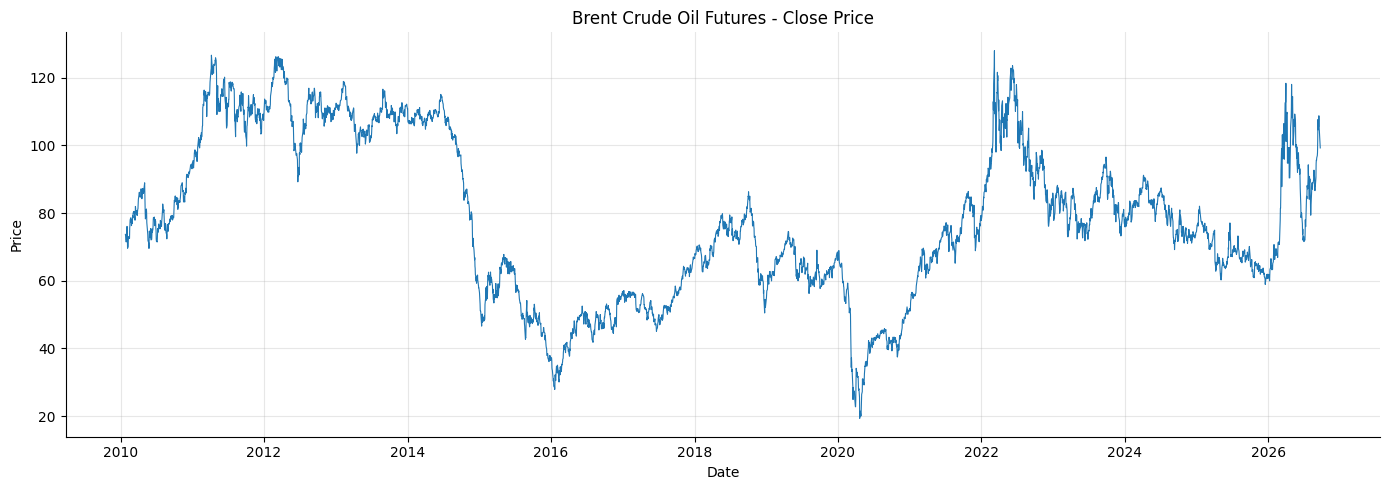

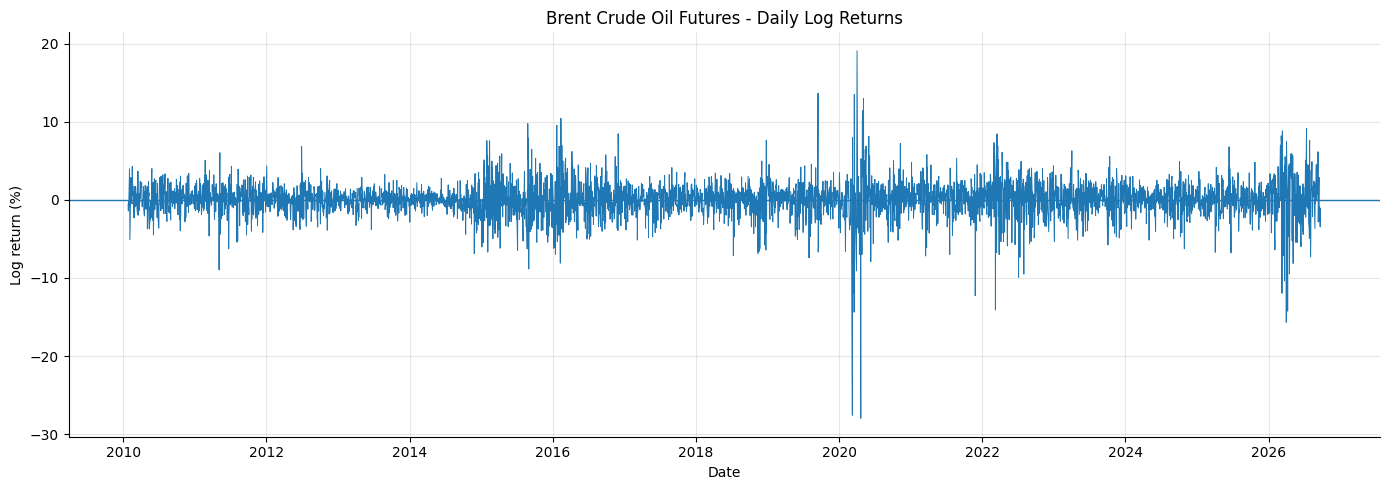

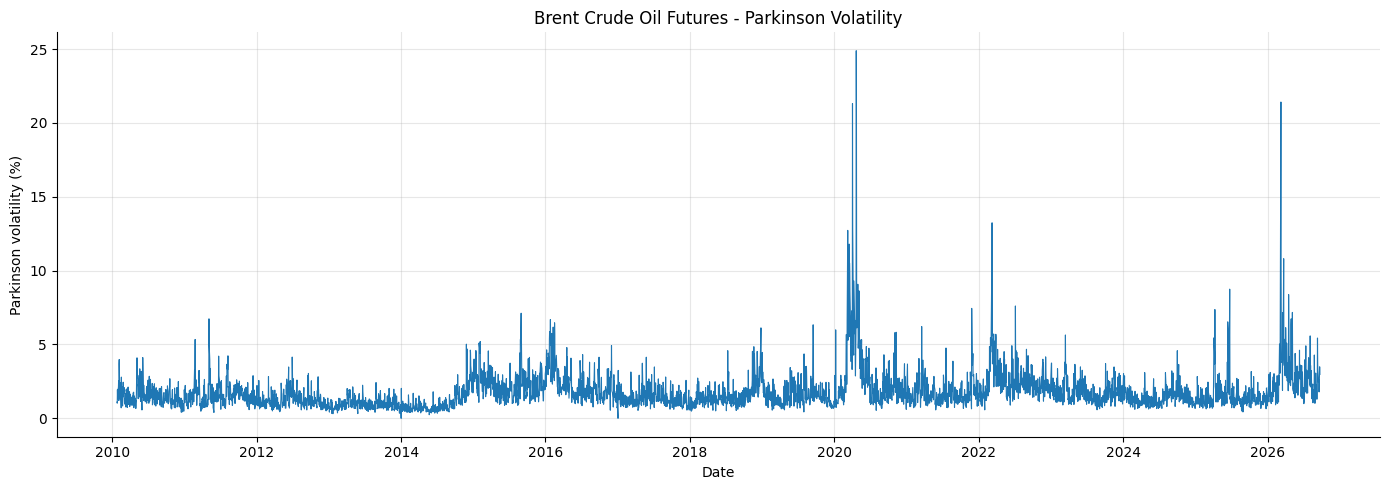

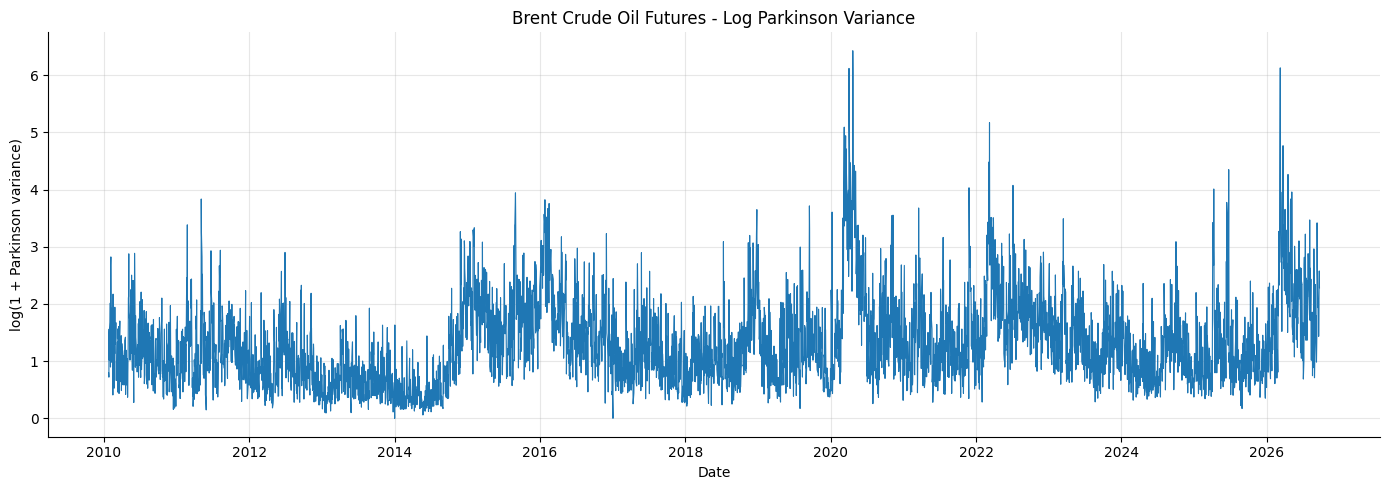

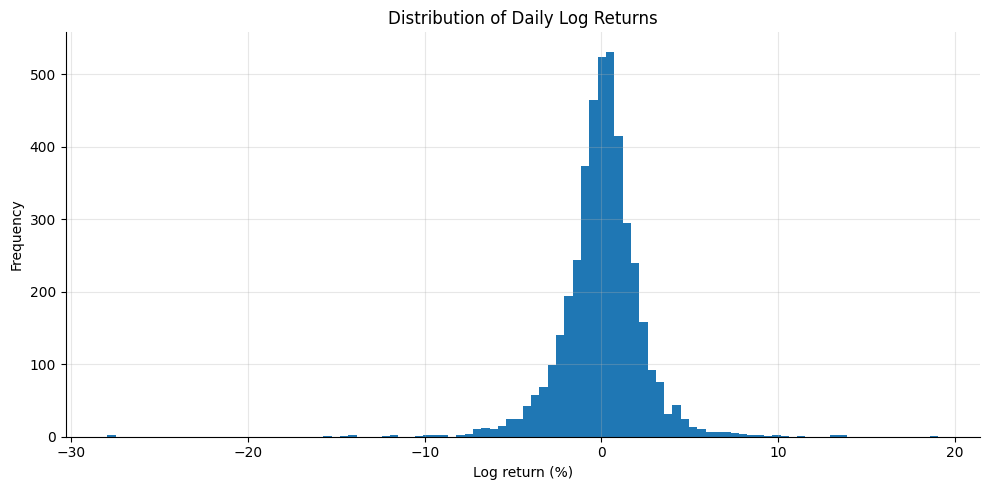

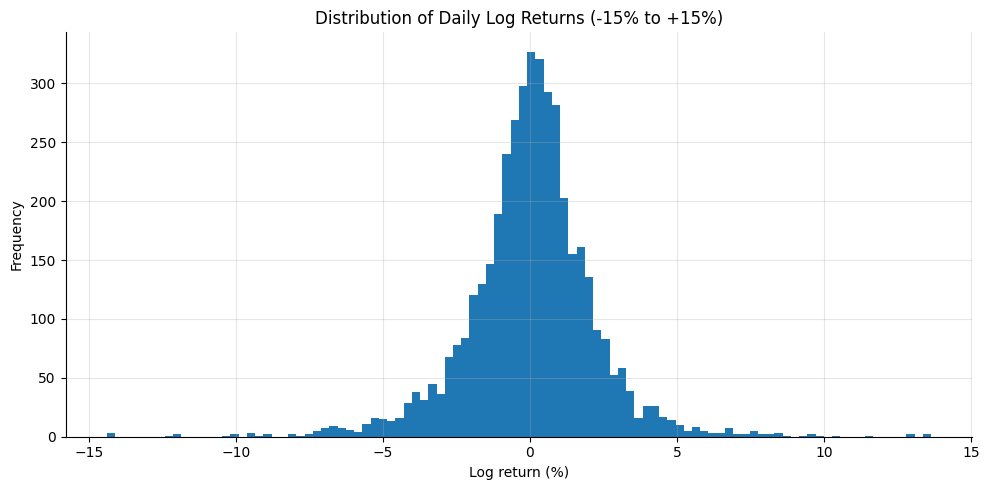

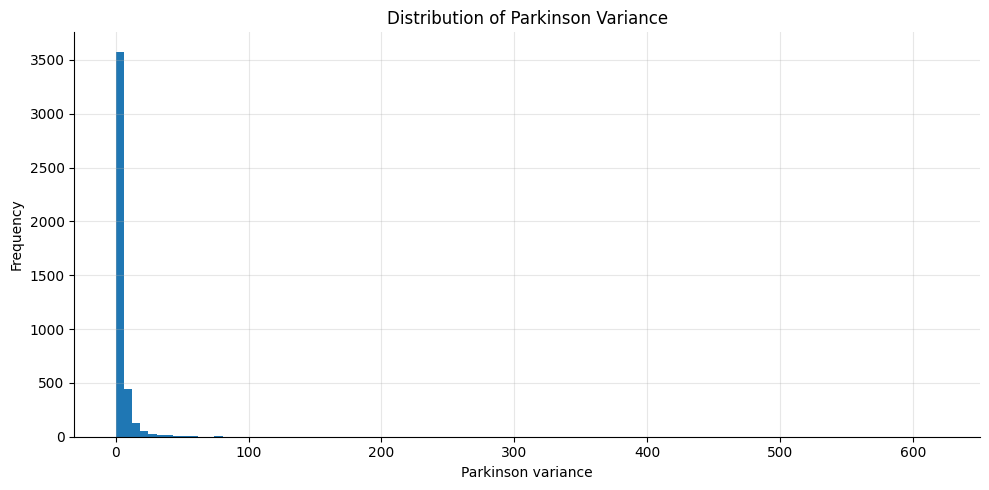

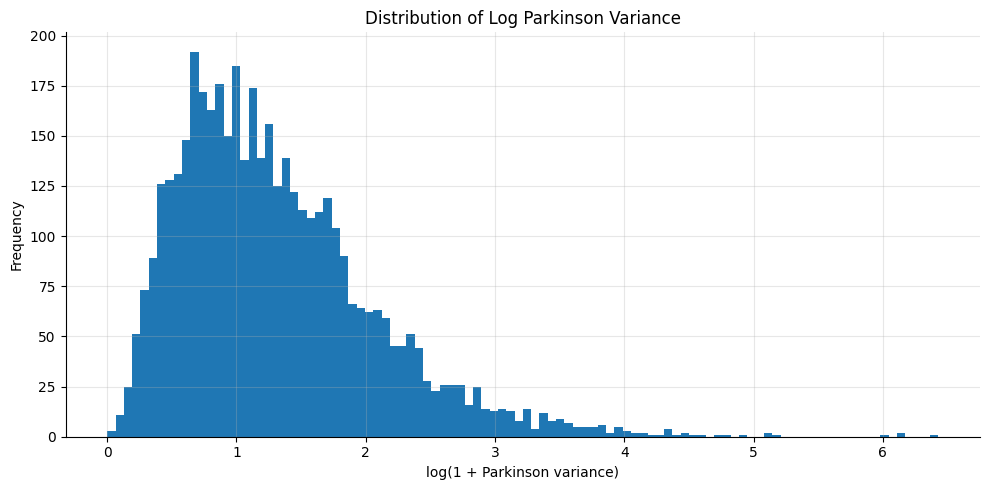

<Figure size 1000x500 with 0 Axes>

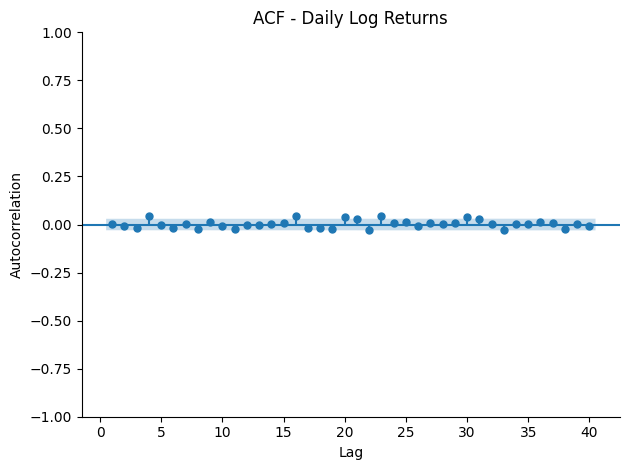

<Figure size 1000x500 with 0 Axes>

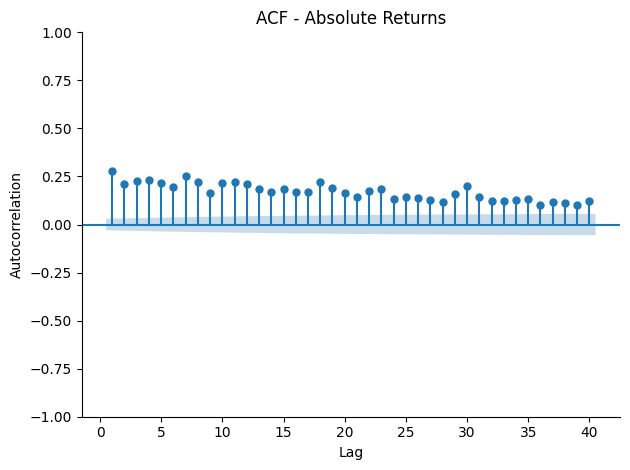

<Figure size 1000x500 with 0 Axes>

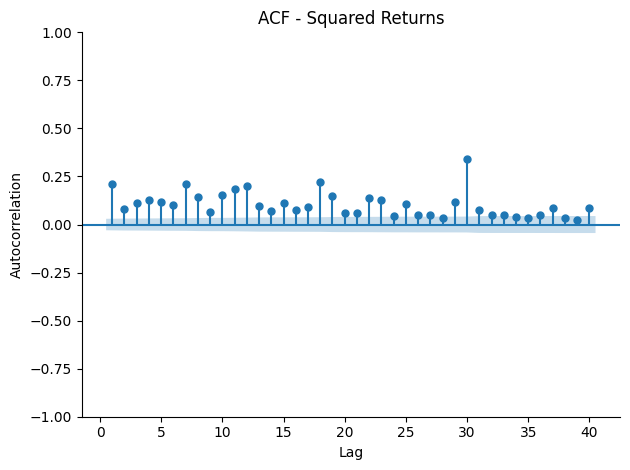

<Figure size 1000x500 with 0 Axes>

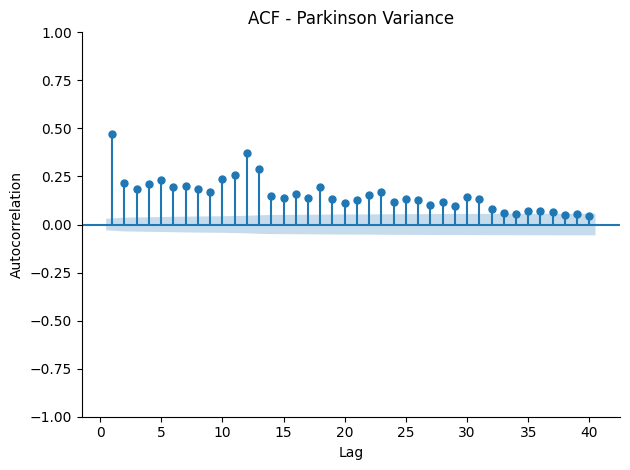


LJUNG-BOX TEST - LOG RETURNS


,lb_stat,lb_pvalue
5,9.317329,0.097057
10,13.785749,0.182990
20,36.584761,0.013117



LJUNG-BOX TEST - SQUARED RETURNS


,lb_stat,lb_pvalue
5,400.597780,2.205095e-84
10,839.889383,5.458100e-174
20,1666.026228,0.000000e+00



ARCH-LM TEST


LM statistic    4.608329e+02
LM p-value      1.020500e-92
F statistic     5.149271e+01
F p-value       3.073639e-98
dtype: float64

... (2 outputs left out)


ADF TEST - PARKINSON VARIANCE


ADF statistic   -8.227871e+00
p-value          6.175934e-13
lags             2.400000e+01
observations     4.279000e+03
dtype: float64


CORRELATION BETWEEN VOLATILITY MEASURES


,Squared_Return,Parkinson_Var,GK_Var,Return_Vol_5,Return_Vol_20
Squared_Return,1.000000,0.699660,0.574055,0.455898,0.379820
Parkinson_Var,0.699660,1.000000,0.967669,0.471337,0.434131
GK_Var,0.574055,0.967669,1.000000,0.444100,0.411465
Return_Vol_5,0.455898,0.471337,0.444100,1.000000,0.772632
Return_Vol_20,0.379820,0.434131,0.411465,0.772632,1.000000


In [36]:
# ============================================================
# STEP 3.3 - 3.18
# DIAGNOSTICS OF NATURAL GAS PRICE AND VOLATILITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import adfuller


# ============================================================
# STEP 3.3 - PRICE SERIES
# ============================================================

dates = df["Date"].to_numpy()
close = df["Close"].to_numpy()

plt.figure(figsize=(14, 5))

plt.plot(
    dates,
    close,
    linewidth=0.8
)

plt.title("Brent Crude Oil Futures - Close Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.4 - LOG RETURNS
# ============================================================

dates_returns = (
    df.loc[df["Log_Return"].notna(), "Date"]
    .to_numpy()
)

log_returns = (
    df.loc[df["Log_Return"].notna(), "Log_Return"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_returns,
    log_returns,
    linewidth=0.7
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title("Brent Crude Oil Futures - Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Log return (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.5 - PARKINSON VOLATILITY
# ============================================================

mask = df["Parkinson_Vol"].notna()

dates_parkinson = (
    df.loc[mask, "Date"]
    .to_numpy()
)

parkinson_vol = (
    df.loc[mask, "Parkinson_Vol"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_parkinson,
    parkinson_vol,
    linewidth=0.8
)

plt.title("Brent Crude Oil Futures - Parkinson Volatility")
plt.xlabel("Date")
plt.ylabel("Parkinson volatility (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.6 - LOG PARKINSON VARIANCE
# ============================================================

df["Log_Parkinson_Var"] = np.log1p(
    df["Parkinson_Var"]
)

mask = df["Log_Parkinson_Var"].notna()

dates_log_parkinson = (
    df.loc[mask, "Date"]
    .to_numpy()
)

log_parkinson = (
    df.loc[mask, "Log_Parkinson_Var"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_log_parkinson,
    log_parkinson,
    linewidth=0.8
)

plt.title("Brent Crude Oil Futures - Log Parkinson Variance")
plt.xlabel("Date")
plt.ylabel("log(1 + Parkinson variance)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.7 - RETURN DISTRIBUTION
# ============================================================

returns_clean = (
    df["Log_Return"]
    .dropna()
    .to_numpy()
)

# Full distribution

plt.figure(figsize=(10, 5))

plt.hist(
    returns_clean,
    bins=100
)

plt.title("Distribution of Daily Log Returns")
plt.xlabel("Log return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Zoomed distribution: -15% to +15%
# ------------------------------------------------------------

returns_zoom = returns_clean[
    (returns_clean >= -15)
    &
    (returns_clean <= 15)
]

plt.figure(figsize=(10, 5))

plt.hist(
    returns_zoom,
    bins=100
)

plt.title("Distribution of Daily Log Returns (-15% to +15%)")
plt.xlabel("Log return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.8 - PARKINSON VARIANCE DISTRIBUTION
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plt.hist(
    parkinson_var_clean,
    bins=100
)

plt.title("Distribution of Parkinson Variance")
plt.xlabel("Parkinson variance")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Log Parkinson variance
# ------------------------------------------------------------

log_parkinson_clean = (
    df["Log_Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plt.hist(
    log_parkinson_clean,
    bins=100
)

plt.title("Distribution of Log Parkinson Variance")
plt.xlabel("log(1 + Parkinson variance)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.9 - ACF OF RETURNS
# ============================================================

returns_clean = (
    df["Log_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Daily Log Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.10 - ACF OF ABSOLUTE RETURNS
# ============================================================

abs_returns_clean = (
    df["Abs_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    abs_returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Absolute Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.11 - ACF OF SQUARED RETURNS
# ============================================================

squared_returns_clean = (
    df["Squared_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    squared_returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Squared Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.12 - ACF OF PARKINSON VARIANCE
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    parkinson_var_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Parkinson Variance")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.13 - LJUNG-BOX TEST: RETURNS
# ============================================================

lb_returns = acorr_ljungbox(
    returns_clean,
    lags=[5, 10, 20],
    return_df=True
)

print("\n========================================")
print("LJUNG-BOX TEST - LOG RETURNS")
print("========================================")

display(lb_returns)


# ============================================================
# STEP 3.14 - LJUNG-BOX TEST: SQUARED RETURNS
# ============================================================

lb_squared = acorr_ljungbox(
    squared_returns_clean,
    lags=[5, 10, 20],
    return_df=True
)

print("\n========================================")
print("LJUNG-BOX TEST - SQUARED RETURNS")
print("========================================")

display(lb_squared)


# ============================================================
# STEP 3.15 - ARCH-LM TEST
# ============================================================

arch_test = het_arch(
    returns_clean,
    nlags=10
)

arch_results = pd.Series(
    {
        "LM statistic": arch_test[0],
        "LM p-value": arch_test[1],
        "F statistic": arch_test[2],
        "F p-value": arch_test[3]
    }
)

print("\n========================================")
print("ARCH-LM TEST")
print("========================================")

display(arch_results)


# ============================================================
# STEP 3.16 - ADF TEST: LOG RETURNS
# ============================================================

adf_result = adfuller(
    returns_clean,
    autolag="AIC"
)

adf_results = pd.Series(
    {
        "ADF statistic": adf_result[0],
        "p-value": adf_result[1],
        "lags": adf_result[2],
        "observations": adf_result[3]
    }
)

print("\n========================================")
print("ADF TEST - LOG RETURNS")
print("========================================")

display(adf_results)


# ============================================================
# STEP 3.17 - ADF TEST: PARKINSON VARIANCE
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

adf_pv = adfuller(
    parkinson_var_clean,
    autolag="AIC"
)

adf_pv_results = pd.Series(
    {
        "ADF statistic": adf_pv[0],
        "p-value": adf_pv[1],
        "lags": adf_pv[2],
        "observations": adf_pv[3]
    }
)

print("\n========================================")
print("ADF TEST - PARKINSON VARIANCE")
print("========================================")

display(adf_pv_results)


# ============================================================
# STEP 3.18 - CORRELATION BETWEEN VOLATILITY MEASURES
# ============================================================

volatility_variables = [
    "Squared_Return",
    "Parkinson_Var",
    "GK_Var",
    "Return_Vol_5",
    "Return_Vol_20"
]

vol_corr = (
    df[volatility_variables]
    .corr()
)

print("\n========================================")
print("CORRELATION BETWEEN VOLATILITY MEASURES")
print("========================================")

display(vol_corr)

In [37]:
# ============================================================
# STEP 4 - FINAL VERSION
# RESET + 5-DAY VOLATILITY REGIMES
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 0. REMOVE OLD REGIME VARIABLES
# ------------------------------------------------------------

columns_to_remove = [
    "Parkinson_Mean_5",
    "PV_Q33",
    "PV_Q67",
    "Volatility_Regime",
    "PV5_Q33",
    "PV5_Q67",
    "Volatility_Regime_5D"
]

df = df.drop(
    columns=[
        col for col in columns_to_remove
        if col in df.columns
    ]
)


# ------------------------------------------------------------
# 1. 5-DAY PARKINSON MEAN
# IMPORTANT: min_periods = 4
# ------------------------------------------------------------

df["Parkinson_Mean_5"] = (
    df["Parkinson_Var"]
    .rolling(
        window=5,
        min_periods=4
    )
    .mean()
)


# ------------------------------------------------------------
# 2. CHECK MISSING VALUES
# ------------------------------------------------------------

print(
    "Missing Parkinson_Var:",
    df["Parkinson_Var"].isna().sum()
)

print(
    "Missing Parkinson_Mean_5:",
    df["Parkinson_Mean_5"].isna().sum()
)


# ------------------------------------------------------------
# 3. ROLLING REGIME THRESHOLDS
# ------------------------------------------------------------

regime_window = 252
min_regime_obs = 250

df["PV5_Q33"] = (
    df["Parkinson_Mean_5"]
    .shift(1)
    .rolling(
        window=regime_window,
        min_periods=min_regime_obs
    )
    .quantile(0.33)
)

df["PV5_Q67"] = (
    df["Parkinson_Mean_5"]
    .shift(1)
    .rolling(
        window=regime_window,
        min_periods=min_regime_obs
    )
    .quantile(0.67)
)


# ------------------------------------------------------------
# 4. DEFINE VOLATILITY REGIME
# ------------------------------------------------------------

conditions = [
    df["Parkinson_Mean_5"] < df["PV5_Q33"],

    (
        (df["Parkinson_Mean_5"] >= df["PV5_Q33"])
        &
        (df["Parkinson_Mean_5"] <= df["PV5_Q67"])
    ),

    df["Parkinson_Mean_5"] > df["PV5_Q67"]
]

df["Volatility_Regime_5D"] = np.select(
    conditions,
    ["Low", "Normal", "High"],
    default=None
)


# ------------------------------------------------------------
# 5. FINAL CHECK
# ------------------------------------------------------------

print("\nMissing values:")

print(
    df[
        [
            "Parkinson_Var",
            "Parkinson_Mean_5",
            "PV5_Q33",
            "PV5_Q67",
            "Volatility_Regime_5D"
        ]
    ].isna().sum()
)


print(
    "\nObservations with regime:",
    df["Volatility_Regime_5D"].notna().sum()
)

print(
    "Observations without regime:",
    df["Volatility_Regime_5D"].isna().sum()
)


print("\nRegime shares:")

display(
    df["Volatility_Regime_5D"]
    .value_counts(normalize=True)
    .mul(100)
    .reindex(["Low", "Normal", "High"])
)

Missing Parkinson_Var: 0
Missing Parkinson_Mean_5: 3

Missing values:
Parkinson_Var             0
Parkinson_Mean_5          3
PV5_Q33                 253
PV5_Q67                 253
Volatility_Regime_5D    253
dtype: int64

Observations with regime: 4051
Observations without regime: 253

Regime shares:


Volatility_Regime_5D
Low       35.225870
Normal    32.189583
High      32.584547
Name: proportion, dtype: float64

In [38]:
# ============================================================
# STEP 4.4 - REGIME PERSISTENCE
# ============================================================

regime_df_5d = (
    df[
        ["Date", "Volatility_Regime_5D"]
    ]
    .dropna()
    .copy()
)

regime_df_5d["Previous_Regime"] = (
    regime_df_5d["Volatility_Regime_5D"]
    .shift(1)
)

regime_df_5d["Regime_Changed"] = (
    regime_df_5d["Volatility_Regime_5D"]
    != regime_df_5d["Previous_Regime"]
)

change_rate = (
    regime_df_5d["Regime_Changed"]
    .iloc[1:]
    .mean()
)

print(
    "Share of observations with regime change:",
    round(change_rate * 100, 2),
    "%"
)


transition_matrix_5d = pd.crosstab(
    regime_df_5d["Previous_Regime"],
    regime_df_5d["Volatility_Regime_5D"],
    normalize="index"
)

transition_matrix_5d = transition_matrix_5d.reindex(
    index=["Low", "Normal", "High"],
    columns=["Low", "Normal", "High"]
)

display(transition_matrix_5d)

Share of observations with regime change: 17.78 %


Volatility_Regime_5D,Low,Normal,High
Previous_Regime,,,
Low,0.856342,0.131745,0.011913
Normal,0.148887,0.734459,0.116654
High,0.007576,0.120455,0.871970


In [39]:
# ============================================================
# STEP 4.5 - REGIME DURATION
# ============================================================

regime_duration = (
    df[
        ["Date", "Volatility_Regime_5D"]
    ]
    .dropna()
    .copy()
)

regime_duration["Spell_ID"] = (
    regime_duration["Volatility_Regime_5D"]
    != regime_duration["Volatility_Regime_5D"].shift(1)
).cumsum()


spells = (
    regime_duration
    .groupby("Spell_ID")
    .agg(
        Regime=("Volatility_Regime_5D", "first"),
        Start=("Date", "min"),
        End=("Date", "max"),
        Duration=("Date", "size")
    )
)


duration_summary = (
    spells
    .groupby("Regime")["Duration"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(duration_summary)

,count,mean,median,min,max
Regime,,,,,
Low,205,6.960976,3.0,1,63
Normal,347,3.757925,3.0,1,32
High,169,7.810651,5.0,1,138


In [40]:
# ============================================================
# STEP 4.6 - VOLATILITY STATE SUMMARY
# ============================================================

regime_state_summary = (
    df
    .dropna(
        subset=[
            "Volatility_Regime_5D",
            "Parkinson_Mean_5"
        ]
    )
    .groupby("Volatility_Regime_5D")["Parkinson_Mean_5"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(regime_state_summary)

,count,mean,median,std,min,max
Volatility_Regime_5D,,,,,,
Low,1427,1.625007,1.429211,0.923133,0.206337,5.186885
Normal,1304,3.199710,2.711111,1.644248,0.593513,9.093132
High,1320,10.643550,5.857604,19.760407,0.896576,243.536873


In [41]:
# ============================================================
# STEP 4.7 - DAILY VOLATILITY WITHIN REGIMES
# Optional descriptive analysis
# ============================================================

daily_volatility_by_regime = (
    df
    .dropna(
        subset=[
            "Volatility_Regime_5D",
            "Parkinson_Var"
        ]
    )
    .groupby("Volatility_Regime_5D")["Parkinson_Var"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(daily_volatility_by_regime)

,count,mean,median,std,min,max
Volatility_Regime_5D,,,,,,
Low,1427,1.612433,1.165837,1.461392,0.000000,11.149505
Normal,1304,3.212301,2.391764,2.673979,0.236891,19.693691
High,1320,10.655537,4.762379,30.417479,0.221044,619.293584


In [42]:
# ============================================================
# STEP 5.1 - TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_end = pd.Timestamp("2016-12-31")
validation_end = pd.Timestamp("2019-12-31")


df["Sample"] = np.select(
    [
        df["Date"] <= train_end,

        (
            (df["Date"] > train_end)
            &
            (df["Date"] <= validation_end)
        ),

        df["Date"] > validation_end
    ],
    [
        "Train",
        "Validation",
        "Test"
    ],
    default=None
)

In [43]:
# ============================================================
# STEP 5.2 - SAMPLE SUMMARY
# ============================================================

sample_summary = (
    df
    .groupby("Sample")
    .agg(
        Start=("Date", "min"),
        End=("Date", "max"),
        Observations=("Date", "size")
    )
    .reindex([
        "Train",
        "Validation",
        "Test"
    ])
)

display(sample_summary)

,Start,End,Observations
Sample,,,
Train,2010-01-25,2016-12-30,1793
Validation,2017-01-02,2019-12-31,774
Test,2020-01-02,2026-09-22,1737


In [44]:
# ============================================================
# STEP 5.3 - REGIMES BY SAMPLE
# ============================================================

regime_by_sample = pd.crosstab(
    df["Sample"],
    df["Volatility_Regime_5D"]
)

regime_by_sample = regime_by_sample.reindex(
    index=["Train", "Validation", "Test"],
    columns=["Low", "Normal", "High"]
)

display(regime_by_sample)

Volatility_Regime_5D,Low,Normal,High
Sample,,,
Train,563,465,512
Validation,290,265,219
Test,574,574,589


In [45]:
# ============================================================
# STEP 5.4 - REGIME SHARES BY SAMPLE
# ============================================================

regime_by_sample_pct = (
    pd.crosstab(
        df["Sample"],
        df["Volatility_Regime_5D"],
        normalize="index"
    )
    * 100
)

regime_by_sample_pct = regime_by_sample_pct.reindex(
    index=["Train", "Validation", "Test"],
    columns=["Low", "Normal", "High"]
)

display(regime_by_sample_pct)

Volatility_Regime_5D,Low,Normal,High
Sample,,,
Train,36.558442,30.194805,33.246753
Validation,37.467700,34.237726,28.294574
Test,33.045481,33.045481,33.909039


In [46]:
# ============================================================
# STEP 5.5 - TARGET VOLATILITY BY SAMPLE
# ============================================================

target_by_sample = (
    df
    .groupby("Sample")["Parkinson_Var"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex([
        "Train",
        "Validation",
        "Test"
    ])
)

display(target_by_sample)

,count,mean,median,std,min,max
Sample,,,,,,
Train,1793,3.392739,1.862451,4.797181,0.000000,50.643852
Validation,774,2.801593,1.764801,3.544870,0.000000,40.096518
Test,1737,7.480118,2.956836,26.600711,0.186484,619.293584


In [47]:
# ============================================================
# STEP 6.1 - FINAL FEATURE SET
# ============================================================

features = [

    # Current Parkinson volatility
    "Parkinson_Var",

    # Lagged Parkinson volatility
    "Parkinson_Lag_1",
    "Parkinson_Lag_2",
    "Parkinson_Lag_3",
    "Parkinson_Lag_5",
    "Parkinson_Lag_10",
    "Parkinson_Lag_20",

    # Aggregated Parkinson volatility
    "Parkinson_Mean_5",
    "Parkinson_Mean_10",
    "Parkinson_Mean_20",

    # Current return information
    "Abs_Return",
    "Squared_Return",

    # Lagged absolute returns
    "Abs_Return_Lag_1",
    "Abs_Return_Lag_2",
    "Abs_Return_Lag_3",
    "Abs_Return_Lag_5",
    "Abs_Return_Lag_10",
    "Abs_Return_Lag_20",

    # Lagged squared returns
    "Squared_Return_Lag_1",
    "Squared_Return_Lag_2",
    "Squared_Return_Lag_3",
    "Squared_Return_Lag_5",
    "Squared_Return_Lag_10",
    "Squared_Return_Lag_20",

    # Rolling return volatility
    "Return_Vol_5",
    "Return_Vol_10",
    "Return_Vol_20"
]

target = "Target_Parkinson_t1"

In [48]:
# ============================================================
# STEP 6.2 - CREATE MODEL DATASET
# ============================================================

model_columns = (
    [
        "Date",
        "Sample",
        "Volatility_Regime_5D"
    ]
    + features
    + [target]
)

model_df = (
    df[model_columns]
    .copy()
)

print("Initial model dataset shape:")
print(model_df.shape)

Initial model dataset shape:
(4304, 31)


In [49]:
# ============================================================
# STEP 6.3 - MISSING VALUES
# ============================================================

missing_values = (
    model_df
    .isna()
    .sum()
)

print("Missing values before filtering:")
display(missing_values)

Missing values before filtering:


Date                       0
Sample                     0
Volatility_Regime_5D     253
Parkinson_Var              0
Parkinson_Lag_1            1
Parkinson_Lag_2            2
Parkinson_Lag_3            3
Parkinson_Lag_5            5
Parkinson_Lag_10          10
Parkinson_Lag_20          20
Parkinson_Mean_5           3
Parkinson_Mean_10          9
Parkinson_Mean_20         19
Abs_Return                 1
Squared_Return             1
Abs_Return_Lag_1           2
Abs_Return_Lag_2           3
Abs_Return_Lag_3           4
Abs_Return_Lag_5           6
Abs_Return_Lag_10         11
Abs_Return_Lag_20         21
Squared_Return_Lag_1       2
Squared_Return_Lag_2       3
Squared_Return_Lag_3       4
Squared_Return_Lag_5       6
Squared_Return_Lag_10     11
Squared_Return_Lag_20     21
Return_Vol_5               5
Return_Vol_10             10
Return_Vol_20             20
Target_Parkinson_t1        1
dtype: int64

In [50]:
# ============================================================
# STEP 6.4 - COMPLETE MODEL SAMPLE
# ============================================================

model_df_complete = (
    model_df
    .dropna(
        subset=features + [target]
    )
    .reset_index(drop=True)
)

print(
    "Observations before filtering:",
    len(model_df)
)

print(
    "Observations after filtering:",
    len(model_df_complete)
)

print(
    "Removed observations:",
    len(model_df) - len(model_df_complete)
)

print(
    "\nModel date range:",
    model_df_complete["Date"].min(),
    "-",
    model_df_complete["Date"].max()
)

Observations before filtering: 4304
Observations after filtering: 4282
Removed observations: 22

Model date range: 2010-02-23 00:00:00 - 2026-09-21 00:00:00


In [21]:
# ============================================================
# STEP 6.5 - X AND y
# ============================================================

X = (
    model_df_complete[features]
    .copy()
)

y = (
    model_df_complete[target]
    .copy()
)

dates_model = (
    model_df_complete["Date"]
    .copy()
)

samples_model = (
    model_df_complete["Sample"]
    .copy()
)

regimes_model = (
    model_df_complete["Volatility_Regime_5D"]
    .copy()
)


print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4282, 27)
y shape: (4282,)


In [22]:
# ============================================================
# STEP 6.6 - SAMPLE MASKS
# ============================================================

train_mask = (
    model_df_complete["Sample"] == "Train"
)

validation_mask = (
    model_df_complete["Sample"] == "Validation"
)

test_mask = (
    model_df_complete["Sample"] == "Test"
)

In [23]:
# ============================================================
# STEP 6.7 - TRAIN / VALIDATION / TEST MATRICES
# ============================================================

X_train = (
    X.loc[train_mask]
    .copy()
)

y_train = (
    y.loc[train_mask]
    .copy()
)


X_validation = (
    X.loc[validation_mask]
    .copy()
)

y_validation = (
    y.loc[validation_mask]
    .copy()
)


X_test = (
    X.loc[test_mask]
    .copy()
)

y_test = (
    y.loc[test_mask]
    .copy()
)


print(
    "Train:",
    X_train.shape,
    y_train.shape
)

print(
    "Validation:",
    X_validation.shape,
    y_validation.shape
)

print(
    "Test:",
    X_test.shape,
    y_test.shape
)

Train: (1772, 27) (1772,)
Validation: (774, 27) (774,)
Test: (1736, 27) (1736,)


In [24]:
# ============================================================
# STEP 6.8 - DATES AND REGIMES BY SAMPLE
# ============================================================

dates_train = (
    model_df_complete.loc[
        train_mask,
        "Date"
    ]
    .copy()
)

dates_validation = (
    model_df_complete.loc[
        validation_mask,
        "Date"
    ]
    .copy()
)

dates_test = (
    model_df_complete.loc[
        test_mask,
        "Date"
    ]
    .copy()
)


regimes_train = (
    model_df_complete.loc[
        train_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

regimes_validation = (
    model_df_complete.loc[
        validation_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

regimes_test = (
    model_df_complete.loc[
        test_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

In [25]:
# ============================================================
# STEP 6.9 - CHRONOLOGICAL CHECK
# ============================================================

print("TRAIN")
print(
    model_df_complete.loc[
        train_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        train_mask,
        "Date"
    ].max()
)


print("\nVALIDATION")
print(
    model_df_complete.loc[
        validation_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        validation_mask,
        "Date"
    ].max()
)


print("\nTEST")
print(
    model_df_complete.loc[
        test_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        test_mask,
        "Date"
    ].max()
)

TRAIN
2010-02-23 00:00:00 - 2016-12-30 00:00:00

VALIDATION
2017-01-02 00:00:00 - 2019-12-31 00:00:00

TEST
2020-01-02 00:00:00 - 2026-09-21 00:00:00


In [26]:
# ============================================================
# STEP 6.10 - TARGET ALIGNMENT CHECK
# ============================================================

alignment_check = (
    df[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1"
        ]
    ]
    .copy()
)

alignment_check[
    "Next_Parkinson_Actual"
] = (
    alignment_check[
        "Parkinson_Var"
    ]
    .shift(-1)
)

alignment_check[
    "Difference"
] = (
    alignment_check[
        "Target_Parkinson_t1"
    ]
    -
    alignment_check[
        "Next_Parkinson_Actual"
    ]
)


max_alignment_difference = (
    alignment_check[
        "Difference"
    ]
    .abs()
    .max()
)

print(
    "Maximum target alignment difference:",
    max_alignment_difference
)

Maximum target alignment difference: 0.0


In [27]:
# ============================================================
# STEP 6.11 - FINAL NaN CHECK
# ============================================================

print(
    "Missing values in X:",
    X.isna().sum().sum()
)

print(
    "Missing values in y:",
    y.isna().sum()
)

Missing values in X: 0
Missing values in y: 0


In [28]:
# ============================================================
# STEP 6.12 - INFINITE VALUES CHECK
# ============================================================

number_of_infinite_X = (
    np.isinf(
        X.to_numpy()
    )
    .sum()
)

number_of_infinite_y = (
    np.isinf(
        y.to_numpy()
    )
    .sum()
)

print(
    "Infinite values in X:",
    number_of_infinite_X
)

print(
    "Infinite values in y:",
    number_of_infinite_y
)

Infinite values in X: 0
Infinite values in y: 0


In [29]:
# ============================================================
# STEP 6.13 - FINAL MODEL DATA SUMMARY
# ============================================================

final_summary = pd.DataFrame({
    "Sample": [
        "Train",
        "Validation",
        "Test"
    ],

    "Observations": [
        train_mask.sum(),
        validation_mask.sum(),
        test_mask.sum()
    ],

    "Start": [
        dates_train.min(),
        dates_validation.min(),
        dates_test.min()
    ],

    "End": [
        dates_train.max(),
        dates_validation.max(),
        dates_test.max()
    ]
})

display(final_summary)

print(
    "\nNumber of features:",
    len(features)
)

print(
    "Target:",
    target
)

,Sample,Observations,Start,End
0,Train,1772,2010-02-23,2016-12-30
1,Validation,774,2017-01-02,2019-12-31
2,Test,1736,2020-01-02,2026-09-21



Number of features: 27
Target: Target_Parkinson_t1


In [30]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

print(
    "Maximum target alignment difference:",
    max_alignment_difference
)

print(
    "Missing values in X:",
    X.isna().sum().sum()
)

print(
    "Infinite values in X:",
    number_of_infinite_X
)

Train: (1772, 27) (1772,)
Validation: (774, 27) (774,)
Test: (1736, 27) (1736,)
Maximum target alignment difference: 0.0
Missing values in X: 0
Infinite values in X: 0


In [31]:
# ============================================================
# COMMON FORECAST EVALUATION FUNCTIONS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


def qlike_loss_strict(
    actual,
    forecast
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(forecast))
    ):
        return np.nan


    if np.any(
        forecast <= 0
    ):
        return np.nan


    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )


def evaluate_forecast(
    actual,
    forecast,
    model_name
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    mae = mean_absolute_error(
        actual,
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )

    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    return pd.DataFrame({
        "Model": [model_name],
        "N": [len(actual)],
        "Nonpositive": [
            int(np.sum(forecast <= 0))
        ],
        "MAE": [mae],
        "RMSE": [rmse],
        "QLIKE": [qlike],
        "QLIKE_Admissible": [
            "Yes"
            if np.isfinite(qlike)
            else "No"
        ]
    })

In [32]:
# ============================================================
# STEP 7.1 - HAR SPECIFICATION
# ============================================================

har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

har_target = "Target_Parkinson_t1"

In [33]:
# ============================================================
# FORECAST EVALUATION FUNCTIONS
# Penalized QLIKE for tuning
# Strict QLIKE for reported results
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# ------------------------------------------------------------
# 1. PENALIZED QLIKE
# ONLY for hyperparameter tuning / GridSearch
# ------------------------------------------------------------

def qlike_loss_penalized(
    actual,
    forecast,
    epsilon=1e-8
):
    
    actual = np.asarray(
        actual,
        dtype=float
    )
    
    forecast = np.asarray(
        forecast,
        dtype=float
    )
    
    # Technical protection used only during tuning
    forecast_safe = np.maximum(
        forecast,
        epsilon
    )
    
    return np.mean(
        np.log(forecast_safe)
        +
        actual / forecast_safe
    )


# ------------------------------------------------------------
# 2. STRICT QLIKE
# For Validation/Test results reported in the paper
# ------------------------------------------------------------

def qlike_loss_strict(
    actual,
    forecast
):
    
    actual = np.asarray(
        actual,
        dtype=float
    )
    
    forecast = np.asarray(
        forecast,
        dtype=float
    )
    
    
    # Missing / infinite values
    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(forecast))
    ):
        return np.nan
    
    
    # Variance forecasts must be strictly positive
    if np.any(
        forecast <= 0
    ):
        return np.nan
    
    
    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )


# ------------------------------------------------------------
# 3. FINAL FORECAST EVALUATION
# ------------------------------------------------------------

def evaluate_forecast(
    actual,
    forecast,
    model_name
):
    
    actual = np.asarray(
        actual,
        dtype=float
    )
    
    forecast = np.asarray(
        forecast,
        dtype=float
    )
    
    
    mae = mean_absolute_error(
        actual,
        forecast
    )
    
    
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )
    
    
    qlike = qlike_loss_strict(
        actual,
        forecast
    )
    
    
    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )
    
    
    return pd.DataFrame({
        
        "Model": [
            model_name
        ],
        
        "N": [
            len(actual)
        ],
        
        "Nonpositive": [
            nonpositive
        ],
        
        "MAE": [
            mae
        ],
        
        "RMSE": [
            rmse
        ],
        
        "QLIKE": [
            qlike
        ]
    })

In [34]:
# ============================================================
# STEP 7.3 - FINAL WALK-FORWARD HAR
# ============================================================

from sklearn.linear_model import LinearRegression

har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

har_target = "Target_Parkinson_t1"


validation_origins = (
    model_df_complete[
        model_df_complete["Sample"] == "Validation"
    ]
    .sort_values("Date")
    .copy()
)


har_wf_forecasts = []


for _, row in validation_origins.iterrows():

    origin_date = row["Date"]

    # Only observations whose t+1 target is already known
    train_history = (
        model_df_complete[
            model_df_complete["Date"] < origin_date
        ]
        .dropna(
            subset=har_features + [har_target]
        )
    )

    X_hist = train_history[har_features]
    y_hist = train_history[har_target]

    X_current = pd.DataFrame(
        [row[har_features].values],
        columns=har_features
    )

    model = LinearRegression()

    model.fit(
        X_hist,
        y_hist
    )

    forecast = float(
        model.predict(X_current)[0]
    )

    har_wf_forecasts.append(
        {
            "Date": origin_date,
            "Forecast_HAR": forecast
        }
    )


har_validation_wf = pd.DataFrame(
    har_wf_forecasts
)


print(
    "HAR walk-forward forecasts:",
    len(har_validation_wf)
)

display(
    har_validation_wf.head()
)

HAR walk-forward forecasts: 774


,Date,Forecast_HAR
0,2017-01-02,1.460847
1,2017-01-03,5.585320
2,2017-01-04,2.448385
3,2017-01-05,2.608077
4,2017-01-06,2.482202


In [35]:
validation_base = (
    validation_origins[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)

validation_base["Forecast_Naive"] = (
    validation_base["Parkinson_Var"]
)

validation_base = (
    validation_base
    .merge(
        har_validation_wf,
        on="Date",
        how="left"
    )
)

display(validation_base.head())

,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR
0,2017-01-02,0.000000,10.528605,Low,0.000000,1.460847
1,2017-01-03,10.528605,1.715630,Low,10.528605,5.585320
2,2017-01-04,1.715630,2.016067,Low,1.715630,2.448385
3,2017-01-05,2.016067,1.579055,Low,2.016067,2.608077
4,2017-01-06,1.579055,5.903269,Low,1.579055,2.482202


In [36]:
# ============================================================
# STEP 7.5 - FINAL VALIDATION PERFORMANCE
# ============================================================

results_naive = evaluate_forecast(
    actual=validation_base["Target_Parkinson_t1"],
    forecast=validation_base["Forecast_Naive"],
    model_name="Naive"
)

results_har = evaluate_forecast(
    actual=validation_base["Target_Parkinson_t1"],
    forecast=validation_base["Forecast_HAR"],
    model_name="HAR"
)

validation_results = pd.concat(
    [
        results_naive,
        results_har
    ],
    ignore_index=True
)

display(validation_results)

,Model,N,Nonpositive,MAE,RMSE,QLIKE
0,Naive,774,1,2.238685,4.042539,NaN
1,HAR,774,0,1.840907,3.258749,1.965475


In [37]:
# ============================================================
# STEP 7.6 - CHECK FINAL HAR FORECASTS
# ============================================================

print(
    "Minimum HAR forecast:",
    validation_base["Forecast_HAR"].min()
)

print(
    "Negative HAR forecasts:",
    (
        validation_base["Forecast_HAR"] < 0
    ).sum()
)

print(
    "Missing HAR forecasts:",
    validation_base["Forecast_HAR"].isna().sum()
)

Minimum HAR forecast: 1.0125710175007834
Negative HAR forecasts: 0
Missing HAR forecasts: 0


In [38]:
# ============================================================
# STEP 7.7 - FINAL PERFORMANCE BY REGIME
# ============================================================

regime_results = []

for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = validation_base[
        validation_base[
            "Volatility_Regime_5D"
        ] == regime
    ]

    for model_name, forecast_col in [
        ("Naive", "Forecast_Naive"),
        ("HAR", "Forecast_HAR")
    ]:

        result = evaluate_forecast(
            actual=temp["Target_Parkinson_t1"],
            forecast=temp[forecast_col],
            model_name=model_name
        )

        result["Regime"] = regime

        regime_results.append(result)


validation_results_by_regime = pd.concat(
    regime_results,
    ignore_index=True
)

display(
    validation_results_by_regime[
        [
            "Regime",
            "Model",
            "MAE",
            "RMSE",
            "QLIKE"
        ]
    ]
)

,Regime,Model,MAE,RMSE,QLIKE
0,Low,Naive,1.623618,2.978989,NaN
1,Low,HAR,1.449968,2.650749,1.789032
2,Normal,Naive,1.820062,3.329737,2.170828
3,Normal,HAR,1.617871,2.993628,1.878007
4,High,Naive,3.559710,5.708737,2.486211
5,High,HAR,2.628473,4.169303,2.304961


In [39]:
# ============================================================
# STEP 7.9 - DIEBOLD-MARIANO TEST FUNCTION
# STRICT QLIKE
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import t as student_t


def diebold_mariano_test(
    actual,
    forecast_1,
    forecast_2,
    loss="QLIKE",
    h=1,
    hac_lags=None
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast_1 = np.asarray(
        forecast_1,
        dtype=float
    )

    forecast_2 = np.asarray(
        forecast_2,
        dtype=float
    )


    # --------------------------------------------------------
    # Joint finite sample
    # --------------------------------------------------------

    valid = (
        np.isfinite(actual)
        &
        np.isfinite(forecast_1)
        &
        np.isfinite(forecast_2)
    )


    actual = actual[valid]

    forecast_1 = forecast_1[valid]

    forecast_2 = forecast_2[valid]


    n = len(actual)


    if n < 10:

        raise ValueError(
            "Too few valid observations for the DM test."
        )


    loss = loss.upper()


    # --------------------------------------------------------
    # Loss functions
    # --------------------------------------------------------

    if loss == "MAE":

        loss_1 = np.abs(
            actual - forecast_1
        )

        loss_2 = np.abs(
            actual - forecast_2
        )


    elif loss == "MSE":

        loss_1 = (
            actual - forecast_1
        ) ** 2

        loss_2 = (
            actual - forecast_2
        ) ** 2


    elif loss == "QLIKE":

        if (
            np.any(forecast_1 <= 0)
            or
            np.any(forecast_2 <= 0)
        ):

            raise ValueError(
                "QLIKE DM test requires "
                "strictly positive forecasts."
            )


        loss_1 = (
            np.log(forecast_1)
            +
            actual / forecast_1
        )

        loss_2 = (
            np.log(forecast_2)
            +
            actual / forecast_2
        )


    else:

        raise ValueError(
            "loss must be 'MAE', 'MSE', or 'QLIKE'."
        )


    # --------------------------------------------------------
    # Loss differential
    # Negative -> forecast 1 better
    # --------------------------------------------------------

    d = (
        loss_1
        -
        loss_2
    )


    mean_d = np.mean(
        d
    )


    # --------------------------------------------------------
    # HAC lag
    # --------------------------------------------------------

    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4
                *
                (n / 100) ** (2 / 9)
            )
        )


    hac_lags = max(
        0,
        min(
            hac_lags,
            n - 1
        )
    )


    # --------------------------------------------------------
    # Newey-West long-run variance
    # --------------------------------------------------------

    d_centered = (
        d - mean_d
    )


    gamma_0 = (
        np.sum(
            d_centered ** 2
        )
        /
        n
    )


    long_run_variance = gamma_0


    for lag in range(
        1,
        hac_lags + 1
    ):

        gamma_lag = (
            np.sum(
                d_centered[lag:]
                *
                d_centered[:-lag]
            )
            /
            n
        )


        bartlett_weight = (
            1
            -
            lag
            /
            (hac_lags + 1)
        )


        long_run_variance += (
            2
            *
            bartlett_weight
            *
            gamma_lag
        )


    if long_run_variance <= 0:

        raise ValueError(
            "Estimated long-run variance is non-positive."
        )


    # --------------------------------------------------------
    # DM statistic
    # --------------------------------------------------------

    dm_stat = (
        mean_d
        /
        np.sqrt(
            long_run_variance
            /
            n
        )
    )


    # --------------------------------------------------------
    # Harvey-Leybourne-Newbold correction
    # --------------------------------------------------------

    hln_correction = np.sqrt(
        (
            n
            + 1
            - 2 * h
            + (
                h * (h - 1)
                /
                n
            )
        )
        /
        n
    )


    dm_stat_corrected = (
        dm_stat
        *
        hln_correction
    )


    p_value = (
        2
        *
        student_t.sf(
            np.abs(
                dm_stat_corrected
            ),
            df=n - 1
        )
    )


    return pd.DataFrame({
        "Loss": [loss],
        "N": [n],
        "Mean_Loss_Diff": [mean_d],
        "DM_stat": [dm_stat_corrected],
        "p_value": [p_value],
        "HAC_lags": [hac_lags]
    })

In [40]:
# ============================================================
# FINAL GLOBAL DM TEST
# HAR vs Naive
# QLIKE excluded because Naive contains zero forecast
# ============================================================

dm_results_global = []


for loss_function in [
    "MAE",
    "MSE"
]:

    result = diebold_mariano_test(

        actual=
            validation_base[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            validation_base[
                "Forecast_HAR"
            ],

        forecast_2=
            validation_base[
                "Forecast_Naive"
            ],

        loss=
            loss_function,

        h=1
    )


    result[
        "Comparison"
    ] = "HAR vs Naive"


    dm_results_global.append(
        result
    )


dm_results_global = pd.concat(
    dm_results_global,
    ignore_index=True
)


display(dm_results_global)

,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Comparison
0,MAE,774,-0.397778,-7.050837,3.948181e-12,6,HAR vs Naive
1,MSE,774,-5.722676,-4.379071,1.356001e-05,6,HAR vs Naive


In [41]:
# ============================================================
# FINAL DM TEST BY REGIME
# STRICT QLIKE
# ============================================================

dm_results_regime = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = (
        validation_base[
            validation_base[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    losses_to_test = [
        "MAE",
        "MSE"
    ]


    if (
        np.all(
            temp[
                "Forecast_HAR"
            ] > 0
        )
        and
        np.all(
            temp[
                "Forecast_Naive"
            ] > 0
        )
    ):

        losses_to_test.append(
            "QLIKE"
        )


    for loss_function in losses_to_test:

        result = diebold_mariano_test(

            actual=
                temp[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                temp[
                    "Forecast_HAR"
                ],

            forecast_2=
                temp[
                    "Forecast_Naive"
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Regime"
        ] = regime

        result[
            "Comparison"
        ] = "HAR vs Naive"


        dm_results_regime.append(
            result
        )


dm_results_regime = pd.concat(
    dm_results_regime,
    ignore_index=True
)


display(dm_results_regime)

,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Regime,Comparison
0,MAE,290,-0.173650,-3.851103,1.448433e-04,5,Low,HAR vs Naive
1,MSE,290,-1.847905,-4.163274,4.144561e-05,5,Low,HAR vs Naive
2,MAE,265,-0.202192,-3.563376,4.343372e-04,4,Normal,HAR vs Naive
3,MSE,265,-2.125344,-4.088224,5.774118e-05,4,Normal,HAR vs Naive
4,QLIKE,265,-0.292820,-4.231946,3.199550e-05,4,Normal,HAR vs Naive
5,MAE,219,-0.931237,-6.430475,7.925658e-10,4,High,HAR vs Naive
6,MSE,219,-15.206587,-3.920994,1.181217e-04,4,High,HAR vs Naive
7,QLIKE,219,-0.181250,-4.210707,3.724012e-05,4,High,HAR vs Naive


In [42]:
# ============================================================
# STEP 8.0 - IMPORTS
# ============================================================

import numpy as np
import pandas as pd


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)
from arch import arch_model

In [43]:
# ============================================================
# BRENT - ZERO PARKINSON / NAIVE FORECAST AUDIT
# ============================================================

print(
    "Zero Parkinson_Var - full sample:",
    (df["Parkinson_Var"] == 0).sum()
)

print(
    "Zero Target_Parkinson_t1 - full sample:",
    (df["Target_Parkinson_t1"] == 0).sum()
)


print("\nZero Parkinson_Var by sample:")

display(
    df.loc[
        df["Parkinson_Var"] == 0
    ]
    .groupby("Sample")
    .size()
    .rename("Zero_Parkinson")
)


print("\nZero target by sample:")

display(
    df.loc[
        df["Target_Parkinson_t1"] == 0
    ]
    .groupby("Sample")
    .size()
    .rename("Zero_Target")
)


print("\nRows with Parkinson_Var = 0:")

display(
    df.loc[
        df["Parkinson_Var"] == 0,
        [
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Sample",
            "Volatility_Regime_5D"
        ]
    ]
)

Zero Parkinson_Var - full sample: 2
Zero Target_Parkinson_t1 - full sample: 2

Zero Parkinson_Var by sample:


Sample
Train         1
Validation    1
Name: Zero_Parkinson, dtype: int64


Zero target by sample:


Sample
Train    2
Name: Zero_Target, dtype: int64


Rows with Parkinson_Var = 0:


,Date,Open,High,Low,Close,Parkinson_Var,Target_Parkinson_t1,Sample,Volatility_Regime_5D
1018,2014-01-01,110.92,110.92,110.92,110.92,0.0,4.118816,Train,Low
1793,2017-01-02,56.82,56.82,56.82,56.82,0.0,10.528605,Validation,Low


In [44]:
# ============================================================
# BRENT - ZERO NAIVE FORECASTS IN VALIDATION
# ============================================================

zero_naive_validation = (
    validation_base[
        validation_base["Forecast_Naive"] <= 0
    ]
    .copy()
)

print(
    "Non-positive Naive forecasts in Validation:",
    len(zero_naive_validation)
)

display(
    zero_naive_validation
)

Non-positive Naive forecasts in Validation: 1


,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR
0,2017-01-02,0.0,10.528605,Low,0.0,1.460847


In [45]:
# ============================================================
# STEP 8.1 - RETURN DATA FOR GARCH-FAMILY MODELS
# ============================================================

returns_df = (
    df[
        [
            "Date",
            "Log_Return"
        ]
    ]
    .dropna()
    .sort_values("Date")
    .reset_index(drop=True)
)


train_returns = (
    returns_df.loc[
        returns_df["Date"] <= train_end,
        [
            "Date",
            "Log_Return"
        ]
    ]
    .copy()
)


y_train_returns = (
    train_returns
    .set_index("Date")["Log_Return"]
)


print(
    "Train returns:",
    len(train_returns)
)

print(
    "Start:",
    train_returns["Date"].min()
)

print(
    "End:",
    train_returns["Date"].max()
)

print(
    "Missing returns:",
    train_returns["Log_Return"].isna().sum()
)

Train returns: 1792
Start: 2010-01-26 00:00:00
End: 2016-12-30 00:00:00
Missing returns: 0


In [46]:
# ============================================================
# STEP 8.2 - MEAN EQUATION SELECTION
# Constant vs AR(1) vs AR(2)
# Primary criterion: BIC on TRAIN
# ============================================================

mean_candidates = [
    {
        "Name": "Constant",
        "Mean": "Constant",
        "Lags": None
    },
    {
        "Name": "AR(1)",
        "Mean": "AR",
        "Lags": 1
    },
    {
        "Name": "AR(2)",
        "Mean": "AR",
        "Lags": 2
    }
]


mean_results = []


for candidate in mean_candidates:

    kwargs = {
        "y": y_train_returns,
        "mean": candidate["Mean"],
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 1,
        "dist": "StudentsT",
        "rescale": False,
        "hold_back": 2
    }

    if candidate["Mean"] == "AR":
        kwargs["lags"] = candidate["Lags"]


    model = arch_model(**kwargs)


    result = model.fit(
        update_freq=0,
        disp="off",
        show_warning=False
    )


    mean_results.append(
        {
            "Mean_Model": candidate["Name"],
            "AIC": result.aic,
            "BIC": result.bic,
            "LogLik": result.loglikelihood,
            "Convergence_Flag":
                result.convergence_flag
        }
    )


mean_selection = pd.DataFrame(
    mean_results
)


display(
    mean_selection.sort_values("BIC")
)

,Mean_Model,AIC,BIC,LogLik,Convergence_Flag
0,Constant,6921.436786,6948.886641,-3455.718393,0
1,AR(1),6917.614675,6950.554501,-3452.807338,0
2,AR(2),6919.609383,6958.039179,-3452.804692,0


In [47]:
# ============================================================
# STEP 8.2 - SELECT FINAL MEAN EQUATION
# ============================================================

mean_selection_ok = (
    mean_selection[
        mean_selection[
            "Convergence_Flag"
        ] == 0
    ]
    .copy()
)


if len(mean_selection_ok) == 0:
    raise RuntimeError(
        "None of the candidate mean models converged."
    )


best_mean_name = (
    mean_selection_ok
    .sort_values("BIC")
    .iloc[0]["Mean_Model"]
)


best_mean_config = next(
    candidate
    for candidate in mean_candidates
    if candidate["Name"] == best_mean_name
)


print(
    "Selected mean equation:",
    best_mean_name
)

print(
    "Configuration:",
    best_mean_config
)

Selected mean equation: Constant
Configuration: {'Name': 'Constant', 'Mean': 'Constant', 'Lags': None}


In [48]:
# ============================================================
# STEP 8.3 - ARCH MODEL FACTORY
# ============================================================

def build_arch_model(
    returns,
    family,
    p,
    q,
    mean_config
):

    kwargs = {
        "y": returns,
        "mean": mean_config["Mean"],
        "p": p,
        "q": q,
        "dist": "StudentsT",
        "rescale": False
    }


    if mean_config["Mean"] == "AR":
        kwargs["lags"] = (
            mean_config["Lags"]
        )


    if family == "GARCH":

        kwargs["vol"] = "GARCH"
        kwargs["o"] = 0


    elif family == "EGARCH":

        kwargs["vol"] = "EGARCH"
        kwargs["o"] = 1


    elif family == "GJR-GARCH":

        # GJR-GARCH in the arch package:
        # vol="GARCH" with o > 0
        kwargs["vol"] = "GARCH"
        kwargs["o"] = 1


    else:

        raise ValueError(
            f"Unknown model family: {family}"
        )


    return arch_model(
        **kwargs
    )

In [49]:
# ============================================================
# STEP 8.4 - PREDEFINED MODEL GRID
# ============================================================

candidate_specs = []


for family in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    for p in [1, 2, 3]:

        for q in [1, 2, 3]:

            if family == "GARCH":

                label = (
                    f"GARCH({p},{q})"
                )

                o = 0

            else:

                label = (
                    f"{family}({p},1,{q})"
                )

                o = 1


            candidate_specs.append(
                {
                    "Family": family,
                    "p": p,
                    "o": o,
                    "q": q,
                    "Label": label
                }
            )


candidate_specs_df = pd.DataFrame(
    candidate_specs
)


display(candidate_specs_df)


print(
    "Number of candidate models:",
    len(candidate_specs_df)
)

,Family,p,o,q,Label
0,GARCH,1,0,1,"GARCH(1,1)"
1,GARCH,1,0,2,"GARCH(1,2)"
2,GARCH,1,0,3,"GARCH(1,3)"
3,GARCH,2,0,1,"GARCH(2,1)"
4,GARCH,2,0,2,"GARCH(2,2)"
5,GARCH,2,0,3,"GARCH(2,3)"
6,GARCH,3,0,1,"GARCH(3,1)"
7,GARCH,3,0,2,"GARCH(3,2)"
8,GARCH,3,0,3,"GARCH(3,3)"
9,EGARCH,1,1,1,"EGARCH(1,1,1)"


Number of candidate models: 27


In [50]:
# ============================================================
# STEP 8.5 - QLIKE LOSS FUNCTIONS
# ============================================================

# ------------------------------------------------------------
# 1. STRICT QLIKE
# Validation / Test / robustness / DM reporting
# ------------------------------------------------------------

def qlike_loss_strict(
    actual,
    forecast
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    # Non-finite observations make QLIKE inadmissible
    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(forecast))
    ):
        return np.nan


    # Variance forecasts must be strictly positive
    if np.any(
        forecast <= 0
    ):
        return np.nan


    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )


# ------------------------------------------------------------
# 2. PENALIZED QLIKE
# ONLY for technical hyperparameter tuning / GridSearch scorer
# ------------------------------------------------------------

def qlike_loss_penalized(
    actual,
    forecast,
    epsilon=1e-8
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    forecast_safe = np.maximum(
        forecast,
        epsilon
    )


    return np.mean(
        np.log(forecast_safe)
        +
        actual / forecast_safe
    )

In [51]:
# ============================================================
# STEP 8.6 - WALK-FORWARD ARCH FORECAST
# ============================================================

def walk_forward_arch(
    returns_df,
    validation_frame,
    spec,
    mean_config
):

    forecasts = []

    convergence_issues = 0
    estimation_errors = 0


    validation_sorted = (
        validation_frame
        .sort_values("Date")
        .copy()
    )


    for counter, (_, row) in enumerate(
        validation_sorted.iterrows(),
        start=1
    ):

        origin_date = row["Date"]


        # ----------------------------------------------------
        # Information available at forecast origin t
        # ----------------------------------------------------

        history = (
            returns_df.loc[
                returns_df["Date"]
                <= origin_date,
                [
                    "Date",
                    "Log_Return"
                ]
            ]
            .set_index("Date")[
                "Log_Return"
            ]
        )


        try:

            model = build_arch_model(
                returns=history,
                family=spec["Family"],
                p=spec["p"],
                q=spec["q"],
                mean_config=mean_config
            )


            result = model.fit(
                update_freq=0,
                disp="off",
                show_warning=False
            )


            if (
                result.convergence_flag
                != 0
            ):
                convergence_issues += 1


            forecast_object = (
                result.forecast(
                    horizon=1,
                    reindex=False
                )
            )


            forecast_variance = float(
                forecast_object
                .variance
                .iloc[-1, 0]
            )


            if not np.isfinite(
                forecast_variance
            ):
                forecast_variance = np.nan
                estimation_errors += 1


        except Exception:

            forecast_variance = np.nan
            estimation_errors += 1


        forecasts.append(
            {
                "Date": origin_date,
                "Forecast":
                    forecast_variance
            }
        )


        if counter % 100 == 0:

            print(
                spec["Label"],
                "- completed:",
                counter,
                "/",
                len(validation_sorted)
            )


    forecasts_df = pd.DataFrame(
        forecasts
    )


    return (
        forecasts_df,
        convergence_issues,
        estimation_errors
    )

In [52]:
# ============================================================
# STEP 8.7 - TRAIN FIT INFORMATION
# ============================================================

train_fit_results = []


for spec in candidate_specs:

    try:

        model = build_arch_model(
            returns=y_train_returns,
            family=spec["Family"],
            p=spec["p"],
            q=spec["q"],
            mean_config=best_mean_config
        )


        result = model.fit(
            update_freq=0,
            disp="off",
            show_warning=False
        )


        train_fit_results.append(
            {
                "Label":
                    spec["Label"],

                "Family":
                    spec["Family"],

                "p":
                    spec["p"],

                "o":
                    spec["o"],

                "q":
                    spec["q"],

                "Train_AIC":
                    result.aic,

                "Train_BIC":
                    result.bic,

                "Train_LogLik":
                    result.loglikelihood,

                "Train_Convergence":
                    result.convergence_flag
            }
        )


    except Exception:

        train_fit_results.append(
            {
                "Label":
                    spec["Label"],

                "Family":
                    spec["Family"],

                "p":
                    spec["p"],

                "o":
                    spec["o"],

                "q":
                    spec["q"],

                "Train_AIC":
                    np.nan,

                "Train_BIC":
                    np.nan,

                "Train_LogLik":
                    np.nan,

                "Train_Convergence":
                    999
            }
        )


train_fit_table = pd.DataFrame(
    train_fit_results
)


display(
    train_fit_table
    .sort_values(
        [
            "Family",
            "Train_BIC"
        ]
    )
)

,Label,Family,p,o,q,Train_AIC,Train_BIC,Train_LogLik,Train_Convergence
15,"EGARCH(3,1,1)",EGARCH,3,1,1,6886.215461,6930.144162,-3435.107731,0
9,"EGARCH(1,1,1)",EGARCH,1,1,1,6903.245157,6936.191682,-3445.622578,0
16,"EGARCH(3,1,2)",EGARCH,3,1,2,6886.876441,6936.296229,-3434.438220,0
12,"EGARCH(2,1,1)",EGARCH,2,1,1,6898.371466,6936.809079,-3442.185733,0
10,"EGARCH(1,1,2)",EGARCH,1,1,2,6903.959587,6942.397200,-3444.979793,0
17,"EGARCH(3,1,3)",EGARCH,3,1,3,6888.876441,6943.787317,-3434.438221,0
13,"EGARCH(2,1,2)",EGARCH,2,1,2,6900.371466,6944.300167,-3442.185733,0
11,"EGARCH(1,1,3)",EGARCH,1,1,3,6901.786610,6945.715311,-3442.893305,0
14,"EGARCH(2,1,3)",EGARCH,2,1,3,6902.187179,6951.606967,-3442.093589,0
0,"GARCH(1,1)",GARCH,1,0,1,6928.583812,6956.039250,-3459.291906,0


In [53]:
# ============================================================
# STEP 8.8 - VALIDATION GRID SEARCH
# ARCH FAMILY
# STRICT QLIKE
# ============================================================

grid_results = []

candidate_forecasts = {}


# Expected number of Validation observations
expected_validation_n = int(
    (
        validation_base[
            "Target_Parkinson_t1"
        ].notna()
        &
        np.isfinite(
            validation_base[
                "Target_Parkinson_t1"
            ]
        )
    ).sum()
)


for i, spec in enumerate(
    candidate_specs,
    start=1
):

    print(
        "\n========================================"
    )

    print(
        f"MODEL {i}/{len(candidate_specs)}"
    )

    print(
        spec["Label"]
    )

    print(
        "========================================"
    )


    (
        forecast_df,
        conv_issues,
        errors
    ) = walk_forward_arch(

        returns_df=returns_df,

        validation_frame=
            validation_base,

        spec=spec,

        mean_config=
            best_mean_config
    )


    candidate_forecasts[
        spec["Label"]
    ] = forecast_df.copy()


    # --------------------------------------------------------
    # Merge forecasts with Validation target
    # --------------------------------------------------------

    evaluation = (
        validation_base[
            [
                "Date",
                "Target_Parkinson_t1"
            ]
        ]
        .merge(
            forecast_df,
            on="Date",
            how="left"
        )
    )


    # --------------------------------------------------------
    # Finite observations
    # --------------------------------------------------------

    valid = (
        evaluation[
            "Target_Parkinson_t1"
        ].notna()
        &
        evaluation[
            "Forecast"
        ].notna()
        &
        np.isfinite(
            evaluation[
                "Target_Parkinson_t1"
            ]
        )
        &
        np.isfinite(
            evaluation[
                "Forecast"
            ]
        )
    )


    actual = (
        evaluation.loc[
            valid,
            "Target_Parkinson_t1"
        ]
        .to_numpy(
            dtype=float
        )
    )


    forecast = (
        evaluation.loc[
            valid,
            "Forecast"
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Forecast coverage / admissibility
    # --------------------------------------------------------

    n_forecasts = len(actual)

    coverage_complete = (
        n_forecasts
        ==
        expected_validation_n
    )


    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    # --------------------------------------------------------
    # Performance
    # --------------------------------------------------------

    if n_forecasts > 0:

        mae = mean_absolute_error(
            actual,
            forecast
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )


        # QLIKE is used for model selection only if:
        # 1. Validation coverage is complete
        # 2. all forecasts are strictly positive
        if coverage_complete:

            qlike = qlike_loss_strict(
                actual,
                forecast
            )

        else:

            qlike = np.nan


    else:

        mae = np.nan

        rmse = np.nan

        qlike = np.nan


    qlike_admissible = (
        coverage_complete
        and
        np.isfinite(qlike)
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    grid_results.append(
        {
            "Label":
                spec["Label"],

            "Family":
                spec["Family"],

            "p":
                spec["p"],

            "o":
                spec["o"],

            "q":
                spec["q"],

            "N_Forecasts":
                n_forecasts,

            "Expected_N":
                expected_validation_n,

            "Coverage_Complete":
                coverage_complete,

            "Nonpositive":
                nonpositive,

            "QLIKE_Admissible":
                qlike_admissible,

            "Convergence_Issues":
                conv_issues,

            "Estimation_Errors":
                errors,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike
        }
    )


grid_results = pd.DataFrame(
    grid_results
)


display(
    grid_results
    .sort_values(
        [
            "Family",
            "QLIKE"
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)


MODEL 1/27
GARCH(1,1)
GARCH(1,1) - completed: 100 / 774
GARCH(1,1) - completed: 200 / 774
GARCH(1,1) - completed: 300 / 774
GARCH(1,1) - completed: 400 / 774
GARCH(1,1) - completed: 500 / 774
GARCH(1,1) - completed: 600 / 774
GARCH(1,1) - completed: 700 / 774

MODEL 2/27
GARCH(1,2)
GARCH(1,2) - completed: 100 / 774
GARCH(1,2) - completed: 200 / 774
GARCH(1,2) - completed: 300 / 774
GARCH(1,2) - completed: 400 / 774
GARCH(1,2) - completed: 500 / 774
GARCH(1,2) - completed: 600 / 774
GARCH(1,2) - completed: 700 / 774

MODEL 3/27
GARCH(1,3)
GARCH(1,3) - completed: 100 / 774
GARCH(1,3) - completed: 200 / 774
GARCH(1,3) - completed: 300 / 774
GARCH(1,3) - completed: 400 / 774
GARCH(1,3) - completed: 500 / 774
GARCH(1,3) - completed: 600 / 774
GARCH(1,3) - completed: 700 / 774

MODEL 4/27
GARCH(2,1)
GARCH(2,1) - completed: 100 / 774
GARCH(2,1) - completed: 200 / 774
GARCH(2,1) - completed: 300 / 774
GARCH(2,1) - completed: 400 / 774
GARCH(2,1) - completed: 500 / 774
GARCH(2,1) - completed: 

GJR-GARCH(2,1,2) - completed: 400 / 774
GJR-GARCH(2,1,2) - completed: 500 / 774
GJR-GARCH(2,1,2) - completed: 600 / 774
GJR-GARCH(2,1,2) - completed: 700 / 774

MODEL 24/27
GJR-GARCH(2,1,3)
GJR-GARCH(2,1,3) - completed: 100 / 774
GJR-GARCH(2,1,3) - completed: 200 / 774
GJR-GARCH(2,1,3) - completed: 300 / 774
GJR-GARCH(2,1,3) - completed: 400 / 774
GJR-GARCH(2,1,3) - completed: 500 / 774
GJR-GARCH(2,1,3) - completed: 600 / 774
GJR-GARCH(2,1,3) - completed: 700 / 774

MODEL 25/27
GJR-GARCH(3,1,1)
GJR-GARCH(3,1,1) - completed: 100 / 774
GJR-GARCH(3,1,1) - completed: 200 / 774
GJR-GARCH(3,1,1) - completed: 300 / 774
GJR-GARCH(3,1,1) - completed: 400 / 774
GJR-GARCH(3,1,1) - completed: 500 / 774
GJR-GARCH(3,1,1) - completed: 600 / 774
GJR-GARCH(3,1,1) - completed: 700 / 774

MODEL 26/27
GJR-GARCH(3,1,2)
GJR-GARCH(3,1,2) - completed: 100 / 774
GJR-GARCH(3,1,2) - completed: 200 / 774
GJR-GARCH(3,1,2) - completed: 300 / 774
GJR-GARCH(3,1,2) - completed: 400 / 774
GJR-GARCH(3,1,2) - completed: 

,Label,Family,p,o,q,N_Forecasts,Expected_N,Coverage_Complete,Nonpositive,QLIKE_Admissible,Convergence_Issues,Estimation_Errors,MAE,RMSE,QLIKE
0,"EGARCH(1,1,2)",EGARCH,1,1,2,774,774,True,0,True,0,0,1.951387,3.338862,1.967521
1,"EGARCH(1,1,1)",EGARCH,1,1,1,774,774,True,0,True,0,0,1.951488,3.343771,1.967818
2,"EGARCH(2,1,2)",EGARCH,2,1,2,774,774,True,0,True,0,0,1.951003,3.311929,1.968080
3,"EGARCH(2,1,1)",EGARCH,2,1,1,774,774,True,0,True,0,0,1.951008,3.311944,1.968081
4,"EGARCH(1,1,3)",EGARCH,1,1,3,774,774,True,0,True,0,0,1.954722,3.338581,1.968439
5,"EGARCH(2,1,3)",EGARCH,2,1,3,774,774,True,0,True,0,0,1.952127,3.325771,1.968641
6,"EGARCH(3,1,1)",EGARCH,3,1,1,774,774,True,0,True,0,0,1.984111,3.370400,1.977899
7,"EGARCH(3,1,3)",EGARCH,3,1,3,774,774,True,0,True,0,0,1.989517,3.393930,1.980300
8,"EGARCH(3,1,2)",EGARCH,3,1,2,774,774,True,0,True,0,0,1.989523,3.393944,1.980301
9,"GARCH(2,1)",GARCH,2,0,1,774,774,True,0,True,0,0,2.161128,3.605672,1.985931


In [54]:
# ============================================================
# STEP 8.9 - COMPLETE CANDIDATE TABLE
# ============================================================

garch_selection_table = (
    grid_results
    .merge(
        train_fit_table,
        on=[
            "Label",
            "Family",
            "p",
            "o",
            "q"
        ],
        how="left"
    )
)


display(
    garch_selection_table
    .sort_values(
        [
            "Family",
            "QLIKE"
        ]
    )
)

,Label,Family,p,o,q,N_Forecasts,Expected_N,Coverage_Complete,Nonpositive,QLIKE_Admissible,Convergence_Issues,Estimation_Errors,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Train_LogLik,Train_Convergence
10,"EGARCH(1,1,2)",EGARCH,1,1,2,774,774,True,0,True,0,0,1.951387,3.338862,1.967521,6903.959587,6942.397200,-3444.979793,0
9,"EGARCH(1,1,1)",EGARCH,1,1,1,774,774,True,0,True,0,0,1.951488,3.343771,1.967818,6903.245157,6936.191682,-3445.622578,0
13,"EGARCH(2,1,2)",EGARCH,2,1,2,774,774,True,0,True,0,0,1.951003,3.311929,1.968080,6900.371466,6944.300167,-3442.185733,0
12,"EGARCH(2,1,1)",EGARCH,2,1,1,774,774,True,0,True,0,0,1.951008,3.311944,1.968081,6898.371466,6936.809079,-3442.185733,0
11,"EGARCH(1,1,3)",EGARCH,1,1,3,774,774,True,0,True,0,0,1.954722,3.338581,1.968439,6901.786610,6945.715311,-3442.893305,0
14,"EGARCH(2,1,3)",EGARCH,2,1,3,774,774,True,0,True,0,0,1.952127,3.325771,1.968641,6902.187179,6951.606967,-3442.093589,0
15,"EGARCH(3,1,1)",EGARCH,3,1,1,774,774,True,0,True,0,0,1.984111,3.370400,1.977899,6886.215461,6930.144162,-3435.107731,0
17,"EGARCH(3,1,3)",EGARCH,3,1,3,774,774,True,0,True,0,0,1.989517,3.393930,1.980300,6888.876441,6943.787317,-3434.438221,0
16,"EGARCH(3,1,2)",EGARCH,3,1,2,774,774,True,0,True,0,0,1.989523,3.393944,1.980301,6886.876441,6936.296229,-3434.438220,0
3,"GARCH(2,1)",GARCH,2,0,1,774,774,True,0,True,0,0,2.161128,3.605672,1.985931,6930.583812,6963.530338,-3459.291906,0


In [55]:
display(
    garch_selection_table[
        [
            "Family",
            "Label",
            "N_Forecasts",
            "Convergence_Issues",
            "Estimation_Errors",
            "MAE",
            "RMSE",
            "QLIKE",
            "Train_AIC",
            "Train_BIC",
            "Train_Convergence"
        ]
    ]
    .sort_values(
        [
            "Family",
            "QLIKE"
        ]
    )
)

,Family,Label,N_Forecasts,Convergence_Issues,Estimation_Errors,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Train_Convergence
10,EGARCH,"EGARCH(1,1,2)",774,0,0,1.951387,3.338862,1.967521,6903.959587,6942.397200,0
9,EGARCH,"EGARCH(1,1,1)",774,0,0,1.951488,3.343771,1.967818,6903.245157,6936.191682,0
13,EGARCH,"EGARCH(2,1,2)",774,0,0,1.951003,3.311929,1.968080,6900.371466,6944.300167,0
12,EGARCH,"EGARCH(2,1,1)",774,0,0,1.951008,3.311944,1.968081,6898.371466,6936.809079,0
11,EGARCH,"EGARCH(1,1,3)",774,0,0,1.954722,3.338581,1.968439,6901.786610,6945.715311,0
14,EGARCH,"EGARCH(2,1,3)",774,0,0,1.952127,3.325771,1.968641,6902.187179,6951.606967,0
15,EGARCH,"EGARCH(3,1,1)",774,0,0,1.984111,3.370400,1.977899,6886.215461,6930.144162,0
17,EGARCH,"EGARCH(3,1,3)",774,0,0,1.989517,3.393930,1.980300,6888.876441,6943.787317,0
16,EGARCH,"EGARCH(3,1,2)",774,0,0,1.989523,3.393944,1.980301,6886.876441,6936.296229,0
3,GARCH,"GARCH(2,1)",774,0,0,2.161128,3.605672,1.985931,6930.583812,6963.530338,0


In [56]:
# ============================================================
# STEP 8.10 - SELECT BEST MODEL PER FAMILY
# ============================================================

required_forecasts = (
    expected_validation_n
)


eligible_models = (
    garch_selection_table[
        (
            garch_selection_table[
                "Coverage_Complete"
            ]
        )
        &
        (
            garch_selection_table[
                "QLIKE_Admissible"
            ]
        )
        &
        (
            garch_selection_table[
                "N_Forecasts"
            ]
            == required_forecasts
        )
        &
        (
            garch_selection_table[
                "Estimation_Errors"
            ] == 0
        )
        &
        (
            garch_selection_table[
                "Convergence_Issues"
            ] == 0
        )
        &
        (
            garch_selection_table[
                "Train_Convergence"
            ] == 0
        )
    ]
    .copy()
)


selected_models_list = []


for family in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    family_models = (
        eligible_models[
            eligible_models[
                "Family"
            ] == family
        ]
        .sort_values(
            "QLIKE"
        )
    )


    if family_models.empty:

        raise RuntimeError(
            f"{family}: no admissible model."
        )


    selected_models_list.append(
        family_models.iloc[0]
    )


selected_models = pd.DataFrame(
    selected_models_list
)


display(
    selected_models[
        [
            "Family",
            "Label",
            "MAE",
            "RMSE",
            "QLIKE",
            "Train_AIC",
            "Train_BIC",
            "Convergence_Issues",
            "Estimation_Errors"
        ]
    ]
)

,Family,Label,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Convergence_Issues,Estimation_Errors
3,GARCH,"GARCH(2,1)",2.161128,3.605672,1.985931,6930.583812,6963.530338,0,0
10,EGARCH,"EGARCH(1,1,2)",1.951387,3.338862,1.967521,6903.959587,6942.397200,0,0
22,GJR-GARCH,"GJR-GARCH(2,1,2)",2.157392,3.485012,1.977127,6915.190210,6959.118911,0,0


In [57]:
# ============================================================
# STEP 8.11 - FINAL VALIDATION FORECAST TABLE
# ============================================================

validation_forecasts = (
    validation_base.copy()
)


family_column_names = {
    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR"
}


for _, selected in (
    selected_models.iterrows()
):

    family = selected[
        "Family"
    ]

    label = selected[
        "Label"
    ]


    temp = (
        candidate_forecasts[
            label
        ]
        .rename(
            columns={
                "Forecast":
                    family_column_names[
                        family
                    ]
            }
        )
    )


    validation_forecasts = (
        validation_forecasts
        .merge(
            temp,
            on="Date",
            how="left"
        )
    )


display(
    validation_forecasts.head()
)


print(
    validation_forecasts.shape
)

,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR
0,2017-01-02,0.000000,10.528605,Low,0.000000,1.460847,4.333400,2.833455,3.427754
1,2017-01-03,10.528605,1.715630,Low,10.528605,5.585320,4.456995,3.476439,3.875530
2,2017-01-04,1.715630,2.016067,Low,1.715630,2.448385,4.381500,3.155852,3.600930
3,2017-01-05,2.016067,1.579055,Low,2.016067,2.608077,4.129139,2.998948,3.449965
4,2017-01-06,1.579055,5.903269,Low,1.579055,2.482202,3.855883,2.792005,3.258613


(774, 9)


In [58]:
# ============================================================
# STEP 8.12 - GLOBAL VALIDATION PERFORMANCE
# STRICT QLIKE
# ============================================================

forecast_columns = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR"
}


global_results = []


for (
    model_name,
    forecast_col
) in forecast_columns.items():

    if forecast_col not in (
        validation_forecasts.columns
    ):
        continue


    temp = (
        validation_forecasts[
            [
                "Target_Parkinson_t1",
                forecast_col
            ]
        ]
        .dropna()
    )


    actual = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy(
            dtype=float
        )
    )


    forecast = (
        temp[
            forecast_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Forecast admissibility audit
    # --------------------------------------------------------

    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    # --------------------------------------------------------
    # Standard loss measures
    # --------------------------------------------------------

    mae = mean_absolute_error(
        actual,
        forecast
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )


    # --------------------------------------------------------
    # Strict QLIKE
    # --------------------------------------------------------

    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    global_results.append(
        {
            "Model":
                model_name,

            "N":
                len(temp),

            "Nonpositive":
                nonpositive,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                "Yes"
                if np.isfinite(qlike)
                else "No"
        }
    )


global_results = pd.DataFrame(
    global_results
)


display(
    global_results
    .sort_values(
        "QLIKE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,HAR,774,0,1.840907,3.258749,1.965475,Yes
1,EGARCH,774,0,1.951387,3.338862,1.967521,Yes
2,GJR-GARCH,774,0,2.157392,3.485012,1.977127,Yes
3,GARCH,774,0,2.161128,3.605672,1.985931,Yes
4,Naive,774,1,2.238685,4.042539,NaN,No


In [59]:
# ============================================================
# STEP 8.13 - PERFORMANCE BY VOLATILITY REGIME
# STRICT QLIKE
# ============================================================

regime_performance = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        validation_forecasts[
            validation_forecasts[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    for (
        model_name,
        forecast_col
    ) in forecast_columns.items():

        if forecast_col not in (
            regime_data.columns
        ):
            continue


        temp = (
            regime_data[
                [
                    "Target_Parkinson_t1",
                    forecast_col
                ]
            ]
            .dropna()
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(
                dtype=float
            )
        )


        forecast = (
            temp[
                forecast_col
            ]
            .to_numpy(
                dtype=float
            )
        )


        # ----------------------------------------------------
        # Admissibility audit
        # ----------------------------------------------------

        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        # ----------------------------------------------------
        # Strict QLIKE
        # ----------------------------------------------------

        qlike = qlike_loss_strict(
            actual,
            forecast
        )


        regime_performance.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(temp),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mean_absolute_error(
                        actual,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


regime_performance = pd.DataFrame(
    regime_performance
)


display(
    regime_performance
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ],
        ascending=[
            True,
            True
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Regime,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,High,HAR,219,0,2.628473,4.169303,2.304961,Yes
1,High,EGARCH,219,0,2.617491,4.308859,2.329249,Yes
2,High,GJR-GARCH,219,0,3.019954,4.515303,2.345125,Yes
3,High,GARCH,219,0,2.903823,4.678073,2.356218,Yes
4,High,Naive,219,0,3.559710,5.708737,2.486211,Yes
5,Low,GARCH,290,0,1.610014,2.606825,1.760417,Yes
6,Low,GJR-GARCH,290,0,1.616584,2.632210,1.761890,Yes
7,Low,EGARCH,290,0,1.556015,2.607011,1.763582,Yes
8,Low,HAR,290,0,1.449968,2.650749,1.789032,Yes
9,Low,Naive,290,1,1.623618,2.978989,NaN,No


In [60]:
# ============================================================
# STEP 8.14 - GLOBAL DM TESTS:
# GARCH-FAMILY MODELS VS HAR
# ============================================================

dm_vs_har_results = []


for model_name in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    forecast_col = (
        forecast_columns[
            model_name
        ]
    )


    if forecast_col not in (
        validation_forecasts.columns
    ):
        continue


    temp = (
        validation_forecasts[
            [
                "Target_Parkinson_t1",
                "Forecast_HAR",
                forecast_col
            ]
        ]
        .dropna()
    )


    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        result = (
            diebold_mariano_test(

                actual=
                    temp[
                        "Target_Parkinson_t1"
                    ],

                # MODEL 1
                forecast_1=
                    temp[
                        forecast_col
                    ],

                # MODEL 2
                forecast_2=
                    temp[
                        "Forecast_HAR"
                    ],

                loss=
                    loss_function,

                h=1
            )
        )


        result[
            "Comparison"
        ] = (
            model_name
            + " vs HAR"
        )


        dm_vs_har_results.append(
            result
        )


dm_vs_har = pd.concat(
    dm_vs_har_results,
    ignore_index=True
)


display(
    dm_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,GARCH vs HAR,MAE,774,0.320221,3.082653,0.002125,6
1,GARCH vs HAR,MSE,774,2.381426,2.116642,0.034609,6
2,GARCH vs HAR,QLIKE,774,0.020456,1.297172,0.194959,6
3,EGARCH vs HAR,MAE,774,0.110479,1.968477,0.049370,6
4,EGARCH vs HAR,MSE,774,0.528551,1.214406,0.224964,6
5,EGARCH vs HAR,QLIKE,774,0.002046,0.157064,0.875235,6
6,GJR-GARCH vs HAR,MAE,774,0.316485,3.940730,0.000089,6
7,GJR-GARCH vs HAR,MSE,774,1.525863,2.460553,0.014090,6
8,GJR-GARCH vs HAR,QLIKE,774,0.011652,0.788039,0.430916,6


In [61]:
# ============================================================
# STEP 8.15 - DIAGNOSTICS OF SELECTED MODELS
# Development sample: Train + Validation
# ============================================================

development_returns = (
    returns_df.loc[
        returns_df["Date"]
        <= validation_end,
        [
            "Date",
            "Log_Return"
        ]
    ]
    .set_index("Date")[
        "Log_Return"
    ]
)


diagnostic_results = []

selected_arch_results = {}


for _, selected in (
    selected_models.iterrows()
):

    family = selected[
        "Family"
    ]

    label = selected[
        "Label"
    ]

    p = int(
        selected["p"]
    )

    q = int(
        selected["q"]
    )


    model = build_arch_model(
        returns=
            development_returns,

        family=
            family,

        p=
            p,

        q=
            q,

        mean_config=
            best_mean_config
    )


    result = model.fit(
        update_freq=0,
        disp="off",
        show_warning=False
    )


    selected_arch_results[
        family
    ] = result


    std_resid = (
        pd.Series(
            result.std_resid
        )
        .dropna()
        .to_numpy()
    )


    lb_resid = (
        acorr_ljungbox(
            std_resid,
            lags=[10, 20],
            return_df=True
        )
    )


    lb_squared = (
        acorr_ljungbox(
            std_resid ** 2,
            lags=[10, 20],
            return_df=True
        )
    )


    arch_test = (
        het_arch(
            std_resid,
            nlags=10
        )
    )


    diagnostic_results.append(
        {
            "Model":
                label,

            "Convergence":
                result.convergence_flag,

            "AIC":
                result.aic,

            "BIC":
                result.bic,

            "LB_resid_p10":
                lb_resid.loc[
                    10,
                    "lb_pvalue"
                ],

            "LB_resid_p20":
                lb_resid.loc[
                    20,
                    "lb_pvalue"
                ],

            "LB_squared_p10":
                lb_squared.loc[
                    10,
                    "lb_pvalue"
                ],

            "LB_squared_p20":
                lb_squared.loc[
                    20,
                    "lb_pvalue"
                ],

            "ARCH_LM_p":
                arch_test[1]
        }
    )


diagnostic_results = pd.DataFrame(
    diagnostic_results
)


display(
    diagnostic_results
)

,Model,Convergence,AIC,BIC,LB_resid_p10,LB_resid_p20,LB_squared_p10,LB_squared_p20,ARCH_LM_p
0,"GARCH(2,1)",0,9903.355771,9938.456392,0.744829,0.833836,0.886403,0.900719,0.904171
1,"EGARCH(1,1,2)",0,9869.666345,9910.617070,0.785216,0.864221,0.226332,0.399589,0.264949
2,"GJR-GARCH(2,1,2)",0,9886.011352,9932.812180,0.766499,0.842239,0.711454,0.775868,0.757856


In [62]:
# ============================================================
# STEP 8.16 - PARAMETER SIGNIFICANCE
# ============================================================

for family, result in selected_arch_results.items():

    print(
        "\n========================================"
    )
    print(family)
    print(
        "========================================"
    )

    parameter_table = pd.DataFrame({
        "Estimate": result.params,
        "Std_Error": result.std_err,
        "t_stat": result.tvalues,
        "p_value": result.pvalues
    })

    display(parameter_table)


GARCH


,Estimate,Std_Error,t_stat,p_value
mu,3.711526e-02,0.027950,1.327916e+00,1.842060e-01
omega,2.830074e-02,0.014114,2.005160e+00,4.494597e-02
alpha[1],6.765040e-02,0.021506,3.145663e+00,1.657106e-03
alpha[2],1.296875e-09,0.025316,5.122825e-08,1.000000e+00
beta[1],9.277513e-01,0.016488,5.626938e+01,0.000000e+00
nu,5.494472e+00,0.603882,9.098589e+00,9.151286e-20



EGARCH


,Estimate,Std_Error,t_stat,p_value
mu,0.010552,0.028512,0.370097,7.113106e-01
omega,0.013470,0.005545,2.429076,1.513735e-02
alpha[1],0.116825,0.026201,4.458861,8.239635e-06
gamma[1],-0.072298,0.012620,-5.729081,1.009760e-08
beta[1],0.822760,0.105887,7.770162,7.838570e-15
beta[2],0.168467,0.105441,1.597738,1.101014e-01
nu,5.959859,0.699794,8.516592,1.643167e-17



GJR-GARCH


,Estimate,Std_Error,t_stat,p_value
mu,0.018525,0.028258,0.655563,5.121056e-01
omega,0.027912,0.023880,1.168858,2.424610e-01
alpha[1],0.028683,0.035892,0.799149,4.242039e-01
alpha[2],0.000000,0.065774,0.000000,1.000000e+00
gamma[1],0.074892,0.032695,2.290651,2.198361e-02
beta[1],0.717723,0.536941,1.336689,1.813241e-01
beta[2],0.208821,0.487457,0.428388,6.683690e-01
nu,5.856870,0.734872,7.969923,1.587728e-15


In [63]:
# ============================================================
# STEP 9.0 - IMPORTS
# ============================================================

import numpy as np
import pandas as pd

import sklearn
import xgboost as xgb

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)

from sklearn.ensemble import (
    RandomForestRegressor
)

from sklearn.svm import SVR

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.metrics import (
    make_scorer
)

from xgboost import XGBRegressor


print(
    "scikit-learn:",
    sklearn.__version__
)

print(
    "xgboost:",
    xgb.__version__
)

scikit-learn: 1.7.2
xgboost: 3.2.0


In [64]:
# ============================================================
# STEP 9.1 - ML TRAIN DATA
# ============================================================

ml_train = (
    model_df_complete[
        model_df_complete["Sample"] == "Train"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


X_train_ml = (
    ml_train[features]
    .copy()
)


y_train_ml = (
    ml_train[target]
    .copy()
)


dates_train_ml = (
    ml_train["Date"]
    .copy()
)


print(
    "X_train shape:",
    X_train_ml.shape
)

print(
    "y_train shape:",
    y_train_ml.shape
)

print(
    "Start:",
    dates_train_ml.min()
)

print(
    "End:",
    dates_train_ml.max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    X_train_ml.isna().sum().sum()
)

print(
    "Infinite X:",
    np.isinf(
        X_train_ml.to_numpy()
    ).sum()
)

print(
    "Missing y:",
    y_train_ml.isna().sum()
)

print(
    "Minimum y:",
    y_train_ml.min()
)

print(
    "Maximum y:",
    y_train_ml.max()
)

print(
    "Negative y:",
    (y_train_ml < 0).sum()
)

print(
    "Zero y:",
    (y_train_ml == 0).sum()
)

X_train shape: (1772, 27)
y_train shape: (1772,)
Start: 2010-02-23 00:00:00
End: 2016-12-30 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing y: 0
Minimum y: 0.0
Maximum y: 50.64385223767867
Negative y: 0
Zero y: 2


In [65]:
# ============================================================
# STEP 9.1B - FEATURE AUDIT
# ============================================================

for forbidden_column in [
    "Target_Parkinson_t1",
    "Volatility_Regime_5D",
    "Date",
    "Sample"
]:

    print(
        forbidden_column,
        "in features:",
        forbidden_column in features
    )

Target_Parkinson_t1 in features: False
Volatility_Regime_5D in features: False
Date in features: False
Sample in features: False


In [66]:
# ============================================================
# STEP 9.2 - TIME-SERIES CROSS-VALIDATION
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=5
)


cv_fold_summary = []


for fold, (
    train_idx,
    valid_idx
) in enumerate(
    tscv.split(X_train_ml),
    start=1
):

    cv_fold_summary.append(
        {
            "Fold": fold,

            "Train_N":
                len(train_idx),

            "Train_Start":
                dates_train_ml.iloc[
                    train_idx[0]
                ],

            "Train_End":
                dates_train_ml.iloc[
                    train_idx[-1]
                ],

            "Validation_N":
                len(valid_idx),

            "Validation_Start":
                dates_train_ml.iloc[
                    valid_idx[0]
                ],

            "Validation_End":
                dates_train_ml.iloc[
                    valid_idx[-1]
                ]
        }
    )


cv_fold_summary = pd.DataFrame(
    cv_fold_summary
)


display(cv_fold_summary)

,Fold,Train_N,Train_Start,Train_End,Validation_N,Validation_Start,Validation_End
0,1,297,2010-02-23,2011-04-14,295,2011-04-15,2012-06-06
1,2,592,2010-02-23,2012-06-06,295,2012-06-07,2013-07-29
2,3,887,2010-02-23,2013-07-29,295,2013-07-30,2014-09-17
3,4,1182,2010-02-23,2014-09-17,295,2014-09-18,2015-11-09
4,5,1477,2010-02-23,2015-11-09,295,2015-11-10,2016-12-30


In [67]:
# ============================================================
# STEP 9.3 - QLIKE SCORER FOR ML
# ============================================================

def qlike_ml_loss(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )


    if (
        np.any(~np.isfinite(y_pred))
        or
        np.any(y_pred <= 0)
    ):

        return 1e12


    return np.mean(
        np.log(y_pred)
        +
        y_true / y_pred
    )


qlike_scorer = make_scorer(
    qlike_ml_loss,
    greater_is_better=False
)

In [68]:
# ============================================================
# STEP 9.4 - RANDOM FOREST GRID
# ============================================================

rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)


rf_param_grid = {

    "n_estimators": [
        100,
        300,
        600,
        1000
    ],

    "max_depth": [
        None,
        8,
        6,
        10,
        12
    ],

    "min_samples_split":  [      
        2,
        5,
        10],

    "min_samples_leaf": [
       
        3,
        5,
        8,
        10,
        12
    ],

    "max_features": [
        "sqrt",
        0.5,
         0.25,
        1.0
    ]
}


rf_grid = GridSearchCV(
    estimator=rf_model,

    param_grid=
        rf_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [69]:
# ============================================================
# STEP 9.4B - RANDOM FOREST TUNING
# ============================================================


rf_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "RF best parameters:"
)

print(
    rf_grid.best_params_
)


print(
    "\nRF best CV QLIKE:"
)

print(
    -rf_grid.best_score_
)

Fitting 5 folds for each of 1200 candidates, totalling 6000 fits
RF best parameters:
{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 12, 'min_samples_split': 2, 'n_estimators': 300}

RF best CV QLIKE:
1.930161996636769


In [70]:
# ============================================================
# STEP 9.5 - XGBOOST GRID
# ============================================================

xgb_model = XGBRegressor(

    objective=
        "reg:squarederror",

    random_state=42,

    n_jobs=1,

    tree_method="hist",

    verbosity=0
)


xgb_param_grid = {

    "n_estimators": [
           100,
        200,
        300,
        450,
        600
    ],

    "learning_rate": [
        0.03,
        0.1,
        0.01,
        0.05
    ],

    "max_depth": [
        2,
        4,
        6,
        1
       
    ],

    "subsample": [
        0.8,
        1.0,
        0.6
    ],

    "colsample_bytree": [
        0.8,
        1.0,
        0.6
    ],

    "min_child_weight": [
        1,
        5
    ],

    "reg_alpha": [
        0.0,
        0.1
    ],

    "reg_lambda": [1.0, 5.0,
        10.0,
        20.0]
}


xgb_grid = GridSearchCV(
    estimator=xgb_model,

    param_grid=
        xgb_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [71]:
# ============================================================
# STEP 9.5B - XGBOOST TUNING
# ============================================================

xgb_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "XGBoost best parameters:"
)

print(
    xgb_grid.best_params_
)


print(
    "\nXGBoost best CV QLIKE:"
)

print(
    -xgb_grid.best_score_
)

Fitting 5 folds for each of 11520 candidates, totalling 57600 fits
XGBoost best parameters:
{'colsample_bytree': 0.6, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.0, 'reg_lambda': 10.0, 'subsample': 1.0}

XGBoost best CV QLIKE:
1.9456805886481707


In [72]:
# ============================================================
# STEP 9.6 - SVR PIPELINE AND GRID
# ============================================================

svr_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svr",
            SVR(
                cache_size=2000
            )
        )
    ]
)

In [73]:
svr_param_grid = [

    # --------------------------------------------------------
    # LINEAR KERNEL
    # --------------------------------------------------------

    {
        "svr__kernel": [
            "linear"
        ],

        "svr__C": [
            0.1,
            1,
            10,
            100
        ],

        "svr__epsilon": [
            0.01,
            0.1,
            0.5,
            1.0
        ]
    },


    # --------------------------------------------------------
    # RBF KERNEL
    # --------------------------------------------------------

    {
        "svr__kernel": [
            "rbf"
        ],

        "svr__C": [
            0.1,
            1,
            10,
            100,
                0.01,
        0.03,
        0.1,
        0.3
        ],

        "svr__epsilon": [
            0.01,
            0.1,
            0.5,
            1.0,
             
        1.5,
        2.0,
        3.0
        ],

        "svr__gamma": [
            "scale",
            0.01,
            0.1
        ]
    }
]

In [74]:
svr_grid = GridSearchCV(
    estimator=
        svr_pipeline,

    param_grid=
        svr_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [75]:
# ============================================================
# STEP 9.6B - SVR TUNING
# ============================================================

svr_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "SVR best parameters:"
)

print(
    svr_grid.best_params_
)


print(
    "\nSVR best CV QLIKE:"
)

print(
    -svr_grid.best_score_
)

Fitting 5 folds for each of 184 candidates, totalling 920 fits
SVR best parameters:
{'svr__C': 10, 'svr__epsilon': 1.0, 'svr__gamma': 0.01, 'svr__kernel': 'rbf'}

SVR best CV QLIKE:
1.9870656224538916


In [76]:
# ============================================================
# STEP 9.7 - ML TUNING SUMMARY
# ============================================================

ml_tuning_summary = pd.DataFrame(
    [
        {
            "Model":
                "Random Forest",

            "Best_CV_QLIKE":
                -rf_grid.best_score_,

            "Best_Params":
                rf_grid.best_params_
        },

        {
            "Model":
                "XGBoost",

            "Best_CV_QLIKE":
                -xgb_grid.best_score_,

            "Best_Params":
                xgb_grid.best_params_
        },

        {
            "Model":
                "SVR",

            "Best_CV_QLIKE":
                -svr_grid.best_score_,

            "Best_Params":
                svr_grid.best_params_
        }
    ]
)


display(
    ml_tuning_summary
)

,Model,Best_CV_QLIKE,Best_Params
0,Random Forest,1.930162,"{'max_depth': None, 'max_features': 0.5, 'min_..."
1,XGBoost,1.945681,"{'colsample_bytree': 0.6, 'learning_rate': 0.0..."
2,SVR,1.987066,"{'svr__C': 10, 'svr__epsilon': 1.0, 'svr__gamm..."


In [77]:
# ============================================================
# STEP 9.7B - TOP CV CONFIGURATIONS
# ============================================================

def show_top_cv_models(
    grid_search,
    model_name,
    n=5
):

    results = pd.DataFrame(
        grid_search.cv_results_
    ).copy()


    results[
        "CV_QLIKE"
    ] = (
        -results[
            "mean_test_score"
        ]
    )


    results[
        "CV_QLIKE_STD"
    ] = (
        results[
            "std_test_score"
        ]
    )


    top = (
        results
        .sort_values(
            "rank_test_score"
        )
        .head(n)
        [
            [
                "rank_test_score",
                "CV_QLIKE",
                "CV_QLIKE_STD",
                "params"
            ]
        ]
    )


    print(
        "\n=============================="
    )

    print(
        model_name
    )

    print(
        "=============================="
    )

    display(top)


show_top_cv_models(
    rf_grid,
    "Random Forest"
)

show_top_cv_models(
    xgb_grid,
    "XGBoost"
)

show_top_cv_models(
    svr_grid,
    "SVR"
)


Random Forest


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
113,1,1.930162,0.756929,"{'max_depth': None, 'max_features': 0.5, 'min_..."
117,1,1.930162,0.756929,"{'max_depth': None, 'max_features': 0.5, 'min_..."
109,1,1.930162,0.756929,"{'max_depth': None, 'max_features': 0.5, 'min_..."
1069,4,1.930272,0.756948,"{'max_depth': 12, 'max_features': 0.5, 'min_sa..."
1073,4,1.930272,0.756948,"{'max_depth': 12, 'max_features': 0.5, 'min_sa..."



XGBoost


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
7855,1,1.945681,0.743979,"{'colsample_bytree': 0.6, 'learning_rate': 0.0..."
4927,2,1.945780,0.747912,"{'colsample_bytree': 1.0, 'learning_rate': 0.1..."
10711,3,1.945890,0.747214,"{'colsample_bytree': 0.6, 'learning_rate': 0.0..."
4939,4,1.945943,0.747375,"{'colsample_bytree': 1.0, 'learning_rate': 0.1..."
175,5,1.946087,0.742779,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."



SVR


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
68,1,1.987066,0.796621,"{'svr__C': 10, 'svr__epsilon': 1.0, 'svr__gamm..."
65,2,2.007154,0.843873,"{'svr__C': 10, 'svr__epsilon': 0.5, 'svr__gamm..."
71,3,2.010549,0.722419,"{'svr__C': 10, 'svr__epsilon': 1.5, 'svr__gamm..."
44,4,2.012588,0.855570,"{'svr__C': 1, 'svr__epsilon': 0.5, 'svr__gamma..."
47,5,2.020221,0.805586,"{'svr__C': 1, 'svr__epsilon': 1.0, 'svr__gamma..."


In [78]:
# ============================================================
# STEP 9.8 - FINAL ML HYPERPARAMETERS
# ============================================================

rf_final_params = {
    "max_depth": None,
    "max_features": 0.5,
    "min_samples_leaf": 12,
    "min_samples_split": 2,
    "n_estimators": 300
}

 
xgb_final_params = {
    "colsample_bytree": 0.6,
    "learning_rate": 0.03,
    "max_depth": 2,
    "min_child_weight": 5,
    "n_estimators": 300,
    "reg_alpha": 0.0,
    "reg_lambda": 10.0,
    "subsample": 1.0
}


svr_final_params = {
    "kernel": "rbf",
    "C": 10,
    "epsilon": 1.0,
    "gamma": 0.01
}


print("FINAL RF:", rf_final_params)
print("FINAL XGBoost:", xgb_final_params)
print("FINAL SVR:", svr_final_params)

FINAL RF: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 12, 'min_samples_split': 2, 'n_estimators': 300}
FINAL XGBoost: {'colsample_bytree': 0.6, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.0, 'reg_lambda': 10.0, 'subsample': 1.0}
FINAL SVR: {'kernel': 'rbf', 'C': 10, 'epsilon': 1.0, 'gamma': 0.01}


In [79]:
# ============================================================
# STEP 9.9 - VALIDATION DATA AUDIT FOR ML
# ============================================================

ml_validation = (
    model_df_complete[
        model_df_complete["Sample"] == "Validation"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "ML Validation observations:",
    len(ml_validation)
)

print(
    "Validation start:",
    ml_validation["Date"].min()
)

print(
    "Validation end:",
    ml_validation["Date"].max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    ml_validation[features]
    .isna()
    .sum()
    .sum()
)

print(
    "Infinite X:",
    np.isinf(
        ml_validation[features]
        .to_numpy()
    ).sum()
)

print(
    "Missing target:",
    ml_validation[target]
    .isna()
    .sum()
)

ML Validation observations: 774
Validation start: 2017-01-02 00:00:00
Validation end: 2019-12-31 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing target: 0


In [80]:
# ============================================================
# STEP 9.9B - DATE ALIGNMENT AUDIT
# ============================================================

dates_match = np.array_equal(
    ml_validation["Date"].to_numpy(),
    validation_base["Date"].to_numpy()
)


print(
    "Validation dates identical:",
    dates_match
)


if not dates_match:
    raise ValueError(
        "ML Validation dates do not match validation_base."
    )

Validation dates identical: True


In [81]:
# ============================================================
# STEP 9.10 - FINAL ML MODEL BUILDERS
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor


def build_final_rf():

    return RandomForestRegressor(
        **rf_final_params,
        random_state=42,
        n_jobs=-1
    )


def build_final_xgb():

    return XGBRegressor(
        **xgb_final_params,
        objective="reg:squarederror",
        random_state=42,
        tree_method="hist",
        n_jobs=-1,
        verbosity=0
    )


def build_final_svr():

    return Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler()
            ),
            (
                "svr",
                SVR(
                    **svr_final_params,
                    cache_size=2000
                )
            )
        ]
    )

In [82]:
# ============================================================
# STEP 9.10B - EXPANDING-WINDOW ML FORECASTING
# ============================================================

import time


def walk_forward_ml(
    model_df,
    validation_df,
    features,
    target,
    model_builder,
    model_name
):

    forecasts = []

    start_time = time.time()


    for counter, (_, row) in enumerate(
        validation_df.iterrows(),
        start=1
    ):

        origin_date = row["Date"]


        # ----------------------------------------------------
        # Historical observations available at origin t
        # ----------------------------------------------------

        history = (
            model_df[
                model_df["Date"] < origin_date
            ]
            .dropna(
                subset=features + [target]
            )
            .sort_values("Date")
            .copy()
        )


        # Safety check against leakage
        if len(history) == 0:
            raise ValueError(
                f"No training history for {origin_date}"
            )


        if history["Date"].max() >= origin_date:
            raise ValueError(
                "Potential look-ahead detected."
            )


        X_history = (
            history[features]
            .copy()
        )

        y_history = (
            history[target]
            .copy()
        )


        X_current = pd.DataFrame(
            [row[features].values],
            columns=features
        )


        # Fresh model at every forecast origin
        model = model_builder()


        model.fit(
            X_history,
            y_history
        )


        forecast = float(
            model.predict(
                X_current
            )[0]
        )


        forecasts.append(
            {
                "Date": origin_date,
                "Forecast": forecast,
                "Training_N": len(history),
                "Last_Training_Date":
                    history["Date"].max()
            }
        )


        if counter % 100 == 0:

            elapsed = (
                time.time()
                -
                start_time
            )

            print(
                model_name,
                "- completed:",
                counter,
                "/",
                len(validation_df),
                "| elapsed:",
                round(
                    elapsed / 60,
                    2
                ),
                "min"
            )


    total_time = (
        time.time()
        -
        start_time
    )


    forecast_df = pd.DataFrame(
        forecasts
    )


    print(
        "\n",
        model_name,
        "completed."
    )

    print(
        "Total time:",
        round(
            total_time / 60,
            2
        ),
        "minutes"
    )


    return forecast_df

In [83]:
# ============================================================
# STEP 9.11A - RANDOM FOREST WALK-FORWARD
# ============================================================

rf_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_rf,

    model_name=
        "Random Forest"
)

Random Forest - completed: 100 / 774 | elapsed: 1.69 min
Random Forest - completed: 200 / 774 | elapsed: 3.39 min
Random Forest - completed: 300 / 774 | elapsed: 5.44 min
Random Forest - completed: 400 / 774 | elapsed: 8.0 min
Random Forest - completed: 500 / 774 | elapsed: 10.7 min
Random Forest - completed: 600 / 774 | elapsed: 13.52 min
Random Forest - completed: 700 / 774 | elapsed: 16.47 min

 Random Forest completed.
Total time: 18.76 minutes


In [84]:
print(
    "RF forecasts:",
    len(rf_validation_forecasts)
)

print(
    "RF missing:",
    rf_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "RF non-positive:",
    (
        rf_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "RF minimum:",
    rf_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "RF maximum:",
    rf_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    rf_validation_forecasts.head()
)

RF forecasts: 774
RF missing: 0
RF non-positive: 0
RF minimum: 0.7923644654414489
RF maximum: 20.942165318456425


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,1.896849,1772,2016-12-30
1,2017-01-03,3.426304,1773,2017-01-02
2,2017-01-04,3.698918,1774,2017-01-03
3,2017-01-05,4.079801,1775,2017-01-04
4,2017-01-06,2.811236,1776,2017-01-05


In [85]:
# ============================================================
# STEP 9.11B - XGBOOST WALK-FORWARD
# ============================================================

xgb_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_xgb,

    model_name=
        "XGBoost"
)

XGBoost - completed: 100 / 774 | elapsed: 0.59 min
XGBoost - completed: 200 / 774 | elapsed: 1.21 min
XGBoost - completed: 300 / 774 | elapsed: 1.82 min
XGBoost - completed: 400 / 774 | elapsed: 2.46 min
XGBoost - completed: 500 / 774 | elapsed: 3.08 min
XGBoost - completed: 600 / 774 | elapsed: 3.75 min
XGBoost - completed: 700 / 774 | elapsed: 4.43 min

 XGBoost completed.
Total time: 4.91 minutes


In [86]:
print(
    "XGB forecasts:",
    len(xgb_validation_forecasts)
)

print(
    "XGB missing:",
    xgb_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "XGB non-positive:",
    (
        xgb_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "XGB minimum:",
    xgb_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "XGB maximum:",
    xgb_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    xgb_validation_forecasts.head()
)

XGB forecasts: 774
XGB missing: 0
XGB non-positive: 0
XGB minimum: 0.9873470067977905
XGB maximum: 26.108657836914062


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,2.053862,1772,2016-12-30
1,2017-01-03,3.444994,1773,2017-01-02
2,2017-01-04,3.771512,1774,2017-01-03
3,2017-01-05,3.965594,1775,2017-01-04
4,2017-01-06,2.879516,1776,2017-01-05


In [87]:
# ============================================================
# STEP 9.11C - SVR WALK-FORWARD
# ============================================================

svr_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_svr,

    model_name=
        "SVR"
)

SVR - completed: 100 / 774 | elapsed: 0.31 min
SVR - completed: 200 / 774 | elapsed: 0.66 min
SVR - completed: 300 / 774 | elapsed: 1.03 min
SVR - completed: 400 / 774 | elapsed: 1.43 min
SVR - completed: 500 / 774 | elapsed: 1.86 min
SVR - completed: 600 / 774 | elapsed: 2.32 min
SVR - completed: 700 / 774 | elapsed: 2.83 min

 SVR completed.
Total time: 3.23 minutes


In [88]:
print(
    "SVR forecasts:",
    len(svr_validation_forecasts)
)

print(
    "SVR missing:",
    svr_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "SVR non-positive:",
    (
        svr_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "SVR minimum:",
    svr_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "SVR maximum:",
    svr_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    svr_validation_forecasts.head()
)

SVR forecasts: 774
SVR missing: 0
SVR non-positive: 0
SVR minimum: 0.9195148596095475
SVR maximum: 18.518908359307957


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,1.584458,1772,2016-12-30
1,2017-01-03,3.002684,1773,2017-01-02
2,2017-01-04,2.936965,1774,2017-01-03
3,2017-01-05,2.880716,1775,2017-01-04
4,2017-01-06,2.261481,1776,2017-01-05


In [89]:
# ============================================================
# STEP 9.11D - ML FORECAST AUDIT
# ============================================================

ml_forecast_audit = pd.DataFrame(
    [
        {
            "Model":
                "Random Forest",

            "N":
                len(
                    rf_validation_forecasts
                ),

            "Missing":
                rf_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    rf_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                rf_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                rf_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                rf_validation_forecasts[
                    "Forecast"
                ].max()
        },

        {
            "Model":
                "XGBoost",

            "N":
                len(
                    xgb_validation_forecasts
                ),

            "Missing":
                xgb_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    xgb_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                xgb_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                xgb_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                xgb_validation_forecasts[
                    "Forecast"
                ].max()
        },

        {
            "Model":
                "SVR",

            "N":
                len(
                    svr_validation_forecasts
                ),

            "Missing":
                svr_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    svr_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                svr_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                svr_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                svr_validation_forecasts[
                    "Forecast"
                ].max()
        }
    ]
)


display(
    ml_forecast_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Random Forest,774,0,0,0.792364,2.539726,20.942165
1,XGBoost,774,0,0,0.987347,2.435902,26.108658
2,SVR,774,0,0,0.919515,2.041121,18.518908


In [90]:
# ============================================================
# STEP 9.11E - FIRST ML FORECASTS
# ============================================================

ml_forecast_preview = (
    ml_validation[
        [
            "Date",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)


# Random Forest
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        rf_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_RF"
            }
        ),
        on="Date",
        how="left"
    )
)


# XGBoost
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        xgb_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_XGB"
            }
        ),
        on="Date",
        how="left"
    )
)


# SVR
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        svr_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_SVR"
            }
        ),
        on="Date",
        how="left"
    )
)


display(
    ml_forecast_preview.head(10)
)

,Date,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2017-01-02,10.528605,Low,1.896849,2.053862,1.584458
1,2017-01-03,1.715630,Low,3.426304,3.444994,3.002684
2,2017-01-04,2.016067,Low,3.698918,3.771512,2.936965
3,2017-01-05,1.579055,Low,4.079801,3.965594,2.880716
4,2017-01-06,5.903269,Low,2.811236,2.879516,2.261481
5,2017-01-09,3.852273,Normal,3.994256,3.683873,2.966371
6,2017-01-10,4.681710,Low,3.628585,4.356630,3.073341
7,2017-01-11,2.342697,Normal,3.660607,3.480307,2.452691
8,2017-01-12,1.003896,Normal,3.497617,3.526411,1.899682
9,2017-01-13,0.622768,Normal,3.020378,2.911043,1.849036


In [91]:
# ============================================================
# STEP 9.11F - EXPANDING-WINDOW AUDIT
# ============================================================

for model_name, forecast_df in [
    (
        "RF",
        rf_validation_forecasts
    ),
    (
        "XGB",
        xgb_validation_forecasts
    ),
    (
        "SVR",
        svr_validation_forecasts
    )
]:

    leakage_check = (
        forecast_df[
            "Last_Training_Date"
        ]
        <
        forecast_df[
            "Date"
        ]
    ).all()


    training_grows = (
        forecast_df[
            "Training_N"
        ]
        .diff()
        .dropna()
        >= 0
    ).all()


    print(
        model_name,
        "| No look-ahead:",
        leakage_check,
        "| Expanding training sample:",
        training_grows,
        "| First N:",
        forecast_df[
            "Training_N"
        ].iloc[0],
        "| Last N:",
        forecast_df[
            "Training_N"
        ].iloc[-1]
    )

RF | No look-ahead: True | Expanding training sample: True | First N: 1772 | Last N: 2545
XGB | No look-ahead: True | Expanding training sample: True | First N: 1772 | Last N: 2545
SVR | No look-ahead: True | Expanding training sample: True | First N: 1772 | Last N: 2545


In [92]:
# ============================================================
# STEP 9.11G - FINAL ALIGNMENT / DUPLICATE AUDIT
# ============================================================

print(
    "RF duplicate dates:",
    rf_validation_forecasts["Date"].duplicated().sum()
)

print(
    "XGB duplicate dates:",
    xgb_validation_forecasts["Date"].duplicated().sum()
)

print(
    "SVR duplicate dates:",
    svr_validation_forecasts["Date"].duplicated().sum()
)

print(
    "Validation duplicate dates:",
    ml_validation["Date"].duplicated().sum()
)


target_match = np.allclose(
    ml_validation["Target_Parkinson_t1"].to_numpy(),
    validation_forecasts["Target_Parkinson_t1"].to_numpy(),
    equal_nan=True
)

print(
    "Targets identical to STEP 8:",
    target_match
)

RF duplicate dates: 0
XGB duplicate dates: 0
SVR duplicate dates: 0
Validation duplicate dates: 0
Targets identical to STEP 8: True


In [93]:
# ============================================================
# STEP 9.12 - MERGE ALL FORECASTS
# ============================================================

all_validation_forecasts = (
    validation_forecasts
    .copy()
)


# Random Forest
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        rf_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_RF"
            }
        ),
        on="Date",
        how="left"
    )
)


# XGBoost
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        xgb_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_XGB"
            }
        ),
        on="Date",
        how="left"
    )
)


# SVR
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        svr_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_SVR"
            }
        ),
        on="Date",
        how="left"
    )
)


print(
    "Final validation shape:",
    all_validation_forecasts.shape
)

display(
    all_validation_forecasts.head()
)

Final validation shape: (774, 12)


,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2017-01-02,0.000000,10.528605,Low,0.000000,1.460847,4.333400,2.833455,3.427754,1.896849,2.053862,1.584458
1,2017-01-03,10.528605,1.715630,Low,10.528605,5.585320,4.456995,3.476439,3.875530,3.426304,3.444994,3.002684
2,2017-01-04,1.715630,2.016067,Low,1.715630,2.448385,4.381500,3.155852,3.600930,3.698918,3.771512,2.936965
3,2017-01-05,2.016067,1.579055,Low,2.016067,2.608077,4.129139,2.998948,3.449965,4.079801,3.965594,2.880716
4,2017-01-06,1.579055,5.903269,Low,1.579055,2.482202,3.855883,2.792005,3.258613,2.811236,2.879516,2.261481


In [94]:
# ============================================================
# STEP 9.12B - FINAL FORECAST TABLE AUDIT
# ============================================================

forecast_columns_all = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR"
}


audit_all_models = []


for model_name, forecast_col in forecast_columns_all.items():

    audit_all_models.append(
        {
            "Model": model_name,

            "N":
                all_validation_forecasts[
                    forecast_col
                ].notna().sum(),

            "Missing":
                all_validation_forecasts[
                    forecast_col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_validation_forecasts[
                        forecast_col
                    ] <= 0
                ).sum()
        }
    )


audit_all_models = pd.DataFrame(
    audit_all_models
)


display(audit_all_models)

,Model,N,Missing,Nonpositive
0,Naive,774,0,1
1,HAR,774,0,0
2,GARCH,774,0,0
3,EGARCH,774,0,0
4,GJR-GARCH,774,0,0
5,Random Forest,774,0,0
6,XGBoost,774,0,0
7,SVR,774,0,0


In [95]:
# ============================================================
# STEP 9.13 - GLOBAL PERFORMANCE
# ALL MODELS
# STRICT QLIKE
# ============================================================

global_performance_all = []


for model_name, forecast_col in (
    forecast_columns_all.items()
):

    temp = (
        all_validation_forecasts[
            [
                "Target_Parkinson_t1",
                forecast_col
            ]
        ]
        .dropna()
    )


    actual = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy(
            dtype=float
        )
    )


    forecast = (
        temp[
            forecast_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Admissibility audit
    # --------------------------------------------------------

    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    # --------------------------------------------------------
    # Standard loss measures
    # --------------------------------------------------------

    mae = mean_absolute_error(
        actual,
        forecast
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )


    # --------------------------------------------------------
    # Strict QLIKE
    # --------------------------------------------------------

    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    global_performance_all.append(
        {
            "Model":
                model_name,

            "N":
                len(temp),

            "Nonpositive":
                nonpositive,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                "Yes"
                if np.isfinite(qlike)
                else "No"
        }
    )


global_performance_all = pd.DataFrame(
    global_performance_all
)


display(
    global_performance_all
    .sort_values(
        "QLIKE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,XGBoost,774,0,1.822951,3.302309,1.955996,Yes
1,Random Forest,774,0,1.878083,3.285689,1.957782,Yes
2,HAR,774,0,1.840907,3.258749,1.965475,Yes
3,SVR,774,0,1.731101,3.327096,1.967164,Yes
4,EGARCH,774,0,1.951387,3.338862,1.967521,Yes
5,GJR-GARCH,774,0,2.157392,3.485012,1.977127,Yes
6,GARCH,774,0,2.161128,3.605672,1.985931,Yes
7,Naive,774,1,2.238685,4.042539,NaN,No


In [96]:
# ============================================================
# STEP 9.13B - GLOBAL RANKINGS
# ============================================================

global_rankings = (
    global_performance_all
    .copy()
)


global_rankings[
    "Rank_MAE"
] = (
    global_rankings[
        "MAE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


global_rankings[
    "Rank_RMSE"
] = (
    global_rankings[
        "RMSE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


global_rankings[
    "Rank_QLIKE"
] = (
    global_rankings[
        "QLIKE"
    ]
    .rank(
        method="min",
        ascending=True,
        na_option="keep"
    )
    .astype("Int64")
)


display(
    global_rankings[
        [
            "Model",
            "MAE",
            "Rank_MAE",
            "RMSE",
            "Rank_RMSE",
            "QLIKE",
            "Rank_QLIKE"
        ]
    ]
    .sort_values(
        "Rank_QLIKE",
        na_position="last"
    )
)

,Model,MAE,Rank_MAE,RMSE,Rank_RMSE,QLIKE,Rank_QLIKE
6,XGBoost,1.822951,2,3.302309,3,1.955996,1
5,Random Forest,1.878083,4,3.285689,2,1.957782,2
1,HAR,1.840907,3,3.258749,1,1.965475,3
7,SVR,1.731101,1,3.327096,4,1.967164,4
3,EGARCH,1.951387,5,3.338862,5,1.967521,5
4,GJR-GARCH,2.157392,6,3.485012,6,1.977127,6
2,GARCH,2.161128,7,3.605672,7,1.985931,7
0,Naive,2.238685,8,4.042539,8,NaN,<NA>


In [97]:
# ============================================================
# STEP 9.14 - PERFORMANCE BY VOLATILITY REGIME
# ALL MODELS
# STRICT QLIKE
# ============================================================

regime_performance_all = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        all_validation_forecasts[
            all_validation_forecasts[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    for model_name, forecast_col in (
        forecast_columns_all.items()
    ):

        temp = (
            regime_data[
                [
                    "Target_Parkinson_t1",
                    forecast_col
                ]
            ]
            .dropna()
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(
                dtype=float
            )
        )


        forecast = (
            temp[
                forecast_col
            ]
            .to_numpy(
                dtype=float
            )
        )


        # ----------------------------------------------------
        # Admissibility audit
        # ----------------------------------------------------

        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        # ----------------------------------------------------
        # Standard loss measures
        # ----------------------------------------------------

        mae = mean_absolute_error(
            actual,
            forecast
        )


        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )


        # ----------------------------------------------------
        # Strict QLIKE
        # ----------------------------------------------------

        qlike = qlike_loss_strict(
            actual,
            forecast
        )


        regime_performance_all.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(temp),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


regime_performance_all = pd.DataFrame(
    regime_performance_all
)


display(
    regime_performance_all
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ],
        ascending=[
            True,
            True
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Regime,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,High,HAR,219,0,2.628473,4.169303,2.304961,Yes
1,High,XGBoost,219,0,2.614388,4.382031,2.313112,Yes
2,High,Random Forest,219,0,2.672471,4.294878,2.314165,Yes
3,High,EGARCH,219,0,2.617491,4.308859,2.329249,Yes
4,High,SVR,219,0,2.522139,4.389728,2.343620,Yes
5,High,GJR-GARCH,219,0,3.019954,4.515303,2.345125,Yes
6,High,GARCH,219,0,2.903823,4.678073,2.356218,Yes
7,High,Naive,219,0,3.559710,5.708737,2.486211,Yes
8,Low,Random Forest,290,0,1.454025,2.593224,1.760285,Yes
9,Low,GARCH,290,0,1.610014,2.606825,1.760417,Yes


In [98]:
# ============================================================
# STEP 9.14B - QLIKE RANKING BY REGIME
# ============================================================

regime_qlike_ranking = (
    regime_performance_all
    .copy()
)


regime_qlike_ranking[
    "Rank_QLIKE"
] = (
    regime_qlike_ranking
    .groupby(
        "Regime"
    )[
        "QLIKE"
    ]
    .rank(
        method="min",
        ascending=True,
        na_option="keep"
    )
    .astype("Int64")
)


display(
    regime_qlike_ranking[
        [
            "Regime",
            "Model",
            "QLIKE",
            "Rank_QLIKE",
            "MAE",
            "RMSE"
        ]
    ]
    .sort_values(
        [
            "Regime",
            "Rank_QLIKE"
        ],
        na_position="last"
    )
)

,Regime,Model,QLIKE,Rank_QLIKE,MAE,RMSE
17,High,HAR,2.304961,1,2.628473,4.169303
22,High,XGBoost,2.313112,2,2.614388,4.382031
21,High,Random Forest,2.314165,3,2.672471,4.294878
19,High,EGARCH,2.329249,4,2.617491,4.308859
23,High,SVR,2.343620,5,2.522139,4.389728
20,High,GJR-GARCH,2.345125,6,3.019954,4.515303
18,High,GARCH,2.356218,7,2.903823,4.678073
16,High,Naive,2.486211,8,3.559710,5.708737
5,Low,Random Forest,1.760285,1,1.454025,2.593224
2,Low,GARCH,1.760417,2,1.610014,2.606825


In [99]:
# ============================================================
# STEP 9.14C - QLIKE MATRIX
# ============================================================

qlike_regime_matrix = (
    regime_performance_all
    .pivot(
        index="Model",
        columns="Regime",
        values="QLIKE"
    )
)


# Optional ordering
regime_order = [
    col
    for col in [
        "Low",
        "Normal",
        "High"
    ]
    if col in qlike_regime_matrix.columns
]


qlike_regime_matrix = (
    qlike_regime_matrix[
        regime_order
    ]
)


display(
    qlike_regime_matrix
)

Regime,Low,Normal,High
Model,,,
EGARCH,1.763582,1.891761,2.329249
GARCH,1.760417,1.926709,2.356218
GJR-GARCH,1.761890,1.908550,2.345125
HAR,1.789032,1.878007,2.304961
Naive,NaN,2.170828,2.486211
Random Forest,1.760285,1.879389,2.314165
SVR,1.773329,1.868177,2.343620
XGBoost,1.771853,1.862384,2.313112


In [100]:
# ============================================================
# STEP 9.15 - GLOBAL DIEBOLD-MARIANO TESTS
# ML MODELS VS HAR
# ============================================================

dm_ml_vs_har_results = []


ml_models_dm = {
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR"
}


for model_name, forecast_col in ml_models_dm.items():

    temp = (
        all_validation_forecasts[
            [
                "Target_Parkinson_t1",
                "Forecast_HAR",
                forecast_col
            ]
        ]
        .dropna()
    )


    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        result = diebold_mariano_test(

            actual=
                temp[
                    "Target_Parkinson_t1"
                ],

            # MODEL 1 = ML
            forecast_1=
                temp[
                    forecast_col
                ],

            # MODEL 2 = HAR
            forecast_2=
                temp[
                    "Forecast_HAR"
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        dm_ml_vs_har_results.append(
            result
        )


dm_ml_vs_har = pd.concat(
    dm_ml_vs_har_results,
    ignore_index=True
)


display(
    dm_ml_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Random Forest vs HAR,MAE,774,0.037176,1.630344,0.103436,6
1,Random Forest vs HAR,MSE,774,0.176308,0.700210,0.484007,6
2,Random Forest vs HAR,QLIKE,774,-0.007693,-0.921842,0.356899,6
3,XGBoost vs HAR,MAE,774,-0.017956,-0.708583,0.478797,6
4,XGBoost vs HAR,MSE,774,0.285799,0.616397,0.537814,6
5,XGBoost vs HAR,QLIKE,774,-0.009479,-0.902954,0.366832,6
6,SVR vs HAR,MAE,774,-0.109807,-3.898764,0.000105,6
7,SVR vs HAR,MSE,774,0.450124,1.336201,0.181877,6
8,SVR vs HAR,QLIKE,774,0.001689,0.205651,0.837118,6


In [101]:
# ============================================================
# STEP 9.15B - GLOBAL DM:
# RANDOM FOREST VS XGBOOST
# ============================================================

dm_rf_vs_xgb_results = []


for loss_function in [
    "MAE",
    "MSE",
    "QLIKE"
]:

    result = diebold_mariano_test(

        actual=
            all_validation_forecasts[
                "Target_Parkinson_t1"
            ],

        # MODEL 1 = RF
        forecast_1=
            all_validation_forecasts[
                "Forecast_RF"
            ],

        # MODEL 2 = XGBoost
        forecast_2=
            all_validation_forecasts[
                "Forecast_XGB"
            ],

        loss=
            loss_function,

        h=1
    )


    result[
        "Comparison"
    ] = "Random Forest vs XGBoost"


    dm_rf_vs_xgb_results.append(
        result
    )


dm_rf_vs_xgb = pd.concat(
    dm_rf_vs_xgb_results,
    ignore_index=True
)


display(
    dm_rf_vs_xgb[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Random Forest vs XGBoost,MAE,774,0.055132,3.261873,0.001155,6
1,Random Forest vs XGBoost,MSE,774,-0.109491,-0.421875,0.673233,6
2,Random Forest vs XGBoost,QLIKE,774,0.001786,0.365465,0.714864,6


In [102]:
# ============================================================
# STEP 9.16A - CONDITIONAL LOSS DIFFERENTIAL TEST
# Full chronological sample + HAC
# STRICT QLIKE
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm


def conditional_loss_test(
    data,
    actual_col,
    forecast_1_col,
    forecast_2_col,
    regime_col="Volatility_Regime_5D",
    loss="QLIKE",
    hac_lags=None
):

    # --------------------------------------------------------
    # Prepare complete sample
    # --------------------------------------------------------

    temp = (
        data[
            [
                actual_col,
                forecast_1_col,
                forecast_2_col,
                regime_col
            ]
        ]
        .dropna()
        .copy()
    )


    actual = (
        temp[
            actual_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    f1 = (
        temp[
            forecast_1_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    f2 = (
        temp[
            forecast_2_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Finite-value audit
    # --------------------------------------------------------

    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(f1))
        or
        np.any(~np.isfinite(f2))
    ):

        raise ValueError(
            "Non-finite values detected "
            "in actual or forecast series."
        )


    loss = loss.upper()


    # --------------------------------------------------------
    # Loss functions
    # --------------------------------------------------------

    if loss == "MAE":

        loss_1 = np.abs(
            actual - f1
        )

        loss_2 = np.abs(
            actual - f2
        )


    elif loss == "MSE":

        loss_1 = (
            actual - f1
        ) ** 2

        loss_2 = (
            actual - f2
        ) ** 2


    elif loss == "QLIKE":

        # ----------------------------------------------------
        # STRICT QLIKE:
        # variance forecasts must be strictly positive
        # ----------------------------------------------------

        if (
            np.any(f1 <= 0)
            or
            np.any(f2 <= 0)
        ):

            raise ValueError(
                "QLIKE requires strictly positive forecasts."
            )


        loss_1 = (
            np.log(f1)
            +
            actual / f1
        )


        loss_2 = (
            np.log(f2)
            +
            actual / f2
        )


    else:

        raise ValueError(
            "loss must be MAE, MSE, or QLIKE."
        )


    # --------------------------------------------------------
    # Loss differential
    #
    # negative -> model 1 better
    # positive -> model 2 better
    # --------------------------------------------------------

    temp[
        "Loss_Diff"
    ] = (
        loss_1
        -
        loss_2
    )


    # --------------------------------------------------------
    # Regime dummy matrix
    #
    # NO intercept:
    # each coefficient =
    # conditional mean loss differential
    # --------------------------------------------------------

    regime_order = [
        "Low",
        "Normal",
        "High"
    ]


    X = pd.get_dummies(
        temp[
            regime_col
        ]
    )


    X = (
        X
        .reindex(
            columns=regime_order,
            fill_value=0
        )
        .astype(float)
    )


    y = (
        temp[
            "Loss_Diff"
        ]
        .astype(float)
    )


    # --------------------------------------------------------
    # Check regime availability
    # --------------------------------------------------------

    missing_regimes = [
        regime
        for regime in regime_order
        if X[regime].sum() == 0
    ]


    if len(missing_regimes) > 0:

        raise ValueError(
            "No observations for regime(s): "
            +
            ", ".join(
                missing_regimes
            )
        )


    # --------------------------------------------------------
    # HAC lag selection
    # --------------------------------------------------------

    n = len(temp)


    if n < 10:

        raise ValueError(
            "Too few observations "
            "for conditional loss test."
        )


    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4
                *
                (n / 100) ** (2 / 9)
            )
        )


    hac_lags = max(
        0,
        min(
            hac_lags,
            n - 1
        )
    )


    # --------------------------------------------------------
    # OLS + Newey-West HAC covariance
    # --------------------------------------------------------

    model = sm.OLS(
        y,
        X
    )


    result = model.fit(

        cov_type="HAC",

        cov_kwds={
            "maxlags":
                hac_lags,

            "use_correction":
                True
        }
    )


    # --------------------------------------------------------
    # Output table
    # --------------------------------------------------------

    output = pd.DataFrame({

        "Regime":
            regime_order,

        "Mean_Loss_Diff":
            [
                result.params[
                    regime
                ]
                for regime
                in regime_order
            ],

        "HAC_SE":
            [
                result.bse[
                    regime
                ]
                for regime
                in regime_order
            ],

        "t_stat":
            [
                result.tvalues[
                    regime
                ]
                for regime
                in regime_order
            ],

        "p_value":
            [
                result.pvalues[
                    regime
                ]
                for regime
                in regime_order
            ],

        "N_Regime":
            [
                int(
                    (
                        temp[
                            regime_col
                        ] == regime
                    ).sum()
                )
                for regime
                in regime_order
            ]
    })


    output[
        "Loss"
    ] = loss


    output[
        "HAC_lags"
    ] = hac_lags


    return (
        output,
        result
    )

In [103]:
# ============================================================
# STEP 9.16B - CONDITIONAL TESTS:
# ML MODELS VS HAR
# ============================================================

conditional_results = []


ml_comparisons = {
    "Random Forest vs HAR":
        "Forecast_RF",

    "XGBoost vs HAR":
        "Forecast_XGB",

    "SVR vs HAR":
        "Forecast_SVR"
}


conditional_models = {}


for comparison_name, forecast_col in (
    ml_comparisons.items()
):

    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        table, model_result = (
            conditional_loss_test(

                data=
                    all_validation_forecasts,

                actual_col=
                    "Target_Parkinson_t1",

                forecast_1_col=
                    forecast_col,

                forecast_2_col=
                    "Forecast_HAR",

                regime_col=
                    "Volatility_Regime_5D",

                loss=
                    loss_function
            )
        )


        table[
            "Comparison"
        ] = comparison_name


        conditional_results.append(
            table
        )


        conditional_models[
            (
                comparison_name,
                loss_function
            )
        ] = model_result


conditional_results = pd.concat(
    conditional_results,
    ignore_index=True
)


display(
    conditional_results[
        [
            "Comparison",
            "Loss",
            "Regime",
            "N_Regime",
            "Mean_Loss_Diff",
            "HAC_SE",
            "t_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,Regime,N_Regime,Mean_Loss_Diff,HAC_SE,t_stat,p_value,HAC_lags
0,Random Forest vs HAR,MAE,Low,290,0.004056,0.020599,0.196921,0.843889,6
1,Random Forest vs HAR,MAE,Normal,265,0.067783,0.034472,1.966288,0.049265,6
2,Random Forest vs HAR,MAE,High,219,0.043998,0.069793,0.630407,0.528428,6
3,Random Forest vs HAR,MSE,Low,290,-0.301660,0.138608,-2.176356,0.029529,6
4,Random Forest vs HAR,MSE,Normal,265,-0.033315,0.334124,-0.099710,0.920575,6
5,Random Forest vs HAR,MSE,High,219,1.062888,1.037821,1.024153,0.305763,6
6,Random Forest vs HAR,QLIKE,Low,290,-0.028747,0.017558,-1.637310,0.101566,6
7,Random Forest vs HAR,QLIKE,Normal,265,0.001382,0.016065,0.086042,0.931433,6
8,Random Forest vs HAR,QLIKE,High,219,0.009204,0.008629,1.066567,0.286167,6
9,XGBoost vs HAR,MAE,Low,290,-0.016241,0.021297,-0.762609,0.445697,6


In [104]:
# ============================================================
# STEP 9.16C - CONDITIONAL TEST:
# RANDOM FOREST VS XGBOOST
# ============================================================

conditional_rf_xgb = []


for loss_function in [
    "MAE",
    "MSE",
    "QLIKE"
]:

    table, model_result = (
        conditional_loss_test(

            data=
                all_validation_forecasts,

            actual_col=
                "Target_Parkinson_t1",

            forecast_1_col=
                "Forecast_RF",

            forecast_2_col=
                "Forecast_XGB",

            regime_col=
                "Volatility_Regime_5D",

            loss=
                loss_function
        )
    )


    table[
        "Comparison"
    ] = "Random Forest vs XGBoost"


    conditional_rf_xgb.append(
        table
    )


    conditional_models[
        (
            "Random Forest vs XGBoost",
            loss_function
        )
    ] = model_result


conditional_rf_xgb = pd.concat(
    conditional_rf_xgb,
    ignore_index=True
)


display(
    conditional_rf_xgb[
        [
            "Comparison",
            "Loss",
            "Regime",
            "N_Regime",
            "Mean_Loss_Diff",
            "HAC_SE",
            "t_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,Regime,N_Regime,Mean_Loss_Diff,HAC_SE,t_stat,p_value,HAC_lags
0,Random Forest vs XGBoost,MAE,Low,290,0.020297,0.013050,1.555290,0.119877,6
1,Random Forest vs XGBoost,MAE,Normal,265,0.090814,0.028755,3.158207,0.001587,6
2,Random Forest vs XGBoost,MAE,High,219,0.058083,0.045329,1.281365,0.200065,6
3,Random Forest vs XGBoost,MSE,Low,290,-0.078627,0.065085,-1.208064,0.227023,6
4,Random Forest vs XGBoost,MSE,Normal,265,0.391203,0.246670,1.585940,0.112753,6
5,Random Forest vs XGBoost,MSE,High,219,-0.756224,0.976464,-0.774452,0.438664,6
6,Random Forest vs XGBoost,QLIKE,Low,290,-0.011568,0.009120,-1.268495,0.204621,6
7,Random Forest vs XGBoost,QLIKE,Normal,265,0.017005,0.008751,1.943285,0.051982,6
8,Random Forest vs XGBoost,QLIKE,High,219,0.001054,0.007779,0.135450,0.892256,6


In [105]:
# ============================================================
# STEP 9.16D - REGIME DIFFERENCE TESTS
# QLIKE
# ============================================================

from scipy.stats import chi2


def regime_contrast_tests(
    regression_result,
    comparison_name
):

    # Parameter order:
    # Low, Normal, High

    contrasts = {
        "Low vs Normal":
            np.array(
                [1, -1, 0]
            ),

        "Low vs High":
            np.array(
                [1, 0, -1]
            ),

        "Normal vs High":
            np.array(
                [0, 1, -1]
            )
    }


    rows = []


    for contrast_name, R in (
        contrasts.items()
    ):

        test = (
            regression_result
            .t_test(R)
        )


        rows.append(
            {
                "Comparison":
                    comparison_name,

                "Regime_Contrast":
                    contrast_name,

                "Difference":
                    float(
                        np.asarray(
                            test.effect
                        ).squeeze()
                    ),

                "t_stat":
                    float(
                        np.asarray(
                            test.tvalue
                        ).squeeze()
                    ),

                "p_value":
                    float(
                        np.asarray(
                            test.pvalue
                        ).squeeze()
                    )
            }
        )


    return pd.DataFrame(rows)

In [106]:
# ============================================================
# QLIKE REGIME CONTRASTS
# ============================================================

regime_contrast_results = []


for comparison_name in [
    "Random Forest vs HAR",
    "XGBoost vs HAR",
    "SVR vs HAR",
    "Random Forest vs XGBoost"
]:

    result = conditional_models[
        (
            comparison_name,
            "QLIKE"
        )
    ]


    table = regime_contrast_tests(
        result,
        comparison_name
    )


    regime_contrast_results.append(
        table
    )


regime_contrast_results = pd.concat(
    regime_contrast_results,
    ignore_index=True
)


display(
    regime_contrast_results
)

,Comparison,Regime_Contrast,Difference,t_stat,p_value
0,Random Forest vs HAR,Low vs Normal,-0.030129,-1.230313,0.218580
1,Random Forest vs HAR,Low vs High,-0.037951,-2.005329,0.044928
2,Random Forest vs HAR,Normal vs High,-0.007822,-0.399936,0.689203
3,XGBoost vs HAR,Low vs Normal,-0.001556,-0.051122,0.959228
4,XGBoost vs HAR,Low vs High,-0.025329,-1.203992,0.228593
5,XGBoost vs HAR,Normal vs High,-0.023773,-0.925242,0.354840
6,SVR vs HAR,Low vs Normal,-0.005873,-0.377558,0.705759
7,SVR vs HAR,Low vs High,-0.054362,-2.343812,0.019088
8,SVR vs HAR,Normal vs High,-0.048489,-1.979773,0.047729
9,Random Forest vs XGBoost,Low vs Normal,-0.028573,-2.215373,0.026734


In [107]:
# ============================================================
# STEP 9.16E - OMNIBUS TEST OF REGIME DEPENDENCE
# Primary loss: QLIKE
# ============================================================

import numpy as np
import pandas as pd


def regime_omnibus_test(
    regression_result,
    comparison_name
):

    # Parameter order:
    # Low, Normal, High
    #
    # H0:
    # Low = Normal
    # Low = High

    R = np.array([
        [1, -1, 0],
        [1,  0, -1]
    ])


    test = regression_result.wald_test(
        R,
        scalar=True
    )


    return pd.DataFrame({
        "Comparison": [
            comparison_name
        ],

        "Wald_stat": [
            float(
                np.asarray(
                    test.statistic
                ).squeeze()
            )
        ],

        "df": [2],

        "p_value": [
            float(
                np.asarray(
                    test.pvalue
                ).squeeze()
            )
        ]
    })


omnibus_results = []


for comparison_name in [
    "Random Forest vs HAR",
    "XGBoost vs HAR",
    "SVR vs HAR",
    "Random Forest vs XGBoost"
]:

    result = conditional_models[
        (
            comparison_name,
            "QLIKE"
        )
    ]


    omnibus_results.append(
        regime_omnibus_test(
            result,
            comparison_name
        )
    )


omnibus_results = pd.concat(
    omnibus_results,
    ignore_index=True
)


display(omnibus_results)

,Comparison,Wald_stat,df,p_value
0,Random Forest vs HAR,4.021687,2,0.133876
1,XGBoost vs HAR,1.995463,2,0.368715
2,SVR vs HAR,5.539316,2,0.062683
3,Random Forest vs XGBoost,4.981482,2,0.082849


In [108]:
# ============================================================
# STEP 9.16F - HOLM CORRECTION
# OMNIBUS QLIKE TESTS
# ============================================================

from statsmodels.stats.multitest import multipletests


holm_reject, holm_p, _, _ = multipletests(
    omnibus_results["p_value"],
    alpha=0.05,
    method="holm"
)


omnibus_results["p_value_Holm"] = (
    holm_p
)

omnibus_results["Significant_Holm_5pct"] = (
    holm_reject
)


display(
    omnibus_results
    .sort_values("p_value_Holm")
)

,Comparison,Wald_stat,df,p_value,p_value_Holm,Significant_Holm_5pct
2,SVR vs HAR,5.539316,2,0.062683,0.250734,False
3,Random Forest vs XGBoost,4.981482,2,0.082849,0.250734,False
0,Random Forest vs HAR,4.021687,2,0.133876,0.267751,False
1,XGBoost vs HAR,1.995463,2,0.368715,0.368715,False


In [109]:
# ============================================================
# HOLM CORRECTION
# PAIRWISE QLIKE REGIME CONTRASTS
# ============================================================

contrast_results_holm = (
    regime_contrast_results
    .copy()
)


reject, corrected_p, _, _ = multipletests(
    contrast_results_holm[
        "p_value"
    ],
    alpha=0.05,
    method="holm"
)


contrast_results_holm[
    "p_value_Holm"
] = corrected_p


contrast_results_holm[
    "Significant_Holm_5pct"
] = reject


display(
    contrast_results_holm[
        [
            "Comparison",
            "Regime_Contrast",
            "Difference",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Regime_Contrast,Difference,t_stat,p_value,p_value_Holm,Significant_Holm_5pct
7,SVR vs HAR,Low vs High,-0.054362,-2.343812,0.019088,0.229054,False
9,Random Forest vs XGBoost,Low vs Normal,-0.028573,-2.215373,0.026734,0.294079,False
1,Random Forest vs HAR,Low vs High,-0.037951,-2.005329,0.044928,0.449279,False
8,SVR vs HAR,Normal vs High,-0.048489,-1.979773,0.047729,0.449279,False
0,Random Forest vs HAR,Low vs Normal,-0.030129,-1.230313,0.218580,1.000000,False
2,Random Forest vs HAR,Normal vs High,-0.007822,-0.399936,0.689203,1.000000,False
3,XGBoost vs HAR,Low vs Normal,-0.001556,-0.051122,0.959228,1.000000,False
4,XGBoost vs HAR,Low vs High,-0.025329,-1.203992,0.228593,1.000000,False
5,XGBoost vs HAR,Normal vs High,-0.023773,-0.925242,0.354840,1.000000,False
6,SVR vs HAR,Low vs Normal,-0.005873,-0.377558,0.705759,1.000000,False


In [110]:
# ============================================================
# HOLM CORRECTION
# CONDITIONAL QLIKE DIFFERENCES
# ============================================================

conditional_qlike = (
    pd.concat(
        [
            conditional_results,
            conditional_rf_xgb
        ],
        ignore_index=True
    )
)


conditional_qlike = (
    conditional_qlike[
        conditional_qlike[
            "Loss"
        ] == "QLIKE"
    ]
    .copy()
    .reset_index(drop=True)
)


reject, corrected_p, _, _ = multipletests(
    conditional_qlike[
        "p_value"
    ],
    alpha=0.05,
    method="holm"
)


conditional_qlike[
    "p_value_Holm"
] = corrected_p


conditional_qlike[
    "Significant_Holm_5pct"
] = reject


display(
    conditional_qlike[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Regime,Mean_Loss_Diff,t_stat,p_value,p_value_Holm,Significant_Holm_5pct
10,Random Forest vs XGBoost,Normal,0.017005,1.943285,0.051982,0.623781,False
8,SVR vs HAR,High,0.038659,1.842714,0.065371,0.719078,False
0,Random Forest vs HAR,Low,-0.028747,-1.637310,0.101566,1.000000,False
1,Random Forest vs HAR,Normal,0.001382,0.086042,0.931433,1.000000,False
2,Random Forest vs HAR,High,0.009204,1.066567,0.286167,1.000000,False
3,XGBoost vs HAR,Low,-0.017179,-0.881473,0.378062,1.000000,False
4,XGBoost vs HAR,Normal,-0.015623,-0.693208,0.488179,1.000000,False
5,XGBoost vs HAR,High,0.008150,0.840453,0.400655,1.000000,False
6,SVR vs HAR,Low,-0.015703,-1.512418,0.130428,1.000000,False
7,SVR vs HAR,Normal,-0.009830,-0.917984,0.358627,1.000000,False


In [111]:
# ============================================================
# STEP 10.1 - FORECAST COMBINATION DEVELOPMENT DATA
# Validation only
# ============================================================

combo_model_columns = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}


combo_dev = (
    all_validation_forecasts[
        [
            "Date",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D",
            "Forecast_HAR",
            "Forecast_RF",
            "Forecast_XGB"
        ]
    ]
    .dropna()
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "Combination development observations:",
    len(combo_dev)
)

print(
    "Start:",
    combo_dev["Date"].min()
)

print(
    "End:",
    combo_dev["Date"].max()
)

print(
    "Missing values:",
    combo_dev.isna().sum().sum()
)

Combination development observations: 774
Start: 2017-01-02 00:00:00
End: 2019-12-31 00:00:00
Missing values: 0


In [112]:
# ============================================================
# STEP 10.2 - COMBINATION QLIKE
# ============================================================

def combination_qlike(
    weights,
    forecasts,
    actual
):

    weights = np.asarray(
        weights,
        dtype=float
    )

    forecasts = np.asarray(
        forecasts,
        dtype=float
    )

    actual = np.asarray(
        actual,
        dtype=float
    )


    combined_forecast = (
        forecasts @ weights
    )


    if (
        np.any(
            ~np.isfinite(
                combined_forecast
            )
        )
        or
        np.any(
            combined_forecast <= 0
        )
    ):

        return 1e12


    return np.mean(
        np.log(
            combined_forecast
        )
        +
        actual / combined_forecast
    )

In [113]:
# ============================================================
# STEP 10.3 - CONVEX QLIKE WEIGHT OPTIMIZATION
# ============================================================

from scipy.optimize import minimize


def optimize_qlike_weights(
    forecasts,
    actual
):

    forecasts = np.asarray(
        forecasts,
        dtype=float
    )

    actual = np.asarray(
        actual,
        dtype=float
    )


    n_models = (
        forecasts.shape[1]
    )


    # --------------------------------------------------------
    # Deterministic starting points
    # --------------------------------------------------------

    starts = []


    # Equal weights
    starts.append(
        np.repeat(
            1 / n_models,
            n_models
        )
    )


    # Each individual model
    for i in range(n_models):

        start = np.zeros(
            n_models
        )

        start[i] = 1.0

        starts.append(start)


    # Pairwise 50/50 combinations
    for i in range(n_models):

        for j in range(
            i + 1,
            n_models
        ):

            start = np.zeros(
                n_models
            )

            start[i] = 0.5
            start[j] = 0.5

            starts.append(start)


    constraints = {
        "type": "eq",
        "fun": lambda w:
            np.sum(w) - 1.0
    }


    bounds = [
        (0.0, 1.0)
        for _ in range(
            n_models
        )
    ]


    successful_results = []


    for start in starts:

        result = minimize(

            fun=
                combination_qlike,

            x0=
                start,

            args=(
                forecasts,
                actual
            ),

            method=
                "SLSQP",

            bounds=
                bounds,

            constraints=
                constraints,

            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )


        if result.success:

            successful_results.append(
                result
            )


    if len(
        successful_results
    ) == 0:

        raise RuntimeError(
            "No successful combination optimization."
        )


    best_result = min(
        successful_results,
        key=lambda x: x.fun
    )


    return best_result

In [114]:
# ============================================================
# STEP 10.4 - STATIC EQUAL WEIGHTS
# ============================================================

combo_model_order = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


combo_forecast_columns = [
    combo_model_columns[
        model
    ]
    for model in combo_model_order
]


equal_weights = np.array(
    [
        1/3,
        1/3,
        1/3
    ]
)


equal_weight_table = pd.DataFrame({
    "Model":
        combo_model_order,

    "Weight":
        equal_weights
})


print(
    "STATIC EQUAL WEIGHTS"
)

display(
    equal_weight_table
)

STATIC EQUAL WEIGHTS


,Model,Weight
0,HAR,0.333333
1,Random Forest,0.333333
2,XGBoost,0.333333


In [115]:
# ============================================================
# STEP 10.5 - STATIC QLIKE-OPTIMAL WEIGHTS
# Validation development sample
# ============================================================

F_validation = (
    combo_dev[
        combo_forecast_columns
    ]
    .to_numpy()
)


y_validation = (
    combo_dev[
        "Target_Parkinson_t1"
    ]
    .to_numpy()
)


static_opt_result = (
    optimize_qlike_weights(
        forecasts=
            F_validation,

        actual=
            y_validation
    )
)


static_opt_weights = (
    static_opt_result.x
)


static_weight_table = pd.DataFrame({
    "Model":
        combo_model_order,

    "Weight":
        static_opt_weights
})


print(
    "STATIC QLIKE-OPTIMAL WEIGHTS"
)

display(
    static_weight_table
)


print(
    "Weight sum:",
    static_opt_weights.sum()
)

print(
    "Optimization success:",
    static_opt_result.success
)

print(
    "Validation QLIKE objective:",
    static_opt_result.fun
)

STATIC QLIKE-OPTIMAL WEIGHTS


,Model,Weight
0,HAR,0.222927
1,Random Forest,0.230413
2,XGBoost,0.546660


Weight sum: 1.0
Optimization success: True
Validation QLIKE objective: 1.9534826189652137


In [116]:
# ============================================================
# STEP 10.6 - REGIME-SPECIFIC QLIKE-OPTIMAL WEIGHTS
# ============================================================

regime_weight_results = []


regime_opt_results = {}


for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = (
        combo_dev[
            combo_dev[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    F_regime = (
        temp[
            combo_forecast_columns
        ]
        .to_numpy()
    )


    y_regime = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy()
    )


    result = optimize_qlike_weights(

        forecasts=
            F_regime,

        actual=
            y_regime
    )


    regime_opt_results[
        regime
    ] = result


    for model_name, weight in zip(
        combo_model_order,
        result.x
    ):

        regime_weight_results.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "Weight":
                    weight,

                "N_Regime":
                    len(temp),

                "QLIKE_Objective":
                    result.fun,

                "Optimization_Success":
                    result.success
            }
        )


regime_weight_table = pd.DataFrame(
    regime_weight_results
)


display(
    regime_weight_table
)

,Regime,Model,Weight,N_Regime,QLIKE_Objective,Optimization_Success
0,Low,HAR,9.164510e-19,290,1.760264,True
1,Low,Random Forest,9.577124e-01,290,1.760264,True
2,Low,XGBoost,4.228759e-02,290,1.760264,True
3,Normal,HAR,2.180030e-01,265,1.861096,True
4,Normal,Random Forest,0.000000e+00,265,1.861096,True
5,Normal,XGBoost,7.819970e-01,265,1.861096,True
6,High,HAR,8.788138e-01,219,2.304826,True
7,High,Random Forest,3.962747e-02,219,2.304826,True
8,High,XGBoost,8.155869e-02,219,2.304826,True


In [117]:
# ============================================================
# STEP 10.6B - REGIME WEIGHT MATRIX
# ============================================================

regime_weight_matrix = (
    regime_weight_table
    .pivot(
        index="Model",
        columns="Regime",
        values="Weight"
    )
)


regime_weight_matrix = (
    regime_weight_matrix[
        [
            "Low",
            "Normal",
            "High"
        ]
    ]
)


display(
    regime_weight_matrix
)

Regime,Low,Normal,High
Model,,,
HAR,9.164510e-19,0.218003,0.878814
Random Forest,9.577124e-01,0.000000,0.039627
XGBoost,4.228759e-02,0.781997,0.081559


In [118]:
# ============================================================
# STEP 10.6C - WEIGHT SUM AUDIT
# ============================================================

weight_sum_audit = (
    regime_weight_table
    .groupby(
        "Regime"
    )[
        "Weight"
    ]
    .sum()
    .reset_index(
        name="Weight_Sum"
    )
)


display(
    weight_sum_audit
)

,Regime,Weight_Sum
0,High,1.0
1,Low,1.0
2,Normal,1.0


In [119]:
# ============================================================
# STEP 10.7 - REGIME-SWITCHING MODEL RULE
# STRICT QLIKE
# ============================================================

eligible_switch_models = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


switch_development = (
    regime_performance_all[
        (
            regime_performance_all[
                "Model"
            ].isin(
                eligible_switch_models
            )
        )
        &
        (
            np.isfinite(
                regime_performance_all[
                    "QLIKE"
                ]
            )
        )
    ]
    .copy()
)


for regime in [
    "Low",
    "Normal",
    "High"
]:

    if not (
        switch_development[
            "Regime"
        ] == regime
    ).any():

        raise RuntimeError(
            f"No admissible switch model "
            f"for regime {regime}."
        )


best_model_by_regime = (
    switch_development
    .loc[
        switch_development
        .groupby(
            "Regime"
        )[
            "QLIKE"
        ]
        .idxmin()
    ]
    [
        [
            "Regime",
            "Model",
            "QLIKE"
        ]
    ]
    .sort_values(
        "Regime"
    )
    .reset_index(
        drop=True
    )
)


display(
    best_model_by_regime
)

,Regime,Model,QLIKE
0,High,HAR,2.304961
1,Low,Random Forest,1.760285
2,Normal,XGBoost,1.862384


In [120]:
# ============================================================
# STEP 10.8 - COMBINATION DESIGN SUMMARY
# ============================================================

print(
    "========================================"
)

print(
    "STATIC EQUAL WEIGHTS"
)

print(
    "========================================"
)

display(
    equal_weight_table
)


print(
    "\n========================================"
)

print(
    "STATIC QLIKE-OPTIMAL WEIGHTS"
)

print(
    "========================================"
)

display(
    static_weight_table
)


print(
    "\n========================================"
)

print(
    "REGIME-SPECIFIC QLIKE WEIGHTS"
)

print(
    "========================================"
)

display(
    regime_weight_matrix
)


print(
    "\n========================================"
)

print(
    "REGIME SWITCH RULE"
)

print(
    "========================================"
)

display(
    best_model_by_regime
)

STATIC EQUAL WEIGHTS


,Model,Weight
0,HAR,0.333333
1,Random Forest,0.333333
2,XGBoost,0.333333



STATIC QLIKE-OPTIMAL WEIGHTS


,Model,Weight
0,HAR,0.222927
1,Random Forest,0.230413
2,XGBoost,0.546660



REGIME-SPECIFIC QLIKE WEIGHTS


Regime,Low,Normal,High
Model,,,
HAR,9.164510e-19,0.218003,0.878814
Random Forest,9.577124e-01,0.000000,0.039627
XGBoost,4.228759e-02,0.781997,0.081559



REGIME SWITCH RULE


,Regime,Model,QLIKE
0,High,HAR,2.304961
1,Low,Random Forest,1.760285
2,Normal,XGBoost,1.862384


In [121]:
# ============================================================
# CLEAN OLD STEP 11 OUTPUTS
# ============================================================

objects_to_remove = [
    "test_df",
    "test_base",
    "har_test_forecasts",
    "rf_test_forecasts",
    "xgb_test_forecasts",
    "svr_test_forecasts",
    "garch_test_forecasts",
    "egarch_test_forecasts",
    "gjr_test_forecasts",
    "all_test_forecasts",
    "final_global_performance",
    "final_regime_performance",
    "dm_final_vs_har",
    "dm_combo_pairwise",
    "final_conditional_results"
]

for obj in objects_to_remove:
    globals().pop(obj, None)

print("Old STEP 11 objects cleared.")

Old STEP 11 objects cleared.


In [122]:
# ============================================================
# STEP 11.1 - FINAL TEST SAMPLE
# ============================================================

test_df = (
    model_df_complete[
        model_df_complete["Sample"] == "Test"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "Test observations:",
    len(test_df)
)

print(
    "Test start:",
    test_df["Date"].min()
)

print(
    "Test end:",
    test_df["Date"].max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    test_df[features]
    .isna()
    .sum()
    .sum()
)

print(
    "Infinite X:",
    np.isinf(
        test_df[features].to_numpy()
    ).sum()
)

print(
    "Missing target:",
    test_df[target]
    .isna()
    .sum()
)

Test observations: 1736
Test start: 2020-01-02 00:00:00
Test end: 2026-09-21 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing target: 0


In [123]:
# ============================================================
# STEP 11.2 - TEST REGIME AUDIT
# ============================================================

print(
    test_df[
        "Volatility_Regime_5D"
    ]
    .value_counts()
)

print()

print(
    test_df[
        "Volatility_Regime_5D"
    ]
    .value_counts(
        normalize=True
    )
    * 100
)

Volatility_Regime_5D
High      589
Low       574
Normal    573
Name: count, dtype: int64

Volatility_Regime_5D
High      33.928571
Low       33.064516
Normal    33.006912
Name: proportion, dtype: float64


In [124]:
# ============================================================
# STEP 11.3 - CHRONOLOGY AUDIT
# ============================================================

print(
    "Last Validation date:",
    validation_base["Date"].max()
)

print(
    "First Test date:",
    test_df["Date"].min()
)

print(
    "Correct chronology:",
    (
        validation_base["Date"].max()
        <
        test_df["Date"].min()
    )
)

Last Validation date: 2019-12-31 00:00:00
First Test date: 2020-01-02 00:00:00
Correct chronology: True


In [125]:
# ============================================================
# STEP 11.4 - FREEZE EXACT VALIDATION COMBINATION RULES
# ============================================================

combo_model_order = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


# Equal-weight combination
weights_equal = np.repeat(
    1 / len(combo_model_order),
    len(combo_model_order)
)


# Exact static weights estimated in STEP 10
frozen_static_weights = np.asarray(
    static_opt_weights,
    dtype=float
).copy()


# Exact regime-specific weights estimated in STEP 10
frozen_regime_weights = {

    regime:
        np.asarray(
            regime_opt_results[
                regime
            ].x,
            dtype=float
        ).copy()

    for regime in [
        "Low",
        "Normal",
        "High"
    ]
}


# Exact hard-switch rule selected on Validation
frozen_switch_rule = dict(
    zip(
        best_model_by_regime[
            "Regime"
        ],
        best_model_by_regime[
            "Model"
        ]
    )
)


# ------------------------------------------------------------
# Audit
# ------------------------------------------------------------

print(
    "Equal weights:",
    weights_equal,
    "sum =",
    weights_equal.sum()
)


print(
    "Static:",
    frozen_static_weights,
    "sum =",
    frozen_static_weights.sum()
)


for regime, weights in (
    frozen_regime_weights.items()
):

    print(
        regime,
        weights,
        "sum =",
        weights.sum()
    )


print(
    "Switch:",
    frozen_switch_rule
)

Equal weights: [0.33333333 0.33333333 0.33333333] sum = 1.0
Static: [0.22292659 0.2304131  0.5466603 ] sum = 1.0
Low [9.16451028e-19 9.57712411e-01 4.22875890e-02] sum = 1.0
Normal [0.21800302 0.         0.78199698] sum = 1.0
High [0.87881384 0.03962747 0.08155869] sum = 1.0
Switch: {'High': 'HAR', 'Low': 'Random Forest', 'Normal': 'XGBoost'}


In [126]:
# ============================================================
# STEP 11.5B - EXPANDING-WINDOW HAR ON FINAL TEST
# ============================================================

from sklearn.linear_model import LinearRegression
import time


har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]


har_test_results = []


start_time = time.time()


for counter, (_, row) in enumerate(
    test_df.iterrows(),
    start=1
):

    origin_date = row["Date"]


    # --------------------------------------------------------
    # IMPORTANT:
    # Date < origin_date
    #
    # Row t-1 contains Target = PV_t,
    # which is already known at forecast origin t.
    # --------------------------------------------------------

    history = (
        model_df_complete[
            model_df_complete[
                "Date"
            ] < origin_date
        ]
        .dropna(
            subset=
                har_features
                +
                [target]
        )
        .sort_values("Date")
        .copy()
    )


    if (
        history["Date"].max()
        >=
        origin_date
    ):
        raise RuntimeError(
            "HAR look-ahead detected."
        )


    X_history = (
        history[
            har_features
        ]
    )

    y_history = (
        history[
            target
        ]
    )


    X_current = pd.DataFrame(
        [
            row[
                har_features
            ].values
        ],
        columns=
            har_features
    )


    model = LinearRegression()


    model.fit(
        X_history,
        y_history
    )


    forecast = float(
        model.predict(
            X_current
        )[0]
    )


    har_test_results.append(
        {
            "Date":
                origin_date,

            "Forecast_HAR":
                forecast,

            "Training_N":
                len(history),

            "Last_Training_Date":
                history[
                    "Date"
                ].max()
        }
    )


    if counter % 200 == 0:

        elapsed = (
            time.time()
            -
            start_time
        )

        print(
            "HAR:",
            counter,
            "/",
            len(test_df),
            "|",
            round(
                elapsed / 60,
                2
            ),
            "min"
        )


har_test_forecasts = pd.DataFrame(
    har_test_results
)


print(
    "\nHAR completed:",
    len(har_test_forecasts)
)

HAR: 200 / 1736 | 0.03 min
HAR: 400 / 1736 | 0.07 min
HAR: 600 / 1736 | 0.1 min
HAR: 800 / 1736 | 0.13 min
HAR: 1000 / 1736 | 0.17 min
HAR: 1200 / 1736 | 0.2 min
HAR: 1400 / 1736 | 0.24 min
HAR: 1600 / 1736 | 0.27 min

HAR completed: 1736


In [127]:
# ============================================================
# STEP 11.5C - HAR TEST AUDIT
# ============================================================

print(
    "N:",
    len(har_test_forecasts)
)

print(
    "Missing:",
    har_test_forecasts[
        "Forecast_HAR"
    ].isna().sum()
)

print(
    "Nonpositive:",
    (
        har_test_forecasts[
            "Forecast_HAR"
        ] <= 0
    ).sum()
)

print(
    "Minimum:",
    har_test_forecasts[
        "Forecast_HAR"
    ].min()
)

print(
    "Maximum:",
    har_test_forecasts[
        "Forecast_HAR"
    ].max()
)

print(
    "No look-ahead:",
    (
        har_test_forecasts[
            "Last_Training_Date"
        ]
        <
        har_test_forecasts[
            "Date"
        ]
    ).all()
)

print(
    "First training N:",
    har_test_forecasts[
        "Training_N"
    ].iloc[0]
)

print(
    "Last training N:",
    har_test_forecasts[
        "Training_N"
    ].iloc[-1]
)

N: 1736
Missing: 0
Nonpositive: 0
Minimum: 1.175667727428298
Maximum: 237.7279044202609
No look-ahead: True
First training N: 2546
Last training N: 4281


In [128]:
# ============================================================
# STEP 11.6 - RANDOM FOREST FINAL TEST
# ============================================================

rf_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_rf,

    model_name=
        "Random Forest - TEST"
)

Random Forest - TEST - completed: 100 / 1736 | elapsed: 3.5 min
Random Forest - TEST - completed: 200 / 1736 | elapsed: 7.42 min
Random Forest - TEST - completed: 300 / 1736 | elapsed: 11.03 min
Random Forest - TEST - completed: 400 / 1736 | elapsed: 13.9 min
Random Forest - TEST - completed: 500 / 1736 | elapsed: 16.88 min
Random Forest - TEST - completed: 600 / 1736 | elapsed: 19.83 min
Random Forest - TEST - completed: 700 / 1736 | elapsed: 22.67 min
Random Forest - TEST - completed: 800 / 1736 | elapsed: 25.58 min
Random Forest - TEST - completed: 900 / 1736 | elapsed: 28.57 min
Random Forest - TEST - completed: 1000 / 1736 | elapsed: 31.71 min
Random Forest - TEST - completed: 1100 / 1736 | elapsed: 34.93 min
Random Forest - TEST - completed: 1200 / 1736 | elapsed: 38.25 min
Random Forest - TEST - completed: 1300 / 1736 | elapsed: 41.66 min
Random Forest - TEST - completed: 1400 / 1736 | elapsed: 45.19 min
Random Forest - TEST - completed: 1500 / 1736 | elapsed: 48.85 min
Random F

In [129]:
rf_test_forecasts = (
    rf_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_RF"
        }
    )
)

In [130]:
print(
    "RF N:",
    len(rf_test_forecasts)
)

print(
    "RF missing:",
    rf_test_forecasts[
        "Forecast_RF"
    ].isna().sum()
)

print(
    "RF nonpositive:",
    (
        rf_test_forecasts[
            "Forecast_RF"
        ] <= 0
    ).sum()
)

print(
    "RF min:",
    rf_test_forecasts[
        "Forecast_RF"
    ].min()
)

print(
    "RF max:",
    rf_test_forecasts[
        "Forecast_RF"
    ].max()
)

RF N: 1736
RF missing: 0
RF nonpositive: 0
RF min: 0.9948659454308227
RF max: 110.63770250582806


In [131]:
# ============================================================
# STEP 11.7 - XGBOOST FINAL TEST
# ============================================================

xgb_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_xgb,

    model_name=
        "XGBoost - TEST"
)

XGBoost - TEST - completed: 100 / 1736 | elapsed: 0.25 min
XGBoost - TEST - completed: 200 / 1736 | elapsed: 0.51 min
XGBoost - TEST - completed: 300 / 1736 | elapsed: 0.76 min
XGBoost - TEST - completed: 400 / 1736 | elapsed: 1.01 min
XGBoost - TEST - completed: 500 / 1736 | elapsed: 1.26 min
XGBoost - TEST - completed: 600 / 1736 | elapsed: 1.52 min
XGBoost - TEST - completed: 700 / 1736 | elapsed: 1.78 min
XGBoost - TEST - completed: 800 / 1736 | elapsed: 2.03 min
XGBoost - TEST - completed: 900 / 1736 | elapsed: 2.28 min
XGBoost - TEST - completed: 1000 / 1736 | elapsed: 2.54 min
XGBoost - TEST - completed: 1100 / 1736 | elapsed: 2.81 min
XGBoost - TEST - completed: 1200 / 1736 | elapsed: 3.06 min
XGBoost - TEST - completed: 1300 / 1736 | elapsed: 3.32 min
XGBoost - TEST - completed: 1400 / 1736 | elapsed: 3.58 min
XGBoost - TEST - completed: 1500 / 1736 | elapsed: 3.85 min
XGBoost - TEST - completed: 1600 / 1736 | elapsed: 4.11 min
XGBoost - TEST - completed: 1700 / 1736 | elapsed

In [132]:
xgb_test_forecasts = (
    xgb_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_XGB"
        }
    )
)

In [133]:
print(
    "XGB N:",
    len(xgb_test_forecasts)
)

print(
    "XGB missing:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].isna().sum()
)

print(
    "XGB nonpositive:",
    (
        xgb_test_forecasts[
            "Forecast_XGB"
        ] <= 0
    ).sum()
)

print(
    "XGB min:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].min()
)

print(
    "XGB max:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].max()
)

XGB N: 1736
XGB missing: 0
XGB nonpositive: 2
XGB min: -1.0813398361206055
XGB max: 244.20533752441406


In [134]:
# ============================================================
# STEP 11.8 - SVR FINAL TEST
# ============================================================

svr_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_svr,

    model_name=
        "SVR - TEST"
)

SVR - TEST - completed: 100 / 1736 | elapsed: 0.35 min
SVR - TEST - completed: 200 / 1736 | elapsed: 0.72 min
SVR - TEST - completed: 300 / 1736 | elapsed: 1.19 min
SVR - TEST - completed: 400 / 1736 | elapsed: 1.72 min
SVR - TEST - completed: 500 / 1736 | elapsed: 2.21 min
SVR - TEST - completed: 600 / 1736 | elapsed: 2.73 min
SVR - TEST - completed: 700 / 1736 | elapsed: 3.29 min
SVR - TEST - completed: 800 / 1736 | elapsed: 4.08 min
SVR - TEST - completed: 900 / 1736 | elapsed: 4.97 min
SVR - TEST - completed: 1000 / 1736 | elapsed: 5.89 min
SVR - TEST - completed: 1100 / 1736 | elapsed: 6.86 min
SVR - TEST - completed: 1200 / 1736 | elapsed: 7.87 min
SVR - TEST - completed: 1300 / 1736 | elapsed: 8.93 min
SVR - TEST - completed: 1400 / 1736 | elapsed: 10.03 min
SVR - TEST - completed: 1500 / 1736 | elapsed: 11.21 min
SVR - TEST - completed: 1600 / 1736 | elapsed: 12.44 min
SVR - TEST - completed: 1700 / 1736 | elapsed: 13.75 min

 SVR - TEST completed.
Total time: 14.22 minutes


In [135]:
svr_test_forecasts = (
    svr_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_SVR"
        }
    )
)

In [136]:
print(
    "SVR N:",
    len(svr_test_forecasts)
)

print(
    "SVR missing:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].isna().sum()
)

print(
    "SVR nonpositive:",
    (
        svr_test_forecasts[
            "Forecast_SVR"
        ] <= 0
    ).sum()
)

print(
    "SVR min:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].min()
)

print(
    "SVR max:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].max()
)

SVR N: 1736
SVR missing: 0
SVR nonpositive: 0
SVR min: 1.2743826983186324
SVR max: 37.49955269107809


In [137]:
# ============================================================
# STEP 11.9 - FROZEN ARCH SPECIFICATIONS
# ============================================================

arch_final_specs = {

    "GARCH": {
        "vol": "GARCH",
        "p": 2,
        "o": 0,
        "q": 1
    },

    "EGARCH": {
        "vol": "EGARCH",
        "p": 1,
        "o": 1,
        "q": 2
    },

    "GJR-GARCH": {
        "vol": "GARCH",
        "p": 2,
        "o": 1,
        "q": 2
    }
}


print(
    arch_final_specs
)

{'GARCH': {'vol': 'GARCH', 'p': 2, 'o': 0, 'q': 1}, 'EGARCH': {'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 2}, 'GJR-GARCH': {'vol': 'GARCH', 'p': 2, 'o': 1, 'q': 2}}


In [138]:
# ============================================================
# STEP 11.9B - FINAL ARCH WALK-FORWARD FUNCTION
# ============================================================

from arch import arch_model
import time


def walk_forward_arch_test(
    source_df,
    forecast_dates,
    model_name,
    spec
):

    rows = []

    start_time = time.time()


    for counter, origin_date in enumerate(
        forecast_dates,
        start=1
    ):

        # ----------------------------------------------------
        # Return at t is known at forecast origin t
        # ----------------------------------------------------

        history = (
            source_df[
                (
                    source_df[
                        "Date"
                    ] <= origin_date
                )
                &
                (
                    source_df[
                        "Log_Return"
                    ].notna()
                )
            ]
            .sort_values("Date")
            .copy()
        )


        y_history = (
            history[
                "Log_Return"
            ]
            .astype(float)
        )


        convergence_flag = np.nan
        estimation_error = False
        forecast = np.nan


        try:

            model = arch_model(

                y=
                    y_history,

                mean=
                    "Constant",

                vol=
                    spec["vol"],

                p=
                    spec["p"],

                o=
                    spec["o"],

                q=
                    spec["q"],

                dist=
                    "StudentsT",

                rescale=
                    False,

                hold_back=
                    2
            )


            result = model.fit(
                update_freq=0,
                disp="off",
                show_warning=False
            )


            convergence_flag = (
                result.convergence_flag
            )


            variance_forecast = (
                result
                .forecast(
                    horizon=1,
                    reindex=False
                )
                .variance
                .values[-1, 0]
            )


            forecast = float(
                variance_forecast
            )


        except Exception:

            estimation_error = True


        rows.append(
            {
                "Date":
                    origin_date,

                "Forecast":
                    forecast,

                "Training_N":
                    len(y_history),

                "Last_Return_Date":
                    history[
                        "Date"
                    ].max(),

                "Convergence_Flag":
                    convergence_flag,

                "Estimation_Error":
                    estimation_error
            }
        )


        if counter % 200 == 0:

            elapsed = (
                time.time()
                -
                start_time
            )

            print(
                model_name,
                ":",
                counter,
                "/",
                len(forecast_dates),
                "|",
                round(
                    elapsed / 60,
                    2
                ),
                "min"
            )


    print(
        "\n",
        model_name,
        "completed."
    )


    return pd.DataFrame(
        rows
    )

In [139]:
garch_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "GARCH(2,1)",

        spec=
            arch_final_specs[
                "GARCH"
            ]
    )
)

GARCH(2,1) : 200 / 1736 | 0.22 min
GARCH(2,1) : 400 / 1736 | 0.45 min
GARCH(2,1) : 600 / 1736 | 0.7 min
GARCH(2,1) : 800 / 1736 | 0.94 min
GARCH(2,1) : 1000 / 1736 | 1.22 min
GARCH(2,1) : 1200 / 1736 | 1.48 min
GARCH(2,1) : 1400 / 1736 | 1.78 min
GARCH(2,1) : 1600 / 1736 | 2.05 min

 GARCH(2,1) completed.


In [140]:
garch_test_forecasts = (
    garch_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_GARCH"
        }
    )
)

In [141]:
egarch_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "EGARCH(1,1,2)",

        spec=
            arch_final_specs[
                "EGARCH"
            ]
    )
)

EGARCH(1,1,2) : 200 / 1736 | 0.28 min
EGARCH(1,1,2) : 400 / 1736 | 0.57 min
EGARCH(1,1,2) : 600 / 1736 | 0.87 min
EGARCH(1,1,2) : 800 / 1736 | 1.19 min
EGARCH(1,1,2) : 1000 / 1736 | 1.5 min
EGARCH(1,1,2) : 1200 / 1736 | 1.83 min
EGARCH(1,1,2) : 1400 / 1736 | 2.19 min
EGARCH(1,1,2) : 1600 / 1736 | 2.53 min

 EGARCH(1,1,2) completed.


In [142]:
egarch_test_forecasts = (
    egarch_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_EGARCH"
        }
    )
)

In [143]:
gjr_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "GJR-GARCH(2,1,2)",

        spec=
            arch_final_specs[
                "GJR-GARCH"
            ]
    )
)

GJR-GARCH(2,1,2) : 200 / 1736 | 0.38 min
GJR-GARCH(2,1,2) : 400 / 1736 | 0.78 min
GJR-GARCH(2,1,2) : 600 / 1736 | 1.16 min
GJR-GARCH(2,1,2) : 800 / 1736 | 1.54 min
GJR-GARCH(2,1,2) : 1000 / 1736 | 2.01 min
GJR-GARCH(2,1,2) : 1200 / 1736 | 2.47 min
GJR-GARCH(2,1,2) : 1400 / 1736 | 2.96 min
GJR-GARCH(2,1,2) : 1600 / 1736 | 3.43 min

 GJR-GARCH(2,1,2) completed.


In [144]:
gjr_test_forecasts = (
    gjr_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_GJR"
        }
    )
)

In [145]:
# ============================================================
# STEP 11.10 - ARCH TEST FORECAST AUDIT
# ============================================================

arch_test_audit = []


for model_name, frame, col in [

    (
        "GARCH",
        garch_test_forecasts,
        "Forecast_GARCH"
    ),

    (
        "EGARCH",
        egarch_test_forecasts,
        "Forecast_EGARCH"
    ),

    (
        "GJR-GARCH",
        gjr_test_forecasts,
        "Forecast_GJR"
    )
]:

    arch_test_audit.append(
        {
            "Model":
                model_name,

            "N":
                len(frame),

            "Missing":
                frame[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    frame[
                        col
                    ] <= 0
                ).sum(),

            "Convergence_Issues":
                (
                    frame[
                        "Convergence_Flag"
                    ].fillna(-999)
                    != 0
                ).sum(),

            "Estimation_Errors":
                frame[
                    "Estimation_Error"
                ].sum(),

            "Minimum":
                frame[
                    col
                ].min(),

            "Median":
                frame[
                    col
                ].median(),

            "Maximum":
                frame[
                    col
                ].max()
        }
    )


arch_test_audit = pd.DataFrame(
    arch_test_audit
)


display(
    arch_test_audit
)

,Model,N,Missing,Nonpositive,Convergence_Issues,Estimation_Errors,Minimum,Median,Maximum
0,GARCH,1736,0,0,0,0,1.137202,4.250625,106.830856
1,EGARCH,1736,0,0,0,0,0.909206,4.467436,95.529523
2,GJR-GARCH,1736,0,0,0,0,1.019143,4.206986,139.123323


In [146]:
# ============================================================
# STEP 11.11 - MERGE ALL FINAL TEST FORECASTS
# ============================================================

# ------------------------------------------------------------
# 1. Build Test base
# ------------------------------------------------------------

test_base = (
    test_df[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)


# Naive forecast:
# today's Parkinson variance is the forecast for t+1
test_base[
    "Forecast_Naive"
] = (
    test_base[
        "Parkinson_Var"
    ]
)


# ------------------------------------------------------------
# 2. Initialize final Test table
# ------------------------------------------------------------

all_test_forecasts = (
    test_base
    .copy()
)


# ------------------------------------------------------------
# 3. Merge HAR
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        har_test_forecasts[
            [
                "Date",
                "Forecast_HAR"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 4. Merge GARCH
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        garch_test_forecasts[
            [
                "Date",
                "Forecast_GARCH"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 5. Merge EGARCH
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        egarch_test_forecasts[
            [
                "Date",
                "Forecast_EGARCH"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 6. Merge GJR-GARCH
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        gjr_test_forecasts[
            [
                "Date",
                "Forecast_GJR"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 7. Merge Random Forest
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        rf_test_forecasts[
            [
                "Date",
                "Forecast_RF"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 8. Merge XGBoost
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        xgb_test_forecasts[
            [
                "Date",
                "Forecast_XGB"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 9. Merge SVR
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        svr_test_forecasts[
            [
                "Date",
                "Forecast_SVR"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 10. Final audit
# ------------------------------------------------------------

print(
    "Final shape:",
    all_test_forecasts.shape
)


print(
    "Duplicate dates:",
    all_test_forecasts[
        "Date"
    ].duplicated().sum()
)


print(
    "Missing forecasts:"
)


display(
    all_test_forecasts[
        [
            "Forecast_Naive",
            "Forecast_HAR",
            "Forecast_GARCH",
            "Forecast_EGARCH",
            "Forecast_GJR",
            "Forecast_RF",
            "Forecast_XGB",
            "Forecast_SVR"
        ]
    ]
    .isna()
    .sum()
)


display(
    all_test_forecasts.head()
)

Final shape: (1736, 12)
Duplicate dates: 0
Missing forecasts:


Forecast_Naive     0
Forecast_HAR       0
Forecast_GARCH     0
Forecast_EGARCH    0
Forecast_GJR       0
Forecast_RF        0
Forecast_XGB       0
Forecast_SVR       0
dtype: int64

,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2020-01-02,0.609627,8.429536,Low,0.609627,1.175668,2.302069,1.932106,2.331920,1.003997,1.120959,1.784091
1,2020-01-03,8.429536,4.784036,Normal,8.429536,4.032726,2.975194,2.037330,2.617737,2.731584,2.472752,2.490963
2,2020-01-06,4.784036,0.938318,Normal,4.784036,3.113350,2.797213,1.882065,2.409532,2.793740,2.249253,2.150026
3,2020-01-07,0.938318,35.868622,High,0.938318,1.858701,2.686212,1.989662,2.392056,2.386700,2.686970,1.880265
4,2020-01-08,35.868622,2.004338,High,35.868622,14.930726,3.773596,3.192406,4.111281,11.546652,12.950010,7.259258


In [147]:
# ============================================================
# STEP 11.12 - FINAL TEST FORECAST AUDIT
# ============================================================

test_forecast_columns = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR"
}


test_forecast_audit = []


for model_name, col in (
    test_forecast_columns.items()
):

    test_forecast_audit.append(
        {
            "Model":
                model_name,

            "N":
                all_test_forecasts[
                    col
                ].notna().sum(),

            "Missing":
                all_test_forecasts[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_test_forecasts[
                        col
                    ] <= 0
                ).sum(),

            "Minimum":
                all_test_forecasts[
                    col
                ].min(),

            "Median":
                all_test_forecasts[
                    col
                ].median(),

            "Maximum":
                all_test_forecasts[
                    col
                ].max()
        }
    )


test_forecast_audit = pd.DataFrame(
    test_forecast_audit
)


display(
    test_forecast_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Naive,1736,0,0,0.186484,2.940248,619.293584
1,HAR,1736,0,0,1.175668,3.768554,237.727904
2,GARCH,1736,0,0,1.137202,4.250625,106.830856
3,EGARCH,1736,0,0,0.909206,4.467436,95.529523
4,GJR-GARCH,1736,0,0,1.019143,4.206986,139.123323
5,Random Forest,1736,0,0,0.994866,3.657552,110.637703
6,XGBoost,1736,0,2,-1.081340,3.366095,244.205338
7,SVR,1736,0,0,1.274383,2.806770,37.499553


In [148]:
# ============================================================
# STEP 11.12B - DATE ALIGNMENT AUDIT
# ============================================================

print(
    "Duplicate dates:",
    all_test_forecasts[
        "Date"
    ].duplicated().sum()
)

print(
    "Rows:",
    len(
        all_test_forecasts
    )
)

print(
    "Dates identical to test_df:",
    np.array_equal(

        all_test_forecasts[
            "Date"
        ].to_numpy(),

        test_df[
            "Date"
        ].to_numpy()
    )
)

Duplicate dates: 0
Rows: 1736
Dates identical to test_df: True


In [149]:
# ============================================================
# STEP 11.13 - APPLY FROZEN FORECAST COMBINATIONS TO TEST
# ============================================================

combo_cols_test = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

F_test_combo = (
    all_test_forecasts[
        combo_cols_test
    ]
    .to_numpy(dtype=float)
)


# ------------------------------------------------------------
# 1. Equal weights
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_EW3"
] = (
    F_test_combo
    @
    weights_equal
)


# ------------------------------------------------------------
# 2. Static QLIKE-optimal weights
# Frozen on Validation
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_Static"
] = (
    F_test_combo
    @
    frozen_static_weights
)


# ------------------------------------------------------------
# 3. Regime-specific weighted combination
# Frozen on Validation
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_RegimeWeighted"
] = np.nan


for regime in [
    "Low",
    "Normal",
    "High"
]:

    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )

    regime_F = (
        all_test_forecasts.loc[
            mask,
            combo_cols_test
        ]
        .to_numpy(dtype=float)
    )

    all_test_forecasts.loc[
        mask,
        "Forecast_Combo_RegimeWeighted"
    ] = (
        regime_F
        @
        frozen_regime_weights[
            regime
        ]
    )


# ------------------------------------------------------------
# 4. Hard regime switch
# Frozen on Validation
# ------------------------------------------------------------

switch_column_map = {
    "HAR":
        "Forecast_HAR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB"
}


all_test_forecasts[
    "Forecast_Combo_RegimeSwitch"
] = np.nan


for regime, selected_model in (
    frozen_switch_rule.items()
):

    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )

    source_col = (
        switch_column_map[
            selected_model
        ]
    )

    all_test_forecasts.loc[
        mask,
        "Forecast_Combo_RegimeSwitch"
    ] = (
        all_test_forecasts.loc[
            mask,
            source_col
        ]
    )

In [150]:
# ============================================================
# STEP 11.13B - COMBINATION FORECAST AUDIT
# ============================================================

combination_columns = {

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}


combination_audit = []


for model_name, col in (
    combination_columns.items()
):

    combination_audit.append(
        {
            "Model":
                model_name,

            "N":
                all_test_forecasts[
                    col
                ].notna().sum(),

            "Missing":
                all_test_forecasts[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_test_forecasts[
                        col
                    ] <= 0
                ).sum(),

            "Minimum":
                all_test_forecasts[
                    col
                ].min(),

            "Median":
                all_test_forecasts[
                    col
                ].median(),

            "Maximum":
                all_test_forecasts[
                    col
                ].max()
        }
    )


combination_audit = pd.DataFrame(
    combination_audit
)


display(
    combination_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Equal Weight 3,1736,0,0,1.100208,3.672245,138.943174
1,Static QLIKE,1736,0,0,1.106205,3.585818,164.271045
2,Regime Weighted,1736,0,0,1.008943,3.486642,219.619444
3,Regime Switch,1736,0,1,-0.269765,3.405764,237.727904


In [151]:
# ============================================================
# STEP 11.13C - REGIME SWITCH AUDIT
# ============================================================

switch_audit = []


for regime, selected_model in (
    frozen_switch_rule.items()
):

    source_col = (
        switch_column_map[
            selected_model
        ]
    )


    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )


    max_diff = np.max(
        np.abs(
            all_test_forecasts.loc[
                mask,
                "Forecast_Combo_RegimeSwitch"
            ].to_numpy()
            -
            all_test_forecasts.loc[
                mask,
                source_col
            ].to_numpy()
        )
    )


    switch_audit.append({
        "Regime":
            regime,

        "Selected_Model":
            selected_model,

        "N":
            int(mask.sum()),

        "Max_Absolute_Difference":
            max_diff
    })


switch_audit = pd.DataFrame(
    switch_audit
)


display(
    switch_audit
)


print(
    "\nRegime Switch nonpositive:",
    (
        all_test_forecasts[
            "Forecast_Combo_RegimeSwitch"
        ] <= 0
    ).sum()
)


print(
    "\nNon-positive XGBoost / Switch forecasts:"
)


display(
    all_test_forecasts.loc[
        (
            all_test_forecasts[
                "Forecast_XGB"
            ] <= 0
        )
        |
        (
            all_test_forecasts[
                "Forecast_Combo_RegimeSwitch"
            ] <= 0
        ),
        [
            "Date",
            "Volatility_Regime_5D",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Forecast_HAR",
            "Forecast_RF",
            "Forecast_XGB",
            "Forecast_Combo_RegimeSwitch"
        ]
    ]
)

,Regime,Selected_Model,N,Max_Absolute_Difference
0,High,HAR,589,0.0
1,Low,Random Forest,574,0.0
2,Normal,XGBoost,573,0.0



Regime Switch nonpositive: 1

Non-positive XGBoost / Switch forecasts:


,Date,Volatility_Regime_5D,Parkinson_Var,Target_Parkinson_t1,Forecast_HAR,Forecast_RF,Forecast_XGB,Forecast_Combo_RegimeSwitch
322,2021-04-01,Normal,6.904951,11.512004,6.955322,6.085112,-0.269765,-0.269765
658,2022-07-19,High,5.201621,1.794183,7.850705,16.645280,-1.081340,7.850705


In [152]:

# ============================================================
# REVISION CHECK - MODEL PARAMETERS VS MANUSCRIPT 24.10.2026
# TABLE B1: GARCH / EGARCH / GJR-GARCH
# TABLE B2: RANDOM FOREST / XGBOOST / SVR
#
# RUN AFTER STEP 11.13
# DOES NOT MODIFY ANY MODEL OR FORECAST
# ============================================================

import math
import pandas as pd

# CHANGE ONLY THIS VALUE:
MARKET = "Brent"  # Natural Gas / Brent / Copper / EUA

# ============================================================
# 1. REFERENCE PARAMETERS FROM MANUSCRIPT
# ============================================================

REFERENCE = {
    "Natural Gas": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 2.3595),
            "EGARCH": ("EGARCH(1,1,2)", 2.3507),
            "GJR-GARCH": ("GJR-GARCH(1,1,3)", 2.3570)
        },
        "rf": {
            "n_estimators": 300,
            "max_depth": 6,
            "max_features": 0.25,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 100,
            "max_depth": 1,
            "learning_rate": 0.1,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 5.0
        },
        "svr": {
            "kernel": "rbf",
            "C": 10,
            "epsilon": 3.0,
            "gamma": 0.01
        }
    },

    "Brent": {
        "garch": {
            "GARCH": ("GARCH(2,1)", 1.9859),
            "EGARCH": ("EGARCH(1,1,2)", 1.9675),
            "GJR-GARCH": ("GJR-GARCH(2,1,2)", 1.9771)
        },
        "rf": {
            "n_estimators": 300,
            "max_depth": None,
            "max_features": 0.5,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 300,
            "max_depth": 2,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "svr": {
            "kernel": "rbf",
            "C": 10,
            "epsilon": 1.0,
            "gamma": 0.01
        }
    },

    "Copper": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 1.1309),
            "EGARCH": ("EGARCH(2,1,2)", 1.1280),
            "GJR-GARCH": ("GJR-GARCH(1,1,2)", 1.1262)
        },
        "rf": {
            "n_estimators": 100,
            "max_depth": 6,
            "max_features": 0.5,
            "min_samples_leaf": 8,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 450,
            "max_depth": 1,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "svr": {
            "kernel": "linear",
            "C": 0.1,
            "epsilon": 0.5
        }
    },

    "EUA": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 2.9234),
            "EGARCH": ("EGARCH(1,1,3)", 2.9470),
            "GJR-GARCH": ("GJR-GARCH(1,1,3)", 2.9297)
        },
        "rf": {
            "n_estimators": 100,
            "max_depth": 10,
            "max_features": 1.0,
            "min_samples_leaf": 3,
            "min_samples_split": 10
        },
        "xgb": {
            "n_estimators": 200,
            "max_depth": 1,
            "learning_rate": 0.05,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 1.0
        },
        "svr": {
            "kernel": "linear",
            "C": 1,
            "epsilon": 0.5
        }
    }
}

if MARKET not in REFERENCE:
    raise ValueError(f"Unknown market: {MARKET}")

ref = REFERENCE[MARKET]
MISSING = object()
report = []


# ============================================================
# 2. PARAMETER COMPARISON FUNCTIONS
# ============================================================

def same_value(expected, actual):

    if actual is MISSING:
        return False

    if expected is None or actual is None:
        return expected is None and actual is None

    if (
        isinstance(expected, (int, float))
        and isinstance(actual, (int, float))
    ):
        return math.isclose(
            float(expected),
            float(actual),
            rel_tol=0,
            abs_tol=1e-10
        )

    return expected == actual


def check(group, parameter, expected, actual, metric=False):

    missing = (
        actual is MISSING
        or (
            actual is not None
            and pd.isna(actual)
        )
    )

    if missing:
        status = "BRAK DANYCH"

    elif metric:
        # Manuscript QLIKE is rounded to four decimals.
        try:
            status = (
                "OK"
                if math.isclose(
                    float(actual),
                    float(expected),
                    rel_tol=0,
                    abs_tol=0.000051
                )
                else "ODCHYLENIE QLIKE"
            )
        except (TypeError, ValueError):
            status = "ODCHYLENIE QLIKE"

    else:
        status = (
            "OK"
            if same_value(expected, actual)
            else "NIEZGODNOŚĆ"
        )

    report.append({
        "Model": group,
        "Parameter": parameter,
        "Manuscript": repr(expected),
        "Notebook": (
            "BRAK"
            if actual is MISSING
            else repr(actual)
        ),
        "Status": status
    })


# ============================================================
# 3. CHECK SELECTED GARCH MODELS
# ============================================================

sm = globals().get("selected_models", MISSING)

for family, (expected_label, expected_qlike) in (
    ref["garch"].items()
):

    if (
        isinstance(sm, pd.DataFrame)
        and {"Family", "Label"}.issubset(sm.columns)
    ):

        rows = sm.loc[
            sm["Family"].astype(str) == family
        ]

        if len(rows) == 1:

            row = rows.iloc[0]

            check(
                family,
                "Selected specification",
                expected_label,
                str(row["Label"])
            )

            check(
                family,
                "Validation QLIKE",
                expected_qlike,
                row.get("QLIKE", MISSING),
                metric=True
            )

        else:
            check(
                family,
                "Selected specification",
                expected_label,
                MISSING
            )

    else:
        check(
            family,
            "Selected specification",
            expected_label,
            MISSING
        )


# ============================================================
# 4. CHECK FINAL ML PARAMETER DICTIONARIES
# ============================================================

model_variables = {
    "rf": "rf_final_params",
    "xgb": "xgb_final_params",
    "svr": "svr_final_params"
}

model_names = {
    "rf": "Random Forest",
    "xgb": "XGBoost",
    "svr": "SVR"
}

for model_key, variable_name in model_variables.items():

    current_params = globals().get(
        variable_name,
        MISSING
    )

    for parameter, expected in ref[model_key].items():

        actual = (
            current_params.get(parameter, MISSING)
            if isinstance(current_params, dict)
            else MISSING
        )

        check(
            model_names[model_key] + " - dictionary",
            parameter,
            expected,
            actual
        )


# ============================================================
# 5. CHECK ACTUAL MODEL BUILDERS
# NO MODEL FITTING IS PERFORMED
# ============================================================

builders = {
    "rf": "build_final_rf",
    "xgb": "build_final_xgb",
    "svr": "build_final_svr"
}

for model_key, function_name in builders.items():

    builder = globals().get(function_name)

    try:

        estimator = (
            builder()
            if callable(builder)
            else None
        )

        if model_key == "svr" and estimator is not None:
            estimator = estimator.named_steps["svr"]

        actual_params = (
            estimator.get_params(deep=False)
            if estimator is not None
            else {}
        )

    except Exception as error:

        print(
            f"WARNING - {function_name}: {error}"
        )

        actual_params = {}

    for parameter, expected in ref[model_key].items():

        check(
            model_names[model_key] + " - estimator",
            parameter,
            expected,
            actual_params.get(parameter, MISSING)
        )

    # Additional reproducibility settings

    if model_key in ("rf", "xgb"):

        check(
            model_names[model_key] + " - estimator",
            "random_state",
            42,
            actual_params.get("random_state", MISSING)
        )

    if model_key == "xgb":

        check(
            "XGBoost - estimator",
            "objective",
            "reg:squarederror",
            actual_params.get("objective", MISSING)
        )


# ============================================================
# 6. CHECK COMMON MODEL SETTINGS
# ============================================================

mean_config = globals().get(
    "best_mean_config",
    {}
)

check(
    "ARCH common",
    "Mean specification",
    "Constant",
    (
        mean_config.get("Mean", MISSING)
        if isinstance(mean_config, dict)
        else MISSING
    )
)

cv_object = globals().get("tscv", None)

check(
    "ML common",
    "Number of CV folds",
    5,
    getattr(cv_object, "n_splits", MISSING)
)

current_features = globals().get(
    "features",
    MISSING
)

check(
    "ML common",
    "Number of features",
    27,
    (
        len(current_features)
        if isinstance(current_features, (list, tuple))
        else MISSING
    )
)


# ============================================================
# 7. FINAL REPORT
# ============================================================

comparison_report = pd.DataFrame(report)

print("\n" + "=" * 75)
print(f"MODEL PARAMETER AUDIT - {MARKET}")
print("Reference: Manuscript 24.10.2026, Tables B1-B2")
print("=" * 75)

display(comparison_report)

print("\nSTATUS SUMMARY")
print(
    comparison_report["Status"]
    .value_counts()
    .to_string()
)

problems = comparison_report.loc[
    comparison_report["Status"] != "OK"
]

print("\n" + "=" * 75)

if problems.empty:

    print("PASS")
    print(
        "All checked parameters and selected "
        "specifications match the reference."
    )

else:

    print("ATTENTION")
    print(
        "Some parameters or Validation results "
        "require verification."
    )

    display(problems)

print("=" * 75)



MODEL PARAMETER AUDIT - Brent
Reference: Manuscript 24.10.2026, Tables B1-B2


,Model,Parameter,Manuscript,Notebook,Status
0,GARCH,Selected specification,"'GARCH(2,1)'","'GARCH(2,1)'",OK
1,GARCH,Validation QLIKE,1.9859,1.9859308001504095,OK
2,EGARCH,Selected specification,"'EGARCH(1,1,2)'","'EGARCH(1,1,2)'",OK
3,EGARCH,Validation QLIKE,1.9675,1.9675207377433526,OK
4,GJR-GARCH,Selected specification,"'GJR-GARCH(2,1,2)'","'GJR-GARCH(2,1,2)'",OK
5,GJR-GARCH,Validation QLIKE,1.9771,1.97712683898304,OK
6,Random Forest - dictionary,n_estimators,300,300,OK
7,Random Forest - dictionary,max_depth,None,None,OK
8,Random Forest - dictionary,max_features,0.5,0.5,OK
9,Random Forest - dictionary,min_samples_leaf,12,12,OK



STATUS SUMMARY
Status
OK    46

PASS
All checked parameters and selected specifications match the reference.


In [153]:

# ============================================================
# MAJOR REVISION - STAGE 1
# 11.13x - TARGET AND SPLIT BOUNDARY AUDIT
# 11.13y - FORECAST POSITIVITY AUDIT
# 11.13z - VALIDATION-BASED GARCH CALIBRATION
#
# RUN AFTER ORIGINAL STEP 11.13
# NO RETUNING, NO MODEL RE-ESTIMATION
# ORIGINAL FORECASTS ARE NOT MODIFIED
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# CHANGE ONLY THIS VALUE
MARKET = "Brent"  # Natural Gas / Brent / Copper / EUA

TARGET = "Target_Parkinson_t1"
END_TRAIN = pd.Timestamp("2016-12-31")
END_VALIDATION = pd.Timestamp("2019-12-31")

MODEL_COLUMNS = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR",
    "Equal Weight 3": "Forecast_Combo_EW3",
    "Static QLIKE": "Forecast_Combo_Static",
    "Regime Weighted": "Forecast_Combo_RegimeWeighted",
    "Regime Switch": "Forecast_Combo_RegimeSwitch",
}

ARCH_COLUMNS = {
    k: MODEL_COLUMNS[k]
    for k in ("GARCH", "EGARCH", "GJR-GARCH")
}


# ============================================================
# COMMON FUNCTIONS
# ============================================================

def prepare_forecasts(frame, label):

    x = frame.copy(deep=True)

    required = {
        "Date",
        TARGET,
        "Forecast_HAR",
        *ARCH_COLUMNS.values()
    }

    missing = required.difference(x.columns)

    if missing:
        raise ValueError(
            f"{label}: missing columns: {sorted(missing)}"
        )

    x["Date"] = pd.to_datetime(x["Date"])

    if (
        x["Date"].isna().any()
        or x["Date"].duplicated().any()
    ):
        raise ValueError(
            f"{label}: invalid or duplicated dates"
        )

    x = (
        x.sort_values("Date")
         .reset_index(drop=True)
    )

    forecast_cols = [
        c for c in MODEL_COLUMNS.values()
        if c in x.columns
    ]

    for col in [TARGET] + forecast_cols:
        x[col] = pd.to_numeric(x[col], errors="coerce")

    if (
        not np.isfinite(x[TARGET]).all()
        or (x[TARGET] < 0).any()
    ):
        raise ValueError(
            f"{label}: invalid Parkinson target"
        )

    return x


def strict_qlike(y, forecast):

    y = np.asarray(y, dtype=float)
    f = np.asarray(forecast, dtype=float)

    if len(y) == 0 or len(y) != len(f):
        return np.nan

    if (
        not np.isfinite(y).all()
        or not np.isfinite(f).all()
        or (y < 0).any()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(np.log(f) + y / f)
    )


# ============================================================
# STEP 12.0 - SAMPLE BOUNDARY AND TARGET AUDIT
# ============================================================

val = prepare_forecasts(
    all_validation_forecasts,
    "Validation"
)

tst = prepare_forecasts(
    all_test_forecasts,
    "Test"
)

if (
    val["Date"].max() > END_VALIDATION
    or tst["Date"].min() <= END_VALIDATION
):
    raise ValueError(
        "Incorrect Validation/Test forecast-origin dates"
    )

if set(val["Date"]) & set(tst["Date"]):
    raise ValueError(
        "Overlapping Validation and Test dates"
    )

raw = df[["Date", "Parkinson_Var"]].copy()

raw["Date"] = pd.to_datetime(raw["Date"])

raw = (
    raw.sort_values("Date")
       .reset_index(drop=True)
)

if (
    raw["Date"].isna().any()
    or raw["Date"].duplicated().any()
):
    raise ValueError("Invalid or duplicated raw dates")

# Next available trading date and realized target
raw["Target_Date_t1"] = raw["Date"].shift(-1)

raw["Target_from_df"] = (
    raw["Parkinson_Var"].shift(-1)
)

lookup = raw[
    ["Date", "Target_Date_t1", "Target_from_df"]
]

val = val.merge(
    lookup,
    on="Date",
    how="left",
    validate="one_to_one"
)

tst = tst.merge(
    lookup,
    on="Date",
    how="left",
    validate="one_to_one"
)

boundary_checks = []

for split, x in [
    ("Validation", val),
    ("Test", tst)
]:

    inconsistent = (
        ~np.isclose(
            x[TARGET],
            x["Target_from_df"],
            atol=1e-8,
            rtol=1e-10
        )
        | x["Target_Date_t1"].isna()
    )

    boundary_checks.append({
        "Check": f"{split}: target alignment mismatch",
        "Count": int(inconsistent.sum())
    })

boundary_checks.extend([
    {
        "Check": "Train target realized after 2016",
        "Count": int(
            (
                (raw["Date"] <= END_TRAIN)
                &
                (raw["Target_Date_t1"] > END_TRAIN)
            ).sum()
        )
    },
    {
        "Check": "Validation target realized in Test",
        "Count": int(
            (
                val["Target_Date_t1"] > END_VALIDATION
            ).sum()
        )
    }
])

boundary_audit = pd.DataFrame(boundary_checks)

boundary_rows = val.loc[
    val["Target_Date_t1"] > END_VALIDATION,
    ["Date", "Target_Date_t1",
     TARGET, "Target_from_df"]
].copy()

print("\n=== STEP 12.0: SAMPLE BOUNDARY AUDIT ===")
print("Market:", MARKET)

display(boundary_audit)

if not boundary_rows.empty:
    print("\nCross-boundary Validation observations:")
    display(boundary_rows)

target_errors = boundary_audit.loc[
    boundary_audit["Check"].str.contains(
        "alignment mismatch"
    ),
    "Count"
].sum()

if target_errors > 0:
    raise ValueError(
        "STOP: target alignment must be corrected"
    )


# ============================================================
# STEP 12.1 - FORECAST POSITIVITY AUDIT
# ============================================================

positivity_rows = []
positivity_details_list = []

for split, x in [
    ("Validation", val),
    ("Test", tst)
]:

    for model, col in MODEL_COLUMNS.items():

        if col not in x.columns:
            continue

        f = x[col].to_numpy(dtype=float)

        invalid = ~np.isfinite(f)
        negative = np.isfinite(f) & (f < 0)
        zero = np.isfinite(f) & (f == 0)

        positivity_rows.append({
            "Split": split,
            "Model": model,
            "N": len(x),
            "Nonfinite": int(invalid.sum()),
            "Negative": int(negative.sum()),
            "Zero": int(zero.sum()),
            "QLIKE_strict": strict_qlike(
                x[TARGET], f
            )
        })

        bad = invalid | negative | zero

        if bad.any():

            details = x.loc[
                bad,
                ["Date", TARGET, col]
            ].copy()

            details.insert(0, "Split", split)
            details.insert(1, "Model", model)

            details = details.rename(
                columns={col: "Forecast"}
            )

            positivity_details_list.append(details)

positivity_audit = pd.DataFrame(positivity_rows)

if positivity_details_list:

    positivity_details = pd.concat(
        positivity_details_list,
        ignore_index=True
    )

else:

    positivity_details = pd.DataFrame(
        columns=[
            "Split", "Model", "Date",
            TARGET, "Forecast"
        ]
    )

print("\n=== STEP 12.1: POSITIVITY AUDIT ===")
print("Market:", MARKET)

display(positivity_audit)

if not positivity_details.empty:

    print("\nDates of invalid/non-positive forecasts:")
    display(positivity_details)



# Exclude Validation rows whose target is realized
# after the Validation period.
# This adjustment applies ONLY to new calibration.
# It does not silently modify the original experiment.

safe_val = val.loc[
    val["Target_Date_t1"].le(
        END_VALIDATION
    )
].copy()

if len(safe_val) < 30:
    raise ValueError(
        "Insufficient safe Validation observations"
    )

calibration_rows = []

calibrated_test_forecasts = tst[
    ["Date", TARGET, "Forecast_HAR",
     *ARCH_COLUMNS.values()]
].copy()

for model, col in ARCH_COLUMNS.items():

    y_val = safe_val[TARGET].to_numpy(dtype=float)
    f_val = safe_val[col].to_numpy(dtype=float)

    y_test = tst[TARGET].to_numpy(dtype=float)
    f_test = tst[col].to_numpy(dtype=float)

    if (
        not np.isfinite(f_val).all()
        or (f_val <= 0).any()
        or not np.isfinite(f_test).all()
        or (f_test <= 0).any()
    ):
        raise ValueError(
            f"{model}: invalid variance forecast"
        )

    # Exact multiplicative QLIKE recalibration:
    # c = mean(y_validation / f_validation)
    # No Test target is used to estimate c.

    c = float(np.mean(y_val / f_val))

    if not np.isfinite(c) or c <= 0:
        raise ValueError(
            f"{model}: inadmissible calibration coefficient"
        )

    f_val_cal = c * f_val
    f_test_cal = c * f_test

    calibrated_test_forecasts[
        col + "_CAL"
    ] = f_test_cal

    calibration_rows.append({
        "Market": MARKET,
        "Model": model,
        "N_Val_original": len(val),
        "N_Val_safe": len(safe_val),
        "N_Test": len(tst),
        "Scale_c": c,

        "Validation_QLIKE_original":
            strict_qlike(y_val, f_val),

        "Validation_QLIKE_calibrated":
            strict_qlike(y_val, f_val_cal),

        "Test_QLIKE_original":
            strict_qlike(y_test, f_test),

        "Test_QLIKE_calibrated":
            strict_qlike(y_test, f_test_cal),

        "Test_QLIKE_HAR":
            strict_qlike(
                y_test,
                tst["Forecast_HAR"]
            )
    })

calibration_summary = pd.DataFrame(
    calibration_rows
)

calibration_summary[
    "Delta_Test_calibrated_minus_original"
] = (
    calibration_summary["Test_QLIKE_calibrated"]
    -
    calibration_summary["Test_QLIKE_original"]
)

print("\n=== STEP 12.2: GARCH CALIBRATION ===")
print("Market:", MARKET)

display(calibration_summary.round(6))


# ============================================================
# EXPORT RESULTS - SEPARATE FOLDER PER MARKET
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

results_to_export = {
    "12_0_boundary_audit.csv": boundary_audit,
    "12_0_boundary_rows.csv": boundary_rows,
    "12_1_positivity_audit.csv": positivity_audit,
    "12_1_positivity_details.csv": positivity_details,
    "12_2_GARCH_calibration_summary.csv":
        calibration_summary,
    "12_2_GARCH_test_forecasts.csv":
        calibrated_test_forecasts
}

for filename, table in results_to_export.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\nResults saved to:")
print(output_dir.resolve())

if (boundary_audit["Count"] > 0).any():

    print(
        "\nWARNING: A Train/Validation or "
        "Validation/Test boundary requires review."
    )

    print(
        "Calibration used only targets realized "
        "within Validation, but the original "
        "model-selection pipeline may need correction."
    )



=== STEP 12.0: SAMPLE BOUNDARY AUDIT ===
Market: Brent


,Check,Count
0,Validation: target alignment mismatch,0
1,Test: target alignment mismatch,0
2,Train target realized after 2016,1
3,Validation target realized in Test,1



Cross-boundary Validation observations:


,Date,Target_Date_t1,Target_Parkinson_t1,Target_from_df
773,2019-12-31,2020-01-02,0.609627,0.609627



=== STEP 12.1: POSITIVITY AUDIT ===
Market: Brent


,Split,Model,N,Nonfinite,Negative,Zero,QLIKE_strict
0,Validation,Naive,774,0,0,1,NaN
1,Validation,HAR,774,0,0,0,1.965475
2,Validation,GARCH,774,0,0,0,1.985931
3,Validation,EGARCH,774,0,0,0,1.967521
4,Validation,GJR-GARCH,774,0,0,0,1.977127
5,Validation,Random Forest,774,0,0,0,1.957782
6,Validation,XGBoost,774,0,0,0,1.955996
7,Validation,SVR,774,0,0,0,1.967164
8,Test,Naive,1736,0,0,0,2.927242
9,Test,HAR,1736,0,0,0,2.569777



Dates of invalid/non-positive forecasts:


,Split,Model,Date,Target_Parkinson_t1,Forecast
0,Validation,Naive,2017-01-02,10.528605,0.000000
1,Test,XGBoost,2021-04-01,11.512004,-0.269765
2,Test,XGBoost,2022-07-19,1.794183,-1.081340
3,Test,Regime Switch,2021-04-01,11.512004,-0.269765



=== STEP 12.2: GARCH CALIBRATION ===
Market: Brent


,Market,Model,N_Val_original,N_Val_safe,N_Test,Scale_c,Validation_QLIKE_original,Validation_QLIKE_calibrated,Test_QLIKE_original,Test_QLIKE_calibrated,Test_QLIKE_HAR,Delta_Test_calibrated_minus_original
0,Brent,GARCH,774,773,1736,0.915180,1.987021,1.983206,2.594725,2.599877,2.569777,0.005151
1,Brent,EGARCH,774,773,1736,0.983447,1.968656,1.968517,2.656350,2.658060,2.569777,0.001710
2,Brent,GJR-GARCH,774,773,1736,0.906351,1.978080,1.973400,2.624125,2.633864,2.569777,0.009739



Results saved to:
C:\Users\UE\REVISION_RESULTS\Brent

Calibration used only targets realized within Validation, but the original model-selection pipeline may need correction.


In [154]:

# ============================================================
# STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY
# ============================================================
# Purpose:
# Check whether excluding Validation observations whose
# target is realized after 2019-12-31 changes:
# - Static QLIKE weights
# - Regime Weighted coefficients
# - Regime Switch rules
# - Final Test QLIKE
#
# No model refitting or hyperparameter tuning.
# Original objects remain unchanged.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ============================================================
# CONFIGURATION
# ============================================================

MARKET = "Brent"  # Natural Gas / Brent / Copper / EUA

CUTOFF = pd.Timestamp("2019-12-31")

REGIMES = ["Low", "Normal", "High"]

MODEL_NAMES = [
    "HAR",
    "Random Forest",
    "XGBoost"
]

COLS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

TARGET = "Target_Parkinson_t1"
REGIME = "Volatility_Regime_5D"


# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

required_vars = [
    "df",
    "combo_dev",
    "all_test_forecasts",
    "optimize_qlike_weights",
    "frozen_static_weights",
    "frozen_regime_weights",
    "frozen_switch_rule"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise RuntimeError(
        f"Missing notebook variables: {missing_vars}"
    )


# ============================================================
# 2. IDENTIFY CROSS-BOUNDARY OBSERVATIONS
# ============================================================

original_val = combo_dev.copy(deep=True)
test = all_test_forecasts.copy(deep=True)

raw = df[["Date"]].copy()

for data in [original_val, test, raw]:

    data["Date"] = pd.to_datetime(data["Date"])

    if (
        data["Date"].isna().any()
        or data["Date"].duplicated().any()
    ):
        raise ValueError(
            "Missing or duplicated dates detected."
        )

raw = (
    raw.sort_values("Date")
       .reset_index(drop=True)
)

raw["Target_Date"] = raw["Date"].shift(-1)

original_val = original_val.merge(
    raw[["Date", "Target_Date"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

if original_val["Target_Date"].isna().any():
    raise ValueError(
        "Missing target realization dates."
    )

excluded = original_val.loc[
    original_val["Target_Date"] > CUTOFF
].copy()

safe_val = original_val.loc[
    original_val["Target_Date"] <= CUTOFF
].copy()

print("=" * 65)
print("STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY")
print("MARKET:", MARKET)
print("=" * 65)

print("\nOriginal Validation N:", len(original_val))
print("Corrected Validation N:", len(safe_val))
print("Excluded observations:", len(excluded))

print("\nExcluded Validation rows:")

display(
    excluded[
        ["Date", "Target_Date", TARGET, REGIME]
    ]
)

if len(safe_val) < 30:
    raise ValueError(
        "Insufficient corrected Validation observations."
    )


# ============================================================
# 3. INPUT DATA AUDIT
# ============================================================

for name, data in [
    ("Validation", safe_val),
    ("Test", test)
]:

    required_cols = COLS + [TARGET, REGIME]

    missing_cols = (
        set(required_cols) - set(data.columns)
    )

    if missing_cols:
        raise ValueError(
            f"{name}: missing columns {missing_cols}"
        )

    numeric_data = data[
        COLS + [TARGET]
    ].to_numpy(dtype=float)

    if not np.isfinite(numeric_data).all():
        raise ValueError(
            f"{name}: nonfinite values detected."
        )

    if (data[TARGET] < 0).any():
        raise ValueError(
            f"{name}: negative variance target."
        )

if (safe_val[COLS] <= 0).any().any():
    raise ValueError(
        "Non-positive Validation constituent forecasts."
    )


# ============================================================
# 4. STRICT QLIKE FUNCTION
# ============================================================

def qlike_revision(actual, forecast):

    y = np.asarray(actual, dtype=float)
    f = np.asarray(forecast, dtype=float)

    if (
        len(y) != len(f)
        or len(y) == 0
        or not np.isfinite(y).all()
        or not np.isfinite(f).all()
        or (y < 0).any()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(np.log(f) + y / f)
    )


# ============================================================
# 5. RECALCULATE STATIC QLIKE WEIGHTS
# ============================================================

F_val = safe_val[
    COLS
].to_numpy(dtype=float)

y_val = safe_val[
    TARGET
].to_numpy(dtype=float)

static_result_corrected = optimize_qlike_weights(
    forecasts=F_val,
    actual=y_val
)

new_static_weights = np.asarray(
    static_result_corrected.x,
    dtype=float
)

old_static_weights = np.asarray(
    frozen_static_weights,
    dtype=float
).copy()

static_comparison = pd.DataFrame({

    "Model": MODEL_NAMES,

    "Original": old_static_weights,

    "Corrected": new_static_weights,

    "Difference": (
        new_static_weights - old_static_weights
    )
})

print("\n=== A. STATIC WEIGHT COMPARISON ===")

display(static_comparison.round(8))


# ============================================================
# 6. RECALCULATE REGIME-SPECIFIC WEIGHTS
# ============================================================

new_regime_weights = {}
new_switch_rule = {}

regime_weight_rows = []
switch_rows = []

for regime in REGIMES:

    subset = safe_val.loc[
        safe_val[REGIME] == regime
    ].copy()

    if subset.empty:
        raise ValueError(
            f"No Validation observations for {regime}"
        )

    F = subset[
        COLS
    ].to_numpy(dtype=float)

    y = subset[
        TARGET
    ].to_numpy(dtype=float)

    result = optimize_qlike_weights(
        forecasts=F,
        actual=y
    )

    new_w = np.asarray(
        result.x,
        dtype=float
    )

    new_regime_weights[regime] = new_w

    old_w = np.asarray(
        frozen_regime_weights[regime],
        dtype=float
    )

    for model_name, old, new in zip(
        MODEL_NAMES,
        old_w,
        new_w
    ):

        regime_weight_rows.append({

            "Regime": regime,

            "Model": model_name,

            "Original": old,

            "Corrected": new,

            "Difference": new - old
        })

    # --------------------------------------------------------
    # Regime Switch: select best Validation model
    # --------------------------------------------------------

    losses = {}

    for i, model_name in enumerate(MODEL_NAMES):

        losses[model_name] = qlike_revision(
            y,
            F[:, i]
        )

    selected_model = min(
        losses,
        key=losses.get
    )

    new_switch_rule[regime] = selected_model

    old_selected = frozen_switch_rule[regime]

    switch_rows.append({

        "Regime": regime,

        "N_Validation": len(subset),

        "Original": old_selected,

        "Corrected": selected_model,

        "Changed": (
            old_selected != selected_model
        )
    })


regime_weight_comparison = pd.DataFrame(
    regime_weight_rows
)

switch_comparison = pd.DataFrame(
    switch_rows
)

print("\n=== B. REGIME WEIGHT COMPARISON ===")

display(
    regime_weight_comparison.round(8)
)

print("\n=== C. REGIME SWITCH COMPARISON ===")

display(switch_comparison)


# ============================================================
# 7. APPLY CORRECTED RULES TO UNCHANGED TEST FORECASTS
# ============================================================

F_test = test[
    COLS
].to_numpy(dtype=float)

y_test = test[
    TARGET
].to_numpy(dtype=float)

# Static combination

new_static_test = (
    F_test @ new_static_weights
)

# Regime Weighted

new_rw_test = np.full(
    len(test),
    np.nan
)

# Regime Switch

new_switch_test = np.full(
    len(test),
    np.nan
)

test_regimes = test[
    REGIME
].to_numpy()

for regime in REGIMES:

    mask = (
        test_regimes == regime
    )

    new_rw_test[mask] = (
        F_test[mask]
        @ new_regime_weights[regime]
    )

    selected_index = MODEL_NAMES.index(
        new_switch_rule[regime]
    )

    new_switch_test[mask] = (
        F_test[mask, selected_index]
    )

if (
    np.isnan(new_rw_test).any()
    or np.isnan(new_switch_test).any()
):
    raise ValueError(
        "Some Test regimes were not assigned."
    )


# ============================================================
# 8. COMPARE TEST QLIKE
# ============================================================

comparisons = [

    (
        "Static QLIKE",
        "Forecast_Combo_Static",
        new_static_test
    ),

    (
        "Regime Weighted",
        "Forecast_Combo_RegimeWeighted",
        new_rw_test
    ),

    (
        "Regime Switch",
        "Forecast_Combo_RegimeSwitch",
        new_switch_test
    )
]

performance_rows = []

for name, original_col, corrected_forecast in comparisons:

    original_forecast = test[
        original_col
    ].to_numpy(dtype=float)

    original_loss = qlike_revision(
        y_test,
        original_forecast
    )

    corrected_loss = qlike_revision(
        y_test,
        corrected_forecast
    )

    performance_rows.append({

        "Strategy": name,

        "Original_Test_QLIKE": original_loss,

        "Corrected_Test_QLIKE": corrected_loss,

        "Difference": (
            corrected_loss - original_loss
        ),

        "Changed_forecast_days": int(
            (
                np.abs(
                    original_forecast - corrected_forecast
                ) > 1e-10
            ).sum()
        ),

        "Max_abs_forecast_change": float(
            np.max(
                np.abs(
                    original_forecast - corrected_forecast
                )
            )
        )
    })

performance_comparison = pd.DataFrame(
    performance_rows
)

print("\n=== D. TEST QLIKE: ORIGINAL VS CORRECTED ===")

display(
    performance_comparison.round(8)
)


# ============================================================
# 9. EXPORT RESULTS
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

export_tables = {

    "12_3_excluded_validation_rows.csv":
        excluded,

    "12_3_static_weights.csv":
        static_comparison,

    "12_3_regime_weights.csv":
        regime_weight_comparison,

    "12_3_switch_rules.csv":
        switch_comparison,

    "12_3_test_performance.csv":
        performance_comparison
}

for filename, table in export_tables.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\n" + "=" * 65)
print("STEP 12.3 COMPLETED")
print("Results saved to:", output_dir.resolve())
print("=" * 65)


STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY
MARKET: Brent

Original Validation N: 774
Corrected Validation N: 773
Excluded observations: 1

Excluded Validation rows:


,Date,Target_Date,Target_Parkinson_t1,Volatility_Regime_5D
773,2019-12-31,2020-01-02,0.609627,Low



=== A. STATIC WEIGHT COMPARISON ===


,Model,Original,Corrected,Difference
0,HAR,0.222927,0.222739,-0.000188
1,Random Forest,0.230413,0.231261,0.000847
2,XGBoost,0.546660,0.546001,-0.000660



=== B. REGIME WEIGHT COMPARISON ===


,Regime,Model,Original,Corrected,Difference
0,Low,HAR,0.000000,0.000000,0.000000
1,Low,Random Forest,0.957712,0.959394,0.001682
2,Low,XGBoost,0.042288,0.040606,-0.001682
3,Normal,HAR,0.218003,0.218003,0.000000
4,Normal,Random Forest,0.000000,0.000000,0.000000
5,Normal,XGBoost,0.781997,0.781997,0.000000
6,High,HAR,0.878814,0.878814,0.000000
7,High,Random Forest,0.039627,0.039627,0.000000
8,High,XGBoost,0.081559,0.081559,0.000000



=== C. REGIME SWITCH COMPARISON ===


,Regime,N_Validation,Original,Corrected,Changed
0,Low,289,Random Forest,Random Forest,False
1,Normal,265,XGBoost,XGBoost,False
2,High,219,HAR,HAR,False



=== D. TEST QLIKE: ORIGINAL VS CORRECTED ===


,Strategy,Original_Test_QLIKE,Corrected_Test_QLIKE,Difference,Changed_forecast_days,Max_abs_forecast_change
0,Static QLIKE,2.546902,2.546888,-0.000014,1736,0.113841
1,Regime Weighted,2.567020,2.567031,0.000011,574,0.003148
2,Regime Switch,NaN,NaN,NaN,0,0.000000



STEP 12.3 COMPLETED
Results saved to: C:\Users\UE\REVISION_RESULTS\Brent


In [155]:

# ============================================================
# REVISION STEP 12.4
# TRAIN-VALIDATION CHRONOLOGY & GARCH SELECTION AUDIT
#
# No new estimation or hyperparameter tuning.
# Original forecasts and model settings remain unchanged.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# CHANGE ONLY MARKET
MARKET = "Brent"  # Natural Gas / Brent / Copper / EUA

TRAIN_END = pd.Timestamp("2016-12-31")
VALIDATION_END = pd.Timestamp("2019-12-31")
TARGET = "Target_Parkinson_t1"

# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

for obj in ("df", "model_df_complete"):
    if obj not in globals():
        raise RuntimeError(
            f"Missing {obj}. Run notebook through STEP 11.13."
        )

# ============================================================
# 2. RECONSTRUCT ACTUAL TARGET REALIZATION DATES
# ============================================================

calendar = df[
    ["Date", "Parkinson_Var"]
].copy()

calendar["Date"] = pd.to_datetime(
    calendar["Date"], errors="raise"
)

calendar = (
    calendar.sort_values("Date")
    .reset_index(drop=True)
)

if calendar["Date"].duplicated().any():
    raise ValueError("Duplicate Date in df")

calendar["Target_Date"] = (
    calendar["Date"].shift(-1)
)

calendar["Target_Check"] = (
    calendar["Parkinson_Var"].shift(-1)
)

model = model_df_complete[
    ["Date", "Sample", TARGET]
].copy()

model["Date"] = pd.to_datetime(
    model["Date"], errors="raise"
)

if model["Date"].duplicated().any():
    raise ValueError("Duplicate dates in model_df_complete")

model = model.merge(
    calendar[
        ["Date", "Target_Date", "Target_Check"]
    ],
    on="Date",
    how="left",
    validate="one_to_one"
)

if model["Target_Date"].isna().any():
    raise ValueError(
        "Missing target realization dates"
    )

if not np.allclose(
    model[TARGET].astype(float),
    model["Target_Check"].astype(float),
    rtol=1e-10,
    atol=1e-8,
    equal_nan=False
):
    raise ValueError(
        "Target does not match next-day Parkinson variance"
    )

# ============================================================
# 3. TRAIN / VALIDATION BOUNDARY AUDIT
# ============================================================

summary = []
boundary_rows = []

for name, cutoff in [
    ("Train", TRAIN_END),
    ("Validation", VALIDATION_END)
]:

    sub = model.loc[
        model["Sample"] == name
    ].copy()

    cross = sub.loc[
        sub["Target_Date"] > cutoff
    ].copy()

    cross.insert(
        0,
        "Boundary",
        name + " -> " +
        ("Validation" if name == "Train" else "Test")
    )

    boundary_rows.append(cross)

    summary.append({
        "Market": MARKET,
        "Split": name,
        "N": len(sub),
        "Max_forecast_origin": sub["Date"].max(),
        "Max_target_realization": sub["Target_Date"].max(),
        "N_targets_outside_split": len(cross),
        "First_forecast_origin_next_split":
            model.loc[
                model["Date"] > cutoff, "Date"
            ].min()
    })

split_summary = pd.DataFrame(summary)

boundary_details = pd.concat(
    boundary_rows,
    ignore_index=True
)

print("\n=== A. SPLIT / TARGET AUDIT ===")
display(split_summary)

print("\nCross-boundary observations:")
display(
    boundary_details[
        ["Boundary", "Date", "Target_Date", TARGET]
    ]
)

# ============================================================
# 4. WHEN WERE TARGETS AVAILABLE?
# ============================================================

availability = []

for item in summary:

    cutoff = (
        TRAIN_END
        if item["Split"] == "Train"
        else VALIDATION_END
    )

    next_dates = model.loc[
        model["Date"] > cutoff, "Date"
    ]

    next_origin = (
        next_dates.min()
        if not next_dates.empty
        else pd.NaT
    )

    crossings = boundary_details.loc[
        boundary_details["Boundary"].str.startswith(
            item["Split"] + " ->"
        )
    ]

    for _, r in crossings.iterrows():

        availability.append({
            "Boundary": item["Split"],
            "Training_origin": r["Date"],
            "Target_realized_on": r["Target_Date"],
            "First_next_period_origin": next_origin,
            "Target_realized_by_first_origin":
                bool(r["Target_Date"] <= next_origin)
                if pd.notna(next_origin)
                else False
        })

availability = pd.DataFrame(availability)

print("\n=== B. TARGET AVAILABILITY ===")
display(availability)

# ============================================================
# 5. TIME-SERIES CV BOUNDARY AUDIT
# ============================================================

cv_rows = []

if "tscv" in globals():

    ml_train = (
        model.loc[model["Sample"] == "Train"]
        .sort_values("Date")
        .reset_index(drop=True)
    )

    for fold, (tr_idx, va_idx) in enumerate(
        tscv.split(ml_train), start=1
    ):

        last_train = ml_train.iloc[tr_idx[-1]]
        first_val = ml_train.iloc[va_idx[0]]

        cv_rows.append({
            "Fold": fold,
            "Train_end_origin":
                last_train["Date"],
            "Last_training_target_date":
                last_train["Target_Date"],
            "CV_validation_first_origin":
                first_val["Date"],
            "Target_at_or_after_cv_start":
                bool(
                    last_train["Target_Date"]
                    >= first_val["Date"]
                ),
            "Target_strictly_after_cv_start":
                bool(
                    last_train["Target_Date"]
                    > first_val["Date"]
                )
        })

cv_audit = pd.DataFrame(cv_rows)

print("\n=== C. ML CROSS-VALIDATION AUDIT ===")

if cv_audit.empty:
    print("Variable tscv not available.")
else:
    display(cv_audit)

# ============================================================
# 6. GARCH MODEL SELECTION SENSITIVITY
# Re-evaluate saved candidate forecasts on safe Validation.
# Original candidate eligibility rules are preserved.
# ============================================================

garch_ranks = []
garch_stability = []

objects_available = (
    isinstance(
        globals().get("candidate_forecasts"), dict
    )
    and isinstance(
        globals().get("eligible_models"), pd.DataFrame
    )
    and isinstance(
        globals().get("selected_models"), pd.DataFrame
    )
)

if objects_available:

    safe_val = model.loc[
        (model["Sample"] == "Validation")
        &
        (model["Target_Date"] <= VALIDATION_END),
        ["Date", TARGET]
    ].copy()

    eligible = eligible_models[
        ["Family", "Label"]
    ].drop_duplicates()

    for _, r in eligible.iterrows():

        family = str(r["Family"])
        label = str(r["Label"])

        fc = candidate_forecasts.get(label)

        if (
            not isinstance(fc, pd.DataFrame)
            or not {"Date", "Forecast"}.issubset(fc.columns)
        ):
            continue

        p = fc[["Date", "Forecast"]].copy()
        p["Date"] = pd.to_datetime(p["Date"])

        joined = safe_val.merge(
            p,
            on="Date",
            how="left",
            validate="one_to_one"
        )

        y = joined[TARGET].to_numpy(dtype=float)
        f = joined["Forecast"].to_numpy(dtype=float)

        if (
            len(joined) != len(safe_val)
            or not np.isfinite(f).all()
            or (f <= 0).any()
        ):
            continue

        qlike = float(
            np.mean(np.log(f) + y / f)
        )

        garch_ranks.append({
            "Family": family,
            "Label": label,
            "N_Validation_safe": len(y),
            "QLIKE_safe": qlike
        })

    ranks = pd.DataFrame(garch_ranks)

    if not ranks.empty:

        ranks = (
            ranks.sort_values(
                ["Family", "QLIKE_safe", "Label"]
            )
            .reset_index(drop=True)
        )

        for family in [
            "GARCH",
            "EGARCH",
            "GJR-GARCH"
        ]:

            candidates = ranks.loc[
                ranks["Family"] == family
            ]

            original = selected_models.loc[
                selected_models["Family"] == family
            ]

            if candidates.empty or original.empty:
                continue

            old_label = str(
                original.iloc[0]["Label"]
            )

            new_label = str(
                candidates.iloc[0]["Label"]
            )

            garch_stability.append({
                "Market": MARKET,
                "Family": family,
                "Original_selected": old_label,
                "Selected_without_boundary": new_label,
                "Same_selected_model":
                    old_label == new_label,
                "QLIKE_of_corrected_best":
                    float(
                        candidates.iloc[0]["QLIKE_safe"]
                    ),
                "Second_best_QLIKE":
                    float(
                        candidates.iloc[1]["QLIKE_safe"]
                    )
                    if len(candidates) > 1
                    else np.nan,
                "Eligible_candidates_rechecked":
                    len(candidates)
            })

ranking = pd.DataFrame(garch_ranks)
stability = pd.DataFrame(garch_stability)

print("\n=== D. GARCH SELECTION SENSITIVITY ===")

if stability.empty:

    print(
        "GARCH ranking could not be verified. "
        "Check candidate_forecasts, eligible_models "
        "and selected_models."
    )

else:

    display(stability)

    print("\nSelected models changed:",
          int((~stability["Same_selected_model"]).sum()))

# ============================================================
# 7. EXPORT RESULTS
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

tables = {
    "12_4_split_summary.csv":
        split_summary,
    "12_4_boundary_details.csv":
        boundary_details,
    "12_4_origin_timing.csv":
        availability,
    "12_4_cv_fold_audit.csv":
        cv_audit,
    "12_4_GARCH_ranking.csv":
        ranking,
    "12_4_GARCH_selection_stability.csv":
        stability
}

for filename, table in tables.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\n" + "=" * 65)
print("STEP 12.4 COMPLETED")
print("Market:", MARKET)
print("Results saved to:", output_dir.resolve())
print("Original forecasts and model settings unchanged.")
print("=" * 65)



=== A. SPLIT / TARGET AUDIT ===


,Market,Split,N,Max_forecast_origin,Max_target_realization,N_targets_outside_split,First_forecast_origin_next_split
0,Brent,Train,1772,2016-12-30,2017-01-02,1,2017-01-02
1,Brent,Validation,774,2019-12-31,2020-01-02,1,2020-01-02



Cross-boundary observations:


,Boundary,Date,Target_Date,Target_Parkinson_t1
0,Train -> Validation,2016-12-30,2017-01-02,0.000000
1,Validation -> Test,2019-12-31,2020-01-02,0.609627



=== B. TARGET AVAILABILITY ===


,Boundary,Training_origin,Target_realized_on,First_next_period_origin,Target_realized_by_first_origin
0,Train,2016-12-30,2017-01-02,2017-01-02,True
1,Validation,2019-12-31,2020-01-02,2020-01-02,True



=== C. ML CROSS-VALIDATION AUDIT ===


,Fold,Train_end_origin,Last_training_target_date,CV_validation_first_origin,Target_at_or_after_cv_start,Target_strictly_after_cv_start
0,1,2011-04-14,2011-04-15,2011-04-15,True,False
1,2,2012-06-06,2012-06-07,2012-06-07,True,False
2,3,2013-07-29,2013-07-30,2013-07-30,True,False
3,4,2014-09-17,2014-09-18,2014-09-18,True,False
4,5,2015-11-09,2015-11-10,2015-11-10,True,False



=== D. GARCH SELECTION SENSITIVITY ===


,Market,Family,Original_selected,Selected_without_boundary,Same_selected_model,QLIKE_of_corrected_best,Second_best_QLIKE,Eligible_candidates_rechecked
0,Brent,GARCH,"GARCH(2,1)","GARCH(2,1)",True,1.987021,1.987022,9
1,Brent,EGARCH,"EGARCH(1,1,2)","EGARCH(1,1,2)",True,1.968656,1.969026,9
2,Brent,GJR-GARCH,"GJR-GARCH(2,1,2)","GJR-GARCH(2,1,2)",True,1.978080,1.978080,9



Selected models changed: 0

STEP 12.4 COMPLETED
Market: Brent
Results saved to: C:\Users\UE\REVISION_RESULTS\Brent
Original forecasts and model settings unchanged.


In [1]:

# ============================================================
# FIX - RESTORE STATSMODELS ALIAS
# ============================================================

import statsmodels.api as sm

print("sm type:", type(sm))
print("OLS available:", hasattr(sm, "OLS"))

assert hasattr(sm, "OLS"), (
    "The sm alias does not point to statsmodels.api"
)

print("FIX COMPLETED - you can run STEP 12.5A")


sm type: <class 'module'>
OLS available: True
FIX COMPLETED - you can run STEP 12.5A


In [2]:

# ================================================================
# STEP 12.5A
# CORRECTED COMBINATIONS AND STATISTICAL INFERENCE
#
# No model fitting or hyperparameter tuning.
# Original all_test_forecasts remains unchanged.
# Uses STEP 12.3 corrected weights and switching rules.
# ================================================================

import numpy as np
import pandas as pd

from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ================================================================
# 1. CONFIGURATION
# ================================================================

MARKET = "Brent"
# "Natural Gas", "Brent", "Copper", "EUA"

OUTPUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

OUTPUT.mkdir(parents=True, exist_ok=True)


# ================================================================
# 2. REQUIRED OBJECTS
# ================================================================

required_objects = [
    "all_test_forecasts",
    "diebold_mariano_test",
    "conditional_loss_test",
    "regime_omnibus_test"
]

for name in required_objects:

    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. "
            "Run the original notebook through STEP 11.13."
        )


# ================================================================
# 3. LOAD CORRECTED WEIGHTS FROM STEP 12.3
# ================================================================

cols = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}

models = list(cols)

regimes = [
    "Low",
    "Normal",
    "High"
]

colreg = "Volatility_Regime_5D"
target = "Target_Parkinson_t1"

paths = {
    "static":
        OUTPUT / "12_3_static_weights.csv",

    "regime":
        OUTPUT / "12_3_regime_weights.csv",

    "switch":
        OUTPUT / "12_3_switch_rules.csv"
}

for label, path in paths.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing STEP 12.3 {label} file: {path}"
        )


static_w = (
    pd.read_csv(paths["static"])
    .set_index("Model")
)

regime_w = (
    pd.read_csv(paths["regime"])
    .set_index(["Regime", "Model"])
)

switch_tbl = (
    pd.read_csv(paths["switch"])
    .set_index("Regime")
)

if (
    set(static_w.index) != set(models)
    or
    set(regime_w.index) != {
        (r, m)
        for r in regimes
        for m in models
    }
    or
    set(switch_tbl.index) != set(regimes)
):
    raise ValueError(
        "Unexpected model/regime labels in STEP 12.3 CSVs."
    )


w_static = (
    static_w.loc[
        models,
        "Corrected"
    ]
    .to_numpy(dtype=float)
)

w_regime = {

    r:
        regime_w.loc[
            [(r, m) for m in models],
            "Corrected"
        ].to_numpy(dtype=float)

    for r in regimes
}

switch = {

    r: str(
        switch_tbl.loc[
            r,
            "Corrected"
        ]
    )

    for r in regimes
}


# ================================================================
# 4. WEIGHT VALIDATION
# ================================================================

all_weights = (
    [("Static", w_static)]
    +
    list(w_regime.items())
)

for key, w in all_weights:

    if (
        not np.isfinite(w).all()
        or (w < -1e-9).any()
        or not np.isclose(
            w.sum(),
            1,
            atol=1e-7
        )
    ):
        raise ValueError(
            f"Invalid weights: {key}: {w}"
        )


if not set(switch.values()).issubset(set(models)):
    raise ValueError(
        f"Invalid Regime Switch labels: {switch}"
    )


# Check compatibility with original notebook weights.

if "frozen_static_weights" in globals():

    assert np.allclose(
        static_w.loc[models, "Original"],
        frozen_static_weights,
        rtol=0,
        atol=1e-7
    )


if "frozen_regime_weights" in globals():

    for r in regimes:

        assert np.allclose(
            regime_w.loc[
                [(r, m) for m in models],
                "Original"
            ],
            frozen_regime_weights[r],
            rtol=0,
            atol=1e-7
        )


# ================================================================
# 5. CREATE CORRECTED TEST FORECASTS
# ================================================================

REV125_TEST = (
    all_test_forecasts
    .copy(deep=True)
)

REV125_TEST["Date"] = pd.to_datetime(
    REV125_TEST["Date"]
)

REV125_TEST = (
    REV125_TEST
    .sort_values("Date")
    .reset_index(drop=True)
)

if (
    REV125_TEST["Date"].isna().any()
    or REV125_TEST["Date"].duplicated().any()
):
    raise ValueError(
        "Missing or duplicated Test dates."
    )


needed = (
    list(cols.values())
    +
    [
        target,
        colreg,
        "Forecast_Combo_Static",
        "Forecast_Combo_RegimeWeighted",
        "Forecast_Combo_RegimeSwitch",
        "Forecast_Combo_EW3"
    ]
)

missing = set(needed) - set(REV125_TEST.columns)

if missing:
    raise ValueError(
        f"Missing Test columns: {missing}"
    )

if not REV125_TEST[colreg].isin(regimes).all():
    raise ValueError(
        "Unrecognized volatility regimes in Test."
    )

if not np.isfinite(
    REV125_TEST[
        list(cols.values()) + [target]
    ].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Nonfinite constituent forecasts or target."
    )

if (REV125_TEST[target] < 0).any():
    raise ValueError(
        "Negative Parkinson variance target."
    )


F = REV125_TEST[
    list(cols.values())
].to_numpy(dtype=float)


# Static QLIKE corrected

REV125_TEST[
    "Forecast_Combo_Static_CORR"
] = F @ w_static


# Regime Weighted corrected

REV125_TEST[
    "Forecast_Combo_RegimeWeighted_CORR"
] = np.nan


# Regime Switch corrected

REV125_TEST[
    "Forecast_Combo_RegimeSwitch_CORR"
] = np.nan


for r in regimes:

    mask = (
        REV125_TEST[colreg] == r
    ).to_numpy()

    REV125_TEST.loc[
        mask,
        "Forecast_Combo_RegimeWeighted_CORR"
    ] = (
        F[mask] @ w_regime[r]
    )

    selected_index = models.index(
        switch[r]
    )

    REV125_TEST.loc[
        mask,
        "Forecast_Combo_RegimeSwitch_CORR"
    ] = F[
        mask,
        selected_index
    ]


changed = [
    "Forecast_Combo_Static_CORR",
    "Forecast_Combo_RegimeWeighted_CORR",
    "Forecast_Combo_RegimeSwitch_CORR"
]

if not np.isfinite(
    REV125_TEST[changed].to_numpy(float)
).all():
    raise ValueError(
        "Nonfinite corrected combination forecasts."
    )


# ================================================================
# 6. MODEL MAPPING
# ================================================================

forecast_map = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static_CORR",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted_CORR",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch_CORR"
}

Y = REV125_TEST[
    target
].to_numpy(dtype=float)

N = len(Y)


# ================================================================
# 7. STATISTICAL HELPERS
# ================================================================

def rev125_qlike(y, f):

    if (
        not np.isfinite(f).all()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(
            np.log(f) + y / f
        )
    )


def rev125_is_valid(f):

    return bool(
        np.isfinite(f).all()
        and (f > 0).all()
    )


def rev125_holm(table):

    table = table.copy()

    table["p_value_Holm"] = np.nan
    table["Significant_Holm_5pct"] = False

    ok = pd.to_numeric(
        table["p_value"],
        errors="coerce"
    ).notna()

    if ok.any():

        reject, adjusted, _, _ = multipletests(
            table.loc[
                ok,
                "p_value"
            ].to_numpy(float),

            alpha=0.05,
            method="holm"
        )

        table.loc[
            ok,
            "p_value_Holm"
        ] = adjusted

        table.loc[
            ok,
            "Significant_Holm_5pct"
        ] = reject

    return table


def rev125_dm(label, first, second):

    f1 = REV125_TEST[
        first
    ].to_numpy(dtype=float)

    f2 = REV125_TEST[
        second
    ].to_numpy(dtype=float)

    result = {
        "Comparison": label,
        "N": N,
        "Mean_Loss_Diff": np.nan,
        "DM_stat": np.nan,
        "p_value": np.nan,
        "HAC_lags": np.nan,
        "Status": "OK"
    }

    if (
        not rev125_is_valid(f1)
        or not rev125_is_valid(f2)
    ):

        result["Status"] = (
            "QLIKE inadmissible; "
            f"First_nonpositive={int((f1 <= 0).sum())}; "
            f"Second_nonpositive={int((f2 <= 0).sum())}"
        )

        return result

    if np.array_equal(f1, f2):

        result["Mean_Loss_Diff"] = 0.0

        result["Status"] = (
            "Identical forecasts: test undefined"
        )

        return result

    try:

        dm = diebold_mariano_test(
            actual=Y,
            forecast_1=f1,
            forecast_2=f2,
            loss="QLIKE",
            h=1
        ).iloc[0]

        for key in [
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]:
            result[key] = dm[key]

    except ValueError as exc:

        result["Status"] = (
            "DM undefined: " + str(exc)
        )

    return result


# ================================================================
# 8. UPDATED GLOBAL PERFORMANCE
# ================================================================

perf = []

for name, col in forecast_map.items():

    f = REV125_TEST[
        col
    ].to_numpy(dtype=float)

    if not np.isfinite(f).all():
        raise ValueError(
            f"Nonfinite forecast: {name}"
        )

    perf.append({
        "Market": MARKET,
        "Model": name,
        "N": N,
        "Nonpositive": int((f <= 0).sum()),

        "MAE": float(
            np.mean(np.abs(Y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((Y - f) ** 2))
        ),

        "QLIKE": rev125_qlike(Y, f),

        "QLIKE_Admissible":
            rev125_is_valid(f)
    })


performance = pd.DataFrame(perf)


# ================================================================
# 9. EFFECT OF CORRECTION
# ================================================================

impact = []

comparisons = [

    (
        "Static QLIKE",
        "Forecast_Combo_Static",
        "Forecast_Combo_Static_CORR"
    ),

    (
        "Regime Weighted",
        "Forecast_Combo_RegimeWeighted",
        "Forecast_Combo_RegimeWeighted_CORR"
    ),

    (
        "Regime Switch",
        "Forecast_Combo_RegimeSwitch",
        "Forecast_Combo_RegimeSwitch_CORR"
    )
]


for name, old, new in comparisons:

    old_f = REV125_TEST[
        old
    ].to_numpy(dtype=float)

    new_f = REV125_TEST[
        new
    ].to_numpy(dtype=float)

    old_q = rev125_qlike(Y, old_f)
    new_q = rev125_qlike(Y, new_f)

    impact.append({

        "Model": name,

        "Old_QLIKE": old_q,
        "New_QLIKE": new_q,
        "Delta_QLIKE": new_q - old_q,

        "Old_MAE": float(
            np.mean(np.abs(Y - old_f))
        ),

        "New_MAE": float(
            np.mean(np.abs(Y - new_f))
        ),

        "Old_RMSE": float(
            np.sqrt(np.mean((Y - old_f) ** 2))
        ),

        "New_RMSE": float(
            np.sqrt(np.mean((Y - new_f) ** 2))
        ),

        "Forecast_days_changed": int(
            (
                np.abs(new_f - old_f) > 1e-10
            ).sum()
        )
    })


impact = pd.DataFrame(impact)


# ================================================================
# 10. CHECK CONSISTENCY WITH STEP 12.3
# ================================================================

previous = (
    OUTPUT / "12_3_test_performance.csv"
)

if previous.is_file():

    reference = (
        pd.read_csv(previous)
        .set_index("Strategy")
    )

    for _, row in impact.iterrows():

        ref = reference.loc[
            row["Model"],
            "Corrected_Test_QLIKE"
        ]

        now = row["New_QLIKE"]

        if (
            np.isfinite(ref)
            and not np.isclose(
                ref,
                now,
                rtol=0,
                atol=5e-7
            )
        ):

            raise AssertionError(
                "STEP 12.3 inconsistency: "
                f"{row['Model']}: {ref} != {now}"
            )


# ================================================================
# 11. GLOBAL DM-HLN VS HAR
# ORIGINAL FAMILY OF 11 PLANNED COMPARISONS
# ================================================================

primary_pairs = [

    (
        f"{m} vs HAR",
        col,
        "Forecast_HAR"
    )

    for m, col in forecast_map.items()
    if m != "HAR"
]

primary_dm = rev125_holm(
    pd.DataFrame([
        rev125_dm(*x)
        for x in primary_pairs
    ])
)


# ================================================================
# 12. ADAPTIVE VS NON-ADAPTIVE
# ORIGINAL FAMILY OF FOUR COMPARISONS
# ================================================================

adaptive_pairs = [

    (
        "Regime Weighted vs Static QLIKE",
        forecast_map["Regime Weighted"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Switch vs Static QLIKE",
        forecast_map["Regime Switch"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Weighted vs Equal Weight 3",
        forecast_map["Regime Weighted"],
        forecast_map["Equal Weight 3"]
    ),

    (
        "Regime Switch vs Equal Weight 3",
        forecast_map["Regime Switch"],
        forecast_map["Equal Weight 3"]
    )
]

adaptive_dm = rev125_holm(
    pd.DataFrame([
        rev125_dm(*x)
        for x in adaptive_pairs
    ])
)


# ================================================================
# 13. CONDITIONAL HAC TESTS
# ================================================================

conditional_pairs = [

    (
        "Equal Weight 3 vs HAR",
        forecast_map["Equal Weight 3"],
        forecast_map["HAR"]
    ),

    (
        "Static QLIKE vs HAR",
        forecast_map["Static QLIKE"],
        forecast_map["HAR"]
    ),

    (
        "Regime Weighted vs HAR",
        forecast_map["Regime Weighted"],
        forecast_map["HAR"]
    ),

    (
        "Regime Switch vs HAR",
        forecast_map["Regime Switch"],
        forecast_map["HAR"]
    ),

    (
        "Regime Weighted vs Static QLIKE",
        forecast_map["Regime Weighted"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Switch vs Static QLIKE",
        forecast_map["Regime Switch"],
        forecast_map["Static QLIKE"]
    )
]


conditional_results = []
omnibus_results = []
excluded_conditional = []


for label, col1, col2 in conditional_pairs:

    f1 = REV125_TEST[
        col1
    ].to_numpy(dtype=float)

    f2 = REV125_TEST[
        col2
    ].to_numpy(dtype=float)

    if (
        not rev125_is_valid(f1)
        or not rev125_is_valid(f2)
    ):

        excluded_conditional.append({
            "Comparison": label,
            "Reason": "Global QLIKE inadmissible"
        })

        continue

    ctable, fit = conditional_loss_test(

        data=REV125_TEST,

        actual_col=target,

        forecast_1_col=col1,

        forecast_2_col=col2,

        regime_col=colreg,

        loss="QLIKE"
    )

    ctable["Comparison"] = label

    # Identical forecasts within a regime:
    # the loss-differential test is undefined.

    for reg in regimes:

        mask = (
            REV125_TEST[colreg] == reg
        ).to_numpy()

        identical = (
            np.array_equal(
                f1[mask],
                f2[mask]
            )
            or np.allclose(
                f1[mask],
                f2[mask],
                atol=1e-12,
                rtol=0
            )
        )

        if identical:

            ctable.loc[
                ctable["Regime"] == reg,
                [
                    "Mean_Loss_Diff",
                    "HAC_SE",
                    "t_stat",
                    "p_value"
                ]
            ] = [
                0.0,
                np.nan,
                np.nan,
                np.nan
            ]

    conditional_results.append(ctable)

    omnibus_results.append(
        regime_omnibus_test(
            fit,
            label
        )
    )


conditional = rev125_holm(
    pd.concat(
        conditional_results,
        ignore_index=True
    )
)

omnibus = rev125_holm(
    pd.concat(
        omnibus_results,
        ignore_index=True
    )
)

excluded_conditional = pd.DataFrame(
    excluded_conditional,
    columns=["Comparison", "Reason"]
)


# ================================================================
# 14. EXPORT RESULTS
# ================================================================

outputs = {

    "12_5A_performance.csv":
        performance,

    "12_5A_combination_impact.csv":
        impact,

    "12_5A_primary_DM_vs_HAR.csv":
        primary_dm,

    "12_5A_adaptive_DM_Holm.csv":
        adaptive_dm,

    "12_5A_conditional_Holm.csv":
        conditional,

    "12_5A_omnibus_Holm.csv":
        omnibus,

    "12_5A_conditional_excluded.csv":
        excluded_conditional,

    "12_5A_daily_forecasts.csv":

        REV125_TEST[
            [
                "Date",
                colreg,
                target
            ]
            +
            list(forecast_map.values())
            +
            [
                "Forecast_Combo_Static",
                "Forecast_Combo_RegimeWeighted",
                "Forecast_Combo_RegimeSwitch"
            ]
        ].copy()
}


for filename, frame in outputs.items():

    frame.to_csv(
        OUTPUT / filename,
        index=False,
        float_format="%.12g"
    )


# ================================================================
# 15. DISPLAY RESULTS
# ================================================================

print("\n=== STEP 12.5A: PERFORMANCE ===")
display(performance)

print("\n=== STEP 12.5A: COMBINATION IMPACT ===")
display(impact)

print("\n=== STEP 12.5A: ADAPTIVE DM-HLN + HOLM ===")

display(
    adaptive_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\n=== STEP 12.5A: GLOBAL DM VS HAR ===")

display(
    primary_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\n=== STEP 12.5A: CONDITIONAL HAC ===")

display(
    conditional[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

print("\n=== STEP 12.5A: OMNIBUS WALD ===")

display(
    omnibus[
        [
            "Comparison",
            "Wald_stat",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

print("\nSTEP 12.5A COMPLETED")
print("Market:", MARKET)
print("Files:", OUTPUT.resolve())


RuntimeError: Missing all_test_forecasts. Run the original notebook through STEP 11.13.

In [162]:

# ================================================================
# STEP 12.5B
# CALIBRATED GARCH PERFORMANCE AND DM-HLN TESTS
#
# Uses STEP 12.2 calibration results.
# No refitting, no Test-based scale estimation.
# ================================================================

import numpy as np
import pandas as pd

from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ================================================================
# 1. CHECK PREVIOUS STEP
# ================================================================

if (
    "REV125_TEST" not in globals()
    or "MARKET" not in globals()
):
    raise RuntimeError(
        "Run STEP 12.5A first."
    )


OUTPUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

cal_path = (
    OUTPUT / "12_2_GARCH_test_forecasts.csv"
)

summary_path = (
    OUTPUT / "12_2_GARCH_calibration_summary.csv"
)

for path in [cal_path, summary_path]:

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing STEP 12.2 file: {path}"
        )


# ================================================================
# 2. LOAD CALIBRATION RESULTS
# ================================================================

cal = pd.read_csv(
    cal_path,
    parse_dates=["Date"]
)

scales = pd.read_csv(
    summary_path
)

base = (
    REV125_TEST
    .copy(deep=True)
    .sort_values("Date")
    .reset_index(drop=True)
)

cal = (
    cal.sort_values("Date")
    .reset_index(drop=True)
)


# ================================================================
# 3. DATA CONSISTENCY AUDIT
# ================================================================

if (
    len(cal) != len(base)
    or not cal["Date"].equals(base["Date"])
):
    raise ValueError(
        "STEP 12.2 and STEP 12.5A dates do not match."
    )

if not np.allclose(
    cal["Target_Parkinson_t1"],
    base["Target_Parkinson_t1"],
    rtol=1e-9,
    atol=1e-8
):
    raise ValueError(
        "Target mismatch between saved forecasts."
    )


family = {

    "GARCH": (
        "Forecast_GARCH",
        "Forecast_GARCH_CAL"
    ),

    "EGARCH": (
        "Forecast_EGARCH",
        "Forecast_EGARCH_CAL"
    ),

    "GJR-GARCH": (
        "Forecast_GJR",
        "Forecast_GJR_CAL"
    )
}


for name, (old, new) in family.items():

    if (
        old not in base.columns
        or new not in cal.columns
    ):
        raise ValueError(
            f"Missing forecast columns for {name}"
        )

    if not np.allclose(
        cal[old],
        base[old],
        rtol=1e-9,
        atol=1e-8
    ):
        raise ValueError(
            f"Original {name} forecasts differ."
        )

    row = scales.loc[
        scales["Model"] == name
    ]

    if (
        len(row) != 1
        or str(row.iloc[0]["Market"]) != MARKET
    ):
        raise ValueError(
            f"Missing scale row: {name}"
        )

    c = float(
        row.iloc[0]["Scale_c"]
    )

    if (
        not np.isfinite(c)
        or c <= 0
    ):
        raise ValueError(
            f"Invalid calibration factor: {name}"
        )

    expected = (
        cal[old].to_numpy(float) * c
    )

    if not np.allclose(
        cal[new],
        expected,
        rtol=1e-9,
        atol=1e-8
    ):
        raise ValueError(
            f"Calibration factor mismatch: {name}"
        )

    base[new] = (
        cal[new].to_numpy(dtype=float)
    )


# ================================================================
# 4. STRICT QLIKE
# ================================================================

Y = base[
    "Target_Parkinson_t1"
].to_numpy(dtype=float)

N = len(base)


def rev125b_loss(f):

    f = np.asarray(
        f,
        dtype=float
    )

    if (
        not np.isfinite(f).all()
        or (f <= 0).any()
    ):
        raise ValueError(
            "QLIKE requires strictly positive forecasts."
        )

    return (
        np.log(f) + Y / f
    )


# ================================================================
# 5. PERFORMANCE BEFORE AND AFTER CALIBRATION
# ================================================================

rows_perf = []

for name, (old, new) in family.items():

    c = float(
        scales.loc[
            scales["Model"] == name,
            "Scale_c"
        ].iloc[0]
    )

    for kind, col in [

        ("Original", old),

        ("Calibrated", new)

    ]:

        f = base[
            col
        ].to_numpy(dtype=float)

        rows_perf.append({

            "Market": MARKET,

            "Family": name,

            "Specification": kind,

            "N": N,

            "Scale_c":
                1.0 if kind == "Original" else c,

            "MAE": float(
                np.mean(np.abs(Y - f))
            ),

            "RMSE": float(
                np.sqrt(np.mean((Y - f) ** 2))
            ),

            "QLIKE": float(
                rev125b_loss(f).mean()
            )
        })


# Benchmarks

for label, col in [

    ("HAR", "Forecast_HAR"),

    ("Random Forest", "Forecast_RF")

]:

    f = base[
        col
    ].to_numpy(dtype=float)

    rows_perf.append({

        "Market": MARKET,

        "Family": label,

        "Specification": "Benchmark",

        "N": N,

        "Scale_c": np.nan,

        "MAE": float(
            np.mean(np.abs(Y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((Y - f) ** 2))
        ),

        "QLIKE": float(
            rev125b_loss(f).mean()
        )
    })


performance = pd.DataFrame(
    rows_perf
)


# ================================================================
# 6. VERIFY AGAINST STEP 12.2
# ================================================================

for name in family:

    saved = scales.loc[
        scales["Model"] == name
    ].iloc[0]

    checks = [

        (
            "Original",
            "Test_QLIKE_original"
        ),

        (
            "Calibrated",
            "Test_QLIKE_calibrated"
        )
    ]

    for kind, field in checks:

        current = performance.loc[
            (
                performance["Family"] == name
            )
            &
            (
                performance["Specification"] == kind
            ),
            "QLIKE"
        ].iloc[0]

        if not np.isclose(
            current,
            float(saved[field]),
            atol=5e-7,
            rtol=0
        ):
            raise AssertionError(
                f"STEP 12.2 mismatch: {name}, {kind}"
            )


# ================================================================
# 7. NINE PRESPECIFIED ROBUSTNESS COMPARISONS
# ================================================================

pairs = []

for name, (old, new) in family.items():

    pairs.extend([

        (
            f"{name} calibrated vs original",
            new,
            old,
            "Scale effect"
        ),

        (
            f"{name} calibrated vs HAR",
            new,
            "Forecast_HAR",
            "Against HAR"
        ),

        (
            f"{name} calibrated vs Random Forest",
            new,
            "Forecast_RF",
            "Against RF"
        )
    ])


# ================================================================
# 8. DM-HLN TESTS
# ================================================================

rows_dm = []

daily = base[
    [
        "Date",
        "Target_Parkinson_t1"
    ]
].copy()


for label, first, second, category in pairs:

    f1 = base[
        first
    ].to_numpy(dtype=float)

    f2 = base[
        second
    ].to_numpy(dtype=float)

    d = (
        rev125b_loss(f1)
        -
        rev125b_loss(f2)
    )

    daily[
        "LossDiff_" + first + "_vs_" + second
    ] = d


    rec = {

        "Market": MARKET,

        "Comparison": label,

        "Category": category,

        "N": N,

        "QLIKE_1": float(
            rev125b_loss(f1).mean()
        ),

        "QLIKE_2": float(
            rev125b_loss(f2).mean()
        ),

        "Mean_Loss_Diff": float(
            d.mean()
        ),

        "DM_stat": np.nan,

        "p_value": np.nan,

        "HAC_lags": np.nan,

        "Status": "OK"
    }


    if np.array_equal(f1, f2):

        rec["Status"] = (
            "Identical forecasts: DM undefined"
        )

    else:

        try:

            result = diebold_mariano_test(

                actual=Y,

                forecast_1=f1,

                forecast_2=f2,

                loss="QLIKE",

                h=1

            ).iloc[0]

            for key in [
                "Mean_Loss_Diff",
                "DM_stat",
                "p_value",
                "HAC_lags"
            ]:
                rec[key] = result[key]

        except ValueError as exc:

            rec["Status"] = (
                "DM undefined: " + str(exc)
            )


    rows_dm.append(rec)


dm_results = pd.DataFrame(
    rows_dm
)


# ================================================================
# 9. HOLM CORRECTION FOR NINE TESTS
# ================================================================

dm_results["p_value_Holm_9"] = np.nan

dm_results[
    "Significant_Holm_5pct"
] = False

valid = dm_results[
    "p_value"
].notna()


if valid.any():

    reject, p_adj, _, _ = multipletests(

        dm_results.loc[
            valid,
            "p_value"
        ].to_numpy(float),

        alpha=0.05,

        method="holm"
    )

    dm_results.loc[
        valid,
        "p_value_Holm_9"
    ] = p_adj

    dm_results.loc[
        valid,
        "Significant_Holm_5pct"
    ] = reject


# ================================================================
# 10. EXPORT
# ================================================================

performance.to_csv(
    OUTPUT / "12_5B_GARCH_performance.csv",
    index=False,
    float_format="%.12g"
)

dm_results.to_csv(
    OUTPUT / "12_5B_GARCH_DM_Holm.csv",
    index=False,
    float_format="%.12g"
)

daily.to_csv(
    OUTPUT / "12_5B_daily_loss_differences.csv",
    index=False,
    float_format="%.12g"
)


# ================================================================
# 11. DISPLAY RESULTS
# ================================================================

print(
    "\n=== STEP 12.5B: GARCH PERFORMANCE ==="
)

display(
    performance
)


print(
    "\n=== STEP 12.5B: DM-HLN + HOLM ==="
)

display(
    dm_results[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm_9",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\nSTEP 12.5B COMPLETED")

print("Market:", MARKET)

print("Files:", OUTPUT.resolve())



=== STEP 12.5B: GARCH PERFORMANCE ===


,Market,Family,Specification,N,Scale_c,MAE,RMSE,QLIKE
0,Brent,GARCH,Original,1736,1.000000,5.900613,24.007840,2.594725
1,Brent,GARCH,Calibrated,1736,0.915180,5.566201,23.995225,2.599877
2,Brent,EGARCH,Original,1736,1.000000,5.430288,23.951428,2.656350
3,Brent,EGARCH,Calibrated,1736,0.983447,5.381159,23.973014,2.658060
4,Brent,GJR-GARCH,Original,1736,1.000000,6.056688,23.933900,2.624125
5,Brent,GJR-GARCH,Calibrated,1736,0.906351,5.648108,23.873788,2.633864
6,Brent,HAR,Benchmark,1736,NaN,5.633985,24.101605,2.569777
7,Brent,Random Forest,Benchmark,1736,NaN,5.676877,24.379748,2.550926



=== STEP 12.5B: DM-HLN + HOLM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm_9,Significant_Holm_5pct,Status
0,GARCH calibrated vs original,0.005151,1.132237,0.257691,0.429204,False,OK
1,GARCH calibrated vs HAR,0.030099,1.614755,0.106546,0.426183,False,OK
2,GARCH calibrated vs Random Forest,0.048951,2.562037,0.010490,0.094409,False,OK
3,EGARCH calibrated vs original,0.001710,1.241465,0.214602,0.429204,False,OK
4,EGARCH calibrated vs HAR,0.088283,1.825529,0.068093,0.340465,False,OK
5,EGARCH calibrated vs Random Forest,0.107135,2.140251,0.032474,0.227315,False,OK
6,GJR-GARCH calibrated vs original,0.009739,1.529863,0.126233,0.426183,False,OK
7,GJR-GARCH calibrated vs HAR,0.064086,1.957824,0.050411,0.302465,False,OK
8,GJR-GARCH calibrated vs Random Forest,0.082938,2.404232,0.016311,0.130486,False,OK



STEP 12.5B COMPLETED
Market: Brent
Files: C:\Users\UE\REVISION_RESULTS\Brent


In [15]:

# ============================================================
# BRENT - RESTORE ORIGINAL VALIDATION FORECASTS
# No Grid Search; frozen XGBoost hyperparameters
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from xgboost import XGBRegressor
from scipy.optimize import minimize
from IPython.display import display

MARKET = "Brent"
OUT = Path("REVISION_RESULTS") / MARKET
OUT.mkdir(parents=True, exist_ok=True)

if "df" not in globals():
    raise RuntimeError(
        "First load the original Brent OHLC data into df."
    )

# ------------------------------------------------------------
# 1. Rebuild original features and sample labels
# ------------------------------------------------------------

d = df.copy(deep=True)
d["Date"] = pd.to_datetime(d["Date"])
d = d.sort_values("Date").reset_index(drop=True)

for col in ("Close", "High", "Low"):
    if col not in d.columns:
        raise ValueError(f"Missing OHLC column: {col}")
    d[col] = pd.to_numeric(d[col], errors="raise")

if d["Date"].duplicated().any():
    raise ValueError("Duplicate dates")

d["Invalid_HL"] = (
    ~np.isfinite(d["High"])
    | ~np.isfinite(d["Low"])
    | (d["High"] <= 0)
    | (d["Low"] <= 0)
    | (d["High"] < d["Low"])
)

d["Log_Return"] = 100 * np.log(
    d["Close"] / d["Close"].shift(1)
)
d["Abs_Return"] = d["Log_Return"].abs()
d["Squared_Return"] = d["Log_Return"] ** 2

d["Parkinson_Var"] = (
    (100 * np.log(d["High"] / d["Low"])) ** 2
    / (4 * np.log(2))
)
d.loc[d["Invalid_HL"], "Parkinson_Var"] = np.nan

for window in (5, 10, 20):
    d[f"Parkinson_Mean_{window}"] = (
        d["Parkinson_Var"].rolling(window).mean()
    )
    d[f"Return_Vol_{window}"] = (
        d["Log_Return"].rolling(window).std()
    )

# Original STEP 4 uses min_periods=4 for PV5.
d["Parkinson_Mean_5"] = (
    d["Parkinson_Var"]
    .rolling(5, min_periods=4)
    .mean()
)

for lag in (1, 2, 3, 5, 10, 20):
    d[f"Parkinson_Lag_{lag}"] = d[
        "Parkinson_Var"
    ].shift(lag)
    d[f"Abs_Return_Lag_{lag}"] = d[
        "Abs_Return"
    ].shift(lag)
    d[f"Squared_Return_Lag_{lag}"] = d[
        "Squared_Return"
    ].shift(lag)

d["PV5_Q33"] = (
    d["Parkinson_Mean_5"].shift(1)
    .rolling(252, min_periods=250)
    .quantile(0.33)
)
d["PV5_Q67"] = (
    d["Parkinson_Mean_5"].shift(1)
    .rolling(252, min_periods=250)
    .quantile(0.67)
)

d["Volatility_Regime_5D"] = np.select(
    [
        d["Parkinson_Mean_5"] < d["PV5_Q33"],
        (
            (d["Parkinson_Mean_5"] >= d["PV5_Q33"])
            & (d["Parkinson_Mean_5"] <= d["PV5_Q67"])
        ),
        d["Parkinson_Mean_5"] > d["PV5_Q67"]
    ],
    ["Low", "Normal", "High"],
    default=None
)

d["Target_Parkinson_t1"] = (
    d["Parkinson_Var"].shift(-1)
)

d["Sample"] = np.select(
    [
        d["Date"] <= pd.Timestamp("2016-12-31"),
        (
            (d["Date"] > pd.Timestamp("2016-12-31"))
            & (d["Date"] <= pd.Timestamp("2019-12-31"))
        ),
        d["Date"] > pd.Timestamp("2019-12-31")
    ],
    ["Train", "Validation", "Test"],
    default=None
)

features_b = [
    "Parkinson_Var",
    *[f"Parkinson_Lag_{k}" for k in (1,2,3,5,10,20)],
    *[f"Parkinson_Mean_{k}" for k in (5,10,20)],
    "Abs_Return", "Squared_Return",
    *[f"Abs_Return_Lag_{k}" for k in (1,2,3,5,10,20)],
    *[f"Squared_Return_Lag_{k}" for k in (1,2,3,5,10,20)],
    *[f"Return_Vol_{k}" for k in (5,10,20)]
]

assert len(features_b) == 27

data_b = (
    d[
        ["Date", "Sample", "Volatility_Regime_5D"]
        + features_b + ["Target_Parkinson_t1"]
    ]
    .dropna(subset=features_b + ["Target_Parkinson_t1"])
    .sort_values("Date")
    .reset_index(drop=True)
)

validation_b = data_b.loc[
    data_b["Sample"].eq("Validation")
].copy()

test_b = data_b.loc[
    data_b["Sample"].eq("Test")
].copy()

if (len(validation_b), len(test_b)) != (774, 1736):
    raise ValueError(
        f"Sample mismatch: {len(validation_b)}, {len(test_b)}"
    )

# ------------------------------------------------------------
# 2. Locate archived forecasts
# ------------------------------------------------------------

roots_b = [
    Path.cwd() / "editor_review_outputs" / "BRENT",
    Path(r"C:\Users\UE\editor_review_outputs\BRENT"),
    Path.cwd() / "REVISION_RESULTS" / "Brent",
    Path(r"C:\Users\UE\REVISION_RESULTS\Brent")
]

def find_b(names):
    for root in roots_b:
        for name in names:
            path = root / name
            if path.is_file():
                return path
    return None

def load_prediction_b(path, col):
    frame = pd.read_csv(path, parse_dates=["Date"])
    if col not in frame.columns:
        if "Forecast" in frame.columns:
            frame = frame.rename(
                columns={"Forecast": col}
            )
    if col not in frame.columns:
        raise ValueError(f"{path}: missing {col}")
    frame = frame[["Date", col]].copy()
    if frame["Date"].duplicated().any():
        raise ValueError(f"Duplicate dates: {path}")
    return frame

base_b = validation_b[
    [
        "Date",
        "Target_Parkinson_t1",
        "Volatility_Regime_5D"
    ]
].copy()

comment5_path = find_b([
    "Comment5_Validation_Input.csv",
    "BRENT_Comment5_Validation_Input.csv"
])

comment5_b = (
    pd.read_csv(comment5_path, parse_dates=["Date"])
    if comment5_path else None
)

# HAR and RF are unchanged in the Tweedie robustness
# experiment. Its XGBoost column must NOT be used.

for col, filenames in {
    "Forecast_HAR": ["HAR_validation.csv"],
    "Forecast_RF": ["RF_validation.csv"]
}.items():

    path = find_b(filenames)

    if path is not None:
        pred = load_prediction_b(path, col)
        print(f"Restored {col} from {path}")

    elif (
        comment5_b is not None
        and col in comment5_b.columns
    ):
        pred = comment5_b[["Date", col]].copy()
        print(f"Restored {col} from Comment5")

    else:
        raise FileNotFoundError(
            f"Cannot find original {col} for Validation. "
            "Check editor_review_outputs/BRENT."
        )

    base_b = base_b.merge(
        pred,
        on="Date",
        how="left",
        validate="one_to_one"
    )

# ------------------------------------------------------------
# 3. Original XGBoost (NOT Tweedie)
# ------------------------------------------------------------

xgb_path = find_b([
    "XGB_original_validation.csv",
    "XGB_squarederror_validation.csv",
    "XGBoost_original_validation.csv"
])

if xgb_path is not None:
    xgb_pred_b = load_prediction_b(
        xgb_path, "Forecast_XGB"
    )
    print("Restored original XGBoost:", xgb_path)

elif "xgb_validation_forecasts" in globals():

    xgb_pred_b = xgb_validation_forecasts[
        ["Date", "Forecast"]
    ].rename(columns={
        "Forecast": "Forecast_XGB"
    }).copy()

    print("Restored original XGBoost from memory.")

else:
    # Frozen parameters from original Brent STEP 9.8.
    xgb_params_b = {
        "colsample_bytree": 0.6,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_child_weight": 5,
        "n_estimators": 300,
        "reg_alpha": 0.0,
        "reg_lambda": 10.0,
        "subsample": 1.0
    }

    print(
        "Original XGBoost archive absent. "
        "Reconstructing Validation only."
    )

    predictions_b = []

    for i, (_, row) in enumerate(
        validation_b.iterrows(), start=1
    ):
        origin = row["Date"]

        # Match original STEP 9.10B.
        history = data_b.loc[
            data_b["Date"] < origin
        ]

        if history.empty:
            raise ValueError("Empty historical training data")

        model = XGBRegressor(
            **xgb_params_b,
            objective="reg:squarederror",
            random_state=42,
            tree_method="hist",
            n_jobs=-1,
            verbosity=0
        )

        model.fit(
            history[features_b],
            history["Target_Parkinson_t1"]
        )

        current = pd.DataFrame(
            [row[features_b].values],
            columns=features_b
        )

        forecast = float(
            model.predict(current)[0]
        )

        predictions_b.append({
            "Date": origin,
            "Forecast_XGB": forecast
        })

        if i % 100 == 0:
            print(f"Original XGBoost: {i}/774")

    xgb_pred_b = pd.DataFrame(predictions_b)

    xgb_pred_b.to_csv(
        OUT / "XGB_original_validation.csv",
        index=False,
        float_format="%.17g"
    )

base_b = base_b.merge(
    xgb_pred_b,
    on="Date",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. Verify and save original Validation
# ------------------------------------------------------------

cols_b = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

base_b = base_b.sort_values(
    "Date"
).reset_index(drop=True)

assert len(base_b) == 774
assert base_b["Date"].is_unique

if not np.isfinite(
    base_b[cols_b + ["Target_Parkinson_t1"]]
    .to_numpy(float)
).all():
    raise ValueError("Nonfinite original Validation data")

if (base_b[cols_b] <= 0).any().any():
    raise ValueError(
        "Nonpositive Validation forecast: inspect model output"
    )

# Verify recovered dates and targets against the saved
# cross-validation sensitivity archive, when available.

if comment5_b is not None:
    check_b = base_b[
        ["Date", "Target_Parkinson_t1"]
    ].merge(
        comment5_b[["Date", "Target_Parkinson_t1"]],
        on="Date",
        suffixes=("_new", "_saved"),
        validate="one_to_one"
    )
    assert len(check_b) == 774
    assert np.allclose(
        check_b["Target_Parkinson_t1_new"],
        check_b["Target_Parkinson_t1_saved"],
        atol=1e-8, rtol=1e-8
    )

# Original QLIKE-weight audit using the same
# 7 deterministic starts as notebook STEP 10.3.

F_b = base_b[cols_b].to_numpy(float)
y_b = base_b["Target_Parkinson_t1"].to_numpy(float)

def loss_b(w):
    f = F_b @ w
    if np.any(f <= 0) or not np.isfinite(f).all():
        return 1e12
    return float(np.mean(np.log(f) + y_b / f))

starts_b = [np.ones(3)/3]
starts_b += [np.eye(3)[i] for i in range(3)]
for i in range(3):
    for j in range(i + 1, 3):
        w = np.zeros(3)
        w[[i,j]] = 0.5
        starts_b.append(w)

opt_results_b = []
for start in starts_b:
    result = minimize(
        loss_b, start, method="SLSQP",
        bounds=[(0.0,1.0)]*3,
        constraints={
            "type": "eq",
            "fun": lambda w: w.sum()-1
        },
        options={"maxiter": 2000, "ftol": 1e-12}
    )
    if result.success:
        opt_results_b.append(result)

if not opt_results_b:
    raise RuntimeError("QLIKE weight audit failed")

w_recovered_b = min(
    opt_results_b, key=lambda r: r.fun
).x

original_weight_file_b = (
    OUT / "12_3_static_weights.csv"
)

if not original_weight_file_b.is_file():
    raise FileNotFoundError(original_weight_file_b)

w_saved_b = (
    pd.read_csv(original_weight_file_b)
    .set_index("Model")
    .loc[
        ["HAR","Random Forest","XGBoost"],
        "Original"
    ]
    .to_numpy(float)
)

weight_audit_b = pd.DataFrame({
    "Model": ["HAR","Random Forest","XGBoost"],
    "Saved_Original": w_saved_b,
    "Recovered_Original": w_recovered_b,
    "Abs_Difference": abs(w_saved_b - w_recovered_b)
})

print("\n=== ORIGINAL WEIGHT AUDIT ===")
display(weight_audit_b)

max_weight_error_b = float(
    np.max(abs(w_saved_b-w_recovered_b))
)

print("Maximum weight difference:", max_weight_error_b)

if max_weight_error_b > 0.005:
    raise ValueError(
        "Recovered Validation does not reproduce original "
        "Static QLIKE weights sufficiently closely. "
        "Do not use this file for STEP 12.6/12.7."
    )

saved_path_b = (
    OUT / "Validation_Original_3Models.csv"
)

base_b.to_csv(
    saved_path_b,
    index=False,
    float_format="%.17g"
)

print("\n=== BRENT ORIGINAL VALIDATION RESTORED ===")
print("N =", len(base_b))
print("File:", saved_path_b.resolve())
print("No hyperparameter tuning performed.")


Restored Forecast_HAR from C:\Users\UE\editor_review_outputs\BRENT\HAR_validation.csv
Restored Forecast_RF from C:\Users\UE\editor_review_outputs\BRENT\RF_validation.csv
Original XGBoost archive absent. Reconstructing Validation only.
Original XGBoost: 100/774
Original XGBoost: 200/774
Original XGBoost: 300/774
Original XGBoost: 400/774
Original XGBoost: 500/774
Original XGBoost: 600/774
Original XGBoost: 700/774

=== ORIGINAL WEIGHT AUDIT ===


,Model,Saved_Original,Recovered_Original,Abs_Difference
0,HAR,0.222927,0.222927,4.246596e-07
1,Random Forest,0.230413,0.230412,6.589794e-07
2,XGBoost,0.546660,0.546661,2.343187e-07


Maximum weight difference: 6.589793551392553e-07

=== BRENT ORIGINAL VALIDATION RESTORED ===
N = 774
File: C:\Users\UE\REVISION_RESULTS\Brent\Validation_Original_3Models.csv
No hyperparameter tuning performed.


In [18]:

# =============================================================
# FAST RESUME FOR STEP 12.6 AND 12.7
# NO GRID SEARCH / NO MODEL TRAINING
# =============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import t as student_t

# =============================================================
# CONFIGURATION
# =============================================================

MARKET = "Brent"
# Options: "Natural Gas", "Brent", "Copper", "EUA"

# Set if df is not yet available in memory.
# Copy the original file_path from notebook CELL 0.
RAW_CSV_PATH = None

# Optional: original Validation forecasts saved separately.
# Especially important for Brent.

ORIGINAL_VAL_CSV = (
    "REVISION_RESULTS/Brent/"
    "Validation_Original_3Models.csv"
)

FOLDERS = {
    "Natural Gas": "GAS",
    "Brent": "BRENT",
    "Copper": "COPPER",
    "EUA": "EUA"
}

EXPECTED = {
    "Natural Gas": (790, 1766),
    "Brent": (774, 1736),
    "Copper": (770, 1772),
    "EUA": (770, 1728)
}

if MARKET not in FOLDERS:
    raise ValueError("Unknown MARKET")

OUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

CODE = FOLDERS[MARKET]


# =============================================================
# 1. RESTORE PRICE DATA WITHOUT FEATURE/MODEL PIPELINE
# =============================================================

needed_df_cols = {
    "Date",
    "Close",
    "Log_Return",
    "Target_Parkinson_t1"
}

if (
    "df" not in globals()
    or not needed_df_cols.issubset(df.columns)
):

    if RAW_CSV_PATH is None:
        raise FileNotFoundError(
            "Set RAW_CSV_PATH to the original price CSV, "
            "or execute original notebook cells 0, 1 and 2."
        )

    raw = pd.read_csv(
        RAW_CSV_PATH,
        encoding="utf-8-sig"
    )

    raw = raw.rename(columns={
        "Data": "Date",
        "Ostatnio": "Close",
        "Max.": "High",
        "Min.": "Low"
    })

    for col in ["Close", "High", "Low"]:

        raw[col] = (
            raw[col].astype(str)
            .str.replace(",", ".", regex=False)
            .astype(float)
        )

    raw["Date"] = pd.to_datetime(
        raw["Date"],
        format="%d.%m.%Y"
    )

    df = (
        raw.sort_values("Date")
        .reset_index(drop=True)
    )

    df["Log_Return"] = (
        100 * np.log(
            df["Close"] / df["Close"].shift(1)
        )
    )

    df["Squared_Return"] = (
        df["Log_Return"] ** 2
    )

    df["Parkinson_Var"] = (
        (100 * np.log(df["High"] / df["Low"])) ** 2
        / (4 * np.log(2))
    )

    df["Target_Parkinson_t1"] = (
        df["Parkinson_Var"].shift(-1)
    )

    df["Target_Squared_Return_t1"] = (
        df["Squared_Return"].shift(-1)
    )

else:

    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])

df = (
    df.sort_values("Date")
    .reset_index(drop=True)
)

if df["Date"].duplicated().any():
    raise ValueError("Duplicated dates in df")

if (df["Close"] <= 0).any():
    raise ValueError("Nonpositive source Close price")


# =============================================================
# 2. FIND SAVED VALIDATION FORECASTS
# =============================================================

review_roots = [

    Path.cwd() / "editor_review_outputs",

    Path.home() / "editor_review_outputs",

    Path(r"C:\Users\UE\editor_review_outputs")
]


def first_existing(paths):

    return next(
        (p for p in paths if p.is_file()),
        None
    )


if ORIGINAL_VAL_CSV is not None:

    val_path = Path(ORIGINAL_VAL_CSV)

else:

    original_names = [
        "all_validation_forecasts.csv",
        "combo_dev.csv",
        "Validation_Original_3Models.csv"
    ]

    val_candidates = [

        root / CODE / name

        for root in review_roots
        for name in original_names
    ]

    # These Comment 5 inputs contain the original models
    # for Gas, Copper and EUA.
    #
    # Brent Comment 5 uses Tweedie XGBoost, and must NOT
    # be substituted for the original XGBoost.

    if MARKET != "Brent":

        prefix = CODE + "_"

        val_candidates += [

            root / CODE /
            (prefix + "Comment5_Validation_Input.csv")

            for root in review_roots
        ]

    val_path = first_existing(val_candidates)


if val_path is None or not val_path.is_file():

    raise FileNotFoundError(

        f"Original Validation forecasts not found: {MARKET}.\n"

        "For Gas, Copper and EUA, locate the saved "
        "Comment5_Validation_Input.csv file.\n"

        "For Brent, provide a CSV with the ORIGINAL "
        "HAR, RF and XGBoost Validation forecasts "
        "using ORIGINAL_VAL_CSV.\n"

        "The Brent Comment5 file is based on Tweedie "
        "and is not interchangeable with the primary model."
    )


# =============================================================
# 3. LOAD SAVED TEST FORECASTS
# =============================================================

test_path = (
    OUT / "12_5A_daily_forecasts.csv"
)

if not test_path.is_file():

    raise FileNotFoundError(
        f"Missing original Test archive: {test_path}\n"
        "Do not substitute a Tweedie robustness export."
    )


val = pd.read_csv(
    val_path,
    parse_dates=["Date"]
)

test = pd.read_csv(
    test_path,
    parse_dates=["Date"]
)


# =============================================================
# 4. INPUT VALIDATION
# =============================================================

base_cols = [
    "Date",
    "Target_Parkinson_t1",
    "Volatility_Regime_5D"
]

model_cols = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

needed = base_cols + model_cols

for label, frame in [
    ("Validation", val),
    ("Test", test)
]:

    missing = set(needed) - set(frame.columns)

    if missing:
        raise ValueError(
            f"{label}: missing columns {sorted(missing)}"
        )

    if (
        frame["Date"].isna().any()
        or frame["Date"].duplicated().any()
    ):
        raise ValueError(
            f"{label}: invalid dates"
        )

    if not frame[
        "Volatility_Regime_5D"
    ].isin(["Low", "Normal", "High"]).all():

        raise ValueError(
            f"{label}: invalid regime labels"
        )

    numeric = frame[
        model_cols + ["Target_Parkinson_t1"]
    ].to_numpy(float)

    if not np.isfinite(numeric).all():
        raise ValueError(
            f"{label}: nonfinite forecasts or targets"
        )

    if (frame["Target_Parkinson_t1"] < 0).any():
        raise ValueError(
            f"{label}: negative target"
        )


val = (
    val.sort_values("Date")
    .reset_index(drop=True)
)

test = (
    test.sort_values("Date")
    .reset_index(drop=True)
)


if (len(val), len(test)) != EXPECTED[MARKET]:

    raise ValueError(
        f"Unexpected sizes: "
        f"{len(val)}, {len(test)} "
        f"expected {EXPECTED[MARKET]}"
    )


# =============================================================
# 5. VALIDATE PRICE/TARGET ALIGNMENT
# =============================================================

raw_targets = df[
    ["Date", "Target_Parkinson_t1"]
].rename(columns={
    "Target_Parkinson_t1": "Raw_Target"
})

for label, frame in [
    ("Validation", val),
    ("Test", test)
]:

    check = frame[
        ["Date", "Target_Parkinson_t1"]
    ].merge(
        raw_targets,
        on="Date",
        how="left",
        validate="one_to_one"
    )

    if not np.allclose(
        check["Target_Parkinson_t1"],
        check["Raw_Target"],
        rtol=1e-8,
        atol=1e-7
    ):

        raise ValueError(
            f"{label}: targets do not match raw data"
        )


# =============================================================
# 6. VERIFY ORIGINAL STATIC TEST COMBINATION
# =============================================================

w_path = (
    OUT / "12_3_static_weights.csv"
)

if not w_path.is_file():
    raise FileNotFoundError(
        f"Missing weights: {w_path}"
    )

old_weights = (
    pd.read_csv(w_path)
    .set_index("Model")
    .loc[
        ["HAR", "Random Forest", "XGBoost"],
        "Original"
    ]
    .to_numpy(float)
)

original_static = (
    test[model_cols].to_numpy(float)
    @ old_weights
)

if (
    "Forecast_Combo_Static" not in test.columns
    or not np.allclose(
        original_static,
        test["Forecast_Combo_Static"].to_numpy(float),
        rtol=1e-8,
        atol=1e-7
    )
):
    raise ValueError(
        "Saved Test forecasts and original Static "
        "weights are inconsistent."
    )


# =============================================================
# 7. RESTORE REQUIRED NOTEBOOK OBJECTS
# =============================================================

combo_dev = val[
    needed
].copy()

all_validation_forecasts = (
    val.copy(deep=True)
)

all_test_forecasts = (
    test.copy(deep=True)
)


# =============================================================
# 8. RESTORE DM-HLN FUNCTION
# Same one-step QLIKE / Newey-West / HLN convention
# =============================================================

def diebold_mariano_test(
    actual,
    forecast_1,
    forecast_2,
    loss="QLIKE",
    h=1,
    hac_lags=None
):

    y = np.asarray(actual, dtype=float)

    f1 = np.asarray(forecast_1, dtype=float)
    f2 = np.asarray(forecast_2, dtype=float)

    if (
        y.ndim != 1
        or y.shape != f1.shape
        or y.shape != f2.shape
    ):
        raise ValueError("DM: unequal input shapes")

    if not np.isfinite(
        np.column_stack([y, f1, f2])
    ).all():
        raise ValueError("DM: nonfinite inputs")

    if (
        loss != "QLIKE"
        or (f1 <= 0).any()
        or (f2 <= 0).any()
    ):
        raise ValueError(
            "DM requires positive QLIKE forecasts"
        )

    d = (
        np.log(f1) + y / f1
        -
        np.log(f2) - y / f2
    )

    n = len(d)
    mean_d = float(d.mean())

    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4 * (n / 100) ** (2 / 9)
            )
        )

    hac_lags = min(
        max(int(hac_lags), 0),
        n - 1
    )

    centered = d - mean_d

    long_run_variance = float(
        np.dot(centered, centered) / n
    )

    for lag in range(1, hac_lags + 1):

        covariance = float(
            np.dot(
                centered[lag:],
                centered[:-lag]
            ) / n
        )

        weight = (
            1 - lag / (hac_lags + 1)
        )

        long_run_variance += (
            2 * weight * covariance
        )

    if (
        not np.isfinite(long_run_variance)
        or long_run_variance <= 0
    ):
        raise ValueError(
            "DM: nonpositive long-run variance"
        )

    statistic = (
        mean_d
        / np.sqrt(long_run_variance / n)
    )

    hln = np.sqrt(
        (
            n + 1 - 2 * h
            + h * (h - 1) / n
        ) / n
    )

    statistic *= hln

    p_value = (
        2 * student_t.sf(
            abs(statistic),
            n - 1
        )
    )

    return pd.DataFrame({
        "Loss": [loss],
        "N": [n],
        "Mean_Loss_Diff": [mean_d],
        "DM_stat": [statistic],
        "p_value": [p_value],
        "HAC_lags": [hac_lags]
    })


# =============================================================
# 9. FINAL STATUS
# =============================================================

print("\n" + "=" * 65)

print("FAST RESUME READY:", MARKET)

print(
    "\nValidation observations:",
    len(combo_dev)
)

print(
    "Test observations:",
    len(all_test_forecasts)
)

print("\nValidation source:", val_path)
print("Test source:", test_path)

print("\nOriginal Static forecasts: VERIFIED")

print("\nRequired objects:")

for name in [
    "df",
    "combo_dev",
    "all_validation_forecasts",
    "all_test_forecasts",
    "diebold_mariano_test"
]:

    print(name, "OK" if name in globals() else "MISSING")

print("\nNO MODEL TRAINING PERFORMED")
print("=" * 65)



FAST RESUME READY: Brent

Validation observations: 774
Test observations: 1736

Validation source: REVISION_RESULTS\Brent\Validation_Original_3Models.csv
Test source: REVISION_RESULTS\Brent\12_5A_daily_forecasts.csv

Original Static forecasts: VERIFIED

Required objects:
df OK
combo_dev OK
all_validation_forecasts OK
all_test_forecasts OK
diebold_mariano_test OK

NO MODEL TRAINING PERFORMED


In [19]:

# ============================================================
# STEP 12.6 - INVERSE-MSE FORECAST COMBINATION
#
# Primary: original Validation period.
# Sensitivity: Validation without final boundary observation.
# No model refitting, no Test-based weight estimation.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display

MARKET = "Brent"  # Natural Gas / Brent / Copper / EUA

OUT126 = Path("REVISION_RESULTS") / MARKET.replace(" ", "_")
OUT126.mkdir(parents=True, exist_ok=True)

candidates126 = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}

cols126 = list(candidates126.values())
ycol126 = "Target_Parkinson_t1"

for obj in (
    "combo_dev",
    "all_test_forecasts",
    "df",
    "diebold_mariano_test"
):
    if obj not in globals():
        raise RuntimeError(f"Missing notebook object: {obj}")


# ============================================================
# 1. VALIDATION AND TEST DATA
# ============================================================

v126 = combo_dev.copy(deep=True)
t126 = all_test_forecasts.copy(deep=True)

calendar126 = df[["Date"]].copy()

for a in (v126, t126, calendar126):
    a["Date"] = pd.to_datetime(a["Date"], errors="raise")

    if a["Date"].isna().any() or a["Date"].duplicated().any():
        raise ValueError("Null or duplicated dates")

calendar126 = (
    calendar126.sort_values("Date").reset_index(drop=True)
)

calendar126["Target_Date"] = (
    calendar126["Date"].shift(-1)
)

v126 = v126.merge(
    calendar126[["Date", "Target_Date"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

v126 = v126.sort_values("Date").reset_index(drop=True)
t126 = t126.sort_values("Date").reset_index(drop=True)

v_safe126 = v126.loc[
    v126["Target_Date"].le(pd.Timestamp("2019-12-31"))
].copy()

if len(v126) - len(v_safe126) != 1:
    raise ValueError(
        "Expected exactly one cross-boundary "
        "Validation observation."
    )

for name, data in (
    ("Validation", v126),
    ("Test", t126)
):
    needed = cols126 + [ycol126]

    missing = set(needed) - set(data.columns)

    if missing:
        raise ValueError(
            f"{name}: missing columns {missing}"
        )

    if not np.isfinite(
        data[needed].to_numpy(float)
    ).all():
        raise ValueError(
            f"{name}: nonfinite input data."
        )

    if (data[ycol126] < 0).any():
        raise ValueError(
            f"{name}: negative target."
        )

if (v126[cols126] <= 0).any().any():
    raise ValueError(
        "Nonpositive Validation constituent forecasts."
    )


# ============================================================
# 2. INVERSE-MSE WEIGHTS
# ============================================================

def inverse_mse_weights126(validation):

    F = validation[cols126].to_numpy(float)
    y = validation[ycol126].to_numpy(float)

    mse = np.mean(
        (F - y[:, None]) ** 2,
        axis=0
    )

    if (
        not np.isfinite(mse).all()
        or np.any(mse <= 0)
    ):
        raise ValueError(
            f"Invalid Validation MSE: {mse}"
        )

    inverse = 1.0 / mse
    weights = inverse / inverse.sum()

    return mse, weights


mse_primary126, w_primary126 = (
    inverse_mse_weights126(v126)
)

mse_safe126, w_safe126 = (
    inverse_mse_weights126(v_safe126)
)


# ============================================================
# 3. APPLY FROZEN WEIGHTS ON TEST
# ============================================================

REV126_TEST = t126.copy(deep=True)

Ftest126 = (
    REV126_TEST[cols126]
    .to_numpy(float)
)

REV126_TEST[
    "Forecast_Combo_InvMSE"
] = Ftest126 @ w_primary126

REV126_TEST[
    "Forecast_Combo_InvMSE_BoundarySens"
] = Ftest126 @ w_safe126


# Confirm the original equal-weight combination.

if not np.allclose(
    REV126_TEST[
        "Forecast_Combo_EW3"
    ].to_numpy(float),
    Ftest126.mean(axis=1),
    atol=1e-8,
    rtol=1e-8
):
    raise AssertionError(
        "EW3 differs from the mean of HAR, RF and XGB."
    )


# ============================================================
# 4. WEIGHT TABLE
# ============================================================

weights126 = pd.DataFrame({

    "Market": MARKET,

    "Model": list(candidates126),

    "MSE_Validation_Primary":
        mse_primary126,

    "InvMSE_Weight_Primary":
        w_primary126,

    "MSE_Validation_BoundarySens":
        mse_safe126,

    "InvMSE_Weight_BoundarySens":
        w_safe126,

    "N_Validation_Primary":
        len(v126),

    "N_Validation_BoundarySens":
        len(v_safe126)
})


# ============================================================
# 5. PERFORMANCE METRICS
# ============================================================

def metrics126(forecast):

    f = np.asarray(forecast, dtype=float)
    y = REV126_TEST[ycol126].to_numpy(float)

    if not np.isfinite(f).all():
        raise ValueError(
            "Nonfinite Test forecasts."
        )

    positive = np.all(f > 0)

    return {

        "N": len(y),

        "Nonpositive":
            int(np.sum(f <= 0)),

        "MAE": float(
            np.mean(np.abs(y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((y - f) ** 2))
        ),

        "QLIKE": (
            float(np.mean(np.log(f) + y / f))
            if positive else np.nan
        ),

        "QLIKE_Admissible":
            bool(positive)
    }


compare126 = {

    "HAR": "Forecast_HAR",

    "Random Forest": "Forecast_RF",

    "Equal Weight 3": "Forecast_Combo_EW3",

    "Static QLIKE": "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch",

    "Inverse-MSE (primary)":
        "Forecast_Combo_InvMSE",

    "Inverse-MSE (boundary sensitivity)":
        "Forecast_Combo_InvMSE_BoundarySens"
}


performance126 = pd.DataFrame([

    {
        "Market": MARKET,
        "Strategy": name,

        **metrics126(
            REV126_TEST[col].to_numpy(float)
        )
    }

    for name, col in compare126.items()

])


# ============================================================
# 6. DM-HLN TESTS VS PREDEFINED BENCHMARKS
# ============================================================

pairs126 = [

    (
        "Inverse-MSE vs " + name,
        col
    )

    for name, col in compare126.items()

    if name not in (
        "Inverse-MSE (primary)",
        "Inverse-MSE (boundary sensitivity)"
    )
]


rows126 = []

for label, col in pairs126:

    f1 = REV126_TEST[
        "Forecast_Combo_InvMSE"
    ].to_numpy(float)

    f2 = REV126_TEST[
        col
    ].to_numpy(float)

    row = {

        "Market": MARKET,
        "Comparison": label,
        "N": len(f1),

        "Mean_Loss_Diff": np.nan,
        "DM_stat": np.nan,
        "p_value": np.nan,
        "HAC_lags": np.nan,

        "Status": "OK"
    }

    if np.any(f1 <= 0) or np.any(f2 <= 0):

        row["Status"] = (
            "QLIKE inadmissible: "
            f"InvMSE={sum(f1 <= 0)}, "
            f"benchmark={sum(f2 <= 0)} nonpositive"
        )

    elif np.array_equal(f1, f2):

        row["Mean_Loss_Diff"] = 0.0

        row["Status"] = (
            "Identical forecasts: DM undefined"
        )

    else:

        result = diebold_mariano_test(

            actual=REV126_TEST[
                ycol126
            ].to_numpy(float),

            forecast_1=f1,

            forecast_2=f2,

            loss="QLIKE",

            h=1

        ).iloc[0]

        for key in (
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ):
            row[key] = result[key]

    rows126.append(row)


dm126 = pd.DataFrame(rows126)

dm126["p_value_Holm"] = np.nan
dm126["Significant_Holm_5pct"] = False

valid126 = dm126["p_value"].notna()

if valid126.any():

    reject, adjusted, _, _ = multipletests(

        dm126.loc[
            valid126, "p_value"
        ].to_numpy(float),

        alpha=0.05,

        method="holm"
    )

    dm126.loc[
        valid126, "p_value_Holm"
    ] = adjusted

    dm126.loc[
        valid126, "Significant_Holm_5pct"
    ] = reject


# ============================================================
# 7. EXPORT
# ============================================================

weights126.to_csv(
    OUT126 / "12_6_inverse_MSE_weights.csv",
    index=False,
    float_format="%.12g"
)

performance126.to_csv(
    OUT126 / "12_6_inverse_MSE_performance.csv",
    index=False,
    float_format="%.12g"
)

dm126.to_csv(
    OUT126 / "12_6_inverse_MSE_DM_Holm.csv",
    index=False,
    float_format="%.12g"
)

REV126_TEST[
    [
        "Date",
        ycol126,
        "Volatility_Regime_5D"
    ]
    +
    list(compare126.values())
].to_csv(
    OUT126 / "12_6_inverse_MSE_daily_forecasts.csv",
    index=False,
    float_format="%.12g"
)


# ============================================================
# 8. DISPLAY
# ============================================================

print("\n=== STEP 12.6: VALIDATION WEIGHTS ===")
display(weights126)

print("\n=== STEP 12.6: TEST PERFORMANCE ===")
display(performance126)

print("\n=== STEP 12.6: DM-HLN + HOLM ===")
display(dm126)

print("\nSTEP 12.6 FINISHED")
print("Market:", MARKET)
print("Results:", OUT126.resolve())



=== STEP 12.6: VALIDATION WEIGHTS ===


,Market,Model,MSE_Validation_Primary,InvMSE_Weight_Primary,MSE_Validation_BoundarySens,InvMSE_Weight_BoundarySens,N_Validation_Primary,N_Validation_BoundarySens
0,Brent,HAR,10.619446,0.338128,10.632288,0.338128,774,773
1,Brent,Random Forest,10.795754,0.332606,10.808781,0.332607,774,773
2,Brent,XGBoost,10.905245,0.329266,10.918476,0.329265,774,773



=== STEP 12.6: TEST PERFORMANCE ===


,Market,Strategy,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,Brent,HAR,1736,0,5.633985,24.101605,2.569777,True
1,Brent,Random Forest,1736,0,5.676877,24.379748,2.550926,True
2,Brent,Equal Weight 3,1736,0,5.553227,23.851895,2.545092,True
3,Brent,Static QLIKE,1736,0,5.594859,24.082085,2.546902,True
4,Brent,Regime Weighted,1736,0,5.564895,23.937635,2.567020,True
5,Brent,Regime Switch,1736,1,5.610877,24.161843,NaN,False
6,Brent,Inverse-MSE (primary),1736,0,5.552548,23.846591,2.545122,True
7,Brent,Inverse-MSE (boundary sensitivity),1736,0,5.552548,23.846591,2.545122,True



=== STEP 12.6: DM-HLN + HOLM ===


,Market,Comparison,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Status,p_value_Holm,Significant_Holm_5pct
0,Brent,Inverse-MSE vs HAR,1736,-0.024655,-3.290715,0.001019,7.0,OK,0.004077,True
1,Brent,Inverse-MSE vs Random Forest,1736,-0.005804,-1.100197,0.271399,7.0,OK,0.814196,False
2,Brent,Inverse-MSE vs Equal Weight 3,1736,0.000030,0.611790,0.540757,7.0,OK,0.814196,False
3,Brent,Inverse-MSE vs Static QLIKE,1736,-0.001779,-0.858517,0.390726,7.0,OK,0.814196,False
4,Brent,Inverse-MSE vs Regime Weighted,1736,-0.021898,-3.526004,0.000433,7.0,OK,0.002164,True
5,Brent,Inverse-MSE vs Regime Switch,1736,NaN,NaN,NaN,NaN,"QLIKE inadmissible: InvMSE=0, benchmark=1 nonp...",NaN,False



STEP 12.6 FINISHED
Market: Brent
Results: C:\Users\UE\REVISION_RESULTS\Brent


In [20]:

# ============================================================
# STEP 12.7 - ECONOMIC RELEVANCE: VaR BACKTEST
#
# Primary: Gaussian VaR (95% and 99%)
# Robustness: empirical standardized-return quantiles
#
# All risk calibration uses Validation only.
# No refitting of forecasting models.
# No Test-based parameter selection.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import norm, chi2, t as student_t
from scipy.special import xlogy
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ============================================================
# 1. REQUIRED OBJECTS AND SETTINGS
# ============================================================

if (
    "REV126_TEST" not in globals()
    or "v_safe126" not in globals()
):
    raise RuntimeError(
        "Run STEP 12.6 first in the SAME notebook kernel."
    )

if (
    "all_validation_forecasts" not in globals()
    or "df" not in globals()
):
    raise RuntimeError(
        "Missing Validation forecasts or input df."
    )


OUT127 = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

OUT127.mkdir(parents=True, exist_ok=True)

# Tail probabilities:
# 0.05 = VaR 95%
# 0.01 = VaR 99%

TAILS127 = [0.05, 0.01]

# Gaussian = primary analysis
# Empirical = robustness check

DIST127 = ["Gaussian", "Empirical"]

REGIMES127 = ["Low", "Normal", "High"]


# ============================================================
# 2. NEXT-SESSION CLOSE-TO-CLOSE RETURNS
# ============================================================

price127 = df[
    ["Date", "Close", "Log_Return"]
].copy()

price127["Date"] = pd.to_datetime(
    price127["Date"]
)

price127 = (
    price127
    .sort_values("Date")
    .reset_index(drop=True)
)

if price127["Date"].duplicated().any():
    raise ValueError(
        "Duplicate dates in source prices."
    )

if (price127["Close"] <= 0).any():
    raise ValueError(
        "Nonpositive Close prevents valid log returns."
    )


# r_(t+1) is aligned with forecast origin t.

price127["Return_t1"] = (
    price127["Log_Return"].shift(-1)
)

price127["Date_t1"] = (
    price127["Date"].shift(-1)
)


# Historical 20-session return variance benchmark.
# Uses information available at forecast origin t.

price127["HistoricalVol20_Var"] = (
    price127["Log_Return"]
    .rolling(
        20,
        min_periods=20
    )
    .std() ** 2
)


# ============================================================
# 3. ALIGN VALIDATION AND TEST
# ============================================================

# Boundary-safe Validation is used for NEW risk calibration.
# The original primary forecast models remain unchanged.

val_dates127 = v_safe126[
    ["Date"]
].copy()

base_val127 = (
    all_validation_forecasts.copy(deep=True)
)

base_val127["Date"] = pd.to_datetime(
    base_val127["Date"]
)

val127 = val_dates127.merge(
    base_val127,
    on="Date",
    how="left",
    validate="one_to_one"
)

test127 = REV126_TEST.copy(deep=True)

test127["Date"] = pd.to_datetime(
    test127["Date"]
)

price_add127 = price127[
    [
        "Date",
        "Date_t1",
        "Return_t1",
        "HistoricalVol20_Var"
    ]
]

val127 = val127.merge(
    price_add127,
    on="Date",
    how="left",
    validate="one_to_one"
)

test127 = test127.merge(
    price_add127,
    on="Date",
    how="left",
    validate="one_to_one"
)

val127 = (
    val127.sort_values("Date").reset_index(drop=True)
)

test127 = (
    test127.sort_values("Date").reset_index(drop=True)
)


# ============================================================
# 4. ALIGNMENT AUDIT
# ============================================================

if (
    len(val127) != len(v_safe126)
    or len(test127) != len(REV126_TEST)
):
    raise ValueError(
        "Alignment changed Validation/Test sample sizes."
    )

if not (
    val127["Date_t1"]
    <= pd.Timestamp("2019-12-31")
).all():
    raise ValueError(
        "Risk calibration crosses into Test."
    )

if (
    val127["Date"].max()
    >= test127["Date"].min()
):
    raise ValueError(
        "Incorrect chronological split."
    )

for name, frame in (
    ("Validation", val127),
    ("Test", test127)
):

    for col in (
        "Return_t1",
        "HistoricalVol20_Var"
    ):

        if not np.isfinite(
            frame[col].to_numpy(float)
        ).all():
            raise ValueError(
                f"{name}: nonfinite {col}."
            )

    if (
        frame["HistoricalVol20_Var"] <= 0
    ).any():
        raise ValueError(
            f"{name}: invalid historical volatility."
        )

    if frame["Date_t1"].isna().any():
        raise ValueError(
            f"{name}: missing next-session date."
        )


# Verify alignment with squared-return target.

if "Target_Squared_Return_t1" in df.columns:

    target_sq127 = df[
        ["Date", "Target_Squared_Return_t1"]
    ].copy()

    target_sq127["Date"] = pd.to_datetime(
        target_sq127["Date"]
    )

    audited = test127[
        ["Date", "Return_t1"]
    ].merge(
        target_sq127,
        on="Date",
        how="left",
        validate="one_to_one"
    )

    if not np.allclose(
        audited["Return_t1"].to_numpy(float) ** 2,
        audited[
            "Target_Squared_Return_t1"
        ].to_numpy(float),
        atol=1e-8,
        rtol=1e-8
    ):
        raise ValueError(
            "Next-session return and squared-return "
            "target differ."
        )


# ============================================================
# 5. RECONSTRUCT ORIGINAL VALIDATION COMBINATIONS
# ============================================================

orig_models127 = [
    "HAR",
    "Random Forest",
    "XGBoost"
]

model_cols127 = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

Fv127 = val127[
    model_cols127
].to_numpy(float)

Ft127 = test127[
    model_cols127
].to_numpy(float)


# Load originally frozen weights from STEP 12.3 files.
# Do not rely on potentially overwritten frozen_* aliases.

stat127 = pd.read_csv(
    OUT127 / "12_3_static_weights.csv"
).set_index("Model")

reg127 = pd.read_csv(
    OUT127 / "12_3_regime_weights.csv"
).set_index(["Regime", "Model"])

swt127 = pd.read_csv(
    OUT127 / "12_3_switch_rules.csv"
).set_index("Regime")


stat_old127 = stat127.loc[
    orig_models127,
    "Original"
].to_numpy(float)

reg_old127 = {

    regime: reg127.loc[
        [
            (regime, model)
            for model in orig_models127
        ],
        "Original"
    ].to_numpy(float)

    for regime in REGIMES127
}

switch_old127 = {

    regime: str(
        swt127.loc[
            regime,
            "Original"
        ]
    )

    for regime in REGIMES127
}


# Reconstruct original Validation strategies.

val127["Risk_EW3"] = (
    Fv127.mean(axis=1)
)

val127["Risk_Static"] = (
    Fv127 @ stat_old127
)

val127["Risk_RegimeWeighted"] = np.nan
val127["Risk_RegimeSwitch"] = np.nan

idx127 = {
    model: i
    for i, model in enumerate(orig_models127)
}

for regime in REGIMES127:

    mask = (
        val127["Volatility_Regime_5D"]
        == regime
    ).to_numpy()

    val127.loc[
        mask,
        "Risk_RegimeWeighted"
    ] = Fv127[mask] @ reg_old127[regime]

    val127.loc[
        mask,
        "Risk_RegimeSwitch"
    ] = Fv127[
        mask,
        idx127[switch_old127[regime]]
    ]


val127["Risk_InvMSE"] = (
    Fv127 @ w_primary126
)


# Confirm that original Static weights reproduce Test.

if not np.allclose(
    Ft127 @ stat_old127,
    test127[
        "Forecast_Combo_Static"
    ].to_numpy(float),
    atol=1e-8,
    rtol=1e-8
):
    raise AssertionError(
        "Original Static weights do not reconstruct Test."
    )


# ============================================================
# 6. FORECASTS TO BE ASSESSED FOR VaR
# ============================================================

# Parkinson-variance forecasting models.
# These require Validation-only return-variance mapping.

pv127 = {

    "HAR": (
        "Forecast_HAR",
        "Forecast_HAR"
    ),

    "Random Forest": (
        "Forecast_RF",
        "Forecast_RF"
    ),

    "Equal Weight 3": (
        "Risk_EW3",
        "Forecast_Combo_EW3"
    ),

    "Static QLIKE": (
        "Risk_Static",
        "Forecast_Combo_Static"
    ),

    "Regime Weighted": (
        "Risk_RegimeWeighted",
        "Forecast_Combo_RegimeWeighted"
    ),

    "Regime Switch": (
        "Risk_RegimeSwitch",
        "Forecast_Combo_RegimeSwitch"
    ),

    "Inverse-MSE": (
        "Risk_InvMSE",
        "Forecast_Combo_InvMSE"
    )
}


# Original GARCH forecasts are already return variances.
# Historical Vol 20 is also a return-variance estimate.

raw_return_var127 = {
    "Historical Vol 20": "HistoricalVol20_Var"
}

for name, column in [

    ("GARCH native", "Forecast_GARCH"),

    ("EGARCH native", "Forecast_EGARCH"),

    ("GJR-GARCH native", "Forecast_GJR")

]:

    if (
        column in val127.columns
        and column in test127.columns
    ):

        raw_return_var127[name] = column

    else:

        print(
            f"SKIPPED {name}: "
            "no saved original Validation forecasts."
        )

print(
    "VaR return-variance benchmarks:",
    list(raw_return_var127)
)


# ============================================================
# 7. VALIDATION-ONLY RETURN VARIANCE CALIBRATION
# ============================================================

risk_vars127 = {}
quantile_z127 = {}
mapping127 = []

r_valid127 = val127[
    "Return_t1"
].to_numpy(float)


for name, (validation_col, test_col) in pv127.items():

    fv = val127[
        validation_col
    ].to_numpy(float)

    ft = test127[
        test_col
    ].to_numpy(float)

    valid_validation = (
        np.isfinite(fv).all()
        and (fv > 0).all()
    )

    valid_test = (
        np.isfinite(ft).all()
        and (ft > 0).all()
    )

    if not valid_validation:
        raise ValueError(
            f"Invalid Validation variance: {name}"
        )

    # QLIKE-optimal multiplicative mapping
    # from Parkinson variance to return variance.

    factor = float(
        np.mean(
            (r_valid127 ** 2) / fv
        )
    )

    if (
        not np.isfinite(factor)
        or factor <= 0
    ):
        raise ValueError(
            f"Invalid risk mapping factor: {name}"
        )

    if valid_test:

        risk_vars127[name] = factor * ft

        # Validation standardized returns.

        z_validation = (
            r_valid127
            /
            np.sqrt(factor * fv)
        )

        quantile_z127[name] = {

            alpha: float(
                np.quantile(
                    z_validation,
                    alpha
                )
            )

            for alpha in TAILS127
        }

    mapping127.append({

        "Market": MARKET,

        "Model": name,

        "Kind":
            "Parkinson proxy -> return variance",

        "Scale_from_Validation": factor,

        "N_Validation": len(fv),

        "Test_admissible": bool(valid_test),

        "Test_nonpositive":
            int(np.sum(ft <= 0)),

        "Reason": (
            "OK"
            if valid_test
            else "Nonpositive Test variance: excluded in full"
        )
    })


# ============================================================
# 8. DIRECT RETURN-VARIANCE MODELS
# ============================================================

for name, col in raw_return_var127.items():

    fv = val127[
        col
    ].to_numpy(float)

    ft = test127[
        col
    ].to_numpy(float)

    if (
        not np.isfinite(fv).all()
        or (fv <= 0).any()
    ):
        raise ValueError(
            f"Invalid Validation return variance: {name}"
        )

    valid_test = (
        np.isfinite(ft).all()
        and (ft > 0).all()
    )

    if valid_test:

        risk_vars127[name] = ft

        z_validation = (
            r_valid127 / np.sqrt(fv)
        )

        quantile_z127[name] = {

            alpha: float(
                np.quantile(
                    z_validation,
                    alpha
                )
            )

            for alpha in TAILS127
        }

    mapping127.append({

        "Market": MARKET,

        "Model": name,

        "Kind": "Direct return variance",

        "Scale_from_Validation": 1.0,

        "N_Validation": len(fv),

        "Test_admissible": bool(valid_test),

        "Test_nonpositive":
            int(np.sum(ft <= 0)),

        "Reason": (
            "OK"
            if valid_test
            else "Nonpositive Test variance: excluded in full"
        )
    })


mapping127 = pd.DataFrame(mapping127)


# ============================================================
# 9. KUPIEC AND CHRISTOFFERSEN BACKTESTS
# ============================================================

def bernoulli_loglik127(success, total, prob):

    return float(
        xlogy(success, prob)
        +
        xlogy(total - success, 1 - prob)
    )


def backtest127(hit, alpha):

    hit = np.asarray(hit, dtype=np.int8)

    n = len(hit)
    x = int(hit.sum())

    p_hat = x / n

    # Kupiec unconditional coverage

    ll_null = bernoulli_loglik127(
        x, n, alpha
    )

    ll_alt = bernoulli_loglik127(
        x, n, p_hat
    )

    LR_uc = max(
        0.0,
        2 * (ll_alt - ll_null)
    )

    # Christoffersen independence

    previous = hit[:-1]
    current = hit[1:]

    n00 = int(np.sum(
        (previous == 0) & (current == 0)
    ))

    n01 = int(np.sum(
        (previous == 0) & (current == 1)
    ))

    n10 = int(np.sum(
        (previous == 1) & (current == 0)
    ))

    n11 = int(np.sum(
        (previous == 1) & (current == 1)
    ))

    p = (n01 + n11) / (n - 1)

    p0 = (
        n01 / (n00 + n01)
        if (n00 + n01) else 0.0
    )

    p1 = (
        n11 / (n10 + n11)
        if (n10 + n11) else 0.0
    )

    ll_ind_null = bernoulli_loglik127(
        n01 + n11,
        n - 1,
        p
    )

    ll_ind_alt = (
        bernoulli_loglik127(
            n01,
            n00 + n01,
            p0
        )
        +
        bernoulli_loglik127(
            n11,
            n10 + n11,
            p1
        )
    )

    LR_ind = max(
        0.0,
        2 * (ll_ind_alt - ll_ind_null)
    )

    LR_cc = LR_uc + LR_ind

    return {

        "Exceptions": x,

        "Expected_Exceptions": n * alpha,

        "Hit_Rate": p_hat,

        "LR_uc": LR_uc,

        "p_uc": chi2.sf(LR_uc, 1),

        "LR_ind": LR_ind,

        "p_ind": chi2.sf(LR_ind, 1),

        "LR_cc": LR_cc,

        "p_cc": chi2.sf(LR_cc, 2),

        "n00": n00,
        "n01": n01,
        "n10": n10,
        "n11": n11
    }


# ============================================================
# 10. QUANTILE LOSS
# ============================================================

def pinball127(actual_return, quantile, alpha):

    error = actual_return - quantile

    return (
        error
        *
        (
            alpha
            -
            (error < 0).astype(float)
        )
    )


# ============================================================
# 11. VaR FORECASTS AND BACKTESTS
# ============================================================

r_test127 = test127[
    "Return_t1"
].to_numpy(float)

assert np.isfinite(r_test127).all()

daily127 = test127[
    [
        "Date",
        "Date_t1",
        "Volatility_Regime_5D",
        "Return_t1"
    ]
].copy()

results127 = []
regime_results127 = []
losses127 = {}


for distribution in DIST127:

    for alpha in TAILS127:

        tail_label = (
            f"{int(round(100 * alpha))}pct"
        )

        for name, variance in risk_vars127.items():

            if (
                not np.isfinite(variance).all()
                or (variance <= 0).any()
            ):
                raise ValueError(
                    f"Invalid Test return variance: {name}"
                )

            if distribution == "Gaussian":

                z = norm.ppf(alpha)

            else:

                z = quantile_z127[name][alpha]

            # Lower return quantile

            quantile = (
                z * np.sqrt(variance)
            )

            hit = (
                r_test127 < quantile
            )

            quantile_loss = pinball127(
                r_test127,
                quantile,
                alpha
            )

            losses127[
                (distribution, alpha, name)
            ] = quantile_loss

            safe_name = (
                name.replace(" ", "_")
                .replace("-", "_")
            )

            prefix = (
                f"{distribution}_{tail_label}_{safe_name}"
            )

            daily127[
                f"Quantile_{prefix}"
            ] = quantile

            daily127[
                f"Hit_{prefix}"
            ] = hit.astype(int)

            statistics = backtest127(
                hit,
                alpha
            )

            results127.append({

                "Market": MARKET,

                "Distribution": distribution,

                "VaR_Level": 1 - alpha,

                "Model": name,

                "N": len(quantile),

                "Mean_Quantile_Score":
                    float(quantile_loss.mean()),

                "Mean_VaR_pct":
                    float(np.mean(-quantile)),

                "Calibration_Z": z,

                **statistics
            })

            # Descriptive performance by volatility regime

            for regime in REGIMES127:

                mask = (
                    test127["Volatility_Regime_5D"]
                    .eq(regime)
                    .to_numpy()
                )

                regime_results127.append({

                    "Market": MARKET,

                    "Distribution": distribution,

                    "VaR_Level": 1 - alpha,

                    "Model": name,

                    "Regime": regime,

                    "N": int(mask.sum()),

                    "Exceptions":
                        int(hit[mask].sum()),

                    "Hit_Rate":
                        float(hit[mask].mean()),

                    "Mean_Quantile_Score":
                        float(quantile_loss[mask].mean())
                })


backtests127 = pd.DataFrame(
    results127
)

regimes_table127 = pd.DataFrame(
    regime_results127
)


# ============================================================
# 12. DM-HLN FOR QUANTILE LOSS
#
# The original DM function supports MAE/MSE/QLIKE.
# Here we explicitly implement the same HAC/HLN approach
# for loss differentials based on the quantile score.
# ============================================================

def dm_loss127(loss_difference):

    d = np.asarray(
        loss_difference,
        dtype=float
    )

    n = len(d)
    mean = float(d.mean())

    hac_lags = int(
        np.floor(
            4 * (n / 100) ** (2 / 9)
        )
    )

    hac_lags = max(
        0,
        min(hac_lags, n - 1)
    )

    centered = d - mean

    longrun_variance = float(
        np.dot(centered, centered) / n
    )

    for lag in range(1, hac_lags + 1):

        gamma = float(
            np.dot(
                centered[lag:],
                centered[:-lag]
            ) / n
        )

        weight = (
            1 - lag / (hac_lags + 1)
        )

        longrun_variance += (
            2 * weight * gamma
        )

    if (
        not np.isfinite(longrun_variance)
        or longrun_variance <= 0
    ):
        return (
            mean,
            np.nan,
            np.nan,
            hac_lags,
            "Undefined HAC variance"
        )

    # HLN correction for one-step-ahead forecasts

    hln = np.sqrt(
        (n - 1) / n
    )

    statistic = float(
        mean
        /
        np.sqrt(longrun_variance / n)
        *
        hln
    )

    p_value = float(
        2
        *
        student_t.sf(
            abs(statistic),
            n - 1
        )
    )

    return (
        mean,
        statistic,
        p_value,
        hac_lags,
        "OK"
    )


# ============================================================
# 13. PLANNED VaR FORECAST COMPARISONS
# ============================================================

comparisons127 = [

    ("HAR", "Historical Vol 20"),

    ("Random Forest", "Historical Vol 20"),

    ("Equal Weight 3", "Historical Vol 20"),

    ("Static QLIKE", "Historical Vol 20"),

    ("Regime Weighted", "Historical Vol 20"),

    ("Regime Switch", "Historical Vol 20"),

    ("Inverse-MSE", "Historical Vol 20"),

    ("GARCH native", "Historical Vol 20"),

    ("Regime Switch", "Inverse-MSE"),

    ("Regime Switch", "Random Forest"),

    ("Inverse-MSE", "Equal Weight 3"),

    ("Inverse-MSE", "Static QLIKE"),

    ("Inverse-MSE", "Random Forest")
]


rows_dm127 = []

for distribution in DIST127:

    for alpha in TAILS127:

        for first, second in comparisons127:

            row = {

                "Market": MARKET,

                "Distribution": distribution,

                "VaR_Level": 1 - alpha,

                "Comparison":
                    first + " vs " + second,

                "N": len(r_test127),

                "Mean_Loss_Diff": np.nan,

                "DM_stat": np.nan,

                "p_value": np.nan,

                "HAC_lags": np.nan,

                "Status": "OK"
            }

            key1 = (
                distribution,
                alpha,
                first
            )

            key2 = (
                distribution,
                alpha,
                second
            )

            if (
                key1 not in losses127
                or key2 not in losses127
            ):

                row["Status"] = (
                    "Not admissible for full Test"
                )

            else:

                difference = (
                    losses127[key1]
                    -
                    losses127[key2]
                )

                (
                    mean,
                    stat,
                    p_value,
                    lags,
                    status
                ) = dm_loss127(difference)

                row.update({

                    "Mean_Loss_Diff": mean,

                    "DM_stat": stat,

                    "p_value": p_value,

                    "HAC_lags": lags,

                    "Status": status
                })

            rows_dm127.append(row)


dm127 = pd.DataFrame(rows_dm127)

dm127["p_value_Holm"] = np.nan

dm127[
    "Significant_Holm_5pct"
] = False


# Holm correction is applied separately within each
# distribution and VaR confidence-level family.

for (distribution, level), subset in dm127.groupby(
    ["Distribution", "VaR_Level"]
):

    valid_indices = subset.index[
        subset["p_value"].notna()
    ]

    if len(valid_indices) == 0:
        continue

    reject, adjusted, _, _ = multipletests(

        dm127.loc[
            valid_indices,
            "p_value"
        ].to_numpy(float),

        method="holm",

        alpha=0.05
    )

    dm127.loc[
        valid_indices,
        "p_value_Holm"
    ] = adjusted

    dm127.loc[
        valid_indices,
        "Significant_Holm_5pct"
    ] = reject


# ============================================================
# 14. EXPORT RESULTS
# ============================================================

files127 = {

    "12_7_return_variance_mapping.csv":
        mapping127,

    "12_7_VaR_backtests.csv":
        backtests127,

    "12_7_VaR_by_regime.csv":
        regimes_table127,

    "12_7_VaR_quantile_DM_Holm.csv":
        dm127,

    "12_7_VaR_daily.csv":
        daily127
}


for filename, frame in files127.items():

    frame.to_csv(
        OUT127 / filename,
        index=False,
        float_format="%.12g"
    )


# ============================================================
# 15. DISPLAY RESULTS
# ============================================================

print(
    "\n=== 12.7: VALIDATION RETURN-VARIANCE MAPPING ==="
)

display(mapping127)


print(
    "\n=== 12.7: GAUSSIAN VaR 95% / 99% ==="
)

display(

    backtests127.loc[
        backtests127["Distribution"] == "Gaussian",

        [
            "Model",
            "VaR_Level",
            "N",
            "Exceptions",
            "Expected_Exceptions",
            "Hit_Rate",
            "p_uc",
            "p_ind",
            "p_cc",
            "Mean_Quantile_Score"
        ]
    ]
)


print(
    "\n=== 12.7: EMPIRICAL QUANTILE ROBUSTNESS ==="
)

display(

    backtests127.loc[
        backtests127["Distribution"] == "Empirical",

        [
            "Model",
            "VaR_Level",
            "N",
            "Hit_Rate",
            "p_uc",
            "p_cc",
            "Mean_Quantile_Score"
        ]
    ]
)


print(
    "\n=== 12.7: QUANTILE LOSS DM-HLN + HOLM ==="
)

display(

    dm127[
        [
            "Distribution",
            "VaR_Level",
            "Comparison",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)


print("\nSTEP 12.7 FINISHED")
print("Market:", MARKET)
print("Results:", OUT127.resolve())


SKIPPED GARCH native: no saved original Validation forecasts.
SKIPPED EGARCH native: no saved original Validation forecasts.
SKIPPED GJR-GARCH native: no saved original Validation forecasts.
VaR return-variance benchmarks: ['Historical Vol 20']

=== 12.7: VALIDATION RETURN-VARIANCE MAPPING ===


,Market,Model,Kind,Scale_from_Validation,N_Validation,Test_admissible,Test_nonpositive,Reason
0,Brent,HAR,Parkinson proxy -> return variance,1.233941,773,True,0,OK
1,Brent,Random Forest,Parkinson proxy -> return variance,1.149136,773,True,0,OK
2,Brent,Equal Weight 3,Parkinson proxy -> return variance,1.172836,773,True,0,OK
3,Brent,Static QLIKE,Parkinson proxy -> return variance,1.171951,773,True,0,OK
4,Brent,Regime Weighted,Parkinson proxy -> return variance,1.154937,773,True,0,OK
5,Brent,Regime Switch,Parkinson proxy -> return variance,1.152884,773,False,1,Nonpositive Test variance: excluded in full
6,Brent,Inverse-MSE,Parkinson proxy -> return variance,1.173067,773,True,0,OK
7,Brent,Historical Vol 20,Direct return variance,1.000000,773,True,0,OK



=== 12.7: GAUSSIAN VaR 95% / 99% ===


,Model,VaR_Level,N,Exceptions,Expected_Exceptions,Hit_Rate,p_uc,p_ind,p_cc,Mean_Quantile_Score
0,HAR,0.95,1736,79,86.80,0.045507,3.834077e-01,0.734778,6.458045e-01,0.311470
1,Random Forest,0.95,1736,91,86.80,0.052419,6.461957e-01,0.913252,8.946713e-01,0.311467
2,Equal Weight 3,0.95,1736,88,86.80,0.050691,8.950943e-01,0.814353,9.643871e-01,0.306912
3,Static QLIKE,0.95,1736,89,86.80,0.051267,8.093137e-01,0.776121,9.328125e-01,0.306094
4,Regime Weighted,0.95,1736,94,86.80,0.054147,4.337155e-01,0.965229,7.353734e-01,0.310806
5,Inverse-MSE,0.95,1736,88,86.80,0.050691,8.950943e-01,0.814353,9.643871e-01,0.306938
6,Historical Vol 20,0.95,1736,104,86.80,0.059908,6.586644e-02,0.748373,1.749908e-01,0.318238
7,HAR,0.99,1736,33,17.36,0.019009,7.931795e-04,0.156258,1.315422e-03,0.103566
8,Random Forest,0.99,1736,37,17.36,0.021313,3.848381e-05,0.239899,1.048517e-04,0.104264
9,Equal Weight 3,0.99,1736,33,17.36,0.019009,7.931795e-04,0.156258,1.315422e-03,0.101351



=== 12.7: EMPIRICAL QUANTILE ROBUSTNESS ===


,Model,VaR_Level,N,Hit_Rate,p_uc,p_cc,Mean_Quantile_Score
14,HAR,0.95,1736,0.040899,0.072775,0.199628,0.313551
15,Random Forest,0.95,1736,0.044355,0.271583,0.530801,0.311798
16,Equal Weight 3,0.95,1736,0.044931,0.324477,0.593365,0.306989
17,Static QLIKE,0.95,1736,0.043203,0.183822,0.377631,0.306461
18,Regime Weighted,0.95,1736,0.044355,0.271583,0.518831,0.310973
19,Inverse-MSE,0.95,1736,0.044931,0.324477,0.593365,0.307004
20,Historical Vol 20,0.95,1736,0.041475,0.093504,0.206692,0.322403
21,HAR,0.99,1736,0.010369,0.878040,0.400742,0.096975
22,Random Forest,0.99,1736,0.010945,0.696787,0.050410,0.097261
23,Equal Weight 3,0.99,1736,0.010369,0.878040,0.043587,0.094915



=== 12.7: QUANTILE LOSS DM-HLN + HOLM ===


,Distribution,VaR_Level,Comparison,Mean_Loss_Diff,p_value_Holm,Significant_Holm_5pct,Status
0,Gaussian,0.95,HAR vs Historical Vol 20,-0.006768,0.973988,False,OK
1,Gaussian,0.95,Random Forest vs Historical Vol 20,-0.006771,0.973988,False,OK
2,Gaussian,0.95,Equal Weight 3 vs Historical Vol 20,-0.011326,0.481099,False,OK
3,Gaussian,0.95,Static QLIKE vs Historical Vol 20,-0.012143,0.481099,False,OK
4,Gaussian,0.95,Regime Weighted vs Historical Vol 20,-0.007432,0.967092,False,OK
5,Gaussian,0.95,Regime Switch vs Historical Vol 20,NaN,NaN,False,Not admissible for full Test
6,Gaussian,0.95,Inverse-MSE vs Historical Vol 20,-0.011299,0.481099,False,OK
7,Gaussian,0.95,GARCH native vs Historical Vol 20,NaN,NaN,False,Not admissible for full Test
8,Gaussian,0.95,Regime Switch vs Inverse-MSE,NaN,NaN,False,Not admissible for full Test
9,Gaussian,0.95,Regime Switch vs Random Forest,NaN,NaN,False,Not admissible for full Test



STEP 12.7 FINISHED
Market: Brent
Results: C:\Users\UE\REVISION_RESULTS\Brent


In [308]:
# ============================================================
# STEP 11.14 - FINAL TEST GLOBAL PERFORMANCE
# STRICT QLIKE
# ============================================================

final_model_columns = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}


# ------------------------------------------------------------
# Actual values
# ------------------------------------------------------------

actual = (
    all_test_forecasts[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


# ------------------------------------------------------------
# Evaluate all models
# ------------------------------------------------------------

final_global_performance = []


for model_name, forecast_col in (
    final_model_columns.items()
):

    forecast = (
        all_test_forecasts[
            forecast_col
        ]
        .to_numpy(dtype=float)
    )


    # Number of non-positive variance forecasts
    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    mae = mean_absolute_error(
        actual,
        forecast
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )


    # STRICT QLIKE:
    # returns NaN if at least one forecast <= 0
    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    final_global_performance.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Nonpositive":
                nonpositive,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                "Yes"
                if np.isfinite(qlike)
                else "No"
        }
    )


# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

final_global_performance = pd.DataFrame(
    final_global_performance
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(
    final_global_performance
    .sort_values(
        "QLIKE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,Equal Weight 3,1736,0,5.553227,23.851895,2.545092,Yes
1,Static QLIKE,1736,0,5.594859,24.082085,2.546902,Yes
2,Random Forest,1736,0,5.676877,24.379748,2.550926,Yes
3,Regime Weighted,1736,0,5.564895,23.937636,2.567020,Yes
4,HAR,1736,0,5.633985,24.101605,2.569777,Yes
5,GARCH,1736,0,5.900613,24.007840,2.594725,Yes
6,SVR,1736,0,4.990707,25.155937,2.620277,Yes
7,GJR-GARCH,1736,0,6.056688,23.933900,2.624125,Yes
8,EGARCH,1736,0,5.430288,23.951428,2.656350,Yes
9,Naive,1736,0,6.403795,27.617395,2.927242,Yes


In [309]:
# ============================================================
# STEP 11.14B - FINAL TEST RANKINGS
# STRICT QLIKE
# ============================================================

final_global_rankings = (
    final_global_performance
    .copy()
)


# ------------------------------------------------------------
# 1. MAE ranking
# ------------------------------------------------------------

final_global_rankings[
    "Rank_MAE"
] = (
    final_global_rankings[
        "MAE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 2. RMSE ranking
# ------------------------------------------------------------

final_global_rankings[
    "Rank_RMSE"
] = (
    final_global_rankings[
        "RMSE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 3. QLIKE ranking
# Only models with finite QLIKE are ranked
# ------------------------------------------------------------

final_global_rankings[
    "Rank_QLIKE"
] = pd.Series(
    pd.NA,
    index=final_global_rankings.index,
    dtype="Int64"
)


valid_qlike_mask = (
    np.isfinite(
        final_global_rankings[
            "QLIKE"
        ]
    )
)


final_global_rankings.loc[
    valid_qlike_mask,
    "Rank_QLIKE"
] = (
    final_global_rankings.loc[
        valid_qlike_mask,
        "QLIKE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 4. QLIKE admissibility label
# ------------------------------------------------------------

final_global_rankings[
    "QLIKE_Admissible"
] = np.where(
    valid_qlike_mask,
    "Yes",
    "No"
)


# ------------------------------------------------------------
# 5. Display
# ------------------------------------------------------------

display(
    final_global_rankings[
        [
            "Model",
            "MAE",
            "Rank_MAE",
            "RMSE",
            "Rank_RMSE",
            "QLIKE",
            "Rank_QLIKE",
            "QLIKE_Admissible"
        ]
    ]
    .sort_values(
        [
            "Rank_QLIKE",
            "Rank_MAE"
        ],
        na_position="last"
    )
)

,Model,MAE,Rank_MAE,RMSE,Rank_RMSE,QLIKE,Rank_QLIKE,QLIKE_Admissible
8,Equal Weight 3,5.553227,3,23.851895,1,2.545092,1,Yes
9,Static QLIKE,5.594859,5,24.082085,6,2.546902,2,Yes
5,Random Forest,5.676877,8,24.379748,9,2.550926,3,Yes
10,Regime Weighted,5.564895,4,23.937636,3,2.567020,4,Yes
1,HAR,5.633985,7,24.101605,7,2.569777,5,Yes
2,GARCH,5.900613,10,24.007840,5,2.594725,6,Yes
7,SVR,4.990707,1,25.155937,11,2.620277,7,Yes
4,GJR-GARCH,6.056688,11,23.933900,2,2.624125,8,Yes
3,EGARCH,5.430288,2,23.951428,4,2.656350,9,Yes
0,Naive,6.403795,12,27.617395,12,2.927242,10,Yes


In [310]:
# ============================================================
# STEP 11.14C - IMPROVEMENT RELATIVE TO HAR
# STRICT QLIKE
# ============================================================

har_final_row = (
    final_global_performance[
        final_global_performance[
            "Model"
        ] == "HAR"
    ]
    .iloc[0]
)


final_improvement_vs_har = (
    final_global_performance
    .copy()
)


# ------------------------------------------------------------
# 1. MAE improvement vs HAR
# ------------------------------------------------------------

har_mae = har_final_row["MAE"]

final_improvement_vs_har[
    "MAE_Improvement_vs_HAR_pct"
] = (
    100
    *
    (
        1
        -
        final_improvement_vs_har[
            "MAE"
        ]
        /
        har_mae
    )
)


# ------------------------------------------------------------
# 2. RMSE improvement vs HAR
# ------------------------------------------------------------

har_rmse = har_final_row["RMSE"]

final_improvement_vs_har[
    "RMSE_Improvement_vs_HAR_pct"
] = (
    100
    *
    (
        1
        -
        final_improvement_vs_har[
            "RMSE"
        ]
        /
        har_rmse
    )
)


# ------------------------------------------------------------
# 3. QLIKE improvement vs HAR
# Only for admissible / finite QLIKE values
# ------------------------------------------------------------

har_qlike = har_final_row["QLIKE"]

final_improvement_vs_har[
    "QLIKE_Improvement_vs_HAR_pct"
] = np.nan


valid_qlike_mask = (
    np.isfinite(
        final_improvement_vs_har[
            "QLIKE"
        ]
    )
)


final_improvement_vs_har.loc[
    valid_qlike_mask,
    "QLIKE_Improvement_vs_HAR_pct"
] = (
    100
    *
    (
        1
        -
        final_improvement_vs_har.loc[
            valid_qlike_mask,
            "QLIKE"
        ]
        /
        har_qlike
    )
)


# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

display(
    final_improvement_vs_har[
        [
            "Model",
            "MAE_Improvement_vs_HAR_pct",
            "RMSE_Improvement_vs_HAR_pct",
            "QLIKE_Improvement_vs_HAR_pct"
        ]
    ]
    .sort_values(
        "QLIKE_Improvement_vs_HAR_pct",
        ascending=False,
        na_position="last"
    )
)

,Model,MAE_Improvement_vs_HAR_pct,RMSE_Improvement_vs_HAR_pct,QLIKE_Improvement_vs_HAR_pct
8,Equal Weight 3,1.433403,1.036072,0.960597
9,Static QLIKE,0.694455,0.080991,0.890179
5,Random Forest,-0.761306,-1.154041,0.733579
10,Regime Weighted,1.226308,0.680326,0.107289
1,HAR,0.000000,0.000000,0.000000
2,GARCH,-4.732495,0.389042,-0.970828
7,SVR,11.417822,-4.374530,-1.965127
4,GJR-GARCH,-7.502736,0.695825,-2.114865
3,EGARCH,3.615507,0.623100,-3.368880
0,Naive,-13.663679,-14.587369,-13.910346


In [311]:
# ============================================================
# STEP 11.15 - FINAL TEST PERFORMANCE BY REGIME
# STRICT QLIKE
# ============================================================

final_regime_performance = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        all_test_forecasts[
            all_test_forecasts[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        actual = (
            regime_data[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )

        forecast = (
            regime_data[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )


        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        mae = mean_absolute_error(
            actual,
            forecast
        )


        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )


        qlike = qlike_loss_strict(
            actual,
            forecast
        )


        final_regime_performance.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(actual),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


final_regime_performance = pd.DataFrame(
    final_regime_performance
)


display(
    final_regime_performance
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ],
        ascending=[
            True,
            True
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Regime,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,High,Equal Weight 3,589,0,12.221422,40.591073,3.317840,Yes
1,High,Static QLIKE,589,0,12.342319,40.969657,3.317911,Yes
2,High,Random Forest,589,0,12.552609,41.500604,3.324261,Yes
3,High,Regime Weighted,589,0,12.250029,40.698061,3.360670,Yes
4,High,HAR,589,0,12.346388,41.046740,3.380586,Yes
5,High,Regime Switch,589,0,12.346388,41.046740,3.380586,Yes
6,High,GARCH,589,0,12.769788,40.856736,3.415630,Yes
7,High,SVR,589,0,10.910259,42.860800,3.480076,Yes
8,High,GJR-GARCH,589,0,13.227295,40.726895,3.497003,Yes
9,High,EGARCH,589,0,11.371870,40.773178,3.586672,Yes


In [312]:
# ============================================================
# STEP 11.15B - FINAL QLIKE RANKING BY REGIME
# ============================================================

final_regime_ranking = (
    final_regime_performance
    .copy()
)


final_regime_ranking[
    "Rank_QLIKE"
] = (
    final_regime_ranking
    .groupby(
        "Regime"
    )[
        "QLIKE"
    ]
    .rank(
        method="min",
        ascending=True,
        na_option="keep"
    )
    .astype("Int64")
)


display(
    final_regime_ranking[
        [
            "Regime",
            "Model",
            "N",
            "QLIKE",
            "Rank_QLIKE",
            "MAE",
            "RMSE",
            "Nonpositive"
        ]
    ]
    .sort_values(
        [
            "Regime",
            "Rank_QLIKE"
        ],
        na_position="last"
    )
)

,Regime,Model,N,QLIKE,Rank_QLIKE,MAE,RMSE,Nonpositive
32,High,Equal Weight 3,589,3.317840,1,12.221422,40.591073,0
33,High,Static QLIKE,589,3.317911,2,12.342319,40.969657,0
29,High,Random Forest,589,3.324261,3,12.552609,41.500604,0
34,High,Regime Weighted,589,3.360670,4,12.250029,40.698061,0
25,High,HAR,589,3.380586,5,12.346388,41.046740,0
35,High,Regime Switch,589,3.380586,5,12.346388,41.046740,0
26,High,GARCH,589,3.415630,7,12.769788,40.856736,0
31,High,SVR,589,3.480076,8,10.910259,42.860800,0
28,High,GJR-GARCH,589,3.497003,9,13.227295,40.726895,0
27,High,EGARCH,589,3.586672,10,11.371870,40.773178,0


In [313]:
# ============================================================
# STEP 11.15C - FINAL TEST QLIKE MATRIX
# ============================================================

final_qlike_matrix = (
    final_regime_performance
    .pivot(
        index="Model",
        columns="Regime",
        values="QLIKE"
    )
)


final_qlike_matrix = (
    final_qlike_matrix[
        [
            "Low",
            "Normal",
            "High"
        ]
    ]
)


display(
    final_qlike_matrix
)

Regime,Low,Normal,High
Model,,,
EGARCH,1.954934,2.402690,3.586672
Equal Weight 3,1.916207,2.380749,3.317840
GARCH,1.940036,2.406730,3.415630
GJR-GARCH,1.948408,2.403769,3.497003
HAR,1.923400,2.383833,3.380586
Naive,2.278129,2.629881,3.849108
Random Forest,1.923973,2.384043,3.324261
Regime Switch,1.923973,NaN,3.380586
Regime Weighted,1.923123,2.396230,3.360670


In [314]:
# ============================================================
# STEP 11.16 - FINAL TEST
# PRIMARY QLIKE DM TESTS VS HAR
# STRICTLY ADMISSIBLE FORECASTS ONLY
# ============================================================

# ------------------------------------------------------------
# IMPORTANT:
# XGBoost excluded:
# 2 non-positive variance forecasts
#
# Regime Switch excluded:
# 1 non-positive variance forecast
#
# Naive remains included because all Test forecasts > 0
# ------------------------------------------------------------

final_vs_har_columns = {

    "Naive":
        "Forecast_Naive",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted"

    # EXCLUDED FROM QLIKE DM:
    # "XGBoost": "Forecast_XGB"
    # "Regime Switch": "Forecast_Combo_RegimeSwitch"
}


# ------------------------------------------------------------
# Audit admissibility before DM tests
# ------------------------------------------------------------

for model_name, forecast_col in final_vs_har_columns.items():

    forecast = (
        all_test_forecasts[
            forecast_col
        ]
        .to_numpy(dtype=float)
    )

    assert np.all(
        np.isfinite(forecast)
    ), (
        f"{model_name}: "
        "non-finite forecast detected."
    )

    assert np.all(
        forecast > 0
    ), (
        f"{model_name}: "
        "non-positive forecast detected."
    )


# HAR must also be admissible
har_forecast = (
    all_test_forecasts[
        "Forecast_HAR"
    ]
    .to_numpy(dtype=float)
)

assert np.all(
    np.isfinite(har_forecast)
)

assert np.all(
    har_forecast > 0
)


# ------------------------------------------------------------
# Run global QLIKE DM tests
# ------------------------------------------------------------

dm_final_vs_har_results = []


for model_name, forecast_col in (
    final_vs_har_columns.items()
):

    result = diebold_mariano_test(

        actual=
            all_test_forecasts[
                "Target_Parkinson_t1"
            ],

        # MODEL 1
        forecast_1=
            all_test_forecasts[
                forecast_col
            ],

        # MODEL 2 = HAR
        forecast_2=
            all_test_forecasts[
                "Forecast_HAR"
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = (
        model_name
        +
        " vs HAR"
    )


    dm_final_vs_har_results.append(
        result
    )


# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------

dm_final_vs_har = pd.concat(
    dm_final_vs_har_results,
    ignore_index=True
)


display(
    dm_final_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Naive vs HAR,QLIKE,1736,0.357465,5.417196,6.901362e-08,7
1,GARCH vs HAR,QLIKE,1736,0.024948,1.499685,1.338780e-01,7
2,EGARCH vs HAR,QLIKE,1736,0.086573,1.834015,6.682294e-02,7
3,GJR-GARCH vs HAR,QLIKE,1736,0.054347,1.931300,5.360870e-02,7
4,Random Forest vs HAR,QLIKE,1736,-0.018851,-2.039840,4.151745e-02,7
5,SVR vs HAR,QLIKE,1736,0.050499,2.225861,2.615155e-02,7
6,Equal Weight 3 vs HAR,QLIKE,1736,-0.024685,-3.275131,1.076942e-03,7
7,Static QLIKE vs HAR,QLIKE,1736,-0.022876,-2.544252,1.103723e-02,7
8,Regime Weighted vs HAR,QLIKE,1736,-0.002757,-0.483308,6.289383e-01,7


In [315]:
# ============================================================
# STEP 11.16B - HOLM CORRECTION
# FINAL QLIKE TESTS VS HAR
# ============================================================

from statsmodels.stats.multitest import multipletests


dm_final_vs_har_holm = (
    dm_final_vs_har
    .copy()
)


reject, corrected_p, _, _ = multipletests(

    dm_final_vs_har_holm[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


dm_final_vs_har_holm[
    "p_value_Holm"
] = corrected_p


dm_final_vs_har_holm[
    "Significant_Holm_5pct"
] = reject


display(
    dm_final_vs_har_holm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Naive vs HAR,0.357465,5.417196,6.901362e-08,6.211226e-07,True
6,Equal Weight 3 vs HAR,-0.024685,-3.275131,1.076942e-03,8.615533e-03,True
7,Static QLIKE vs HAR,-0.022876,-2.544252,1.103723e-02,7.726060e-02,False
5,SVR vs HAR,0.050499,2.225861,2.615155e-02,1.569093e-01,False
4,Random Forest vs HAR,-0.018851,-2.039840,4.151745e-02,2.075872e-01,False
2,EGARCH vs HAR,0.086573,1.834015,6.682294e-02,2.144348e-01,False
3,GJR-GARCH vs HAR,0.054347,1.931300,5.360870e-02,2.144348e-01,False
1,GARCH vs HAR,0.024948,1.499685,1.338780e-01,2.677560e-01,False
8,Regime Weighted vs HAR,-0.002757,-0.483308,6.289383e-01,6.289383e-01,False


In [316]:
# ============================================================
# STEP 11.16C - ADAPTIVE VS NON-ADAPTIVE COMBINATIONS
# PRIMARY LOSS = QLIKE
# STRICTLY ADMISSIBLE FORECASTS ONLY
# ============================================================

# IMPORTANT:
# Regime Switch is excluded from QLIKE comparisons
# because it contains 1 non-positive variance forecast.

combo_pairwise_tests = {

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Weighted vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_EW3"
        )
}


# ------------------------------------------------------------
# Admissibility audit
# ------------------------------------------------------------

for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in combo_pairwise_tests.items():

    f1 = (
        all_test_forecasts[
            forecast_1_col
        ]
        .to_numpy(dtype=float)
    )

    f2 = (
        all_test_forecasts[
            forecast_2_col
        ]
        .to_numpy(dtype=float)
    )

    assert np.all(
        np.isfinite(f1)
    ), (
        f"{comparison_name}: "
        "non-finite values in forecast 1."
    )

    assert np.all(
        np.isfinite(f2)
    ), (
        f"{comparison_name}: "
        "non-finite values in forecast 2."
    )

    assert np.all(
        f1 > 0
    ), (
        f"{comparison_name}: "
        "non-positive values in forecast 1."
    )

    assert np.all(
        f2 > 0
    ), (
        f"{comparison_name}: "
        "non-positive values in forecast 2."
    )


# ------------------------------------------------------------
# QLIKE DM tests
# ------------------------------------------------------------

dm_combo_pairwise_results = []


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in combo_pairwise_tests.items():

    result = diebold_mariano_test(

        actual=
            all_test_forecasts[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            all_test_forecasts[
                forecast_1_col
            ],

        forecast_2=
            all_test_forecasts[
                forecast_2_col
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = comparison_name


    dm_combo_pairwise_results.append(
        result
    )


# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------

dm_combo_pairwise = pd.concat(
    dm_combo_pairwise_results,
    ignore_index=True
)


display(
    dm_combo_pairwise[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Regime Weighted vs Static QLIKE,QLIKE,1736,0.020119,2.846116,0.004478,7
1,Regime Weighted vs Equal Weight 3,QLIKE,1736,0.021928,3.517115,0.000447,7


In [317]:
reject, corrected_p, _, _ = multipletests(

    dm_combo_pairwise[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


dm_combo_pairwise[
    "p_value_Holm"
] = corrected_p


dm_combo_pairwise[
    "Significant_Holm_5pct"
] = reject


display(
    dm_combo_pairwise[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Regime Weighted vs Static QLIKE,0.020119,2.846116,0.004478,0.004478,True
1,Regime Weighted vs Equal Weight 3,0.021928,3.517115,0.000447,0.000895,True


In [318]:
# ============================================================
# STEP 11.17 - FINAL CONDITIONAL QLIKE TESTS
# ADMISSIBLE COMPARISONS ONLY
# ============================================================

planned_final_conditional_comparisons = {

    "Equal Weight 3 vs HAR":
        (
            "Forecast_Combo_EW3",
            "Forecast_HAR"
        ),

    "Static QLIKE vs HAR":
        (
            "Forecast_Combo_Static",
            "Forecast_HAR"
        ),

    "Regime Weighted vs HAR":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_HAR"
        ),

    "Regime Switch vs HAR":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_HAR"
        ),

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Switch vs Static QLIKE":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_Static"
        )
}


final_conditional_comparisons = {}

final_conditional_excluded = []


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in planned_final_conditional_comparisons.items():

    f1 = (
        all_test_forecasts[
            forecast_1_col
        ]
        .to_numpy(dtype=float)
    )

    f2 = (
        all_test_forecasts[
            forecast_2_col
        ]
        .to_numpy(dtype=float)
    )


    admissible = (
        np.all(np.isfinite(f1))
        and
        np.all(np.isfinite(f2))
        and
        np.all(f1 > 0)
        and
        np.all(f2 > 0)
    )


    if admissible:

        final_conditional_comparisons[
            comparison_name
        ] = (
            forecast_1_col,
            forecast_2_col
        )

    else:

        final_conditional_excluded.append({
            "Comparison":
                comparison_name,

            "Forecast_1_Nonpositive":
                int(
                    np.sum(
                        f1 <= 0
                    )
                ),

            "Forecast_2_Nonpositive":
                int(
                    np.sum(
                        f2 <= 0
                    )
                )
        })


final_conditional_results = []

final_conditional_models = {}


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in final_conditional_comparisons.items():

    table, model_result = (
        conditional_loss_test(

            data=
                all_test_forecasts,

            actual_col=
                "Target_Parkinson_t1",

            forecast_1_col=
                forecast_1_col,

            forecast_2_col=
                forecast_2_col,

            regime_col=
                "Volatility_Regime_5D",

            loss=
                "QLIKE"
        )
    )


    table[
        "Comparison"
    ] = comparison_name


    final_conditional_results.append(
        table
    )


    final_conditional_models[
        comparison_name
    ] = model_result


final_conditional_results = pd.concat(
    final_conditional_results,
    ignore_index=True
)


final_conditional_excluded = pd.DataFrame(
    final_conditional_excluded
)


display(
    final_conditional_results
)


print(
    "\nExcluded QLIKE comparisons:"
)

display(
    final_conditional_excluded
)

,Regime,Mean_Loss_Diff,HAC_SE,t_stat,p_value,N_Regime,Loss,HAC_lags,Comparison
0,Low,-0.007193,0.005481,-1.312288,0.189423,574,QLIKE,7,Equal Weight 3 vs HAR
1,Normal,-0.003085,0.006112,-0.504639,0.613812,573,QLIKE,7,Equal Weight 3 vs HAR
2,High,-0.062746,0.020532,-3.055978,0.002243,589,QLIKE,7,Equal Weight 3 vs HAR
3,Low,-0.006466,0.006448,-1.002833,0.315942,574,QLIKE,7,Static QLIKE vs HAR
4,Normal,0.001598,0.007891,0.202480,0.839542,573,QLIKE,7,Static QLIKE vs HAR
5,High,-0.062675,0.024495,-2.558657,0.010508,589,QLIKE,7,Static QLIKE vs HAR
6,Low,-0.000277,0.010858,-0.025507,0.979651,574,QLIKE,7,Regime Weighted vs HAR
7,Normal,0.012396,0.012550,0.987754,0.323273,573,QLIKE,7,Regime Weighted vs HAR
8,High,-0.019916,0.006248,-3.187332,0.001436,589,QLIKE,7,Regime Weighted vs HAR
9,Low,0.006189,0.006116,1.012046,0.311516,574,QLIKE,7,Regime Weighted vs Static QLIKE



Excluded QLIKE comparisons:


,Comparison,Forecast_1_Nonpositive,Forecast_2_Nonpositive
0,Regime Switch vs HAR,1,0
1,Regime Switch vs Static QLIKE,1,0


In [362]:
# ============================================================
# STEP 11.17B - HOLM CORRECTION
# CONDITIONAL QLIKE
# VALID P-VALUES ONLY
# ============================================================

import numpy as np
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. Copy conditional test results
# ------------------------------------------------------------

final_conditional_holm = (
    final_conditional_results
    .copy()
)


# ------------------------------------------------------------
# 2. Initialize Holm columns
# ------------------------------------------------------------

final_conditional_holm[
    "p_value_Holm"
] = np.nan


final_conditional_holm[
    "Significant_Holm_5pct"
] = False


# ------------------------------------------------------------
# 3. Identify statistically valid tests
# ------------------------------------------------------------
# Holm correction is applied only to tests for which
# a finite p-value exists.
#
# Undefined DM tests (e.g. identical forecasts causing
# zero loss-differential variance) remain N.A.
# ------------------------------------------------------------

valid_holm_mask = (
    np.isfinite(
        final_conditional_holm[
            "p_value"
        ].to_numpy(dtype=float)
    )
)


n_total_tests = len(
    final_conditional_holm
)

n_valid_tests = int(
    valid_holm_mask.sum()
)

n_undefined_tests = (
    n_total_tests
    -
    n_valid_tests
)


print(
    "Conditional QLIKE comparisons:",
    n_total_tests
)

print(
    "Valid tests included in Holm correction:",
    n_valid_tests
)

print(
    "Undefined tests excluded from Holm correction:",
    n_undefined_tests
)


# ------------------------------------------------------------
# 4. Holm correction - valid tests only
# ------------------------------------------------------------

if n_valid_tests > 0:

    reject, corrected_p, _, _ = multipletests(

        final_conditional_holm.loc[
            valid_holm_mask,
            "p_value"
        ],

        alpha=0.05,

        method="holm"
    )


    final_conditional_holm.loc[
        valid_holm_mask,
        "p_value_Holm"
    ] = corrected_p


    final_conditional_holm.loc[
        valid_holm_mask,
        "Significant_Holm_5pct"
    ] = reject


# ------------------------------------------------------------
# 5. Final display
# ------------------------------------------------------------

print(
    "\nConditional QLIKE DM tests "
    "with Holm correction:"
)


display(
    final_conditional_holm[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm",
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# 6. Explicitly report undefined tests
# ------------------------------------------------------------

undefined_conditional_tests = (
    final_conditional_holm[
        ~valid_holm_mask
    ]
    [
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value"
        ]
    ]
    .copy()
)


if len(
    undefined_conditional_tests
) > 0:

    print(
        "\nUndefined conditional DM tests "
        "(excluded from Holm correction):"
    )

    display(
        undefined_conditional_tests
    )

else:

    print(
        "\nNo undefined conditional DM tests."
    )

Conditional QLIKE comparisons: 12
Valid tests included in Holm correction: 12
Undefined tests excluded from Holm correction: 0

Conditional QLIKE DM tests with Holm correction:


,Comparison,Regime,Mean_Loss_Diff,t_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Regime Weighted vs HAR,High,-0.019916,-3.187332,0.001436,0.017231,True
1,Equal Weight 3 vs HAR,High,-0.062746,-3.055978,0.002243,0.024676,True
2,Static QLIKE vs HAR,High,-0.062675,-2.558657,0.010508,0.105077,False
3,Regime Weighted vs Static QLIKE,High,0.042759,2.284904,0.022318,0.200866,False
4,Regime Weighted vs Static QLIKE,Normal,0.010799,1.542363,0.122985,0.983883,False
5,Equal Weight 3 vs HAR,Low,-0.007193,-1.312288,0.189423,1.000000,False
6,Equal Weight 3 vs HAR,Normal,-0.003085,-0.504639,0.613812,1.000000,False
7,Static QLIKE vs HAR,Low,-0.006466,-1.002833,0.315942,1.000000,False
8,Static QLIKE vs HAR,Normal,0.001598,0.202480,0.839542,1.000000,False
9,Regime Weighted vs HAR,Low,-0.000277,-0.025507,0.979651,1.000000,False



No undefined conditional DM tests.


In [363]:
# ============================================================
# STEP 11.17C - FINAL OMNIBUS REGIME TESTS
# ============================================================

final_omnibus_results = []


for comparison_name in (
    final_conditional_comparisons.keys()
):

    result = (
        final_conditional_models[
            comparison_name
        ]
    )


    table = regime_omnibus_test(
        regression_result=
            result,

        comparison_name=
            comparison_name
    )


    final_omnibus_results.append(
        table
    )


final_omnibus_results = pd.concat(
    final_omnibus_results,
    ignore_index=True
)

In [364]:
reject, corrected_p, _, _ = multipletests(

    final_omnibus_results[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


final_omnibus_results[
    "p_value_Holm"
] = corrected_p


final_omnibus_results[
    "Significant_Holm_5pct"
] = reject


display(
    final_omnibus_results[
        [
            "Comparison",
            "Wald_stat",
            "df",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Wald_stat,df,p_value,p_value_Holm,Significant_Holm_5pct
0,Equal Weight 3 vs HAR,7.801337,2,0.020228,0.080914,False
1,Static QLIKE vs HAR,6.304242,2,0.042761,0.106882,False
2,Regime Weighted vs HAR,6.669283,2,0.035627,0.106882,False
3,Regime Weighted vs Static QLIKE,3.380974,2,0.184430,0.184430,False


In [322]:
# ============================================================
# STEP 12.0 - ROBUSTNESS HELPERS
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from statsmodels.stats.multitest import multipletests
from sklearn.metrics import mean_absolute_error, mean_squared_error


def loss_vector(
    actual,
    forecast,
    loss="QLIKE"
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )

    loss = loss.upper()


    if np.any(
        ~np.isfinite(forecast)
    ):
        raise ValueError(
            "Forecast contains non-finite values."
        )


    if loss == "MAE":

        return np.abs(
            actual - forecast
        )


    elif loss == "MSE":

        return (
            actual - forecast
        ) ** 2


    elif loss == "QLIKE":

        if np.any(
            forecast <= 0
        ):
            raise ValueError(
                "QLIKE requires positive forecasts."
            )

        return (
            np.log(forecast)
            +
            actual / forecast
        )


    else:

        raise ValueError(
            "Loss must be MAE, MSE or QLIKE."
        )

In [323]:
# ============================================================
# STEP 12.1A - TEMPORAL SUBPERIODS
# ============================================================

temporal_test = (
    all_test_forecasts
    .copy()
)


temporal_test[
    "Robust_Period"
] = np.where(

    temporal_test[
        "Date"
    ] <= pd.Timestamp(
        "2022-12-31"
    ),

    "2020-2022",

    "2023-2026"
)


print(
    temporal_test[
        "Robust_Period"
    ]
    .value_counts()
)


print()

print(
    temporal_test
    .groupby(
        "Robust_Period"
    )[
        "Date"
    ]
    .agg(
        [
            "min",
            "max",
            "count"
        ]
    )
)

Robust_Period
2023-2026    960
2020-2022    776
Name: count, dtype: int64

                     min        max  count
Robust_Period                             
2020-2022     2020-01-02 2022-12-30    776
2023-2026     2023-01-03 2026-09-21    960


In [324]:
# ============================================================
# STEP 12.1B - PERFORMANCE BY TEST SUBPERIOD
# STRICT QLIKE
# ============================================================

temporal_performance = []


for period in [
    "2020-2022",
    "2023-2026"
]:

    period_data = (
        temporal_test[
            temporal_test[
                "Robust_Period"
            ] == period
        ]
        .copy()
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        actual = (
            period_data[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )

        forecast = (
            period_data[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )


        # ----------------------------------------------------
        # Admissibility audit
        # ----------------------------------------------------

        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        # ----------------------------------------------------
        # Standard loss measures
        # ----------------------------------------------------

        mae = mean_absolute_error(
            actual,
            forecast
        )


        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )


        # ----------------------------------------------------
        # Strict QLIKE
        # ----------------------------------------------------

        qlike = qlike_loss_strict(
            actual,
            forecast
        )


        temporal_performance.append(
            {
                "Period":
                    period,

                "Model":
                    model_name,

                "N":
                    len(actual),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


temporal_performance = pd.DataFrame(
    temporal_performance
)


display(
    temporal_performance
    .sort_values(
        [
            "Period",
            "QLIKE"
        ],
        ascending=[
            True,
            True
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Period,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,2020-2022,Equal Weight 3,776,0,7.702673,30.883055,2.867183,Yes
1,2020-2022,Random Forest,776,0,7.826607,31.578699,2.869246,Yes
2,2020-2022,Static QLIKE,776,0,7.706217,31.113627,2.870576,Yes
3,2020-2022,HAR,776,0,8.088173,31.337732,2.893919,Yes
4,2020-2022,Regime Weighted,776,0,7.985735,31.101235,2.904186,Yes
5,2020-2022,GARCH,776,0,8.133864,30.973322,2.909937,Yes
6,2020-2022,GJR-GARCH,776,0,8.382423,30.678981,2.938063,Yes
7,2020-2022,EGARCH,776,0,7.150780,30.767551,2.950609,Yes
8,2020-2022,SVR,776,0,7.124462,33.245451,3.000830,Yes
9,2020-2022,Naive,776,0,8.796695,35.029871,3.333408,Yes


In [325]:
# ============================================================
# STEP 12.1C - QLIKE DM VS HAR BY SUBPERIOD
# ADMISSIBLE FORECASTS ONLY
# ============================================================

temporal_dm_results = []

temporal_dm_excluded = []


for period in [
    "2020-2022",
    "2023-2026"
]:

    temp = (
        temporal_test[
            temporal_test[
                "Robust_Period"
            ] == period
        ]
        .copy()
    )


    har_forecast = (
        temp[
            "Forecast_HAR"
        ]
        .to_numpy(dtype=float)
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        if model_name == "HAR":
            continue


        forecast = (
            temp[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )


        admissible = (
            np.all(
                np.isfinite(forecast)
            )
            and
            np.all(
                np.isfinite(har_forecast)
            )
            and
            np.all(
                forecast > 0
            )
            and
            np.all(
                har_forecast > 0
            )
        )


        if not admissible:

            temporal_dm_excluded.append({
                "Period":
                    period,

                "Model":
                    model_name,

                "Nonpositive":
                    int(
                        np.sum(
                            forecast <= 0
                        )
                    ),

                "Reason":
                    "QLIKE inadmissible"
            })

            continue


        result = diebold_mariano_test(

            actual=
                temp[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                temp[
                    forecast_col
                ],

            forecast_2=
                temp[
                    "Forecast_HAR"
                ],

            loss=
                "QLIKE",

            h=1
        )


        result[
            "Period"
        ] = period


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        temporal_dm_results.append(
            result
        )


temporal_dm = pd.concat(
    temporal_dm_results,
    ignore_index=True
)


temporal_dm_excluded = pd.DataFrame(
    temporal_dm_excluded
)


display(
    temporal_dm
)


print(
    "\nExcluded temporal QLIKE tests:"
)

display(
    temporal_dm_excluded
)

,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Period,Comparison
0,QLIKE,776,0.439490,3.091003,2.066213e-03,6,2020-2022,Naive vs HAR
1,QLIKE,776,0.016019,0.575948,5.648179e-01,6,2020-2022,GARCH vs HAR
2,QLIKE,776,0.056690,1.004250,3.155716e-01,6,2020-2022,EGARCH vs HAR
3,QLIKE,776,0.044144,1.040997,2.982018e-01,6,2020-2022,GJR-GARCH vs HAR
4,QLIKE,776,-0.024672,-1.447174,1.482526e-01,6,2020-2022,Random Forest vs HAR
5,QLIKE,776,0.106911,2.259835,2.410833e-02,6,2020-2022,SVR vs HAR
6,QLIKE,776,-0.026735,-2.255754,2.436413e-02,6,2020-2022,Equal Weight 3 vs HAR
7,QLIKE,776,-0.023343,-1.714086,8.691278e-02,6,2020-2022,Static QLIKE vs HAR
8,QLIKE,776,0.010267,1.061126,2.889632e-01,6,2020-2022,Regime Weighted vs HAR
9,QLIKE,960,0.291162,8.976966,1.440334e-18,6,2023-2026,Naive vs HAR



Excluded temporal QLIKE tests:


,Period,Model,Nonpositive,Reason
0,2020-2022,XGBoost,2,QLIKE inadmissible
1,2020-2022,Regime Switch,1,QLIKE inadmissible


In [326]:
# ============================================================
# STEP 12.1D - HOLM WITHIN EACH SUBPERIOD
# ============================================================

temporal_dm[
    "p_value_Holm"
] = np.nan

temporal_dm[
    "Significant_Holm_5pct"
] = False


for period in [
    "2020-2022",
    "2023-2026"
]:

    mask = (
        temporal_dm[
            "Period"
        ] == period
    )


    reject, corrected_p, _, _ = (
        multipletests(

            temporal_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    temporal_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    temporal_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    temporal_dm[
        [
            "Period",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Period",
            "p_value_Holm"
        ]
    )
)

,Period,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,2020-2022,Naive vs HAR,0.439490,3.091003,2.066213e-03,1.859592e-02,True
5,2020-2022,SVR vs HAR,0.106911,2.259835,2.410833e-02,1.928666e-01,False
6,2020-2022,Equal Weight 3 vs HAR,-0.026735,-2.255754,2.436413e-02,1.928666e-01,False
7,2020-2022,Static QLIKE vs HAR,-0.023343,-1.714086,8.691278e-02,5.214767e-01,False
4,2020-2022,Random Forest vs HAR,-0.024672,-1.447174,1.482526e-01,7.412629e-01,False
1,2020-2022,GARCH vs HAR,0.016019,0.575948,5.648179e-01,1.000000e+00,False
2,2020-2022,EGARCH vs HAR,0.056690,1.004250,3.155716e-01,1.000000e+00,False
3,2020-2022,GJR-GARCH vs HAR,0.044144,1.040997,2.982018e-01,1.000000e+00,False
8,2020-2022,Regime Weighted vs HAR,0.010267,1.061126,2.889632e-01,1.000000e+00,False
9,2023-2026,Naive vs HAR,0.291162,8.976966,1.440334e-18,1.584367e-17,True


In [327]:
# ============================================================
# STEP 12.1E - FORMAL TEMPORAL STABILITY TEST
# ============================================================

def temporal_loss_stability_test(
    data,
    forecast_1_col,
    forecast_2_col,
    comparison_name,
    loss="QLIKE"
):

    temp = (
        data[
            [
                "Target_Parkinson_t1",
                forecast_1_col,
                forecast_2_col,
                "Robust_Period"
            ]
        ]
        .dropna()
        .copy()
    )


    l1 = loss_vector(
        temp[
            "Target_Parkinson_t1"
        ],
        temp[
            forecast_1_col
        ],
        loss=loss
    )


    l2 = loss_vector(
        temp[
            "Target_Parkinson_t1"
        ],
        temp[
            forecast_2_col
        ],
        loss=loss
    )


    temp[
        "Loss_Diff"
    ] = (
        l1 - l2
    )


    periods = [
        "2020-2022",
        "2023-2026"
    ]


    X = (
        pd.get_dummies(
            temp[
                "Robust_Period"
            ]
        )
        .reindex(
            columns=periods,
            fill_value=0
        )
        .astype(float)
    )


    y = (
        temp[
            "Loss_Diff"
        ]
        .astype(float)
    )


    n = len(temp)

    hac_lags = int(
        np.floor(
            4
            *
            (n / 100) ** (2 / 9)
        )
    )


    model = sm.OLS(
        y,
        X
    )


    result = model.fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags":
                hac_lags,

            "use_correction":
                True
        }
    )


    contrast = (
        result.t_test(
            np.array(
                [1, -1]
            )
        )
    )


    return {
        "Comparison":
            comparison_name,

        "Mean_Diff_2020_2022":
            result.params[
                "2020-2022"
            ],

        "Mean_Diff_2023_2026":
            result.params[
                "2023-2026"
            ],

        "Difference_Between_Periods":
            float(
                np.asarray(
                    contrast.effect
                ).squeeze()
            ),

        "Test_stat":
            float(
                np.asarray(
                    contrast.tvalue
                ).squeeze()
            ),

        "p_value":
            float(
                np.asarray(
                    contrast.pvalue
                ).squeeze()
            ),

        "HAC_lags":
            hac_lags
    }

In [328]:
# ============================================================
# STEP 12.1F - TEMPORAL STABILITY COMPARISONS
# ADMISSIBLE QLIKE ONLY
# ============================================================

planned_temporal_stability_comparisons = {

    "Random Forest vs HAR":
        "Forecast_RF",

    "XGBoost vs HAR":
        "Forecast_XGB",

    "Equal Weight 3 vs HAR":
        "Forecast_Combo_EW3",

    "Static QLIKE vs HAR":
        "Forecast_Combo_Static",

    "Regime Weighted vs HAR":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch vs HAR":
        "Forecast_Combo_RegimeSwitch"
}


temporal_stability_results = []

temporal_stability_excluded = []


har_forecast = (
    temporal_test[
        "Forecast_HAR"
    ]
    .to_numpy(
        dtype=float
    )
)


for comparison_name, forecast_col in (
    planned_temporal_stability_comparisons.items()
):

    forecast = (
        temporal_test[
            forecast_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # QLIKE admissibility check
    # --------------------------------------------------------

    admissible = (
        np.all(
            np.isfinite(forecast)
        )
        and
        np.all(
            np.isfinite(har_forecast)
        )
        and
        np.all(
            forecast > 0
        )
        and
        np.all(
            har_forecast > 0
        )
    )


    # --------------------------------------------------------
    # Exclude inadmissible QLIKE comparison
    # --------------------------------------------------------

    if not admissible:

        temporal_stability_excluded.append(
            {
                "Comparison":
                    comparison_name,

                "Nonpositive":
                    int(
                        np.sum(
                            forecast <= 0
                        )
                    ),

                "Reason":
                    "Global QLIKE inadmissible"
            }
        )

        continue


    # --------------------------------------------------------
    # Formal temporal stability test
    # --------------------------------------------------------

    result = temporal_loss_stability_test(

        data=
            temporal_test,

        forecast_1_col=
            forecast_col,

        forecast_2_col=
            "Forecast_HAR",

        comparison_name=
            comparison_name,

        loss=
            "QLIKE"
    )


    temporal_stability_results.append(
        result
    )


# ------------------------------------------------------------
# Valid results
# ------------------------------------------------------------

temporal_stability_results = pd.DataFrame(
    temporal_stability_results
)


# ------------------------------------------------------------
# Excluded comparisons
# ------------------------------------------------------------

temporal_stability_excluded = pd.DataFrame(
    temporal_stability_excluded
)


display(
    temporal_stability_results
)


print(
    "\nExcluded temporal-stability comparisons:"
)


display(
    temporal_stability_excluded
)

,Comparison,Mean_Diff_2020_2022,Mean_Diff_2023_2026,Difference_Between_Periods,Test_stat,p_value,HAC_lags
0,Random Forest vs HAR,-0.024672,-0.014146,-0.010526,-0.540254,0.589022,7
1,Equal Weight 3 vs HAR,-0.026735,-0.023028,-0.003707,-0.242407,0.808465,7
2,Static QLIKE vs HAR,-0.023343,-0.022498,-0.000845,-0.046698,0.962754,7
3,Regime Weighted vs HAR,0.010267,-0.013285,0.023552,2.018728,0.043516,7



Excluded temporal-stability comparisons:


,Comparison,Nonpositive,Reason
0,XGBoost vs HAR,2,Global QLIKE inadmissible
1,Regime Switch vs HAR,1,Global QLIKE inadmissible


In [329]:
reject, corrected_p, _, _ = multipletests(

    temporal_stability_results[
        "p_value"
    ],

    alpha=0.05,
    method="holm"
)


temporal_stability_results[
    "p_value_Holm"
] = corrected_p


temporal_stability_results[
    "Significant_Holm_5pct"
] = reject


display(
    temporal_stability_results
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Mean_Diff_2020_2022,Mean_Diff_2023_2026,Difference_Between_Periods,Test_stat,p_value,HAC_lags,p_value_Holm,Significant_Holm_5pct
3,Regime Weighted vs HAR,0.010267,-0.013285,0.023552,2.018728,0.043516,7,0.174062,False
0,Random Forest vs HAR,-0.024672,-0.014146,-0.010526,-0.540254,0.589022,7,1.000000,False
1,Equal Weight 3 vs HAR,-0.026735,-0.023028,-0.003707,-0.242407,0.808465,7,1.000000,False
2,Static QLIKE vs HAR,-0.023343,-0.022498,-0.000845,-0.046698,0.962754,7,1.000000,False


In [330]:
# ============================================================
# STEP 12.2A - CAUSAL REGIME BUILDER
# ============================================================

def build_causal_regime_frame(
    data,
    measure,
    regime_col,
    q_low,
    q_high,
    rolling_window=252,
    min_regime_obs=250
):

    measure = pd.Series(
        measure,
        index=data.index,
        dtype=float
    )


    q_low_series = (
        measure
        .shift(1)
        .rolling(
            window=
                rolling_window,

            min_periods=
                min_regime_obs
        )
        .quantile(
            q_low
        )
    )


    q_high_series = (
        measure
        .shift(1)
        .rolling(
            window=
                rolling_window,

            min_periods=
                min_regime_obs
        )
        .quantile(
            q_high
        )
    )


    conditions = [

        measure
        <
        q_low_series,

        (
            measure
            >=
            q_low_series
        )
        &
        (
            measure
            <=
            q_high_series
        ),

        measure
        >
        q_high_series
    ]


    regime = np.select(

        conditions,

        [
            "Low",
            "Normal",
            "High"
        ],

        default=None
    )


    return pd.DataFrame(
        {
            "Date":
                data[
                    "Date"
                ].values,

            regime_col:
                regime
        }
    )

In [331]:
# ============================================================
# STEP 12.2B - GENERIC REGIME ROBUSTNESS FUNCTION
# STRICT QLIKE
# ============================================================

def run_regime_robustness(
    regime_frame,
    regime_col,
    label
):

    combo_names = [
        "HAR",
        "Random Forest",
        "XGBoost"
    ]


    combo_cols = [
        "Forecast_HAR",
        "Forecast_RF",
        "Forecast_XGB"
    ]


    regimes = [
        "Low",
        "Normal",
        "High"
    ]


    # ========================================================
    # VALIDATION
    # ========================================================

    val = (
        all_validation_forecasts
        .merge(
            regime_frame[
                [
                    "Date",
                    regime_col
                ]
            ],
            on="Date",
            how="left"
        )
    )


    # --------------------------------------------------------
    # Validation QLIKE by regime
    # STRICT QLIKE
    # --------------------------------------------------------

    validation_rows = []


    for regime in regimes:

        temp = (
            val[
                val[
                    regime_col
                ] == regime
            ]
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )


        for model_name, col in zip(
            combo_names,
            combo_cols
        ):

            forecast = (
                temp[
                    col
                ]
                .to_numpy(dtype=float)
            )


            nonpositive = int(
                np.sum(
                    forecast <= 0
                )
            )


            qlike = qlike_loss_strict(
                actual,
                forecast
            )


            validation_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "N":
                        len(temp),

                    "Nonpositive":
                        nonpositive,

                    "QLIKE":
                        qlike,

                    "QLIKE_Admissible":
                        "Yes"
                        if np.isfinite(qlike)
                        else "No"
                }
            )


    validation_performance = pd.DataFrame(
        validation_rows
    )


    # ========================================================
    # REGIME-SPECIFIC OPTIMAL WEIGHTS
    # Estimated ONLY on Validation
    # ========================================================

    regime_weights = {}

    weight_rows = []


    for regime in regimes:

        temp = (
            val[
                val[
                    regime_col
                ] == regime
            ]
            .copy()
        )


        F = (
            temp[
                combo_cols
            ]
            .to_numpy(
                dtype=float
            )
        )


        y = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(
                dtype=float
            )
        )


        result = optimize_qlike_weights(
            forecasts=F,
            actual=y
        )


        weights = np.asarray(
            result.x,
            dtype=float
        )


        # -----------------------------------------------
        # Validation audit of final weighted forecast
        # -----------------------------------------------

        weighted_validation_forecast = (
            F @ weights
        )


        weighted_validation_qlike = (
            qlike_loss_strict(
                y,
                weighted_validation_forecast
            )
        )


        # The final optimized combination must be
        # admissible under QLIKE
        if not np.isfinite(
            weighted_validation_qlike
        ):

            raise ValueError(
                f"{label}, regime {regime}: "
                "optimized Validation combination "
                "contains non-positive forecasts. "
                "Check optimize_qlike_weights()."
            )


        regime_weights[
            regime
        ] = weights.copy()


        for model_name, weight in zip(
            combo_names,
            weights
        ):

            weight_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "Weight":
                        weight,

                    "Optimization_Success":
                        result.success,

                    "Validation_Combined_QLIKE":
                        weighted_validation_qlike
                }
            )


    weight_table = pd.DataFrame(
        weight_rows
    )


    # ========================================================
    # HARD-SWITCH RULE
    # Based ONLY on admissible Validation QLIKE
    # ========================================================

    admissible_validation = (
        validation_performance[
            np.isfinite(
                validation_performance[
                    "QLIKE"
                ]
            )
        ]
        .copy()
    )


    # Every regime must have at least one admissible model
    admissible_counts = (
        admissible_validation
        .groupby(
            "Regime"
        )
        .size()
    )


    for regime in regimes:

        if (
            regime not in admissible_counts.index
            or
            admissible_counts.loc[
                regime
            ] == 0
        ):

            raise ValueError(
                f"{label}, regime {regime}: "
                "no admissible Validation model "
                "for QLIKE hard-switch selection."
            )


    switch_table = (
        admissible_validation
        .loc[
            admissible_validation
            .groupby(
                "Regime"
            )[
                "QLIKE"
            ]
            .idxmin()
        ]
        [
            [
                "Regime",
                "Model",
                "QLIKE"
            ]
        ]
        .sort_values(
            "Regime"
        )
        .reset_index(
            drop=True
        )
    )


    switch_rule = dict(
        zip(
            switch_table[
                "Regime"
            ],
            switch_table[
                "Model"
            ]
        )
    )


    # ========================================================
    # TEST
    # ========================================================

    test = (
        all_test_forecasts
        .merge(
            regime_frame[
                [
                    "Date",
                    regime_col
                ]
            ],
            on="Date",
            how="left"
        )
        .copy()
    )


    weighted_col = (
        f"Forecast_{label}_Weighted"
    )

    switch_col = (
        f"Forecast_{label}_Switch"
    )


    test[
        weighted_col
    ] = np.nan

    test[
        switch_col
    ] = np.nan


    model_to_col = {

        "HAR":
            "Forecast_HAR",

        "Random Forest":
            "Forecast_RF",

        "XGBoost":
            "Forecast_XGB"
    }


    # --------------------------------------------------------
    # Construct alternative-regime forecasts
    # --------------------------------------------------------

    for regime in regimes:

        mask = (
            test[
                regime_col
            ] == regime
        )


        F = (
            test.loc[
                mask,
                combo_cols
            ]
            .to_numpy(
                dtype=float
            )
        )


        # Regime-weighted forecast
        test.loc[
            mask,
            weighted_col
        ] = (
            F
            @
            regime_weights[
                regime
            ]
        )


        # Hard-switch forecast
        selected_model = (
            switch_rule[
                regime
            ]
        )


        source_col = (
            model_to_col[
                selected_model
            ]
        )


        test.loc[
            mask,
            switch_col
        ] = (
            test.loc[
                mask,
                source_col
            ]
        )


    # ========================================================
    # GLOBAL TEST PERFORMANCE
    # ========================================================

    robustness_models = {

        "HAR":
            "Forecast_HAR",

        "Equal Weight 3":
            "Forecast_Combo_EW3",

        "Static QLIKE":
            "Forecast_Combo_Static",

        f"{label} Regime Weighted":
            weighted_col,

        f"{label} Regime Switch":
            switch_col
    }


    global_rows = []


    actual_test = (
        test[
            "Target_Parkinson_t1"
        ]
        .to_numpy(dtype=float)
    )


    for model_name, col in (
        robustness_models.items()
    ):

        forecast = (
            test[
                col
            ]
            .to_numpy(dtype=float)
        )


        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        qlike = qlike_loss_strict(
            actual_test,
            forecast
        )


        global_rows.append(
            {
                "Model":
                    model_name,

                "N":
                    len(test),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mean_absolute_error(
                        actual_test,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual_test,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


    global_performance = pd.DataFrame(
        global_rows
    )


    # ========================================================
    # TEST PERFORMANCE BY ALTERNATIVE REGIME
    # ========================================================

    regime_rows = []


    for regime in regimes:

        temp = (
            test[
                test[
                    regime_col
                ] == regime
            ]
        )


        actual_regime = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )


        for model_name, col in (
            robustness_models.items()
        ):

            forecast = (
                temp[
                    col
                ]
                .to_numpy(dtype=float)
            )


            nonpositive = int(
                np.sum(
                    forecast <= 0
                )
            )


            qlike = qlike_loss_strict(
                actual_regime,
                forecast
            )


            regime_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "N":
                        len(temp),

                    "Nonpositive":
                        nonpositive,

                    "QLIKE":
                        qlike,

                    "QLIKE_Admissible":
                        "Yes"
                        if np.isfinite(qlike)
                        else "No"
                }
            )


    regime_performance = pd.DataFrame(
        regime_rows
    )


    # ========================================================
    # GLOBAL QLIKE DM TESTS
    # ONLY ADMISSIBLE PAIRS
    # ========================================================

    planned_dm_pairs = {

        f"{label} Weighted vs HAR":
            (
                weighted_col,
                "Forecast_HAR"
            ),

        f"{label} Switch vs HAR":
            (
                switch_col,
                "Forecast_HAR"
            ),

        f"{label} Weighted vs Static":
            (
                weighted_col,
                "Forecast_Combo_Static"
            ),

        f"{label} Switch vs Static":
            (
                switch_col,
                "Forecast_Combo_Static"
            )
    }


    dm_rows = []

    excluded_dm_rows = []


    for comparison, (
        col1,
        col2
    ) in planned_dm_pairs.items():

        f1 = (
            test[
                col1
            ]
            .to_numpy(dtype=float)
        )

        f2 = (
            test[
                col2
            ]
            .to_numpy(dtype=float)
        )


        f1_admissible = (
            np.all(
                np.isfinite(f1)
            )
            and
            np.all(
                f1 > 0
            )
        )


        f2_admissible = (
            np.all(
                np.isfinite(f2)
            )
            and
            np.all(
                f2 > 0
            )
        )


        # -----------------------------------------------
        # Exclude invalid QLIKE comparison
        # -----------------------------------------------

        if not (
            f1_admissible
            and
            f2_admissible
        ):

            excluded_dm_rows.append(
                {
                    "Comparison":
                        comparison,

                    "Forecast_1_Nonpositive":
                        int(
                            np.sum(
                                f1 <= 0
                            )
                        ),

                    "Forecast_2_Nonpositive":
                        int(
                            np.sum(
                                f2 <= 0
                            )
                        ),

                    "Reason":
                        "QLIKE inadmissible: "
                        "non-positive or non-finite forecast"
                }
            )

            continue


        # -----------------------------------------------
        # Valid QLIKE DM test
        # -----------------------------------------------

        result = diebold_mariano_test(

            actual=
                test[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                test[
                    col1
                ],

            forecast_2=
                test[
                    col2
                ],

            loss=
                "QLIKE",

            h=1
        )


        result[
            "Comparison"
        ] = comparison


        dm_rows.append(
            result
        )


    # ========================================================
    # HOLM CORRECTION
    # ONLY VALID QLIKE TESTS
    # ========================================================

    if len(
        dm_rows
    ) > 0:

        dm_global = pd.concat(
            dm_rows,
            ignore_index=True
        )


        reject, corrected_p, _, _ = (
            multipletests(

                dm_global[
                    "p_value"
                ],

                alpha=0.05,

                method="holm"
            )
        )


        dm_global[
            "p_value_Holm"
        ] = corrected_p


        dm_global[
            "Significant_Holm_5pct"
        ] = reject


    else:

        dm_global = pd.DataFrame(
            columns=[
                "Comparison",
                "Loss",
                "N",
                "Mean_Loss_Diff",
                "DM_stat",
                "p_value",
                "HAC_lags",
                "p_value_Holm",
                "Significant_Holm_5pct"
            ]
        )


    dm_excluded = pd.DataFrame(
        excluded_dm_rows
    )


    # ========================================================
    # RETURN
    # ========================================================

    return {

        "Validation_Performance":
            validation_performance,

        "Weights":
            weight_table,

        "Switch":
            switch_table,

        "Switch_Rule":
            switch_rule,

        "Test_Data":
            test,

        "Global_Performance":
            global_performance,

        "Regime_Performance":
            regime_performance,

        "DM_Global":
            dm_global,

        "DM_Excluded":
            dm_excluded
    }

In [332]:
# ============================================================
# STEP 12.2C - 10-DAY REGIME
# ============================================================

parkinson_mean_10_robust = (
    df[
        "Parkinson_Var"
    ]
    .rolling(
        window=10,
        min_periods=9
    )
    .mean()
)


regime_10d_frame = (
    build_causal_regime_frame(

        data=
            df,

        measure=
            parkinson_mean_10_robust,

        regime_col=
            "Regime_10D_Q33Q67",

        q_low=
            0.33,

        q_high=
            0.67
    )
)

In [333]:
print(
    regime_10d_frame[
        "Regime_10D_Q33Q67"
    ]
    .value_counts(
        dropna=False
    )
)

Regime_10D_Q33Q67
Low       1458
Normal    1354
High      1234
None       258
Name: count, dtype: int64


In [334]:
robust_10d = (
    run_regime_robustness(

        regime_frame=
            regime_10d_frame,

        regime_col=
            "Regime_10D_Q33Q67",

        label=
            "R10"
    )
)

In [360]:
print(
    "=== 10D VALIDATION WEIGHTS ==="
)

display(
    robust_10d[
        "Weights"
    ]
)


print(
    "=== 10D SWITCH RULE ==="
)

display(
    robust_10d[
        "Switch"
    ]
)


print(
    "=== 10D TEST GLOBAL ==="
)

display(
    robust_10d[
        "Global_Performance"
    ]
    .sort_values(
        "QLIKE"
    )
)


print(
    "=== 10D TEST BY REGIME ==="
)

display(
    robust_10d[
        "Regime_Performance"
    ]
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ]
    )
)


print(
    "=== 10D DM ==="
)

display(
    robust_10d[
        "DM_Global"
    ][
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

print(
    "\n=== 10D DM EXCLUDED ==="
)

display(
    robust_10d[
        "DM_Excluded"
    ]
)

=== 10D VALIDATION WEIGHTS ===


,Regime,Model,Weight,Optimization_Success,Validation_Combined_QLIKE
0,Low,HAR,3.951507e-01,True,1.712504
1,Low,Random Forest,5.238015e-01,True,1.712504
2,Low,XGBoost,8.104781e-02,True,1.712504
3,Normal,HAR,1.763954e-01,True,1.943096
4,Normal,Random Forest,2.187686e-01,True,1.943096
5,Normal,XGBoost,6.048360e-01,True,1.943096
6,High,HAR,9.714968e-17,True,2.339206
7,High,Random Forest,0.000000e+00,True,2.339206
8,High,XGBoost,1.000000e+00,True,2.339206


=== 10D SWITCH RULE ===


,Regime,Model,QLIKE
0,High,XGBoost,2.339206
1,Low,Random Forest,1.715112
2,Normal,XGBoost,1.945002


=== 10D TEST GLOBAL ===


,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
1,Equal Weight 3,1736,0,5.553227,23.851895,2.545092,Yes
2,Static QLIKE,1736,0,5.594859,24.082085,2.546902,Yes
0,HAR,1736,0,5.633985,24.101605,2.569777,Yes
3,R10 Regime Weighted,1736,2,5.891256,25.061286,NaN,No
4,R10 Regime Switch,1736,2,5.881913,25.087275,NaN,No


... (2 outputs left out)

=== 10D DM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct



=== 10D DM EXCLUDED ===


,Comparison,Forecast_1_Nonpositive,Forecast_2_Nonpositive,Reason
0,R10 Weighted vs HAR,2,0,QLIKE inadmissible: non-positive or non-finite...
1,R10 Switch vs HAR,2,0,QLIKE inadmissible: non-positive or non-finite...
2,R10 Weighted vs Static,2,0,QLIKE inadmissible: non-positive or non-finite...
3,R10 Switch vs Static,2,0,QLIKE inadmissible: non-positive or non-finite...


In [356]:
# ============================================================
# STEP 12.3A - Q25 / Q75 REGIME
# ============================================================

regime_q2575_frame = (
    build_causal_regime_frame(

        data=
            df,

        measure=
            df[
                "Parkinson_Mean_5"
            ],

        regime_col=
            "Regime_5D_Q25Q75",

        q_low=
            0.25,

        q_high=
            0.75
    )
)

In [337]:
print(
    regime_q2575_frame[
        "Regime_5D_Q25Q75"
    ]
    .value_counts(
        dropna=False
    )
)

Regime_5D_Q25Q75
Normal    1883
Low       1177
High       991
None       253
Name: count, dtype: int64


In [338]:
robust_q2575 = (
    run_regime_robustness(

        regime_frame=
            regime_q2575_frame,

        regime_col=
            "Regime_5D_Q25Q75",

        label=
            "Q2575"
    )
)

In [339]:
robust_q2575 = (
    run_regime_robustness(

        regime_frame=
            regime_q2575_frame,

        regime_col=
            "Regime_5D_Q25Q75",

        label=
            "Q2575"
    )
)

In [340]:
print(
    "=== Q25/Q75 VALIDATION WEIGHTS ==="
)

display(
    robust_q2575[
        "Weights"
    ]
)


print(
    "=== Q25/Q75 SWITCH RULE ==="
)

display(
    robust_q2575[
        "Switch"
    ]
)


print(
    "=== Q25/Q75 TEST GLOBAL ==="
)

display(
    robust_q2575[
        "Global_Performance"
    ]
    .sort_values(
        "QLIKE"
    )
)


print(
    "=== Q25/Q75 TEST BY REGIME ==="
)

display(
    robust_q2575[
        "Regime_Performance"
    ]
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ]
    )
)


print(
    "=== Q25/Q75 DM ==="
)

display(
    robust_q2575[
        "DM_Global"
    ][
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

=== Q25/Q75 VALIDATION WEIGHTS ===


,Regime,Model,Weight,Optimization_Success,Validation_Combined_QLIKE
0,Low,HAR,0.000000e+00,True,1.713766
1,Low,Random Forest,9.209185e-01,True,1.713766
2,Low,XGBoost,7.908154e-02,True,1.713766
3,Normal,HAR,2.321044e-01,True,1.891781
4,Normal,Random Forest,3.100141e-19,True,1.891781
5,Normal,XGBoost,7.678956e-01,True,1.891781
6,High,HAR,8.859623e-01,True,2.418720
7,High,Random Forest,1.577642e-02,True,2.418720
8,High,XGBoost,9.826132e-02,True,2.418720


=== Q25/Q75 SWITCH RULE ===


,Regime,Model,QLIKE
0,High,HAR,2.418830
1,Low,Random Forest,1.713843
2,Normal,XGBoost,1.893258


=== Q25/Q75 TEST GLOBAL ===


,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
1,Equal Weight 3,1736,0,5.553227,23.851895,2.545092,Yes
2,Static QLIKE,1736,0,5.594859,24.082085,2.546902,Yes
3,Q2575 Regime Weighted,1736,0,5.557598,23.944669,2.561283,Yes
0,HAR,1736,0,5.633985,24.101605,2.569777,Yes
4,Q2575 Regime Switch,1736,2,5.604593,24.184251,NaN,No


=== Q25/Q75 TEST BY REGIME ===


,Regime,Model,N,Nonpositive,QLIKE,QLIKE_Admissible
11,High,Equal Weight 3,429,0,3.514343,Yes
12,High,Static QLIKE,429,0,3.515909,Yes
13,High,Q2575 Regime Weighted,429,0,3.557279,Yes
10,High,HAR,429,0,3.579138,Yes
14,High,Q2575 Regime Switch,429,0,3.579138,Yes
1,Low,Equal Weight 3,478,0,1.869561,Yes
2,Low,Static QLIKE,478,0,1.870928,Yes
3,Low,Q2575 Regime Weighted,478,0,1.872938,Yes
4,Low,Q2575 Regime Switch,478,0,1.873989,Yes
0,Low,HAR,478,0,1.876137,Yes


=== Q25/Q75 DM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Q2575 Weighted vs HAR,-0.008494,-1.442355,0.149383,0.149383,False
1,Q2575 Weighted vs Static,0.014381,2.204409,0.027626,0.055253,False


In [341]:
# ============================================================
# STEP 12.4A - PARSIMONIOUS ARCH SPECS
# ============================================================

parsimonious_arch_specs = {

    "GARCH11": {
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 1
    },

    "EGARCH111": {
        "vol": "EGARCH",
        "p": 1,
        "o": 1,
        "q": 1
    },

    "GJR111": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 1
    }
}

In [342]:
garch11_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "GARCH(1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "GARCH11"
        ]
)


garch11_test = (
    garch11_test
    .rename(
        columns={
            "Forecast":
                "Forecast_GARCH11"
        }
    )
)

GARCH(1,1) ROBUSTNESS : 200 / 1736 | 0.17 min
GARCH(1,1) ROBUSTNESS : 400 / 1736 | 0.34 min
GARCH(1,1) ROBUSTNESS : 600 / 1736 | 0.51 min
GARCH(1,1) ROBUSTNESS : 800 / 1736 | 0.69 min
GARCH(1,1) ROBUSTNESS : 1000 / 1736 | 0.87 min
GARCH(1,1) ROBUSTNESS : 1200 / 1736 | 1.05 min
GARCH(1,1) ROBUSTNESS : 1400 / 1736 | 1.23 min
GARCH(1,1) ROBUSTNESS : 1600 / 1736 | 1.42 min

 GARCH(1,1) ROBUSTNESS completed.


In [343]:
egarch111_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "EGARCH(1,1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "EGARCH111"
        ]
)


egarch111_test = (
    egarch111_test
    .rename(
        columns={
            "Forecast":
                "Forecast_EGARCH111"
        }
    )
)

EGARCH(1,1,1) ROBUSTNESS : 200 / 1736 | 0.2 min
EGARCH(1,1,1) ROBUSTNESS : 400 / 1736 | 0.42 min
EGARCH(1,1,1) ROBUSTNESS : 600 / 1736 | 0.62 min
EGARCH(1,1,1) ROBUSTNESS : 800 / 1736 | 0.83 min
EGARCH(1,1,1) ROBUSTNESS : 1000 / 1736 | 1.04 min
EGARCH(1,1,1) ROBUSTNESS : 1200 / 1736 | 1.25 min
EGARCH(1,1,1) ROBUSTNESS : 1400 / 1736 | 1.48 min
EGARCH(1,1,1) ROBUSTNESS : 1600 / 1736 | 1.72 min

 EGARCH(1,1,1) ROBUSTNESS completed.


In [344]:
gjr111_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "GJR-GARCH(1,1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "GJR111"
        ]
)


gjr111_test = (
    gjr111_test
    .rename(
        columns={
            "Forecast":
                "Forecast_GJR111"
        }
    )
)

GJR-GARCH(1,1,1) ROBUSTNESS : 200 / 1736 | 0.2 min
GJR-GARCH(1,1,1) ROBUSTNESS : 400 / 1736 | 0.4 min
GJR-GARCH(1,1,1) ROBUSTNESS : 600 / 1736 | 0.6 min
GJR-GARCH(1,1,1) ROBUSTNESS : 800 / 1736 | 0.81 min
GJR-GARCH(1,1,1) ROBUSTNESS : 1000 / 1736 | 1.04 min
GJR-GARCH(1,1,1) ROBUSTNESS : 1200 / 1736 | 1.26 min
GJR-GARCH(1,1,1) ROBUSTNESS : 1400 / 1736 | 1.48 min
GJR-GARCH(1,1,1) ROBUSTNESS : 1600 / 1736 | 1.71 min

 GJR-GARCH(1,1,1) ROBUSTNESS completed.


In [345]:
# ============================================================
# STEP 12.4E - PARSIMONIOUS ARCH AUDIT
# ============================================================

parsimonious_arch_audit = []


for name, frame, col in [

    (
        "GARCH(1,1)",
        garch11_test,
        "Forecast_GARCH11"
    ),

    (
        "EGARCH(1,1,1)",
        egarch111_test,
        "Forecast_EGARCH111"
    ),

    (
        "GJR-GARCH(1,1,1)",
        gjr111_test,
        "Forecast_GJR111"
    )
]:

    parsimonious_arch_audit.append(
        {
            "Model":
                name,

            "N":
                len(frame),

            "Missing":
                frame[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    frame[
                        col
                    ] <= 0
                ).sum(),

            "Convergence_Issues":
                (
                    frame[
                        "Convergence_Flag"
                    ].fillna(-999)
                    != 0
                ).sum(),

            "Estimation_Errors":
                frame[
                    "Estimation_Error"
                ].sum()
        }
    )


parsimonious_arch_audit = pd.DataFrame(
    parsimonious_arch_audit
)


display(
    parsimonious_arch_audit
)

,Model,N,Missing,Nonpositive,Convergence_Issues,Estimation_Errors
0,"GARCH(1,1)",1736,0,0,0,0
1,"EGARCH(1,1,1)",1736,0,0,0,0
2,"GJR-GARCH(1,1,1)",1736,0,0,0,0


In [346]:
parsimonious_test = (
    all_test_forecasts
    .copy()
)


for frame, col in [

    (
        garch11_test,
        "Forecast_GARCH11"
    ),

    (
        egarch111_test,
        "Forecast_EGARCH111"
    ),

    (
        gjr111_test,
        "Forecast_GJR111"
    )
]:

    parsimonious_test = (
        parsimonious_test
        .merge(
            frame[
                [
                    "Date",
                    col
                ]
            ],
            on="Date",
            how="left"
        )
    )

In [347]:
# ============================================================
# STEP 12.4G - PARSIMONIOUS ARCH PERFORMANCE
# STRICT QLIKE
# ============================================================

parsimonious_models = {

    "HAR":
        "Forecast_HAR",

    "GARCH(1,1)":
        "Forecast_GARCH11",

    "EGARCH(1,1,1)":
        "Forecast_EGARCH111",

    "GJR-GARCH(1,1,1)":
        "Forecast_GJR111"
}


parsimonious_performance = []


actual = (
    parsimonious_test[
        "Target_Parkinson_t1"
    ]
    .to_numpy(
        dtype=float
    )
)


for model_name, col in (
    parsimonious_models.items()
):

    forecast = (
        parsimonious_test[
            col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Forecast admissibility audit
    # --------------------------------------------------------

    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    # --------------------------------------------------------
    # Standard loss measures
    # --------------------------------------------------------

    mae = mean_absolute_error(
        actual,
        forecast
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )


    # --------------------------------------------------------
    # Strict QLIKE
    # --------------------------------------------------------

    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    parsimonious_performance.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Nonpositive":
                nonpositive,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                "Yes"
                if np.isfinite(qlike)
                else "No"
        }
    )


parsimonious_performance = pd.DataFrame(
    parsimonious_performance
)


display(
    parsimonious_performance
    .sort_values(
        "QLIKE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,HAR,1736,0,5.633985,24.101605,2.569777,Yes
1,"GARCH(1,1)",1736,0,5.900605,24.007854,2.594726,Yes
2,"GJR-GARCH(1,1,1)",1736,0,6.080217,24.073114,2.626110,Yes
3,"EGARCH(1,1,1)",1736,0,5.440332,24.010436,2.658582,Yes


In [348]:
parsimonious_dm_rows = []


for model_name, col in (
    parsimonious_models.items()
):

    if model_name == "HAR":
        continue


    result = diebold_mariano_test(

        actual=
            parsimonious_test[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            parsimonious_test[
                col
            ],

        forecast_2=
            parsimonious_test[
                "Forecast_HAR"
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = (
        model_name
        +
        " vs HAR"
    )


    parsimonious_dm_rows.append(
        result
    )


parsimonious_dm = pd.concat(
    parsimonious_dm_rows,
    ignore_index=True
)

In [349]:
reject, corrected_p, _, _ = multipletests(

    parsimonious_dm[
        "p_value"
    ],

    alpha=0.05,
    method="holm"
)


parsimonious_dm[
    "p_value_Holm"
] = corrected_p

parsimonious_dm[
    "Significant_Holm_5pct"
] = reject


display(
    parsimonious_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,"GARCH(1,1) vs HAR",0.024948,1.499696,0.133875,0.151515,False
1,"EGARCH(1,1,1) vs HAR",0.088805,1.848550,0.064693,0.151515,False
2,"GJR-GARCH(1,1,1) vs HAR",0.056333,1.957024,0.050505,0.151515,False


In [350]:
arch_complexity_pairs = {

    "GARCH(1,1) vs GARCH(2,1)":
        (
            "Forecast_GARCH11",
            "Forecast_GARCH"
        ),

    "EGARCH(1,1,1) vs EGARCH(1,1,2)":
        (
            "Forecast_EGARCH111",
            "Forecast_EGARCH"
        ),

    "GJR(1,1,1) vs GJR(2,1,2)":
        (
            "Forecast_GJR111",
            "Forecast_GJR"
        )
}


arch_complexity_dm_rows = []


for comparison, (
    col1,
    col2
) in arch_complexity_pairs.items():

    result = diebold_mariano_test(

        actual=
            parsimonious_test[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            parsimonious_test[
                col1
            ],

        forecast_2=
            parsimonious_test[
                col2
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = comparison


    arch_complexity_dm_rows.append(
        result
    )


arch_complexity_dm = pd.concat(
    arch_complexity_dm_rows,
    ignore_index=True
)


display(
    arch_complexity_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value"
        ]]
    )


,Comparison,Mean_Loss_Diff,DM_stat,p_value
0,"GARCH(1,1) vs GARCH(2,1)",1.489704e-07,0.356281,0.721673
1,"EGARCH(1,1,1) vs EGARCH(1,1,2)",2.231981e-03,2.073700,0.038254
2,"GJR(1,1,1) vs GJR(2,1,2)",1.985683e-03,2.004964,0.045122


In [361]:
# ============================================================
# HOLM CORRECTION
# PARSIMONIOUS VS SELECTED ARCH
# ============================================================

arch_complexity_dm_holm = (
    arch_complexity_dm
    .copy()
)


reject, corrected_p, _, _ = multipletests(

    arch_complexity_dm_holm[
        "p_value"
    ],

    alpha=0.05,
    method="holm"
)


arch_complexity_dm_holm[
    "p_value_Holm"
] = corrected_p


arch_complexity_dm_holm[
    "Significant_Holm_5pct"
] = reject


display(
    arch_complexity_dm_holm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
1,"EGARCH(1,1,1) vs EGARCH(1,1,2)",2.231981e-03,2.073700,0.038254,0.114763,False
2,"GJR(1,1,1) vs GJR(2,1,2)",1.985683e-03,2.004964,0.045122,0.114763,False
0,"GARCH(1,1) vs GARCH(2,1)",1.489704e-07,0.356281,0.721673,0.721673,False


In [351]:
# ============================================================
# STEP 12.5A - DM VS HAR:
# MAE AND MSE
# ============================================================

alternative_loss_dm_rows = []


for loss_function in [
    "MAE",
    "MSE"
]:

    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        if model_name == "HAR":
            continue


        result = diebold_mariano_test(

            actual=
                all_test_forecasts[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                all_test_forecasts[
                    forecast_col
                ],

            forecast_2=
                all_test_forecasts[
                    "Forecast_HAR"
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        alternative_loss_dm_rows.append(
            result
        )


alternative_loss_dm = pd.concat(
    alternative_loss_dm_rows,
    ignore_index=True
)

In [352]:
alternative_loss_dm[
    "p_value_Holm"
] = np.nan

alternative_loss_dm[
    "Significant_Holm_5pct"
] = False


for loss_function in [
    "MAE",
    "MSE"
]:

    mask = (
        alternative_loss_dm[
            "Loss"
        ] == loss_function
    )


    reject, corrected_p, _, _ = (
        multipletests(

            alternative_loss_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    alternative_loss_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    alternative_loss_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    alternative_loss_dm[
        [
            "Loss",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Loss",
            "p_value_Holm"
        ]
    )
)

,Loss,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
6,MAE,SVR vs HAR,-0.643278,-2.339818,0.019406,0.213466,False
0,MAE,Naive vs HAR,0.769810,2.250958,0.024513,0.245130,False
3,MAE,GJR-GARCH vs HAR,0.422703,1.914382,0.055736,0.501621,False
9,MAE,Regime Weighted vs HAR,-0.069090,-1.566573,0.117397,0.939174,False
1,MAE,GARCH vs HAR,0.266628,1.275307,0.202371,1.000000,False
2,MAE,EGARCH vs HAR,-0.203697,-0.745536,0.456049,1.000000,False
4,MAE,Random Forest vs HAR,0.042892,0.249572,0.802948,1.000000,False
5,MAE,XGBoost vs HAR,0.253654,1.157029,0.247420,1.000000,False
7,MAE,Equal Weight 3 vs HAR,-0.080758,-0.556482,0.577953,1.000000,False
8,MAE,Static QLIKE vs HAR,-0.039126,-0.222177,0.824203,1.000000,False


In [353]:
# ============================================================
# STEP 12.5C - COMBINATION COMPARISONS:
# MAE AND MSE
# ============================================================

alternative_combo_pairs = {

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Switch vs Static QLIKE":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_Static"
        ),

    "Regime Weighted vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_EW3"
        ),

    "Regime Switch vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_EW3"
        )
}


alternative_combo_dm_rows = []


for loss_function in [
    "MAE",
    "MSE"
]:

    for comparison, (
        col1,
        col2
    ) in alternative_combo_pairs.items():

        result = diebold_mariano_test(

            actual=
                all_test_forecasts[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                all_test_forecasts[
                    col1
                ],

            forecast_2=
                all_test_forecasts[
                    col2
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = comparison


        alternative_combo_dm_rows.append(
            result
        )


alternative_combo_dm = pd.concat(
    alternative_combo_dm_rows,
    ignore_index=True
)

In [354]:
alternative_combo_dm[
    "p_value_Holm"
] = np.nan

alternative_combo_dm[
    "Significant_Holm_5pct"
] = False


for loss_function in [
    "MAE",
    "MSE"
]:

    mask = (
        alternative_combo_dm[
            "Loss"
        ] == loss_function
    )


    reject, corrected_p, _, _ = (
        multipletests(

            alternative_combo_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    alternative_combo_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    alternative_combo_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    alternative_combo_dm[
        [
            "Loss",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Loss",
            "p_value_Holm"
        ]
    )
)

,Loss,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,MAE,Regime Weighted vs Static QLIKE,-0.029964,-0.207344,0.835766,1.0,False
1,MAE,Regime Switch vs Static QLIKE,0.016018,0.091756,0.926902,1.0,False
2,MAE,Regime Weighted vs Equal Weight 3,0.011668,0.102488,0.918381,1.0,False
3,MAE,Regime Switch vs Equal Weight 3,0.057650,0.397267,0.691219,1.0,False
4,MSE,Regime Weighted vs Static QLIKE,-6.936420,-0.341503,0.732766,1.0,False
5,MSE,Regime Switch vs Static QLIKE,3.847851,0.157313,0.875017,1.0,False
6,MSE,Regime Weighted vs Equal Weight 3,4.097490,0.277667,0.781301,1.0,False
7,MSE,Regime Switch vs Equal Weight 3,14.881761,0.774211,0.438912,1.0,False


In [365]:
# ============================================================
# STEP 13.1 - TRAIN-BASED POSITIVITY FLOOR
# ============================================================

positive_train_target = (
    y_train[
        y_train > 0
    ]
    .astype(float)
)


assert len(positive_train_target) > 0


positivity_epsilon = float(
    positive_train_target.min()
)


print(
    "Train-based positivity epsilon:",
    positivity_epsilon
)

print(
    "Number of Train observations:",
    len(y_train)
)

print(
    "Positive Train observations:",
    len(positive_train_target)
)

print(
    "Zero Train targets:",
    int(
        (y_train == 0).sum()
    )
)

print(
    "Minimum positive Train target:",
    positive_train_target.min()
)

print(
    "Median positive Train target:",
    positive_train_target.median()
)

Train-based positivity epsilon: 0.05984291712820428
Number of Train observations: 1772
Positive Train observations: 1770
Zero Train targets: 2
Minimum positive Train target: 0.05984291712820428
Median positive Train target: 1.8463537637302572


In [366]:
# ============================================================
# STEP 13.2 - POSITIVITY-PRESERVING TRANSFORMATION
# ============================================================

def enforce_positive_forecast(
    forecast,
    epsilon
):

    forecast = np.asarray(
        forecast,
        dtype=float
    )

    adjusted = np.where(
        forecast > 0,
        forecast,
        epsilon
    )

    return adjusted

In [367]:
# ============================================================
# STEP 13.3 - CREATE POSITIVITY SENSITIVITY DATASET
# ============================================================

positivity_test = (
    all_test_forecasts
    .copy()
)

In [368]:
# ============================================================
# STEP 13.4 - FORECAST COLUMNS
# ============================================================

positivity_models = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}

In [369]:
# ============================================================
# STEP 13.5 - POSITIVITY ADJUSTMENT AUDIT
# ============================================================

positivity_audit_rows = []


for model_name, col in positivity_models.items():

    original = (
        positivity_test[col]
        .to_numpy(dtype=float)
    )


    adjusted = enforce_positive_forecast(
        original,
        positivity_epsilon
    )


    new_col = (
        col
        +
        "_POS"
    )


    positivity_test[
        new_col
    ] = adjusted


    positivity_audit_rows.append(
        {
            "Model":
                model_name,

            "N":
                len(original),

            "Original_Nonpositive":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "Adjusted_Observations":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "Adjusted_Nonpositive":
                int(
                    np.sum(
                        adjusted <= 0
                    )
                ),

            "Forecasts_Unchanged_pct":
                100
                *
                np.mean(
                    original == adjusted
                )
        }
    )


positivity_audit = pd.DataFrame(
    positivity_audit_rows
)


display(
    positivity_audit
)

,Model,N,Original_Nonpositive,Adjusted_Observations,Adjusted_Nonpositive,Forecasts_Unchanged_pct
0,Naive,1736,0,0,0,100.000000
1,HAR,1736,0,0,0,100.000000
2,GARCH,1736,0,0,0,100.000000
3,EGARCH,1736,0,0,0,100.000000
4,GJR-GARCH,1736,0,0,0,100.000000
5,Random Forest,1736,0,0,0,100.000000
6,XGBoost,1736,2,2,0,99.884793
7,SVR,1736,0,0,0,100.000000
8,Equal Weight 3,1736,0,0,0,100.000000
9,Static QLIKE,1736,0,0,0,100.000000


In [370]:
# ============================================================
# STEP 13.6 - POSITIVITY SENSITIVITY PERFORMANCE
# ============================================================

actual = (
    positivity_test[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


positivity_performance_rows = []


for model_name, col in positivity_models.items():

    original = (
        positivity_test[col]
        .to_numpy(dtype=float)
    )


    adjusted = (
        positivity_test[
            col + "_POS"
        ]
        .to_numpy(dtype=float)
    )


    positivity_performance_rows.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Adjusted_Observations":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "QLIKE_Main":
                qlike_loss_strict(
                    actual,
                    original
                ),

            "QLIKE_Positivity":
                qlike_loss_strict(
                    actual,
                    adjusted
                )
        }
    )


positivity_performance = pd.DataFrame(
    positivity_performance_rows
)


display(
    positivity_performance
    .sort_values(
        "QLIKE_Positivity"
    )
)

,Model,N,Adjusted_Observations,QLIKE_Main,QLIKE_Positivity
8,Equal Weight 3,1736,0,2.545092,2.545092
9,Static QLIKE,1736,0,2.546902,2.546902
5,Random Forest,1736,0,2.550926,2.550926
10,Regime Weighted,1736,0,2.567020,2.567020
1,HAR,1736,0,2.569777,2.569777
2,GARCH,1736,0,2.594725,2.594725
7,SVR,1736,0,2.620277,2.620277
4,GJR-GARCH,1736,0,2.624125,2.624125
3,EGARCH,1736,0,2.656350,2.656350
11,Regime Switch,1736,1,NaN,2.681112


In [371]:
# ============================================================
# STEP 13.7 - BRENT
# POSITIVITY SENSITIVITY DM TESTS
# ============================================================

positivity_dm_pairs = {

    "Regime Switch POS vs HAR":
        (
            positivity_models["Regime Switch"] + "_POS",
            positivity_models["HAR"] + "_POS"
        ),

    "Regime Switch POS vs Static":
        (
            positivity_models["Regime Switch"] + "_POS",
            positivity_models["Static QLIKE"] + "_POS"
        ),

    "Regime Switch POS vs EW3":
        (
            positivity_models["Regime Switch"] + "_POS",
            positivity_models["Equal Weight 3"] + "_POS"
        ),

    "XGBoost POS vs HAR":
        (
            positivity_models["XGBoost"] + "_POS",
            positivity_models["HAR"] + "_POS"
        )
}


positivity_dm_rows = []


for comparison, (
    col1,
    col2
) in positivity_dm_pairs.items():

    result = diebold_mariano_test(

        actual=
            positivity_test[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            positivity_test[
                col1
            ],

        forecast_2=
            positivity_test[
                col2
            ],

        loss=
            "QLIKE",

        h=
            1
    )


    result = (
        result
        .copy()
    )

    result[
        "Comparison"
    ] = comparison


    positivity_dm_rows.append(
        result
    )


positivity_dm = pd.concat(
    positivity_dm_rows,
    ignore_index=True
)


# ------------------------------------------------------------
# Holm correction
# ------------------------------------------------------------

reject, corrected_p, _, _ = multipletests(

    positivity_dm[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


positivity_dm[
    "p_value_Holm"
] = corrected_p


positivity_dm[
    "Significant_Holm_5pct"
] = reject


# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------

display(
    positivity_dm[
        [
            "Comparison",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

,Comparison,N,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct
0,Regime Switch POS vs HAR,1736,0.111335,1.041771,0.297663,0.809357,False
1,Regime Switch POS vs Static,1736,0.134211,1.263658,0.206523,0.809357,False
2,Regime Switch POS vs EW3,1736,0.136020,1.275398,0.202339,0.809357,False
3,XGBoost POS vs HAR,1736,0.115706,1.067733,0.285790,0.809357,False


In [372]:
# ============================================================
# DATA QUALITY AUDIT - BRENT
# H = L AND MISSING VOLUME
# ============================================================

# Basic sample size
n_raw = len(df)


# ------------------------------------------------------------
# 1. HIGH = LOW
# ------------------------------------------------------------

hl_equal_mask = (
    df["High"].notna()
    &
    df["Low"].notna()
    &
    (df["High"] == df["Low"])
)

n_hl_equal = int(
    hl_equal_mask.sum()
)


# ------------------------------------------------------------
# 2. MISSING VOLUME
# ------------------------------------------------------------

if "Volume" in df.columns:

    n_missing_volume = int(
        df["Volume"].isna().sum()
    )

else:

    n_missing_volume = np.nan


# ------------------------------------------------------------
# 3. ZERO PARKINSON VARIANCE - consistency check
# ------------------------------------------------------------

if "Parkinson_Var" in df.columns:

    n_zero_parkinson = int(
        (
            df["Parkinson_Var"] == 0
        ).sum()
    )

else:

    n_zero_parkinson = np.nan


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

audit_brent = pd.DataFrame(
    {
        "Metric": [
            "Raw observations",
            "H = L observations",
            "H = L (%)",
            "Zero Parkinson variance",
            "Missing Volume",
            "Missing Volume (%)"
        ],

        "Value": [
            n_raw,
            n_hl_equal,
            100 * n_hl_equal / n_raw,
            n_zero_parkinson,
            n_missing_volume,
            (
                100 * n_missing_volume / n_raw
                if np.isfinite(n_missing_volume)
                else np.nan
            )
        ]
    }
)


display(audit_brent)

,Metric,Value
0,Raw observations,4304.000000
1,H = L observations,2.000000
2,H = L (%),0.046468
3,Zero Parkinson variance,2.000000
4,Missing Volume,2.000000
5,Missing Volume (%),0.046468


In [373]:
# ============================================================
# BRENT - H = L OBSERVATIONS
# ============================================================

hl_equal_details = (
    df.loc[
        hl_equal_mask,
        [
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Volume"
        ]
    ]
    .copy()
)


display(
    hl_equal_details
)


print(
    "Number of H=L observations:",
    len(hl_equal_details)
)

,Date,Open,High,Low,Close,Volume
1018,2014-01-01,110.92,110.92,110.92,110.92,NaN
1793,2017-01-02,56.82,56.82,56.82,56.82,NaN


Number of H=L observations: 2


In [374]:
# ============================================================
# CONSISTENCY CHECK:
# H = L SHOULD IMPLY PARKINSON VARIANCE = 0
# ============================================================

if "Parkinson_Var" in df.columns:

    inconsistent_hl_zero = df.loc[
        hl_equal_mask
        &
        (
            df["Parkinson_Var"] != 0
        ),
        [
            "Date",
            "High",
            "Low",
            "Parkinson_Var"
        ]
    ]


    print(
        "H=L observations with Parkinson_Var != 0:",
        len(inconsistent_hl_zero)
    )


    if len(inconsistent_hl_zero) > 0:

        display(
            inconsistent_hl_zero
        )

H=L observations with Parkinson_Var != 0: 0


In [35]:

# ============================================================
# STEP 14.5A - BRENT
# POSITIVE XGBOOST SPECIFICATION
# EDITOR REVIEW ROBUSTNESS CHECK
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from xgboost import XGBRegressor

review_dir = Path("editor_review_outputs/BRENT")
review_dir.mkdir(parents=True, exist_ok=True)

# Previously selected Brent hyperparameters
# Loaded from the original STEP 9.8

assert "xgb_final_params" in globals()

TWEEDIE_POWER = 1.5

def build_positive_xgb():
    return XGBRegressor(
        **xgb_final_params,
        objective="reg:tweedie",
        tweedie_variance_power=TWEEDIE_POWER,
        random_state=42,
        tree_method="hist",
        n_jobs=-1,
        verbosity=0
    )

# Tweedie requires a nonnegative target
assert (model_df_complete[target] >= 0).all()

print("Positive XGBoost configured.")
print("Objective: reg:tweedie")
print("Tweedie variance power:", TWEEDIE_POWER)
print("Hyperparameters:", xgb_final_params)


Positive XGBoost configured.
Objective: reg:tweedie
Tweedie variance power: 1.5
Hyperparameters: {'colsample_bytree': 0.6, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.0, 'reg_lambda': 10.0, 'subsample': 1.0}


In [36]:

# Save HAR and RF Validation forecasts

har_validation_wf.to_csv(
    review_dir / "HAR_validation.csv",
    index=False
)

rf_validation_forecasts.to_csv(
    review_dir / "RF_validation.csv",
    index=False
)

print("HAR and RF Validation forecasts saved.")


HAR and RF Validation forecasts saved.


In [37]:

# ============================================================
# STEP 14.5B - POSITIVE XGBOOST VALIDATION
# ============================================================

xgb_positive_validation = walk_forward_ml(
    model_df=model_df_complete,
    validation_df=ml_validation,
    features=features,
    target=target,
    model_builder=build_positive_xgb,
    model_name="XGBoost Tweedie - VALIDATION"
)

xgb_positive_validation = xgb_positive_validation.rename(
    columns={"Forecast": "Forecast_XGB_Tweedie"}
)

# Strict positivity audit
assert len(xgb_positive_validation) == len(ml_validation)
assert np.isfinite(
    xgb_positive_validation["Forecast_XGB_Tweedie"]
).all()
assert (
    xgb_positive_validation["Forecast_XGB_Tweedie"] > 0
).all()

print("Validation N:", len(xgb_positive_validation))
print(
    "Minimum forecast:",
    xgb_positive_validation["Forecast_XGB_Tweedie"].min()
)

xgb_positive_validation.to_csv(
    review_dir / "XGB_Tweedie_validation.csv",
    index=False
)

print("Validation forecasts saved.")


XGBoost Tweedie - VALIDATION - completed: 100 / 774 | elapsed: 0.35 min
XGBoost Tweedie - VALIDATION - completed: 200 / 774 | elapsed: 0.72 min
XGBoost Tweedie - VALIDATION - completed: 300 / 774 | elapsed: 1.07 min
XGBoost Tweedie - VALIDATION - completed: 400 / 774 | elapsed: 1.41 min
XGBoost Tweedie - VALIDATION - completed: 500 / 774 | elapsed: 1.74 min
XGBoost Tweedie - VALIDATION - completed: 600 / 774 | elapsed: 2.09 min
XGBoost Tweedie - VALIDATION - completed: 700 / 774 | elapsed: 2.48 min

 XGBoost Tweedie - VALIDATION completed.
Total time: 2.74 minutes
Validation N: 774
Minimum forecast: 0.7880781888961792
Validation forecasts saved.


In [49]:
print("HAR Test:", "har_test_forecasts" in globals())
print("HAR raw results:", "har_test_results" in globals())
print("RF Test:", "rf_test_forecasts" in globals())
print("Test data:", "test_df" in globals())

if "har_test_results" in globals():
    print("HAR raw observations:", len(har_test_results))

HAR Test: True
HAR raw results: True
RF Test: False
Test data: True
HAR raw observations: 1736


In [60]:

# Save original HAR and RF Test forecasts

har_test_forecasts.to_csv(
    review_dir / "HAR_test.csv",
    index=False
)

rf_test_forecasts.to_csv(
    review_dir / "RF_test.csv",
    index=False
)

print("HAR and RF Test forecasts saved.")


HAR and RF Test forecasts saved.


In [61]:

# ============================================================
# STEP 14.5C - POSITIVE XGBOOST FINAL TEST
# ============================================================

xgb_positive_test = walk_forward_ml(
    model_df=model_df_complete,
    validation_df=test_df,
    features=features,
    target=target,
    model_builder=build_positive_xgb,
    model_name="XGBoost Tweedie - TEST"
)

xgb_positive_test = xgb_positive_test.rename(
    columns={"Forecast": "Forecast_XGB_Tweedie"}
)

assert len(xgb_positive_test) == len(test_df)
assert np.isfinite(
    xgb_positive_test["Forecast_XGB_Tweedie"]
).all()
assert (
    xgb_positive_test["Forecast_XGB_Tweedie"] > 0
).all()

print("Test N:", len(xgb_positive_test))
print(
    "Minimum forecast:",
    xgb_positive_test["Forecast_XGB_Tweedie"].min()
)
print(
    "Nonpositive forecasts:",
    (xgb_positive_test["Forecast_XGB_Tweedie"] <= 0).sum()
)

xgb_positive_test.to_csv(
    review_dir / "XGB_Tweedie_test.csv",
    index=False
)

print("Test forecasts saved.")


XGBoost Tweedie - TEST - completed: 100 / 1736 | elapsed: 0.28 min
XGBoost Tweedie - TEST - completed: 200 / 1736 | elapsed: 0.55 min
XGBoost Tweedie - TEST - completed: 300 / 1736 | elapsed: 0.83 min
XGBoost Tweedie - TEST - completed: 400 / 1736 | elapsed: 1.1 min
XGBoost Tweedie - TEST - completed: 500 / 1736 | elapsed: 1.39 min
XGBoost Tweedie - TEST - completed: 600 / 1736 | elapsed: 1.67 min
XGBoost Tweedie - TEST - completed: 700 / 1736 | elapsed: 1.94 min
XGBoost Tweedie - TEST - completed: 800 / 1736 | elapsed: 2.22 min
XGBoost Tweedie - TEST - completed: 900 / 1736 | elapsed: 2.52 min
XGBoost Tweedie - TEST - completed: 1000 / 1736 | elapsed: 2.8 min
XGBoost Tweedie - TEST - completed: 1100 / 1736 | elapsed: 3.08 min
XGBoost Tweedie - TEST - completed: 1200 / 1736 | elapsed: 3.36 min
XGBoost Tweedie - TEST - completed: 1300 / 1736 | elapsed: 3.66 min
XGBoost Tweedie - TEST - completed: 1400 / 1736 | elapsed: 3.94 min
XGBoost Tweedie - TEST - completed: 1500 / 1736 | elapsed: 

In [65]:

# ============================================================
# STEP 14.5D - BRENT
# VALIDATION-BASED REVISED REGIME SWITCH
# ============================================================

def build_review_table(base, har, rf, xgb):
    result = base[
        ["Date", "Target_Parkinson_t1",
         "Volatility_Regime_5D"]
    ].copy()

    for forecast_df, source_col, final_col in [
        (har, "Forecast_HAR", "Forecast_HAR"),
        (rf, "Forecast_RF", "Forecast_RF"),
        (xgb, "Forecast_XGB_Tweedie", "Forecast_XGB_Tweedie")
    ]:
        result = result.merge(
            forecast_df[["Date", source_col]].rename(
                columns={source_col: final_col}
            ),
            on="Date",
            how="left",
            validate="one_to_one"
        )

    result = result.sort_values("Date").reset_index(drop=True)

    cols = [
        "Target_Parkinson_t1",
        "Forecast_HAR",
        "Forecast_RF",
        "Forecast_XGB_Tweedie"
    ]

    assert np.isfinite(result[cols].to_numpy(dtype=float)).all()
    assert (result[cols[1:]] > 0).all().all()
    assert result["Volatility_Regime_5D"].isin(
        ["Low", "Normal", "High"]
    ).all()

    return result


# Prepare Validation data
val = build_review_table(
    ml_validation,
    har_validation_wf,
    rf_validation_forecasts.rename(
        columns={"Forecast": "Forecast_RF"}
    ),
    xgb_positive_validation
)

# Prepare Test data
tst = build_review_table(
    test_df,
    har_test_forecasts,
    rf_test_forecasts,
    xgb_positive_test
)

assert len(val) == 774
assert len(tst) == 1736

model_columns = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost Tweedie": "Forecast_XGB_Tweedie"
}

# 1. Select best model in each regime using Validation
revised_switch_rule = {}
selection_rows = []

for regime in ["Low", "Normal", "High"]:

    subset = val[
        val["Volatility_Regime_5D"] == regime
    ]

    scores = {
        model: qlike_loss_strict(
            subset["Target_Parkinson_t1"],
            subset[column]
        )
        for model, column in model_columns.items()
    }

    assert all(np.isfinite(list(scores.values())))

    winner = min(scores, key=scores.get)
    revised_switch_rule[regime] = winner

    for model, score in scores.items():
        selection_rows.append({
            "Regime": regime,
            "Model": model,
            "Validation_QLIKE": score,
            "N": len(subset),
            "Selected": model == winner
        })

selection_table = pd.DataFrame(selection_rows)

print("REVISED SWITCH RULE:")
print(revised_switch_rule)

display(selection_table)

# 2. Apply fixed rules to Test
def apply_switch(frame, rule):
    forecast = pd.Series(
        np.nan, index=frame.index, dtype=float
    )

    for regime, model in rule.items():
        mask = frame["Volatility_Regime_5D"] == regime
        forecast.loc[mask] = frame.loc[
            mask, model_columns[model]
        ]

    assert np.isfinite(forecast).all()
    assert (forecast > 0).all()

    return forecast.to_numpy()


tst["Switch_Tweedie_Revised"] = apply_switch(
    tst, revised_switch_rule
)

# Also retain the original frozen Brent rule
original_rule = {
    "Low": "Random Forest",
    "Normal": "XGBoost Tweedie",
    "High": "HAR"
}

tst["Switch_Tweedie_OriginalRule"] = apply_switch(
    tst, original_rule
)

# 3. Re-estimate static and regime-specific weights
#    ONLY on Validation

cols = list(model_columns.values())
y_val = val["Target_Parkinson_t1"].to_numpy(dtype=float)

static_weights_new = optimize_qlike_weights(
    val[cols].to_numpy(dtype=float),
    y_val
).x

regime_weights_new = {}

for regime in ["Low", "Normal", "High"]:
    subset = val[val["Volatility_Regime_5D"] == regime]

    regime_weights_new[regime] = optimize_qlike_weights(
        subset[cols].to_numpy(dtype=float),
        subset["Target_Parkinson_t1"].to_numpy(dtype=float)
    ).x

F_test = tst[cols].to_numpy(dtype=float)

tst["EW3_Tweedie"] = F_test.mean(axis=1)
tst["Static_Tweedie"] = F_test @ static_weights_new

tst["RegimeWeighted_Tweedie"] = np.nan

for regime, weights in regime_weights_new.items():
    mask = tst["Volatility_Regime_5D"] == regime

    tst.loc[mask, "RegimeWeighted_Tweedie"] = (
        tst.loc[mask, cols].to_numpy(dtype=float) @ weights
    )

assert np.isfinite(
    tst["RegimeWeighted_Tweedie"]
).all()
assert (tst["RegimeWeighted_Tweedie"] > 0).all()

# 4. Evaluate final Test QLIKE
evaluation_columns = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost Tweedie": "Forecast_XGB_Tweedie",
    "EW3 Tweedie": "EW3_Tweedie",
    "Static Tweedie": "Static_Tweedie",
    "Regime Weighted Tweedie": "RegimeWeighted_Tweedie",
    "Switch - revised rule": "Switch_Tweedie_Revised",
    "Switch - original rule": "Switch_Tweedie_OriginalRule"
}

evaluation = pd.DataFrame([
    {
        "Model": name,
        "Test_QLIKE": qlike_loss_strict(
            tst["Target_Parkinson_t1"],
            tst[col]
        ),
        "Test_MAE": np.mean(
            np.abs(tst["Target_Parkinson_t1"] - tst[col])
        ),
        "Nonpositive": int((tst[col] <= 0).sum())
    }
    for name, col in evaluation_columns.items()
])

evaluation = evaluation.sort_values("Test_QLIKE")

print("\nFINAL TEST COMPARISON:")
display(evaluation)

# 5. Save results
selection_table.to_csv(
    review_dir / "Brent_Tweedie_Validation_Selection.csv",
    index=False
)

evaluation.to_csv(
    review_dir / "Brent_Tweedie_Test_Performance.csv",
    index=False
)

tst.to_csv(
    review_dir / "Brent_Tweedie_Daily_Test_Forecasts.csv",
    index=False
)

print("All results saved:", review_dir.resolve())


REVISED SWITCH RULE:
{'Low': 'Random Forest', 'Normal': 'XGBoost Tweedie', 'High': 'HAR'}


,Regime,Model,Validation_QLIKE,N,Selected
0,Low,HAR,1.789032,290,False
1,Low,Random Forest,1.760285,290,True
2,Low,XGBoost Tweedie,1.768688,290,False
3,Normal,HAR,1.878007,265,False
4,Normal,Random Forest,1.879389,265,False
5,Normal,XGBoost Tweedie,1.868983,265,True
6,High,HAR,2.304961,219,True
7,High,Random Forest,2.314165,219,False
8,High,XGBoost Tweedie,2.307206,219,False



FINAL TEST COMPARISON:


,Model,Test_QLIKE,Test_MAE,Nonpositive
4,Static Tweedie,2.538317,5.261462,0
3,EW3 Tweedie,2.541478,5.360426,0
2,XGBoost Tweedie,2.543150,5.265746,0
5,Regime Weighted Tweedie,2.547335,5.282524,0
1,Random Forest,2.550926,5.676877,0
6,Switch - revised rule,2.567194,5.554483,0
7,Switch - original rule,2.567194,5.554483,0
0,HAR,2.569777,5.633985,0


All results saved: C:\Users\UE\editor_review_outputs\BRENT


In [66]:

# ============================================================
# STEP 14.5E - DIEBOLD-MARIANO TESTS
# POSITIVE BRENT SPECIFICATION
# ============================================================

comparisons = {
    "Switch vs RF": (
        "Switch_Tweedie_Revised", "Forecast_RF"
    ),
    "Switch vs Static": (
        "Switch_Tweedie_Revised", "Static_Tweedie"
    ),
    "Switch vs EW3": (
        "Switch_Tweedie_Revised", "EW3_Tweedie"
    ),
    "Regime Weighted vs Static": (
        "RegimeWeighted_Tweedie", "Static_Tweedie"
    )
}

dm_results = []

for label, (col1, col2) in comparisons.items():

    result = diebold_mariano_test(
        actual=tst["Target_Parkinson_t1"],
        forecast_1=tst[col1],
        forecast_2=tst[col2],
        loss="QLIKE",
        h=1
    )

    result["Comparison"] = label
    dm_results.append(result)

dm_results = pd.concat(
    dm_results, ignore_index=True
)

from statsmodels.stats.multitest import multipletests

dm_results["p_Holm"] = multipletests(
    dm_results["p_value"],
    method="holm"
)[1]

display(dm_results)

dm_results.to_csv(
    review_dir / "Brent_Tweedie_DM_Results.csv",
    index=False
)


,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Comparison,p_Holm
0,QLIKE,1736,0.016268,1.910545,0.056228,7,Switch vs RF,0.056228
1,QLIKE,1736,0.028877,3.417952,0.000646,7,Switch vs Static,0.001937
2,QLIKE,1736,0.025716,3.561067,0.000379,7,Switch vs EW3,0.001517
3,QLIKE,1736,0.009018,2.763917,0.005772,7,Regime Weighted vs Static,0.011543


In [67]:

# ============================================================
# STEP 14.5F - BRENT MODEL CONFIDENCE SET
# SAME 3-MODEL PROCEDURE AS OTHER MARKETS
#
# Models: HAR, Random Forest, Regime Switch
# Primary loss: QLIKE
# Positive XGBoost Tweedie robustness specification
#
# NO MODEL RE-ESTIMATION
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from arch.bootstrap import MCS

# ------------------------------------------------------------
# 1. LOAD SAVED TEST FORECASTS
# ------------------------------------------------------------

filename = "Brent_Tweedie_Daily_Test_Forecasts.csv"

possible_paths = [
    Path("editor_review_outputs/BRENT") / filename,
    Path(filename)
]

file_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        f"Cannot find {filename}"
    )

data = pd.read_csv(
    file_path,
    parse_dates=["Date"]
).sort_values("Date").reset_index(drop=True)

assert len(data) == 1736
assert data["Date"].is_unique

# ------------------------------------------------------------
# 2. IDENTICAL MODEL SET AS EUA, COPPER AND GAS
# ------------------------------------------------------------

models = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "Regime Switch": "Switch_Tweedie_Revised"
}

actual = data[
    "Target_Parkinson_t1"
].to_numpy(dtype=float)

assert np.isfinite(actual).all()
assert (actual >= 0).all()

# ------------------------------------------------------------
# 3. DAILY QLIKE LOSSES
# ------------------------------------------------------------

losses = pd.DataFrame(index=data.index)

for name, col in models.items():

    forecast = data[col].to_numpy(dtype=float)

    assert np.isfinite(forecast).all(), name
    assert (forecast > 0).all(), name

    losses[name] = (
        np.log(forecast)
        + actual / forecast
    )

assert np.isfinite(losses.to_numpy()).all()

print("MEAN QLIKE:")
display(
    losses.mean().sort_values().to_frame("QLIKE")
)

# ------------------------------------------------------------
# 4. MODEL CONFIDENCE SET
# ------------------------------------------------------------

BLOCK_SIZE = int(np.sqrt(len(losses)))

mcs = MCS(
    losses=losses,
    size=0.05,
    reps=3000,
    block_size=BLOCK_SIZE,
    method="R",
    bootstrap="stationary",
    seed=20261020
)

mcs.compute()

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

results = mcs.pvalues.copy()

results["Mean_QLIKE"] = losses.mean()

results["Included_MCS_95pct"] = (
    results.index.isin(mcs.included)
)

results = results.sort_values("Mean_QLIKE")

print("\nBRENT MCS RESULTS:")
display(results)

print("\nIncluded:", mcs.included)
print("Excluded:", mcs.excluded)

print("N:", len(losses))
print("Bootstrap replications:", 3000)
print("Block size:", BLOCK_SIZE)

# ------------------------------------------------------------
# 6. SAVE
# ------------------------------------------------------------

out_dir = Path("editor_review_outputs/BRENT")
out_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(
    out_dir / "Brent_MCS_3_models.csv"
)

print("\nResults saved:", out_dir.resolve())


MEAN QLIKE:


,QLIKE
Random Forest,2.550926
Regime Switch,2.567194
HAR,2.569777



BRENT MCS RESULTS:


,Pvalue,Mean_QLIKE,Included_MCS_95pct
Model name,,,
Random Forest,1.000000,2.550926,True
Regime Switch,0.063667,2.567194,True
HAR,0.063667,2.569777,True



Included: ['HAR', 'Random Forest', 'Regime Switch']
Excluded: []
N: 1736
Bootstrap replications: 3000
Block size: 41

Results saved: C:\Users\UE\editor_review_outputs\BRENT


In [68]:

# ============================================================
# STEP 14.6 - EDITOR COMMENT 5
# VALIDATION-LENGTH AND ONLINE RE-ESTIMATION ROBUSTNESS
#
# Brent: positive XGBoost Tweedie specification
# No base-model training, no hyperparameter search
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

MARKET = "BRENT"
out_dir = Path("editor_review_outputs") / MARKET
out_dir.mkdir(parents=True, exist_ok=True)

TARGET = "Target_Parkinson_t1"
REGIME = "Volatility_Regime_5D"
COLS = ["Forecast_HAR", "Forecast_RF", "Forecast_XGB"]
STATES = ["Low", "Normal", "High"]

# ------------------------------------------------------------
# 1. Prepare / restore forecast data
# ------------------------------------------------------------

val_file = out_dir / "Comment5_Validation_Input.csv"
test_file = out_dir / "Comment5_Test_Input.csv"

if val_file.exists() and test_file.exists():
    v = pd.read_csv(val_file, parse_dates=["Date"])
    t = pd.read_csv(test_file, parse_dates=["Date"])
else:
    # Brent data created in STEP 14.5D
    v = val.rename(columns={
        "Forecast_XGB_Tweedie": "Forecast_XGB"
    }).copy()

    t = tst.rename(columns={
        "Forecast_XGB_Tweedie": "Forecast_XGB"
    }).copy()

    keep = ["Date", TARGET, REGIME] + COLS
    v = v[keep].copy()
    t = t[keep].copy()

    v.to_csv(val_file, index=False)
    t.to_csv(test_file, index=False)

v["Date"] = pd.to_datetime(v["Date"])
t["Date"] = pd.to_datetime(t["Date"])

v = v.sort_values("Date").reset_index(drop=True)
t = t.sort_values("Date").reset_index(drop=True)

for df in [v, t]:
    assert df["Date"].is_unique
    assert df[REGIME].isin(STATES).all()
    assert np.isfinite(
        df[[TARGET] + COLS].to_numpy(float)
    ).all()
    assert (df[TARGET] >= 0).all()
    assert (df[COLS] > 0).all().all()

assert v["Date"].max() < t["Date"].min()

print("Validation N:", len(v))
print("Test N:", len(t))
print("Validation:", v.Date.min(), "-", v.Date.max())
print("Test:", t.Date.min(), "-", t.Date.max())

# ------------------------------------------------------------
# 2. Fit combination rules using historical observations
# ------------------------------------------------------------

assert callable(globals().get("optimize_qlike_weights"))

def fit_rules(history):

    F = history[COLS].to_numpy(float)
    y = history[TARGET].to_numpy(float)

    params = {
        "static": optimize_qlike_weights(F, y).x,
        "weighted": {},
        "switch": {},
        "regime_counts": {}
    }

    for state in STATES:

        subset = history.loc[history[REGIME] == state]
        n = len(subset)
        params["regime_counts"][state] = n

        if n < 10:
            raise ValueError(
                f"Only {n} historical observations "
                f"for regime {state}."
            )

        f = subset[COLS].to_numpy(float)
        actual = subset[TARGET].to_numpy(float)

        params["weighted"][state] = (
            optimize_qlike_weights(f, actual).x
        )

        individual_losses = np.mean(
            np.log(f) + actual[:, None] / f,
            axis=0
        )

        params["switch"][state] = COLS[
            int(np.argmin(individual_losses))
        ]

    return params

# ------------------------------------------------------------
# 3. Generate forecasts using fitted combination rules
# ------------------------------------------------------------

def forecast_row(row, params, strategy):

    f = row[COLS].to_numpy(float)
    state = row[REGIME]

    if strategy == "Static":
        return float(f @ params["static"])

    if strategy == "RegimeWeighted":
        return float(
            f @ params["weighted"][state]
        )

    if strategy == "RegimeSwitch":
        return float(
            row[params["switch"][state]]
        )

    raise ValueError(strategy)

STRATEGIES = [
    "Static", "RegimeWeighted", "RegimeSwitch"
]

predictions = pd.DataFrame({
    "Date": t["Date"],
    TARGET: t[TARGET]
})

audit = []

# ------------------------------------------------------------
# 4. Validation-length sensitivity
# Frozen rules: last 252, 504, full Validation
# ------------------------------------------------------------

for n in [252, 504, len(v)]:

    history = v.tail(n)
    params = fit_rules(history)

    label = f"Frozen_{n}"

    for strategy in STRATEGIES:
        predictions[f"{label}_{strategy}"] = [
            forecast_row(row, params, strategy)
            for _, row in t.iterrows()
        ]

    audit.append({
        "Scenario": label,
        "Reestimate_Date": t.Date.iloc[0],
        "Last_Training_Date": history.Date.max(),
        "N_History": len(history),
        **{
            f"N_{state}":
            params["regime_counts"][state]
            for state in STATES
        },
        **{
            f"Switch_{state}":
            params["switch"][state]
            for state in STATES
        }
    })

# ------------------------------------------------------------
# 5. Monthly expanding and rolling re-estimation
# Use ONLY observations prior to forecast origin
# ------------------------------------------------------------

for mode in ["Expanding", "Rolling"]:

    current_month = None
    params = None

    dynamic = {s: [] for s in STRATEGIES}

    for i, row in t.iterrows():

        month = row["Date"].to_period("M")

        if month != current_month:

            # Only previously realized Test observations
            history = pd.concat(
                [v, t.iloc[:i]],
                ignore_index=True
            )

            if mode == "Rolling":
                history = history.tail(len(v))

            assert (
                history["Date"].max() < row["Date"]
            )

            params = fit_rules(history)
            current_month = month

            audit.append({
                "Scenario": f"Monthly_{mode}",
                "Reestimate_Date": row["Date"],
                "Last_Training_Date": history.Date.max(),
                "N_History": len(history),
                **{
                    f"N_{state}":
                    params["regime_counts"][state]
                    for state in STATES
                },
                **{
                    f"Switch_{state}":
                    params["switch"][state]
                    for state in STATES
                }
            })

        for strategy in STRATEGIES:
            dynamic[strategy].append(
                forecast_row(row, params, strategy)
            )

    for strategy in STRATEGIES:
        predictions[
            f"Monthly_{mode}_{strategy}"
        ] = dynamic[strategy]

# ------------------------------------------------------------
# 6. QLIKE evaluation
# ------------------------------------------------------------

y_test = t[TARGET].to_numpy(float)

results = []

for col in predictions.columns:

    if col in ["Date", TARGET]:
        continue

    forecast = predictions[col].to_numpy(float)

    assert np.isfinite(forecast).all()
    assert (forecast > 0).all()

    results.append({
        "Market": MARKET,
        "Specification": col,
        "N_Test": len(forecast),
        "QLIKE": np.mean(
            np.log(forecast) + y_test / forecast
        ),
        "MAE": np.mean(
            np.abs(y_test - forecast)
        )
    })

results = pd.DataFrame(results)
audit = pd.DataFrame(audit)

assert (
    audit["Last_Training_Date"]
    < audit["Reestimate_Date"]
).all()

# ------------------------------------------------------------
# 7. Show and save
# ------------------------------------------------------------

print("\nCOMMENT 5 - QLIKE COMPARISON")
display(
    results.sort_values(
        ["Specification"]
    )
)

print("\nRE-ESTIMATION AUDIT")
display(audit.head(10))

results.to_csv(
    out_dir / "Comment5_Performance.csv",
    index=False
)

audit.to_csv(
    out_dir / "Comment5_Reestimation_Audit.csv",
    index=False
)

predictions.to_csv(
    out_dir / "Comment5_Daily_Forecasts.csv",
    index=False
)

print("\nComment 5 results saved.")


Validation N: 774
Test N: 1736
Validation: 2017-01-02 00:00:00 - 2019-12-31 00:00:00
Test: 2020-01-02 00:00:00 - 2026-09-21 00:00:00

COMMENT 5 - QLIKE COMPARISON


,Market,Specification,N_Test,QLIKE,MAE
2,BRENT,Frozen_252_RegimeSwitch,1736,2.546936,5.277062
1,BRENT,Frozen_252_RegimeWeighted,1736,2.544612,5.210164
0,BRENT,Frozen_252_Static,1736,2.542994,5.437912
5,BRENT,Frozen_504_RegimeSwitch,1736,2.567194,5.554483
4,BRENT,Frozen_504_RegimeWeighted,1736,2.549957,5.303751
3,BRENT,Frozen_504_Static,1736,2.539646,5.327790
8,BRENT,Frozen_774_RegimeSwitch,1736,2.567194,5.554483
7,BRENT,Frozen_774_RegimeWeighted,1736,2.547335,5.282524
6,BRENT,Frozen_774_Static,1736,2.538317,5.261462
11,BRENT,Monthly_Expanding_RegimeSwitch,1736,2.553562,5.637388



RE-ESTIMATION AUDIT


,Scenario,Reestimate_Date,Last_Training_Date,N_History,N_Low,N_Normal,N_High,Switch_Low,Switch_Normal,Switch_High
0,Frozen_252,2020-01-02,2019-12-31,252,85,88,79,Forecast_RF,Forecast_XGB,Forecast_XGB
1,Frozen_504,2020-01-02,2019-12-31,504,137,174,193,Forecast_RF,Forecast_XGB,Forecast_HAR
2,Frozen_774,2020-01-02,2019-12-31,774,290,265,219,Forecast_RF,Forecast_XGB,Forecast_HAR
3,Monthly_Expanding,2020-01-02,2019-12-31,774,290,265,219,Forecast_RF,Forecast_XGB,Forecast_HAR
4,Monthly_Expanding,2020-02-03,2020-01-31,796,298,271,227,Forecast_RF,Forecast_XGB,Forecast_XGB
5,Monthly_Expanding,2020-03-02,2020-02-28,816,298,278,240,Forecast_RF,Forecast_XGB,Forecast_XGB
6,Monthly_Expanding,2020-04-01,2020-03-31,838,298,278,262,Forecast_RF,Forecast_XGB,Forecast_HAR
7,Monthly_Expanding,2020-05-01,2020-04-30,859,298,278,283,Forecast_RF,Forecast_XGB,Forecast_RF
8,Monthly_Expanding,2020-06-01,2020-05-29,880,298,278,304,Forecast_RF,Forecast_XGB,Forecast_RF
9,Monthly_Expanding,2020-07-01,2020-06-30,902,298,281,323,Forecast_RF,Forecast_XGB,Forecast_RF



Comment 5 results saved.


In [73]:

# ============================================================
# STEP 14.8A - SHARED SETUP FOR EDITOR COMMENT 6
# Run after notebook steps 0, 1, 2, 4, 5.1, 6.1, 6.2, 6.4
# Uses saved Comment 5 input files; no model re-training.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

MARKET = 'BRENT'      # 'GAS', 'BRENT', 'COPPER', 'EUA'

SIZES = {
    'GAS': (790, 1766),
    'BRENT': (774, 1736),
    'COPPER': (770, 1772),
    'EUA': (770, 1728)
}

assert MARKET in SIZES

OUT = Path(r'C:\Users\UE\editor_review_outputs') / MARKET
OUT.mkdir(parents=True, exist_ok=True)

TARGET = 'Target_Parkinson_t1'
REGIME = 'Volatility_Regime_5D'

COLS = [
    'Forecast_HAR',
    'Forecast_RF',
    'Forecast_XGB'
]

STATES = ['Low', 'Normal', 'High']

prefix = '' if MARKET == 'BRENT' else MARKET + '_'

val_path = OUT / (
    prefix + 'Comment5_Validation_Input.csv'
)
test_path = OUT / (
    prefix + 'Comment5_Test_Input.csv'
)

for path in [val_path, test_path]:
    if not path.exists():
        raise FileNotFoundError(
            f'Missing {path}. Run/load STEP 14.6A first.'
        )

v = (
    pd.read_csv(val_path, parse_dates=['Date'])
    .sort_values('Date')
    .reset_index(drop=True)
)

t = (
    pd.read_csv(test_path, parse_dates=['Date'])
    .sort_values('Date')
    .reset_index(drop=True)
)

assert (len(v), len(t)) == SIZES[MARKET]
assert len(features) == 27 and target == TARGET

assert isinstance(df, pd.DataFrame)
assert isinstance(model_df_complete, pd.DataFrame)

for name, frame in [('Validation', v), ('Test', t)]:

    assert frame['Date'].is_unique, name
    assert frame[REGIME].isin(STATES).all(), name

    assert np.isfinite(
        frame[[TARGET] + COLS].to_numpy(float)
    ).all(), name

    assert (frame[TARGET] >= 0).all(), name
    assert (frame[COLS] > 0).all().all(), name

assert v['Date'].max() < t['Date'].min()

data = model_df_complete.copy()
data['Date'] = pd.to_datetime(data['Date'])

data = (
    data.sort_values('Date')
    .reset_index(drop=True)
)

assert data['Date'].is_unique

assert set(
    ['Date', 'Sample', REGIME, TARGET, *features]
).issubset(data.columns)

assert data['Sample'].isin(
    ['Train', 'Validation', 'Test']
).all()

assert np.isfinite(
    data[features + [TARGET]].to_numpy(float)
).all()

# Alignment with the original modeling dataset
for split, predictions in [
    ('Validation', v),
    ('Test', t)
]:

    existing = (
        data.loc[
            data['Sample'].eq(split),
            ['Date', TARGET]
        ]
        .reset_index(drop=True)
    )

    aligned = predictions[['Date', TARGET]]

    assert existing['Date'].equals(
        aligned['Date']
    ), (split, 'date misalignment')

    assert np.allclose(
        existing[TARGET],
        aligned[TARGET],
        rtol=0,
        atol=1e-9
    )

print(
    f'{MARKET}: '
    f'Train={(data.Sample == "Train").sum()}, '
    f'Validation={len(v)}, Test={len(t)}'
)

print(
    'Saved Comment-5 predictions loaded; '
    'all alignment checks passed.'
)


BRENT: Train=1772, Validation=774, Test=1736
Saved Comment-5 predictions loaded; all alignment checks passed.


In [74]:

# ============================================================
# STEP 14.8B - RESTORE ORIGINAL PV5 SERIES
# Compatible with GAS, BRENT, COPPER and EUA
# ============================================================

import numpy as np
import pandas as pd

# Prefer full original history if available
if (
    isinstance(globals().get("df"), pd.DataFrame)
    and {"Date", "Parkinson_Var"}.issubset(df.columns)
):

    raw = df[["Date", "Parkinson_Var"]].copy()

    raw["Date"] = pd.to_datetime(raw["Date"])

    raw = (
        raw.sort_values("Date")
        .reset_index(drop=True)
    )

    # Reconstruct exactly as in original STEP 4
    raw["Parkinson_Mean_5"] = (
        raw["Parkinson_Var"]
        .rolling(window=5, min_periods=4)
        .mean()
    )

    print("Source: full df; PV5 reconstructed.")

else:

    # Fallback to the original modeling dataset
    raw = model_df_complete[
        ["Date", "Parkinson_Mean_5"]
    ].copy()

    raw["Date"] = pd.to_datetime(raw["Date"])

    raw = (
        raw.sort_values("Date")
        .reset_index(drop=True)
    )

    print("Source: model_df_complete.")


# ============================================================
# VALIDATE AGAINST ORIGINAL FEATURE ENGINEERING
# ============================================================

reference = model_df_complete[
    ["Date", "Parkinson_Mean_5"]
].copy()

reference["Date"] = pd.to_datetime(
    reference["Date"]
)

check = reference.merge(
    raw[["Date", "Parkinson_Mean_5"]],
    on="Date",
    how="left",
    suffixes=("_Original", "_Restored"),
    validate="one_to_one"
)

assert check["Parkinson_Mean_5_Restored"].notna().all()

assert np.allclose(
    check["Parkinson_Mean_5_Original"],
    check["Parkinson_Mean_5_Restored"],
    rtol=0,
    atol=1e-10
), "Restored PV5 differs from original feature engineering."

assert raw["Date"].is_unique

print("PV5 reconstructed and verified successfully.")
print("Observations:", len(raw))
print("Date range:", raw.Date.min(), "-", raw.Date.max())


Source: model_df_complete.
PV5 reconstructed and verified successfully.
Observations: 4282
Date range: 2010-02-23 00:00:00 - 2026-09-21 00:00:00


In [75]:

# ============================================================
# STEP 14.8C - TWO-STATE MARKOV-SWITCHING LOG-HAR
#
# Train-only maximum-likelihood fit.
# Fixed parameters in Validation and Test.
# Online Hamilton filtering - no smoothed probabilities.
# Positive forecasts by log-link construction.
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.special import logsumexp
from scipy.stats import norm

HAR = [
    'Parkinson_Var',
    'Parkinson_Mean_5',
    'Parkinson_Mean_20'
]

# Fixed offset for logarithmic transformation
EPS = 1e-6

train = data.loc[
    data.Sample.eq('Train')
].copy()

assert len(train) >= 500
assert (train[HAR] >= 0).all().all()


# ------------------------------------------------------------
# 1. Train-only transformation of HAR regressors
# ------------------------------------------------------------

X_train_log = np.log1p(
    train[HAR].to_numpy(float)
)

center = X_train_log.mean(axis=0)
scale = X_train_log.std(axis=0)

assert (scale > 0).all()

X_train = (
    X_train_log - center
) / scale

z_train = np.log(
    train[TARGET].to_numpy(float) + EPS
)


# ------------------------------------------------------------
# 2. Estimate two-state Markov regression
# ------------------------------------------------------------

np.random.seed(42)

markov_model = sm.tsa.MarkovRegression(
    endog=pd.Series(z_train),
    exog=X_train,
    k_regimes=2,
    trend='c',
    switching_trend=True,
    switching_exog=False,
    switching_variance=True
)

markov_fit = markov_model.fit(
    em_iter=10,
    search_reps=10,
    search_iter=10,
    maxiter=500,
    disp=False
)

if not markov_fit.mle_retvals.get(
    'converged', False
):
    raise RuntimeError(
        'Markov MLE did not converge. '
        'Document failure; do not tune on Test.'
    )


# ------------------------------------------------------------
# 3. Extract fixed parameters
# ------------------------------------------------------------

par = pd.Series(
    np.asarray(markov_fit.params, float),
    index=markov_model.param_names
)

P = np.asarray(
    markov_model.regime_transition_matrix(
        markov_fit.params
    ),
    float
)[:, :, 0]

assert P.shape == (2, 2)

assert np.allclose(
    P.sum(axis=0), 1, atol=1e-8
)

# Common HAR slopes in statsmodels parameterization
beta = np.array(
    [
        par[f'x{i}[1]']
        for i in range(1, 4)
    ],
    dtype=float
)

intercepts = np.array(
    [
        par[f'const[{j}]']
        for j in range(2)
    ],
    dtype=float
)

variances = np.array(
    [
        par[f'sigma2[{j}]']
        for j in range(2)
    ],
    dtype=float
)

assert np.isfinite(variances).all()
assert (variances > 0).all()


# ------------------------------------------------------------
# 4. Hamilton filter helpers
# ------------------------------------------------------------

def emission_means(Xrow):

    return (
        intercepts
        +
        float(Xrow @ beta)
    )


def bayesian_filter_update(
    p_prior,
    z_observed,
    means
):

    log_weights = (
        np.log(
            np.maximum(p_prior, 1e-300)
        )
        +
        norm.logpdf(
            z_observed,
            loc=means,
            scale=np.sqrt(variances)
        )
    )

    return np.exp(
        log_weights
        -
        logsumexp(log_weights)
    )


# ------------------------------------------------------------
# 5. Verify the filtering implementation on Train
# ------------------------------------------------------------

filtered_train = np.asarray(
    markov_fit.filtered_marginal_probabilities,
    dtype=float
)

prior_last = (
    P @ filtered_train[-2]
)

check_last = bayesian_filter_update(
    prior_last,
    z_train[-1],
    emission_means(X_train[-1])
)

assert np.allclose(
    check_last,
    filtered_train[-1],
    atol=1e-6
), 'Hamilton filtering formula mismatch'


# ------------------------------------------------------------
# 6. Process Validation and Test sequentially
# ------------------------------------------------------------

posterior = filtered_train[-1].copy()

future = pd.concat(
    [
        v.assign(Stage='Validation'),
        t.assign(Stage='Test')
    ],
    ignore_index=True
)

future = (
    future.sort_values('Date')
    .reset_index(drop=True)
)

exog_original = data[
    ['Date'] + HAR
].copy()

future = future.merge(
    exog_original,
    on='Date',
    how='left',
    validate='one_to_one'
)

assert future[HAR].notna().all().all()
assert future['Date'].is_unique

assert future['Stage'].to_list() == (
    ['Validation'] * len(v)
    +
    ['Test'] * len(t)
)

records = []


# ------------------------------------------------------------
# 7. One-step-ahead forecasts
# ------------------------------------------------------------

for _, row in future.iterrows():

    x = (
        np.log1p(
            row[HAR].to_numpy(float)
        )
        -
        center
    ) / scale

    # Predict latent state BEFORE observing next-day target
    p_prior = P @ posterior

    means = emission_means(x)

    # Positive conditional mean of Parkinson variance + EPS
    # No ex-post forecast clipping.
    forecast = float(
        np.sum(
            p_prior
            *
            np.exp(
                means + 0.5 * variances
            )
        )
    )

    assert np.isfinite(forecast)
    assert forecast > 0

    records.append({
        'Date': row.Date,
        'Stage': row.Stage,
        TARGET: float(row[TARGET]),
        'Forecast_MarkovHAR': forecast,
        'Pr_0_PreForecast': float(p_prior[0]),
        'Pr_1_PreForecast': float(p_prior[1])
    })

    # Important:
    # Realized target for this row becomes available
    # only for the NEXT forecasting origin.
    z_observed = np.log(
        float(row[TARGET]) + EPS
    )

    posterior = bayesian_filter_update(
        p_prior,
        z_observed,
        means
    )


# ------------------------------------------------------------
# 8. Test evaluation
# ------------------------------------------------------------

markov_daily = pd.DataFrame(records)

markov_test = markov_daily.loc[
    markov_daily.Stage.eq('Test')
].copy()

y_test = markov_test[
    TARGET
].to_numpy(float)

f_test = markov_test[
    'Forecast_MarkovHAR'
].to_numpy(float)

markov_performance = pd.DataFrame([{
    'Market': MARKET,
    'Model': 'Markov-switching log-HAR (2 states)',
    'Train_N': len(train),
    'Test_N': len(markov_test),

    'QLIKE': float(
        np.mean(
            np.log(f_test) + y_test / f_test
        )
    ),

    'MAE': float(
        np.mean(
            np.abs(y_test - f_test)
        )
    ),

    'Converged': bool(
        markov_fit.mle_retvals.get(
            'converged', False
        )
    ),

    'LogLikelihood_Train': float(
        markov_fit.llf
    ),

    'AIC_Train': float(
        markov_fit.aic
    )
}])


# ------------------------------------------------------------
# 9. Save
# ------------------------------------------------------------

markov_daily.to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Daily.csv',
    index=False
)

markov_performance.to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Performance.csv',
    index=False
)

par.to_frame(
    'Train_Estimate'
).to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Params.csv'
)

display(markov_performance)


,Market,Model,Train_N,Test_N,QLIKE,MAE,Converged,LogLikelihood_Train,AIC_Train
0,BRENT,Markov-switching log-HAR (2 states),1772,1736,2.563108,7.312718,True,-2043.140709,4104.281419


In [76]:

# ============================================================
# STEP 14.8D - ORIGINAL RF27 vs RF + REGIME (30 FEATURES)
#
# Expanding-window forecasting on Test.
# Frozen original RF hyperparameters.
# No GridSearch or model selection on Test.
# Checkpoints every 25 forecasts.
# ============================================================

from sklearn.ensemble import RandomForestRegressor

import numpy as np
import pandas as pd

RF_PARAMS = {
    'GAS': dict(
        n_estimators=300,
        max_depth=6,
        max_features=0.25,
        min_samples_leaf=12,
        min_samples_split=2
    ),

    'BRENT': dict(
        n_estimators=300,
        max_depth=None,
        max_features=0.5,
        min_samples_leaf=12,
        min_samples_split=2
    ),

    'COPPER': dict(
        n_estimators=100,
        max_depth=6,
        max_features=0.5,
        min_samples_leaf=8,
        min_samples_split=2
    ),

    'EUA': dict(
        n_estimators=100,
        max_depth=10,
        max_features=1.0,
        min_samples_leaf=3,
        min_samples_split=10
    )
}


# ------------------------------------------------------------
# 1. Add regime information
# ------------------------------------------------------------

extra = [
    'Regime_Low',
    'Regime_High',
    'Regime_Available'
]

rf_data = data.copy()

rf_data['Regime_Low'] = (
    rf_data[REGIME]
    .eq('Low')
    .astype(int)
)

rf_data['Regime_High'] = (
    rf_data[REGIME]
    .eq('High')
    .astype(int)
)

rf_data['Regime_Available'] = (
    rf_data[REGIME]
    .isin(STATES)
    .astype(int)
)

new_features = list(features) + extra

assert len(new_features) == 30
assert len(rf_data) == len(data)

assert rf_data[
    new_features
].notna().all().all()


# ------------------------------------------------------------
# 2. Restore saved forecasts if available
# ------------------------------------------------------------

rf_out = OUT / (
    f'{MARKET}_Comment6_RF30_Test_Daily.csv'
)

if rf_out.exists():

    done = pd.read_csv(
        rf_out,
        parse_dates=['Date']
    )

else:

    done = pd.DataFrame(
        columns=[
            'Date',
            'Forecast_RF30',
            'Training_N',
            'Last_Training_Date'
        ]
    )

if len(done):

    done['Date'] = pd.to_datetime(
        done['Date']
    )

    assert done['Date'].is_unique

    assert set(done.Date).issubset(
        set(t.Date)
    )

    assert done[
        'Forecast_RF30'
    ].notna().all()

done_idx = done.set_index('Date')


# ------------------------------------------------------------
# 3. Walk-forward RF with frozen parameters
# ------------------------------------------------------------

new_rows = []

for i, row in t.iterrows():

    date = row.Date

    # Skip previously completed forecasts
    if date in done_idx.index:
        continue

    history = rf_data.loc[
        rf_data.Date < date
    ]

    assert len(history) > 500
    assert history.Date.max() < date

    current = rf_data.loc[
        rf_data.Date.eq(date)
    ]

    assert len(current) == 1

    model = RandomForestRegressor(
        **RF_PARAMS[MARKET],
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        history[new_features],
        history[TARGET]
    )

    forecast = float(
        model.predict(
            current[new_features]
        )[0]
    )

    assert np.isfinite(forecast)
    assert forecast > 0

    new_rows.append({
        'Date': date,
        'Forecast_RF30': forecast,
        'Training_N': len(history),
        'Last_Training_Date': history.Date.max()
    })

    # Save every 25 new forecasts
    if len(new_rows) >= 25:

        done = pd.concat(
            [done, pd.DataFrame(new_rows)],
            ignore_index=True
        )

        done = (
            done.sort_values('Date')
            .reset_index(drop=True)
        )

        done.to_csv(
            rf_out,
            index=False
        )

        done_idx = done.set_index('Date')

        new_rows = []

        print(
            f'{MARKET}: saved {len(done)} '
            f'/ {len(t)} RF30 forecasts'
        )


# ------------------------------------------------------------
# 4. Save final incomplete batch
# ------------------------------------------------------------

if new_rows:

    done = pd.concat(
        [done, pd.DataFrame(new_rows)],
        ignore_index=True
    )

    done = (
        done.sort_values('Date')
        .reset_index(drop=True)
    )

    done.to_csv(
        rf_out,
        index=False
    )

assert len(done) == len(t)


# ------------------------------------------------------------
# 5. Compare against original RF27
# ------------------------------------------------------------

joined = t[
    ['Date', TARGET, 'Forecast_RF']
].merge(
    done,
    on='Date',
    validate='one_to_one'
)

assert len(joined) == len(t)
assert joined.Date.equals(t.Date)

assert (
    pd.to_datetime(
        joined.Last_Training_Date
    ) < joined.Date
).all()

y = joined[TARGET].to_numpy(float)

rf27 = joined[
    'Forecast_RF'
].to_numpy(float)

rf30 = joined[
    'Forecast_RF30'
].to_numpy(float)


# ------------------------------------------------------------
# 6. Performance
# ------------------------------------------------------------

rf_perf = pd.DataFrame([
    {
        'Market': MARKET,
        'Model': name,
        'Test_N': len(t),

        'QLIKE': float(
            np.mean(
                np.log(f) + y / f
            )
        ),

        'MAE': float(
            np.mean(
                np.abs(y - f)
            )
        )
    }
    for name, f in [
        ('Original RF27', rf27),
        ('RF30 + regime', rf30)
    ]
])

rf_perf.to_csv(
    OUT / f'{MARKET}_Comment6_RF30_Performance.csv',
    index=False
)

display(rf_perf)


BRENT: saved 100 / 1736 RF30 forecasts
BRENT: saved 125 / 1736 RF30 forecasts
BRENT: saved 150 / 1736 RF30 forecasts
BRENT: saved 175 / 1736 RF30 forecasts
BRENT: saved 200 / 1736 RF30 forecasts
BRENT: saved 225 / 1736 RF30 forecasts
BRENT: saved 250 / 1736 RF30 forecasts
BRENT: saved 275 / 1736 RF30 forecasts
BRENT: saved 300 / 1736 RF30 forecasts
BRENT: saved 325 / 1736 RF30 forecasts
BRENT: saved 350 / 1736 RF30 forecasts
BRENT: saved 375 / 1736 RF30 forecasts
BRENT: saved 400 / 1736 RF30 forecasts
BRENT: saved 425 / 1736 RF30 forecasts
BRENT: saved 450 / 1736 RF30 forecasts
BRENT: saved 475 / 1736 RF30 forecasts
BRENT: saved 500 / 1736 RF30 forecasts
BRENT: saved 525 / 1736 RF30 forecasts
BRENT: saved 550 / 1736 RF30 forecasts
BRENT: saved 575 / 1736 RF30 forecasts
BRENT: saved 600 / 1736 RF30 forecasts
BRENT: saved 625 / 1736 RF30 forecasts
BRENT: saved 650 / 1736 RF30 forecasts
BRENT: saved 675 / 1736 RF30 forecasts
BRENT: saved 700 / 1736 RF30 forecasts
BRENT: saved 725 / 1736 R

,Market,Model,Test_N,QLIKE,MAE
0,BRENT,Original RF27,1736,2.550926,5.676877
1,BRENT,RF30 + regime,1736,2.549782,5.665234


In [77]:

# ============================================================
# STEP 14.8E - COMMENT 6 STATISTICAL COMPARISONS
#
# Fixed family of two comparisons per market.
# No model estimation.
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. Load new forecasts
# ------------------------------------------------------------

ms = pd.read_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Daily.csv',
    parse_dates=['Date']
)

ms = ms.loc[
    ms.Stage.eq('Test'),
    ['Date', 'Forecast_MarkovHAR']
]

rf = pd.read_csv(
    OUT / f'{MARKET}_Comment6_RF30_Test_Daily.csv',
    parse_dates=['Date']
)

full = t[
    [
        'Date',
        TARGET,
        'Forecast_HAR',
        'Forecast_RF'
    ]
].merge(
    ms,
    on='Date',
    validate='one_to_one'
).merge(
    rf[['Date', 'Forecast_RF30']],
    on='Date',
    validate='one_to_one'
)

assert len(full) == len(t)
assert full.Date.equals(t.Date)


# ------------------------------------------------------------
# 2. Diebold-Mariano test with Newey-West HAC
# ------------------------------------------------------------

def dm_qlike(y, f1, f2):

    y = np.asarray(y, float)
    f1 = np.asarray(f1, float)
    f2 = np.asarray(f2, float)

    assert np.isfinite(y).all()
    assert np.isfinite(f1).all()
    assert np.isfinite(f2).all()

    assert (f1 > 0).all()
    assert (f2 > 0).all()

    d = (
        (np.log(f1) + y / f1)
        -
        (np.log(f2) + y / f2)
    )

    n = len(d)

    L = int(
        np.floor(
            4 * (n / 100) ** (2 / 9)
        )
    )

    avg = float(d.mean())

    z = d - avg

    lrv = float(
        z @ z / n
    )

    for k in range(1, L + 1):

        gamma_k = float(
            z[k:] @ z[:-k] / n
        )

        lrv += (
            2
            *
            (1 - k / (L + 1))
            *
            gamma_k
        )

    if lrv <= 0:
        return avg, np.nan, np.nan, L

    stat = (
        avg / np.sqrt(lrv / n)
        *
        np.sqrt((n - 1) / n)
    )

    p = 2 * student_t.sf(
        abs(stat),
        df=n - 1
    )

    return avg, float(stat), float(p), L


# ------------------------------------------------------------
# 3. Comparisons
# ------------------------------------------------------------

rows = []

comparisons = [
    (
        'Markov-HAR vs HAR',
        'Forecast_MarkovHAR',
        'Forecast_HAR'
    ),
    (
        'RF30 vs RF27',
        'Forecast_RF30',
        'Forecast_RF'
    )
]

for name, first, second in comparisons:

    delta, dm, p, lags = dm_qlike(
        full[TARGET],
        full[first],
        full[second]
    )

    rows.append({
        'Market': MARKET,
        'Comparison': name,
        'N': len(full),
        'QLIKE_Difference': delta,
        'DM_HLN': dm,
        'p_raw': p,
        'HAC_lags': lags
    })

dm_result = pd.DataFrame(rows)


# ------------------------------------------------------------
# 4. Holm correction
# ------------------------------------------------------------

valid = dm_result.p_raw.notna()

dm_result['p_Holm_2_tests'] = np.nan

if valid.any():

    dm_result.loc[
        valid,
        'p_Holm_2_tests'
    ] = multipletests(
        dm_result.loc[valid, 'p_raw'],
        method='holm'
    )[1]


# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

dm_result.to_csv(
    OUT / f'{MARKET}_Comment6_DM_2_comparisons.csv',
    index=False
)

display(dm_result)


,Market,Comparison,N,QLIKE_Difference,DM_HLN,p_raw,HAC_lags,p_Holm_2_tests
0,BRENT,Markov-HAR vs HAR,1736,-0.006670,-0.767777,0.442724,7,0.879946
1,BRENT,RF30 vs RF27,1736,-0.001144,-0.772416,0.439973,7,0.879946


In [98]:

# ============================================================
# STEP 14.8K - BRENT - COMMENT 6 SETUP
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

MARKET = "BRENT"
TARGET = "Target_Parkinson_t1"
REGIME = "Volatility_Regime_5D"

HAR_FEATURES = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

COLS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

STATES = ["Low", "Normal", "High"]

assert "model_df_complete" in globals()

data = model_df_complete.copy()
data["Date"] = pd.to_datetime(data["Date"])
data = data.sort_values("Date").reset_index(drop=True)

assert data.Date.is_unique

assert set(
    ["Date", "Sample", REGIME, TARGET] + HAR_FEATURES
).issubset(data.columns)

assert set(data.Sample.unique()) == {
    "Train", "Validation", "Test"
}

train = data.loc[
    data.Sample.eq("Train")
].reset_index(drop=True).copy()

assert len(train) == 1772
assert data.Sample.eq("Validation").sum() == 774
assert data.Sample.eq("Test").sum() == 1736

assert np.isfinite(
    data[HAR_FEATURES + [TARGET]].to_numpy(float)
).all()

assert (
    data[HAR_FEATURES + [TARGET]] >= 0
).all().all()

# Directories used in the previous experiments

CANDIDATES = [
    Path.cwd() / "editor_review_outputs" / "BRENT",
    Path(r"C:\Users\UE\editor_review_outputs\BRENT"),
    Path.cwd()
]

OUT = next(
    (p for p in CANDIDATES if p.is_dir()),
    CANDIDATES[0]
)

OUT.mkdir(parents=True, exist_ok=True)


def locate(names):
    for folder in CANDIDATES:
        for name in names:
            path = folder / name
            if path.is_file():
                return path
    return None


def restore_inputs(stage):

    stage_lower = stage.lower()

    source_path = locate([
        f"Comment5_{stage}_Input.csv",
        f"BRENT_Comment5_{stage}_Input.csv"
    ])

    if source_path is not None:
        frame = pd.read_csv(
            source_path,
            parse_dates=["Date"]
        )

        frame = (
            frame.sort_values("Date")
            .reset_index(drop=True)
        )

        if (
            set(COLS).issubset(frame.columns)
            and (frame[COLS] > 0).all().all()
        ):
            print(
                stage, ": existing Comment 5 inputs"
            )
            return frame

    # Restore from archived original forecast files,
    # including POSITIVE XGBoost Tweedie.

    base = data.loc[
        data.Sample.eq(stage),
        ["Date", TARGET, REGIME]
    ].copy()

    files = {
        "Forecast_HAR": [
            f"HAR_{stage_lower}.csv"
        ],
        "Forecast_RF": [
            f"RF_{stage_lower}.csv"
        ],
        "Forecast_XGB": [
            f"XGB_Tweedie_{stage_lower}.csv"
        ]
    }

    for output_col, filenames in files.items():

        path = locate(filenames)

        if path is None:
            raise FileNotFoundError(
                f"Missing {filenames}. "
                "Provide saved Comment 5 inputs or "
                "the archived HAR/RF/Tweedie forecasts."
            )

        pred = pd.read_csv(
            path,
            parse_dates=["Date"]
        )

        if output_col == "Forecast_RF":
            if "Forecast_RF" not in pred.columns:
                pred = pred.rename(
                    columns={"Forecast": "Forecast_RF"}
                )

        if output_col == "Forecast_XGB":
            pred = pred.rename(
                columns={
                    "Forecast_XGB_Tweedie":
                        "Forecast_XGB"
                }
            )

        base = base.merge(
            pred[["Date", output_col]],
            on="Date",
            how="left",
            validate="one_to_one"
        )

    print(
        stage, ": reconstructed from saved Tweedie forecasts"
    )

    return base.sort_values(
        "Date"
    ).reset_index(drop=True)


v = restore_inputs("Validation")
t = restore_inputs("Test")

assert len(v) == 774
assert len(t) == 1736

for stage, frame in [
    ("Validation", v),
    ("Test", t)
]:

    assert frame.Date.is_unique
    assert frame[REGIME].isin(STATES).all()

    assert np.isfinite(
        frame[[TARGET] + COLS].to_numpy(float)
    ).all()

    assert (frame[TARGET] >= 0).all()
    assert (frame[COLS] > 0).all().all()

    original = data.loc[
        data.Sample.eq(stage)
    ].reset_index(drop=True)

    assert frame.Date.equals(original.Date)

    assert np.allclose(
        frame[TARGET],
        original[TARGET],
        rtol=0,
        atol=1e-9
    )

print("\nBRENT SAMPLE AUDIT:")
print("Train:", len(train))
print("Validation:", len(v))
print("Test:", len(t))
print("All archived forecasts positive.")

print("\nSTEP 14.8K COMPLETE")


Validation : existing Comment 5 inputs
Test : existing Comment 5 inputs

BRENT SAMPLE AUDIT:
Train: 1772
Validation: 774
Test: 1736
All archived forecasts positive.

STEP 14.8K COMPLETE


In [99]:

# ============================================================
# STEP 14.8L - BRENT
# REGIME-WINDOW ROBUSTNESS
# ============================================================

from scipy.optimize import minimize

# Prefer complete original history.
# If it has been overwritten, use the original
# complete modeling sample and verify window 252.

if (
    "df" in globals()
    and isinstance(df, pd.DataFrame)
    and "Parkinson_Mean_5" in df.columns
):

    raw = df[
        ["Date", "Parkinson_Mean_5"]
    ].copy()

else:

    raw = data[
        ["Date", "Parkinson_Mean_5"]
    ].copy()

raw["Date"] = pd.to_datetime(raw["Date"])
raw = raw.sort_values("Date").reset_index(drop=True)

assert raw.Date.is_unique
assert raw.Parkinson_Mean_5.notna().sum() > 1000

assert set(v.Date).issubset(set(raw.Date))
assert set(t.Date).issubset(set(raw.Date))


def brent_qlike(y, f):

    y = np.asarray(y, float)
    f = np.asarray(f, float)

    assert np.isfinite(y).all()
    assert np.isfinite(f).all()
    assert (y >= 0).all()
    assert (f > 0).all()

    return float(
        np.mean(np.log(f) + y / f)
    )


def brent_weights(F, y):

    k = F.shape[1]
    eye = np.eye(k)

    starts = [np.ones(k) / k]

    starts += [
        eye[i] for i in range(k)
    ]

    starts += [
        (eye[i] + eye[j]) / 2
        for i in range(k)
        for j in range(i + 1, k)
    ]

    candidates = []

    for start in starts:

        result = minimize(
            lambda w: brent_qlike(y, F @ w),
            x0=start,
            method="SLSQP",
            bounds=[(0, 1)] * k,
            constraints={
                "type": "eq",
                "fun": lambda w: w.sum() - 1
            },
            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )

        if result.success:
            candidates.append(result)

    if not candidates:
        raise RuntimeError(
            "QLIKE optimization failed"
        )

    best = min(
        candidates,
        key=lambda result: result.fun
    )

    weights = np.asarray(best.x, float)

    assert np.isclose(
        weights.sum(),
        1.0,
        atol=1e-6
    )

    return weights


performance_rows = []
rule_rows = []

for window in [126, 252, 504]:

    roll = (
        raw.Parkinson_Mean_5
        .shift(1)
        .rolling(
            window=window,
            min_periods=window - 2
        )
    )

    q33 = roll.quantile(0.33)
    q67 = roll.quantile(0.67)

    measure = raw.Parkinson_Mean_5

    labels = np.select(
        [
            measure < q33,
            (measure >= q33) & (measure <= q67),
            measure > q67
        ],
        STATES,
        default=None
    )

    alternative = pd.DataFrame({
        "Date": raw.Date,
        "Alt_Regime": labels
    })

    V = v.drop(
        columns=[REGIME]
    ).merge(
        alternative,
        on="Date",
        how="left",
        validate="one_to_one"
    )

    T = t.drop(
        columns=[REGIME]
    ).merge(
        alternative,
        on="Date",
        how="left",
        validate="one_to_one"
    )

    assert V.Alt_Regime.isin(STATES).all()
    assert T.Alt_Regime.isin(STATES).all()

    if window == 252:

        assert np.array_equal(
            V.Alt_Regime.to_numpy(),
            v[REGIME].to_numpy()
        )

        assert np.array_equal(
            T.Alt_Regime.to_numpy(),
            t[REGIME].to_numpy()
        )

        print("Original 252 regimes reproduced.")

    Fv = V[COLS].to_numpy(float)
    Ft = T[COLS].to_numpy(float)

    yv = V[TARGET].to_numpy(float)
    yt = T[TARGET].to_numpy(float)

    w_static = brent_weights(Fv, yv)

    forecasts = {
        "Static": Ft @ w_static,
        "RegimeWeighted": np.empty(len(T)),
        "RegimeSwitch": np.empty(len(T))
    }

    selected_rules = {}

    for state in STATES:

        vm = V.Alt_Regime.eq(state).to_numpy()
        tm = T.Alt_Regime.eq(state).to_numpy()

        assert vm.sum() >= 10

        X = Fv[vm]
        y = yv[vm]

        w = brent_weights(X, y)

        losses = np.mean(
            np.log(X) + y[:, None] / X,
            axis=0
        )

        winner = int(np.argmin(losses))
        selected_rules[state] = COLS[winner]

        forecasts["RegimeWeighted"][tm] = (
            Ft[tm] @ w
        )

        forecasts["RegimeSwitch"][tm] = (
            Ft[tm, winner]
        )

        rule_rows.append({
            "Market": MARKET,
            "Window": window,
            "Regime": state,
            "N_Validation": int(vm.sum()),
            "N_Test": int(tm.sum()),
            "Selected_Model": COLS[winner],
            **{
                f"Weight_{COLS[i]}": float(w[i])
                for i in range(len(COLS))
            }
        })

    for strategy, forecast in forecasts.items():

        performance_rows.append({
            "Market": MARKET,
            "Window": window,
            "Strategy": strategy,
            "N_Test": len(T),
            "QLIKE": brent_qlike(yt, forecast),
            "MAE": float(
                np.mean(np.abs(yt - forecast))
            )
        })

    T[["Date", TARGET, "Alt_Regime"]].assign(
        Forecast_Static=forecasts["Static"],
        Forecast_RegimeWeighted=forecasts["RegimeWeighted"],
        Forecast_RegimeSwitch=forecasts["RegimeSwitch"]
    ).to_csv(
        OUT / f"BRENT_Comment6_Window_{window}_Daily.csv",
        index=False
    )

    if window == 252:

        expected_rules = {
            "Low": "Forecast_RF",
            "Normal": "Forecast_XGB",
            "High": "Forecast_HAR"
        }

        assert selected_rules == expected_rules, (
            selected_rules,
            expected_rules
        )

        expected = {
            "Static": 2.538317,
            "RegimeWeighted": 2.547335,
            "RegimeSwitch": 2.567194
        }

        for name in expected:

            current = brent_qlike(
                yt, forecasts[name]
            )

            assert np.isclose(
                current,
                expected[name],
                rtol=0,
                atol=1e-5
            ), (
                name,
                current,
                expected[name]
            )

        print("Original 252 QLIKE reproduced.")

    print(
        "Window", window,
        "rules:", selected_rules
    )


window_performance = pd.DataFrame(
    performance_rows
)

window_rules = pd.DataFrame(rule_rows)

window_performance.to_csv(
    OUT / "BRENT_Comment6_Window_Performance.csv",
    index=False
)

window_rules.to_csv(
    OUT / "BRENT_Comment6_Window_Rules.csv",
    index=False
)

display(
    window_performance.pivot(
        index="Window",
        columns="Strategy",
        values="QLIKE"
    ).round(6)
)

display(
    window_rules[
        ["Window", "Regime", "Selected_Model"]
    ]
)

print("STEP 14.8L COMPLETE")


Window 126 rules: {'Low': 'Forecast_RF', 'Normal': 'Forecast_XGB', 'High': 'Forecast_HAR'}
Original 252 regimes reproduced.
Original 252 QLIKE reproduced.
Window 252 rules: {'Low': 'Forecast_RF', 'Normal': 'Forecast_XGB', 'High': 'Forecast_HAR'}
Window 504 rules: {'Low': 'Forecast_RF', 'Normal': 'Forecast_HAR', 'High': 'Forecast_XGB'}


Strategy,RegimeSwitch,RegimeWeighted,Static
Window,,,
126,2.560119,2.548437,2.538317
252,2.567194,2.547335,2.538317
504,2.557046,2.549661,2.538317


,Window,Regime,Selected_Model
0,126,Low,Forecast_RF
1,126,Normal,Forecast_XGB
2,126,High,Forecast_HAR
3,252,Low,Forecast_RF
4,252,Normal,Forecast_XGB
5,252,High,Forecast_HAR
6,504,Low,Forecast_RF
7,504,Normal,Forecast_HAR
8,504,High,Forecast_XGB


STEP 14.8L COMPLETE


In [100]:

# ============================================================
# STEP 14.8M - BRENT
# MARKOV B vs SINGLE-REGIME LOG1P-HAR
# TRAIN-ONLY FIT + VALIDATION / TEST FORECASTS
# ============================================================

import statsmodels.api as sm

from scipy.special import logsumexp
from scipy.stats import norm

# ------------------------------------------------------------
# 1. TRAIN-ONLY TRANSFORMATION
# ------------------------------------------------------------

future = data.loc[
    data.Sample.isin(["Validation", "Test"])
].reset_index(drop=True).copy()

assert future.Sample.to_list() == (
    ["Validation"] * 774
    + ["Test"] * 1736
)

X_raw = np.log1p(
    train[HAR_FEATURES].to_numpy(float)
)

center = X_raw.mean(axis=0)
scale = X_raw.std(axis=0)

assert (scale > 0).all()

X_train = (X_raw - center) / scale

X_future = (
    np.log1p(
        future[HAR_FEATURES].to_numpy(float)
    ) - center
) / scale

z_train = np.log1p(
    train[TARGET].to_numpy(float)
)


# ------------------------------------------------------------
# 2. MARKOV B ESTIMATION ON TRAIN
# ------------------------------------------------------------

np.random.seed(42)

ms_model = sm.tsa.MarkovRegression(
    endog=pd.Series(z_train),
    exog=X_train,
    k_regimes=2,
    trend="c",
    switching_trend=True,
    switching_exog=False,
    switching_variance=False
)

ms_fit = ms_model.fit(
    em_iter=10,
    search_reps=10,
    search_iter=10,
    maxiter=500,
    disp=False
)

converged = bool(
    ms_fit.mle_retvals.get("converged", False)
)

print("MARKOV B CONVERGED:", converged)

if not converged:
    raise RuntimeError(
        "Train estimation did not converge. "
        "Document this outcome without Test-based tuning."
    )

params = pd.Series(
    np.asarray(ms_fit.params, float),
    index=ms_model.param_names
)

P = np.asarray(
    ms_model.regime_transition_matrix(
        ms_fit.params
    ), float
)[:, :, 0]

assert P.shape == (2, 2)
assert np.allclose(P.sum(axis=0), 1, atol=1e-8)

alpha = np.array([
    params["const[0]"],
    params["const[1]"]
])

beta = np.array([
    params[f"x{i}[1]"]
    for i in range(1, 4)
])

sigma2 = float(params["sigma2"])

assert sigma2 > 0

filtered = np.asarray(
    ms_fit.filtered_marginal_probabilities,
    float
)

assert filtered.shape == (1772, 2)


# ------------------------------------------------------------
# 3. TRAIN-ONLY RARE-STATE DIAGNOSTICS
# ------------------------------------------------------------

effective_n = filtered.sum(axis=0)

rare_state = int(np.argmin(effective_n))

train_audit = pd.DataFrame({
    "State": [0, 1],
    "Effective_N": effective_n,
    "Hard_Assignment_N": [
        int((filtered[:, j] > 0.5).sum())
        for j in range(2)
    ],
    "Expected_Duration": [
        (
            1 / (1 - P[j, j])
            if P[j, j] < 1 else np.inf
        )
        for j in range(2)
    ],
    "Intercept": alpha,
    "Common_Variance": sigma2
})

train_daily = train[
    ["Date", TARGET]
].copy()

train_daily["Filtered_State0"] = filtered[:, 0]
train_daily["Filtered_State1"] = filtered[:, 1]

train_daily["Rare_State_Probability"] = (
    filtered[:, rare_state]
)

train_daily["Rare_State_Dominant"] = (
    train_daily.Rare_State_Probability > 0.5
)

train_daily["Zero_Target"] = (
    train_daily[TARGET] == 0
)

train_daily["Target_Percentile"] = (
    train_daily[TARGET].rank(pct=True)
)

rare_days = train_daily.loc[
    train_daily.Rare_State_Dominant
].sort_values(
    "Rare_State_Probability",
    ascending=False
)

rare_summary = pd.DataFrame([{
    "Market": MARKET,
    "Train_N": len(train),
    "Rare_State": rare_state,
    "Rare_Effective_N": effective_n[rare_state],
    "Rare_Hard_N": len(rare_days),
    "Zero_Target_N": int(
        train_daily.Zero_Target.sum()
    ),
    "Zero_Targets_In_Rare_State": int(
        rare_days.Zero_Target.sum()
    ),
    "Train_LL": float(ms_fit.llf),
    "Train_AIC": float(ms_fit.aic),
    "Train_BIC": float(ms_fit.bic)
}])

print("\nMARKOV TRAIN AUDIT:")
display(train_audit)

print("\nRARE STATE SUMMARY:")
display(rare_summary)

print("\nRARE STATE OBSERVATIONS:")
display(rare_days.head(20))


# ------------------------------------------------------------
# 4. SINGLE-REGIME LOG1P-HAR
# ------------------------------------------------------------

ols = sm.OLS(
    z_train,
    sm.add_constant(
        X_train,
        has_constant="add"
    )
).fit()

ols_sigma2 = float(
    np.mean(np.asarray(ols.resid) ** 2)
)

k_ols = len(ols.params) + 1

train_comparison = pd.DataFrame([
    {
        "Model": "OLS_Log1p_HAR",
        "LogLikelihood": float(ols.llf),
        "AIC": float(
            -2 * ols.llf + 2 * k_ols
        ),
        "BIC": float(
            -2 * ols.llf
            + np.log(len(train)) * k_ols
        )
    },
    {
        "Model": "Markov_B_Log1p_CommonVar",
        "LogLikelihood": float(ms_fit.llf),
        "AIC": float(ms_fit.aic),
        "BIC": float(ms_fit.bic)
    }
])

print("\nTRAIN MODEL COMPARISON:")
display(train_comparison)


# ------------------------------------------------------------
# 5. MARKOV B SEQUENTIAL FORECASTING
# ------------------------------------------------------------

posterior = filtered[-1].copy()

records = []

for row, x in zip(
    future.itertuples(index=False),
    X_future
):

    prior = P @ posterior

    means = alpha + float(x @ beta)

    with np.errstate(
        over="ignore",
        invalid="ignore"
    ):
        forecast = float(
            prior @ np.exp(
                means + sigma2 / 2
            ) - 1.0
        )

    actual = float(
        getattr(row, TARGET)
    )

    records.append({
        "Date": row.Date,
        "Stage": row.Sample,
        TARGET: actual,
        "Forecast_Markov_B": forecast,
        "Prior_State0": float(prior[0]),
        "Prior_State1": float(prior[1])
    })

    # Update only after the target realization.
    z_actual = np.log1p(actual)

    log_weights = (
        np.log(np.maximum(prior, 1e-300))
        +
        norm.logpdf(
            z_actual,
            loc=means,
            scale=np.sqrt(sigma2)
        )
    )

    posterior = np.exp(
        log_weights - logsumexp(log_weights)
    )

markov_daily = pd.DataFrame(records)


# ------------------------------------------------------------
# 6. OLS FORECASTS
# ------------------------------------------------------------

z_pred = ols.predict(
    sm.add_constant(
        X_future,
        has_constant="add"
    )
)

with np.errstate(over="ignore", invalid="ignore"):
    f_ols = (
        np.exp(
            z_pred + ols_sigma2 / 2
        ) - 1.0
    )

ols_daily = future[
    ["Date", "Sample", TARGET]
].copy()

ols_daily = ols_daily.rename(
    columns={"Sample": "Stage"}
)

ols_daily["Forecast_OLS_Log1p"] = f_ols


# ------------------------------------------------------------
# 7. TEST PERFORMANCE
# ------------------------------------------------------------

test_ms = markov_daily.loc[
    markov_daily.Stage.eq("Test")
].reset_index(drop=True)

test_ols = ols_daily.loc[
    ols_daily.Stage.eq("Test")
].reset_index(drop=True)

assert len(test_ms) == len(test_ols) == 1736
assert test_ms.Date.equals(test_ols.Date)

y = test_ms[TARGET].to_numpy(float)

f_ms = test_ms[
    "Forecast_Markov_B"
].to_numpy(float)

f_ols_test = test_ols[
    "Forecast_OLS_Log1p"
].to_numpy(float)


def summarize_forecasts(label, f):

    f = np.asarray(f, float)

    valid = (
        np.isfinite(f).all()
        and (f > 0).all()
    )

    return {
        "Model": label,
        "Test_N": len(f),
        "QLIKE": (
            brent_qlike(y, f)
            if valid else np.nan
        ),
        "MAE": (
            float(np.mean(np.abs(y - f)))
            if np.isfinite(f).all()
            else np.nan
        ),
        "Mean_Forecast": (
            float(np.mean(f))
            if np.isfinite(f).all()
            else np.nan
        ),
        "N_Nonpositive": int(
            (np.isfinite(f) & (f <= 0)).sum()
        ),
        "N_Nonfinite": int(
            (~np.isfinite(f)).sum()
        )
    }


performance = pd.DataFrame([
    summarize_forecasts(
        "Markov_B_Log1p_CommonVar",
        f_ms
    ),
    summarize_forecasts(
        "OLS_Log1p_HAR",
        f_ols_test
    )
])

print("\nTEST PERFORMANCE:")
display(performance)


# ------------------------------------------------------------
# 8. DAILY FORECAST DIFFERENCES
# ------------------------------------------------------------

difference = f_ms - f_ols_test

forecast_audit = pd.DataFrame([{
    "Market": MARKET,
    "N": len(y),
    "Mean_Abs_Difference": float(
        np.mean(np.abs(difference))
    ),
    "Max_Abs_Difference": float(
        np.max(np.abs(difference))
    ),
    "RMSE_Between_Forecasts": float(
        np.sqrt(np.mean(difference ** 2))
    ),
    "Correlation": float(
        np.corrcoef(f_ms, f_ols_test)[0, 1]
    )
}])

display(forecast_audit)


# ------------------------------------------------------------
# 9. SAVE ALL RESULTS
# ------------------------------------------------------------

params.to_frame(
    "Train_Estimate"
).to_csv(
    OUT / "BRENT_Comment6_Markov_B_Params.csv"
)

train_audit.to_csv(
    OUT / "BRENT_Comment6_Markov_B_Train_Audit.csv",
    index=False
)

train_daily.to_csv(
    OUT / "BRENT_Comment6_Markov_B_Train_Daily.csv",
    index=False
)

rare_days.to_csv(
    OUT / "BRENT_Comment6_Markov_B_Rare_Days.csv",
    index=False
)

rare_summary.to_csv(
    OUT / "BRENT_Comment6_Markov_B_Rare_Summary.csv",
    index=False
)

train_comparison.to_csv(
    OUT / "BRENT_Comment6_Markov_B_vs_OLS_Train.csv",
    index=False
)

markov_daily.to_csv(
    OUT / "BRENT_Comment6_Markov_B_Daily.csv",
    index=False
)

ols_daily.to_csv(
    OUT / "BRENT_Comment6_OLS_Log1p_Daily.csv",
    index=False
)

performance.to_csv(
    OUT / "BRENT_Comment6_Markov_B_vs_OLS_Performance.csv",
    index=False
)

forecast_audit.to_csv(
    OUT / "BRENT_Comment6_Markov_vs_OLS_Audit.csv",
    index=False
)

print("\nSTEP 14.8M COMPLETE")


MARKOV B CONVERGED: True

MARKOV TRAIN AUDIT:


,State,Effective_N,Hard_Assignment_N,Expected_Duration,Intercept,Common_Variance
0,0,0.204081,0,1.000010,1.091516,0.239934
1,1,1771.795919,1772,8677.937635,1.169396,0.239934



RARE STATE SUMMARY:


,Market,Train_N,Rare_State,Rare_Effective_N,Rare_Hard_N,Zero_Target_N,Zero_Targets_In_Rare_State,Train_LL,Train_AIC,Train_BIC
0,BRENT,1772,0,0.204081,0,2,0,-1249.694526,2515.389053,2559.227966



RARE STATE OBSERVATIONS:


,Date,Target_Parkinson_t1,Filtered_State0,Filtered_State1,Rare_State_Probability,Rare_State_Dominant,Zero_Target,Target_Percentile


... (2 outputs left out)


TEST PERFORMANCE:


,Model,Test_N,QLIKE,MAE,Mean_Forecast,N_Nonpositive,N_Nonfinite
0,Markov_B_Log1p_CommonVar,1736,2.560583,4.847503,5.863155,0,0
1,OLS_Log1p_HAR,1736,2.560583,4.847503,5.863155,0,0


,Market,N,Mean_Abs_Difference,Max_Abs_Difference,RMSE_Between_Forecasts,Correlation
0,BRENT,1736,6.131018e-08,0.000001,1.012159e-07,1.0



STEP 14.8M COMPLETE


In [101]:

# ============================================================
# STEP 14.8N - BRENT
# DM-HLN AND HOLM - FOUR COMPARISONS
# ============================================================

from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def read_test_forecast(names, col):

    path = locate(names)

    if path is None:
        path = OUT / names[0]

    if not path.is_file():
        raise FileNotFoundError(path)

    frame = pd.read_csv(
        path,
        parse_dates=["Date"]
    )

    if "Stage" in frame.columns:
        frame = frame.loc[
            frame.Stage.eq("Test")
        ].copy()

    assert frame.Date.is_unique
    assert col in frame.columns

    return frame[["Date", col]].copy()


combined = t[
    ["Date", TARGET, "Forecast_HAR", "Forecast_RF"]
].copy()

sources = [
    (
        ["BRENT_Comment6_MarkovHAR_Daily.csv"],
        "Forecast_MarkovHAR"
    ),
    (
        ["BRENT_Comment6_RF30_Test_Daily.csv"],
        "Forecast_RF30"
    ),
    (
        ["BRENT_Comment6_Markov_B_Daily.csv"],
        "Forecast_Markov_B"
    ),
    (
        ["BRENT_Comment6_OLS_Log1p_Daily.csv"],
        "Forecast_OLS_Log1p"
    )
]

for names, col in sources:

    frame = read_test_forecast(names, col)

    combined = combined.merge(
        frame,
        on="Date",
        how="inner",
        validate="one_to_one"
    )

assert len(combined) == 1736
assert combined.Date.equals(t.Date)


def dm_hln(y, f1, f2):

    y = np.asarray(y, float)
    f1 = np.asarray(f1, float)
    f2 = np.asarray(f2, float)

    assert np.isfinite(y).all()

    if (
        not np.isfinite(f1).all()
        or not np.isfinite(f2).all()
        or (f1 <= 0).any()
        or (f2 <= 0).any()
    ):
        return np.nan, np.nan, np.nan, np.nan

    d = (
        np.log(f1) + y / f1
        - np.log(f2) - y / f2
    )

    n = len(d)

    mean_d = float(d.mean())
    centered = d - mean_d

    lags = int(
        np.floor(
            4 * (n / 100) ** (2 / 9)
        )
    )

    lrv = float(
        centered @ centered / n
    )

    for k in range(1, lags + 1):

        gamma = float(
            centered[k:]
            @ centered[:-k]
            / n
        )

        lrv += (
            2
            * (1 - k / (lags + 1))
            * gamma
        )

    if not np.isfinite(lrv) or lrv <= 0:
        return mean_d, np.nan, np.nan, lags

    dm = (
        mean_d / np.sqrt(lrv / n)
        * np.sqrt((n - 1) / n)
    )

    p = 2 * student_t.sf(
        abs(dm),
        df=n - 1
    )

    return mean_d, float(dm), float(p), lags


comparisons = [
    (
        "Markov A vs HAR",
        "Forecast_MarkovHAR",
        "Forecast_HAR"
    ),
    (
        "RF30 vs RF27",
        "Forecast_RF30",
        "Forecast_RF"
    ),
    (
        "Markov B vs HAR",
        "Forecast_Markov_B",
        "Forecast_HAR"
    ),
    (
        "Markov B vs OLS log1p-HAR",
        "Forecast_Markov_B",
        "Forecast_OLS_Log1p"
    )
]

dm_rows = []

for name, a, b in comparisons:

    delta, statistic, p, lags = dm_hln(
        combined[TARGET],
        combined[a],
        combined[b]
    )

    dm_rows.append({
        "Market": MARKET,
        "Comparison": name,
        "N_Test": len(combined),
        "Mean_QLIKE_Difference": delta,
        "DM_HLN": statistic,
        "p_raw": p,
        "HAC_Lags": lags
    })

dm_results = pd.DataFrame(dm_rows)

valid = dm_results.p_raw.notna()

dm_results["p_Holm_4"] = np.nan

if valid.any():

    dm_results.loc[
        valid, "p_Holm_4"
    ] = multipletests(
        dm_results.loc[valid, "p_raw"],
        method="holm"
    )[1]

dm_results["Significant_5pct"] = (
    dm_results.p_Holm_4 < 0.05
)

dm_results.to_csv(
    OUT / "BRENT_Comment6_DM_4_comparisons.csv",
    index=False
)

combined.to_csv(
    OUT / "BRENT_Comment6_All_Test_Forecasts.csv",
    index=False
)

display(dm_results)

print("\nSTEP 14.8N COMPLETE")


,Market,Comparison,N_Test,Mean_QLIKE_Difference,DM_HLN,p_raw,HAC_Lags,p_Holm_4,Significant_5pct
0,BRENT,Markov A vs HAR,1736,-6.669523e-03,-0.767777,0.442724,7,0.905503,False
1,BRENT,RF30 vs RF27,1736,-1.143769e-03,-0.772416,0.439973,7,0.905503,False
2,BRENT,Markov B vs HAR,1736,-9.194599e-03,-1.032815,0.301834,7,0.905503,False
3,BRENT,Markov B vs OLS log1p-HAR,1736,2.080813e-09,4.463411,0.000009,7,0.000034,True



STEP 14.8N COMPLETE


In [103]:

# ============================================================
# STEP 15.0 - EDITOR COMMENT 7
# COMMON SETUP FOR ALL FOUR MARKETS
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

# CHANGE ONLY THIS:
MARKET = "BRENT"
# Allowed: GAS, COPPER, EUA, BRENT

assert MARKET in {
    "GAS", "COPPER", "EUA", "BRENT"
}

assert "df" in globals()
assert "model_df_complete" in globals()

OUT = (
    Path.home()
    / "editor_review_outputs"
    / MARKET
)

OUT.mkdir(parents=True, exist_ok=True)

# Never modify original dataframes.
RAW = df.copy(deep=True)
MODEL = model_df_complete.copy(deep=True)

RAW["Date"] = pd.to_datetime(RAW["Date"])
MODEL["Date"] = pd.to_datetime(MODEL["Date"])

RAW = RAW.sort_values("Date").reset_index(drop=True)
MODEL = MODEL.sort_values("Date").reset_index(drop=True)

OHLC = ["Open", "High", "Low", "Close"]

required_raw = (
    ["Date", "Sample", "Parkinson_Var",
     "GK_Var", "Target_Parkinson_t1"]
    + OHLC
)

assert set(required_raw).issubset(RAW.columns)
assert RAW["Date"].is_unique
assert MODEL["Date"].is_unique

assert MODEL["Sample"].isin(
    ["Train", "Validation", "Test"]
).all()

EXPECTED = {
    "GAS":    (1765, 790, 1766),
    "COPPER": (1735, 770, 1772),
    "EUA":    (1766, 770, 1728),
    "BRENT":  (1772, 774, 1736)
}

actual = tuple(
    int(MODEL["Sample"].eq(stage).sum())
    for stage in ["Train", "Validation", "Test"]
)

assert actual == EXPECTED[MARKET], (
    MARKET, actual, EXPECTED[MARKET]
)

# Original model observations stay unchanged.
RAW["In_Model_Sample"] = (
    RAW["Date"].isin(MODEL["Date"])
)

assert RAW["In_Model_Sample"].sum() == len(MODEL)

print("MARKET:", MARKET)
print("Full OHLC observations:", len(RAW))
print("Original model observations:", len(MODEL))
print("Train / Validation / Test:", actual)
print("Output:", OUT)

print("\nSTEP 15.0 PASSED")


MARKET: BRENT
Full OHLC observations: 4304
Original model observations: 4282
Train / Validation / Test: (1772, 774, 1736)
Output: C:\Users\UE\editor_review_outputs\BRENT

STEP 15.0 PASSED


In [104]:

# ============================================================
# STEP 15.1 - OHLC AND VOLATILITY PROXY AUDIT
# EDITOR COMMENT 7
# ============================================================

audit = RAW[
    ["Date", "Sample", "In_Model_Sample"]
    + OHLC
].copy()

if "Volume" in RAW.columns:
    audit["Volume"] = RAW["Volume"]

prices = audit[OHLC].to_numpy(float)

audit["Finite_OHLC"] = np.isfinite(prices).all(axis=1)
audit["Positive_OHLC"] = (prices > 0).all(axis=1)

audit["Invalid_HL"] = (
    ~audit["Finite_OHLC"]
    | ~audit["Positive_OHLC"]
    | (audit["High"] < audit["Low"])
)

audit["Invalid_OHLC"] = (
    audit["Invalid_HL"]
    | (
        audit["High"]
        < audit[["Open", "Close", "Low"]].max(axis=1)
    )
    | (
        audit["Low"]
        > audit[["Open", "Close", "High"]].min(axis=1)
    )
)

audit["Zero_HL"] = (
    ~audit["Invalid_HL"]
    & (audit["High"] == audit["Low"])
)

audit["Zero_OHLC"] = (
    audit["Finite_OHLC"]
    & audit[OHLC].eq(
        audit["Close"], axis=0
    ).all(axis=1)
)

# Original estimators already calculated in the notebook.
audit["Parkinson_Var"] = RAW["Parkinson_Var"]
audit["GK_Var"] = RAW["GK_Var"]

audit["Zero_Parkinson"] = (
    audit["Parkinson_Var"] == 0
)

audit["Zero_GK"] = (
    audit["GK_Var"] == 0
)

audit["Negative_GK"] = (
    audit["GK_Var"] < 0
)

audit["Missing_GK"] = (
    audit["GK_Var"].isna()
)

audit["Missing_Volume"] = (
    audit["Volume"].isna()
    if "Volume" in audit.columns
    else False
)

# ------------------------------------------------------------
# Independently reconstruct both estimators.
# The original notebook uses 100 * logarithmic changes.
# ------------------------------------------------------------

with np.errstate(
    divide="ignore",
    invalid="ignore"
):
    log_hl = 100 * np.log(
        audit["High"] / audit["Low"]
    )

    log_co = 100 * np.log(
        audit["Close"] / audit["Open"]
    )

pv_check = (
    log_hl ** 2 / (4 * np.log(2))
)

gk_check = (
    0.5 * log_hl ** 2
    - (2 * np.log(2) - 1) * log_co ** 2
)

pv_check = pv_check.where(
    ~audit["Invalid_HL"]
)

gk_check = gk_check.where(
    ~audit["Invalid_OHLC"]
)

# Compare only where estimator is mathematically defined.
pv_mask = (
    pv_check.notna()
    & audit["Parkinson_Var"].notna()
)

gk_mask = (
    gk_check.notna()
    & audit["GK_Var"].notna()
)

max_pv_error = float(
    np.max(
        np.abs(
            pv_check[pv_mask]
            - audit.loc[pv_mask, "Parkinson_Var"]
        )
    )
) if pv_mask.any() else np.nan

max_gk_error = float(
    np.max(
        np.abs(
            gk_check[gk_mask]
            - audit.loc[gk_mask, "GK_Var"]
        )
    )
) if gk_mask.any() else np.nan

assert np.allclose(
    pv_check[pv_mask],
    audit.loc[pv_mask, "Parkinson_Var"],
    rtol=1e-10,
    atol=1e-10
)

assert np.allclose(
    gk_check[gk_mask],
    audit.loc[gk_mask, "GK_Var"],
    rtol=1e-10,
    atol=1e-10
)

# ------------------------------------------------------------
# Summary by original sample period.
# ------------------------------------------------------------

flag_columns = [
    "Invalid_HL",
    "Invalid_OHLC",
    "Zero_HL",
    "Zero_OHLC",
    "Zero_Parkinson",
    "Zero_GK",
    "Negative_GK",
    "Missing_GK",
    "Missing_Volume"
]

summary = (
    audit.groupby("Sample", dropna=False)
    .agg(
        N=("Date", "size"),
        N_In_Model=("In_Model_Sample", "sum"),
        **{
            col: (col, "sum")
            for col in flag_columns
        }
    )
    .reset_index()
)

summary.insert(0, "Market", MARKET)

print("\nDATA QUALITY AUDIT:")
display(summary)

print("\nMAXIMUM RECONSTRUCTION ERRORS:")
print("Parkinson:", max_pv_error)
print("Garman-Klass:", max_gk_error)

# ------------------------------------------------------------
# Problematic observations - preserve all rows.
# ------------------------------------------------------------

problem_mask = audit[
    [
        "Invalid_HL",
        "Invalid_OHLC",
        "Zero_HL",
        "Negative_GK",
        "Missing_GK"
    ]
].any(axis=1)

problem_days = audit.loc[
    problem_mask
].copy()

print("\nPOTENTIALLY PROBLEMATIC OBSERVATIONS:")
print("Count:", len(problem_days))
display(problem_days.head(30))

# ------------------------------------------------------------
# Identify forecast origins whose next-day target is zero.
# The original target is shifted by one observation.
# ------------------------------------------------------------

origin_audit = RAW[
    ["Date", "Sample", "Target_Parkinson_t1"]
].copy()

origin_audit["Target_Date"] = (
    RAW["Date"].shift(-1)
)

zero_target_origins = origin_audit.loc[
    origin_audit["Target_Parkinson_t1"].eq(0)
].copy()

zero_target_origins[
    "In_Model_Sample"
] = zero_target_origins["Date"].isin(
    MODEL["Date"]
)

print("\nZERO NEXT-DAY TARGETS:")
display(zero_target_origins.head(30))

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

audit.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Daily.csv",
    index=False
)

summary.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Summary.csv",
    index=False
)

problem_days.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Problem_Days.csv",
    index=False
)

zero_target_origins.to_csv(
    OUT / f"{MARKET}_Comment7_Zero_Target_Origins.csv",
    index=False
)

print("\nSTEP 15.1 COMPLETE")



DATA QUALITY AUDIT:


,Market,Sample,N,N_In_Model,Invalid_HL,Invalid_OHLC,Zero_HL,Zero_OHLC,Zero_Parkinson,Zero_GK,Negative_GK,Missing_GK,Missing_Volume
0,BRENT,Test,1737,1736,0,0,0,0,0,0,0,0,0
1,BRENT,Train,1793,1772,0,0,1,1,1,1,0,0,1
2,BRENT,Validation,774,774,0,0,1,1,1,1,0,0,1



MAXIMUM RECONSTRUCTION ERRORS:
Parkinson: 0.0
Garman-Klass: 0.0

POTENTIALLY PROBLEMATIC OBSERVATIONS:
Count: 2


,Date,Sample,In_Model_Sample,Open,High,Low,Close,Volume,Finite_OHLC,Positive_OHLC,...,Invalid_OHLC,Zero_HL,Zero_OHLC,Parkinson_Var,GK_Var,Zero_Parkinson,Zero_GK,Negative_GK,Missing_GK,Missing_Volume
1018,2014-01-01,Train,True,110.92,110.92,110.92,110.92,NaN,True,True,...,False,True,True,0.0,0.0,True,True,False,False,True
1793,2017-01-02,Validation,True,56.82,56.82,56.82,56.82,NaN,True,True,...,False,True,True,0.0,0.0,True,True,False,False,True



ZERO NEXT-DAY TARGETS:


,Date,Sample,Target_Parkinson_t1,Target_Date,In_Model_Sample
1017,2013-12-31,Train,0.0,2014-01-01,True
1792,2016-12-30,Train,0.0,2017-01-02,True



STEP 15.1 COMPLETE


In [105]:

# ============================================================
# STEP 15.2 - INTERSESSION GAPS AND ROLLOVER CANDIDATES
# TRAIN-BASED THRESHOLDS - NO TEST CALIBRATION
# ============================================================

gaps = audit.copy()

gaps["Previous_Date"] = gaps["Date"].shift(1)
gaps["Previous_Close"] = gaps["Close"].shift(1)

gaps["Calendar_Gap_Days"] = (
    gaps["Date"] - gaps["Previous_Date"]
).dt.days

valid_gap = (
    (gaps["Open"] > 0)
    & (gaps["Close"] > 0)
    & (gaps["Previous_Close"] > 0)
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):
    gaps["Intersession_Gap_Pct"] = (
        100 * np.log(
            gaps["Open"]
            / gaps["Previous_Close"]
        )
    )

    gaps["Intraday_Return_Pct"] = (
        100 * np.log(
            gaps["Close"] / gaps["Open"]
        )
    )

    gaps["Close_Close_Return_Pct"] = (
        100 * np.log(
            gaps["Close"]
            / gaps["Previous_Close"]
        )
    )

gaps.loc[
    ~valid_gap,
    [
        "Intersession_Gap_Pct",
        "Close_Close_Return_Pct"
    ]
] = np.nan

# Identity: close-to-close = gap + intraday.
decomp_error = (
    gaps["Close_Close_Return_Pct"]
    - gaps["Intersession_Gap_Pct"]
    - gaps["Intraday_Return_Pct"]
)

assert (
    decomp_error.dropna().abs().max()
    < 1e-8
)

# ------------------------------------------------------------
# Freeze alert thresholds using the TRAIN period only.
# These are exploratory flags, not rollover labels.
# ------------------------------------------------------------

train_gaps = gaps.loc[
    gaps["Sample"].eq("Train")
]

gap_threshold = float(
    train_gaps["Intersession_Gap_Pct"]
    .abs()
    .quantile(0.99)
)

return_threshold = float(
    train_gaps["Close_Close_Return_Pct"]
    .abs()
    .quantile(0.99)
)

assert np.isfinite(gap_threshold)
assert np.isfinite(return_threshold)

gaps["Extreme_Gap"] = (
    gaps["Intersession_Gap_Pct"].abs()
    >= gap_threshold
)

gaps["Extreme_Close_Return"] = (
    gaps["Close_Close_Return_Pct"].abs()
    >= return_threshold
)

# Potential discontinuities only.
gaps["Rollover_Candidate"] = (
    gaps["Extreme_Gap"]
    | gaps["Extreme_Close_Return"]
)

gaps["Gap_Dominates_Close_Return"] = (
    gaps["Intersession_Gap_Pct"].abs()
    > gaps["Intraday_Return_Pct"].abs()
)

# Flag long calendar breaks separately.
gaps["Long_Calendar_Break"] = (
    gaps["Calendar_Gap_Days"] > 3
)

# ------------------------------------------------------------
# Summaries
# ------------------------------------------------------------

gap_summary = (
    gaps.groupby("Sample", dropna=False)
    .agg(
        N=("Date", "size"),
        Extreme_Gaps=("Extreme_Gap", "sum"),
        Extreme_Returns=("Extreme_Close_Return", "sum"),
        Candidate_Events=("Rollover_Candidate", "sum"),
        Long_Calendar_Breaks=(
            "Long_Calendar_Break", "sum"
        ),
        Mean_Absolute_Gap=(
            "Intersession_Gap_Pct",
            lambda s: s.abs().mean()
        ),
        Mean_Absolute_Close_Return=(
            "Close_Close_Return_Pct",
            lambda s: s.abs().mean()
        )
    )
    .reset_index()
)

gap_summary.insert(0, "Market", MARKET)
gap_summary["Train_Gap_Q99"] = gap_threshold
gap_summary["Train_Close_Return_Q99"] = return_threshold

print("\nINTERSESSION GAP AUDIT:")
display(gap_summary)

# ------------------------------------------------------------
# Retain all flagged observations for source-data review.
# ------------------------------------------------------------

candidates = gaps.loc[
    gaps["Rollover_Candidate"]
    | gaps["Invalid_OHLC"]
].copy()

candidates = candidates.sort_values(
    "Date"
)

print("\nPOTENTIAL DISCONTINUITIES:")
print("Count:", len(candidates))

display(
    candidates[
        [
            "Date",
            "Sample",
            "Open",
            "High",
            "Low",
            "Close",
            "Previous_Close",
            "Intersession_Gap_Pct",
            "Intraday_Return_Pct",
            "Close_Close_Return_Pct",
            "Extreme_Gap",
            "Extreme_Close_Return",
            "Invalid_OHLC"
        ]
    ].head(40)
)

# ------------------------------------------------------------
# Save - no dates are excluded from any original model.
# ------------------------------------------------------------

gaps.to_csv(
    OUT / f"{MARKET}_Comment7_Gaps_Daily.csv",
    index=False
)

gap_summary.to_csv(
    OUT / f"{MARKET}_Comment7_Gaps_Summary.csv",
    index=False
)

candidates.to_csv(
    OUT / f"{MARKET}_Comment7_Rollover_Candidates.csv",
    index=False
)

print("\nSTEP 15.2 COMPLETE")



INTERSESSION GAP AUDIT:


,Market,Sample,N,Extreme_Gaps,Extreme_Returns,Candidate_Events,Long_Calendar_Breaks,Mean_Absolute_Gap,Mean_Absolute_Close_Return,Train_Gap_Q99,Train_Close_Return_Q99
0,BRENT,Test,1737,90,56,118,13,0.599911,1.850463,2.07236,6.471996
1,BRENT,Train,1793,18,18,31,12,0.318469,1.387532,2.07236,6.471996
2,BRENT,Validation,774,10,7,16,5,0.348928,1.274171,2.07236,6.471996



POTENTIAL DISCONTINUITIES:
Count: 165


,Date,Sample,Open,High,Low,Close,Previous_Close,Intersession_Gap_Pct,Intraday_Return_Pct,Close_Close_Return_Pct,Extreme_Gap,Extreme_Close_Return,Invalid_OHLC
37,2010-03-17,Train,80.92,82.08,80.53,81.96,79.02,2.376003,1.277031,3.653034,True,False,False
331,2011-05-05,Train,120.50,121.96,109.02,110.80,121.19,-0.570981,-8.392298,-8.963279,False,True,False
361,2011-06-16,Train,113.72,114.94,112.55,114.02,117.10,-2.928898,0.263458,-2.665440,True,False,False
427,2011-09-16,Train,112.46,114.25,111.51,112.22,115.34,-2.528669,-0.213637,-2.742306,True,False,False
629,2012-06-29,Train,92.06,98.29,91.73,97.80,91.36,0.763279,6.048404,6.811683,False,True,False
664,2012-08-17,Train,114.48,114.77,112.70,113.71,116.90,-2.091873,-0.674879,-2.766752,True,False,False
729,2012-11-16,Train,107.69,109.25,107.66,108.95,110.98,-3.009328,1.163233,-1.846094,True,False,False
1224,2014-10-17,Train,86.50,87.34,85.49,86.16,84.47,2.374797,-0.393838,1.980959,True,False,False
1253,2014-11-27,Train,77.40,77.46,71.25,72.58,77.75,-0.451177,-6.429738,-6.880915,False,True,False
1297,2015-01-30,Train,49.15,53.08,48.76,52.99,49.13,0.040700,7.522637,7.563337,False,True,False



STEP 15.2 COMPLETE


In [106]:

# ============================================================
# STEP 15.3 - ALTERNATIVE VOLATILITY PROXY ELIGIBILITY
#
# Frozen original model dates and sample assignments.
# No deletion, imputation, clipping or Test optimization.
# ============================================================

assert "features" in globals()
assert len(features) == 27

PROXIES = {
    "GK": "GK_Var",
    "SquaredReturn": "Squared_Return"
}

REGIME = "Volatility_Regime_5D"

ROBUST_DATA = {}
eligibility_rows = []

for proxy_name, source_column in PROXIES.items():

    print("\nPROXY:", proxy_name)

    assert source_column in RAW.columns

    proxy_values = RAW[source_column].astype(float)

    engineered = pd.DataFrame({
        "Date": RAW["Date"]
    })

    # Rebuild the variance-related components of
    # the original 27-feature specification.

    engineered["Parkinson_Var"] = proxy_values

    for lag in [1, 2, 3, 5, 10, 20]:
        engineered[f"Parkinson_Lag_{lag}"] = (
            proxy_values.shift(lag)
        )

    engineered["Parkinson_Mean_5"] = (
        proxy_values.rolling(
            5, min_periods=4
        ).mean()
    )

    engineered["Parkinson_Mean_10"] = (
        proxy_values.rolling(
            10, min_periods=10
        ).mean()
    )

    engineered["Parkinson_Mean_20"] = (
        proxy_values.rolling(
            20, min_periods=20
        ).mean()
    )

    engineered["Alt_Target_t1"] = (
        proxy_values.shift(-1)
    )

    # Preserve all frozen model dates, stages and regimes.
    alt = MODEL[
        ["Date", "Sample", REGIME] + list(features)
    ].copy()

    aligned = engineered.set_index("Date").reindex(
        alt["Date"]
    )

    assert len(aligned) == len(alt)

    replacement_columns = [
        "Parkinson_Var",
        "Parkinson_Mean_5",
        "Parkinson_Mean_10",
        "Parkinson_Mean_20"
    ] + [
        f"Parkinson_Lag_{lag}"
        for lag in [1, 2, 3, 5, 10, 20]
    ]

    for column in replacement_columns:
        alt[column] = aligned[column].to_numpy()

    alt["Alt_Target_t1"] = (
        aligned["Alt_Target_t1"].to_numpy()
    )

    # Exact alignment and no implicit sample changes.
    assert len(alt) == len(MODEL)
    assert alt.Date.equals(MODEL.Date)
    assert alt.Sample.equals(MODEL.Sample)
    assert alt[REGIME].equals(MODEL[REGIME])

    # Identify estimator-specific missingness.
    target_values = alt[
        "Alt_Target_t1"
    ].to_numpy(float)

    feature_values = alt[
        features
    ].to_numpy(float)

    missing_target = (
        ~np.isfinite(target_values)
    )

    negative_target = (
        np.isfinite(target_values)
        & (target_values < 0)
    )

    invalid_features = (
        ~np.isfinite(feature_values)
    ).any(axis=1)

    admissible_row = (
        ~missing_target
        & ~negative_target
        & ~invalid_features
    )

    check = alt[
        ["Date", "Sample", REGIME]
    ].copy()

    check["Missing_Target"] = missing_target
    check["Negative_Target"] = negative_target
    check["Invalid_Features"] = invalid_features
    check["Admissible"] = admissible_row

    check.to_csv(
        OUT / f"{MARKET}_Comment7_{proxy_name}_Eligibility_Daily.csv",
        index=False
    )

    for stage in ["Train", "Validation", "Test"]:

        mask = alt["Sample"].eq(stage).to_numpy()

        eligibility_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Stage": stage,
            "N_Original": int(mask.sum()),
            "Missing_Target": int(
                (missing_target & mask).sum()
            ),
            "Negative_Target": int(
                (negative_target & mask).sum()
            ),
            "Invalid_Features": int(
                (invalid_features & mask).sum()
            ),
            "N_Admissible": int(
                (admissible_row & mask).sum()
            )
        })

    if admissible_row.all():

        ROBUST_DATA[proxy_name] = alt

        print(
            "ELIGIBLE: all original model rows retained."
        )

    else:

        print(
            "NOT ELIGIBLE on the complete frozen sample."
        )
        print(
            "No rows have been removed. "
            "See eligibility audit for missing measurements."
        )

eligibility_summary = pd.DataFrame(
    eligibility_rows
)

eligibility_summary.to_csv(
    OUT / f"{MARKET}_Comment7_Proxy_Eligibility.csv",
    index=False
)

display(eligibility_summary)

print("\nFULL-SAMPLE ELIGIBLE PROXIES:")
print(list(ROBUST_DATA))

print("\nSTEP 15.3 COMPLETE")



PROXY: GK
ELIGIBLE: all original model rows retained.

PROXY: SquaredReturn
ELIGIBLE: all original model rows retained.


,Market,Proxy,Stage,N_Original,Missing_Target,Negative_Target,Invalid_Features,N_Admissible
0,BRENT,GK,Train,1772,0,0,0,1772
1,BRENT,GK,Validation,774,0,0,0,774
2,BRENT,GK,Test,1736,0,0,0,1736
3,BRENT,SquaredReturn,Train,1772,0,0,0,1772
4,BRENT,SquaredReturn,Validation,774,0,0,0,774
5,BRENT,SquaredReturn,Test,1736,0,0,0,1736



FULL-SAMPLE ELIGIBLE PROXIES:
['GK', 'SquaredReturn']

STEP 15.3 COMPLETE


In [107]:

# ============================================================
# STEP 15.4 - ALTERNATIVE PROXY FORECASTS
# HAR / RANDOM FOREST / XGBOOST
# Expanding-window refitting
# Fixed original hyperparameters
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

assert "ROBUST_DATA" in globals()

# Exact frozen RF parameters from the original notebooks.

RF_PARAMS = {
    "GAS": dict(
        n_estimators=300, max_depth=6,
        max_features=0.25, min_samples_leaf=12,
        min_samples_split=2
    ),
    "COPPER": dict(
        n_estimators=100, max_depth=6,
        max_features=0.5, min_samples_leaf=8,
        min_samples_split=2
    ),
    "EUA": dict(
        n_estimators=100, max_depth=10,
        max_features=1.0, min_samples_leaf=3,
        min_samples_split=10
    ),
    "BRENT": dict(
        n_estimators=300, max_depth=None,
        max_features=0.5, min_samples_leaf=12,
        min_samples_split=2
    )
}

# Original frozen XGBoost hyperparameters.
# Brent retains the positive Tweedie objective
# introduced in the earlier editor-review correction.

XGB_PARAMS = {
    "GAS": dict(
        colsample_bytree=0.6, learning_rate=0.1,
        max_depth=1, min_child_weight=5,
        n_estimators=100, reg_alpha=0.0,
        reg_lambda=5.0, subsample=1.0
    ),
    "COPPER": dict(
        colsample_bytree=1.0, learning_rate=0.03,
        max_depth=1, min_child_weight=1,
        n_estimators=450, reg_alpha=0.0,
        reg_lambda=10.0, subsample=1.0
    ),
    "EUA": dict(
        colsample_bytree=0.6, learning_rate=0.05,
        max_depth=1, min_child_weight=1,
        n_estimators=200, reg_alpha=0.0,
        reg_lambda=1.0, subsample=1.0
    ),
    "BRENT": dict(
        colsample_bytree=0.6, learning_rate=0.03,
        max_depth=2, min_child_weight=5,
        n_estimators=300, reg_alpha=0.0,
        reg_lambda=10.0, subsample=1.0
    )
}

HAR_COLS = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

assert len(features) == 27

# Before Brent runs, verify that the Tweedie variance
# power matches the value frozen under Comment 3.
BRENT_TWEEDIE_POWER = 1.5

# Keep the frozen specification identifiable in checkpoints.
SPEC_VERSION = "Comment7_altproxy_27features_v1"

for proxy_name, proxy_df in ROBUST_DATA.items():

    print("\n" + "=" * 60)
    print("MARKET:", MARKET)
    print("PROXY:", proxy_name)
    print("=" * 60)

    work = (
        proxy_df.sort_values("Date")
        .reset_index(drop=True)
        .copy()
    )

    forecast_origins = work.loc[
        work["Sample"].isin(["Validation", "Test"])
    ].copy()

    checkpoint = (
        OUT / f"{MARKET}_Comment7_{proxy_name}_Forecasts.csv"
    )

    if checkpoint.exists():

        saved = pd.read_csv(
            checkpoint,
            parse_dates=["Date"]
        )

        assert saved["Date"].is_unique

        assert set(saved["Spec_Version"]) == {
            SPEC_VERSION
        }

        assert set(saved["Date"]).issubset(
            set(forecast_origins["Date"])
        )

    else:

        saved = pd.DataFrame(
            columns=[
                "Date",
                "Stage",
                "Alt_Target_t1",
                "Forecast_HAR",
                "Forecast_RF",
                "Forecast_XGB",
                "Train_N",
                "Last_Train_Date",
                "Spec_Version"
            ]
        )

    completed_dates = set(saved["Date"])
    buffer = []

    for _, current in forecast_origins.iterrows():

        origin_date = current["Date"]

        if origin_date in completed_dates:
            continue

        # Original causal expanding-window rule:
        # prior forecast-origin rows only.
        history = work.loc[
            work["Date"] < origin_date
        ]

        assert not history.empty
        assert history["Date"].max() < origin_date

        y_hist = history[
            "Alt_Target_t1"
        ].to_numpy(float)

        assert np.isfinite(y_hist).all()
        assert (y_hist >= 0).all()

        # ----------------------------------------
        # HAR
        # ----------------------------------------

        har_model = LinearRegression()

        har_model.fit(
            history[HAR_COLS],
            y_hist
        )

        f_har = float(
            har_model.predict(
                pd.DataFrame(
                    [current[HAR_COLS].to_numpy(float)],
                    columns=HAR_COLS
                )
            )[0]
        )

        # ----------------------------------------
        # RANDOM FOREST
        # ----------------------------------------

        rf_model = RandomForestRegressor(
            **RF_PARAMS[MARKET],
            random_state=42,
            n_jobs=-1
        )

        rf_model.fit(
            history[features],
            y_hist
        )

        current_features = pd.DataFrame(
            [current[features].to_numpy(float)],
            columns=features
        )

        f_rf = float(
            rf_model.predict(current_features)[0]
        )

        # ----------------------------------------
        # XGBOOST
        # ----------------------------------------

        xgb_extra = {
            "objective": (
                "reg:tweedie"
                if MARKET == "BRENT"
                else "reg:squarederror"
            )
        }

        if MARKET == "BRENT":
            xgb_extra["tweedie_variance_power"] = (
                BRENT_TWEEDIE_POWER
            )

        xgb_model = XGBRegressor(
            **XGB_PARAMS[MARKET],
            **xgb_extra,
            random_state=42,
            tree_method="hist",
            n_jobs=-1,
            verbosity=0
        )

        xgb_model.fit(
            history[features],
            y_hist
        )

        f_xgb = float(
            xgb_model.predict(current_features)[0]
        )

        # No clipping or positivity substitution.
        # Negative forecasts are preserved and audited.

        buffer.append({
            "Date": origin_date,
            "Stage": current["Sample"],
            "Alt_Target_t1": float(
                current["Alt_Target_t1"]
            ),
            "Forecast_HAR": f_har,
            "Forecast_RF": f_rf,
            "Forecast_XGB": f_xgb,
            "Train_N": len(history),
            "Last_Train_Date": history["Date"].max(),
            "Spec_Version": SPEC_VERSION
        })

        completed_dates.add(origin_date)

        # ----------------------------------------
        # CHECKPOINT
        # ----------------------------------------

        if len(buffer) >= 25:

            saved = pd.concat(
                [saved, pd.DataFrame(buffer)],
                ignore_index=True
            )

            saved = saved.sort_values(
                "Date"
            ).reset_index(drop=True)

            saved.to_csv(
                checkpoint, index=False
            )

            buffer = []

            print(
                proxy_name,
                len(saved), "/",
                len(forecast_origins)
            )

    if buffer:

        saved = pd.concat(
            [saved, pd.DataFrame(buffer)],
            ignore_index=True
        )

    saved = (
        saved.sort_values("Date")
        .reset_index(drop=True)
    )

    assert len(saved) == len(forecast_origins)

    assert saved["Date"].equals(
        forecast_origins["Date"].reset_index(drop=True)
    )

    assert (
        pd.to_datetime(saved["Last_Train_Date"])
        < saved["Date"]
    ).all()

    assert np.isfinite(
        saved[
            ["Forecast_HAR",
             "Forecast_RF",
             "Forecast_XGB"]
        ].to_numpy(float)
    ).all()

    saved.to_csv(
        checkpoint,
        index=False
    )

    print(
        "\nFORECASTS COMPLETE:",
        proxy_name,
        len(saved)
    )

print("\nSTEP 15.4 COMPLETE")



MARKET: BRENT
PROXY: GK


C:\Users\UE\AppData\Local\Temp\ipykernel_22196\705990797.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  saved = pd.concat(


GK 25 / 2510
GK 50 / 2510
GK 75 / 2510
GK 100 / 2510
GK 125 / 2510
GK 150 / 2510
GK 175 / 2510
GK 200 / 2510
GK 225 / 2510
GK 250 / 2510
GK 275 / 2510
GK 300 / 2510
GK 325 / 2510
GK 350 / 2510
GK 375 / 2510
GK 400 / 2510
GK 425 / 2510
GK 450 / 2510
GK 475 / 2510
GK 500 / 2510
GK 525 / 2510
GK 550 / 2510
GK 575 / 2510
GK 600 / 2510
GK 625 / 2510
GK 650 / 2510
GK 675 / 2510
GK 700 / 2510
GK 725 / 2510
GK 750 / 2510
GK 775 / 2510
GK 800 / 2510
GK 825 / 2510
GK 850 / 2510
GK 875 / 2510
GK 900 / 2510
GK 925 / 2510
GK 950 / 2510
GK 975 / 2510
GK 1000 / 2510
GK 1025 / 2510
GK 1050 / 2510
GK 1075 / 2510
GK 1100 / 2510
GK 1125 / 2510
GK 1150 / 2510
GK 1175 / 2510
GK 1200 / 2510
GK 1225 / 2510
GK 1250 / 2510
GK 1275 / 2510
GK 1300 / 2510
GK 1325 / 2510
GK 1350 / 2510
GK 1375 / 2510
GK 1400 / 2510
GK 1425 / 2510
GK 1450 / 2510
GK 1475 / 2510
GK 1500 / 2510
GK 1525 / 2510
GK 1550 / 2510
GK 1575 / 2510
GK 1600 / 2510
GK 1625 / 2510
GK 1650 / 2510
GK 1675 / 2510
GK 1700 / 2510
GK 1725 / 2510
GK 1750

C:\Users\UE\AppData\Local\Temp\ipykernel_22196\705990797.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  saved = pd.concat(


SquaredReturn 25 / 2510
SquaredReturn 50 / 2510
SquaredReturn 75 / 2510
SquaredReturn 100 / 2510
SquaredReturn 125 / 2510
SquaredReturn 150 / 2510
SquaredReturn 175 / 2510
SquaredReturn 200 / 2510
SquaredReturn 225 / 2510
SquaredReturn 250 / 2510
SquaredReturn 275 / 2510
SquaredReturn 300 / 2510
SquaredReturn 325 / 2510
SquaredReturn 350 / 2510
SquaredReturn 375 / 2510
SquaredReturn 400 / 2510
SquaredReturn 425 / 2510
SquaredReturn 450 / 2510
SquaredReturn 475 / 2510
SquaredReturn 500 / 2510
SquaredReturn 525 / 2510
SquaredReturn 550 / 2510
SquaredReturn 575 / 2510
SquaredReturn 600 / 2510
SquaredReturn 625 / 2510
SquaredReturn 650 / 2510
SquaredReturn 675 / 2510
SquaredReturn 700 / 2510
SquaredReturn 725 / 2510
SquaredReturn 750 / 2510
SquaredReturn 775 / 2510
SquaredReturn 800 / 2510
SquaredReturn 825 / 2510
SquaredReturn 850 / 2510
SquaredReturn 875 / 2510
SquaredReturn 900 / 2510
SquaredReturn 925 / 2510
SquaredReturn 950 / 2510
SquaredReturn 975 / 2510
SquaredReturn 1000 / 2510
Sq

In [108]:

# ============================================================
# STEP 15.5 - ALTERNATIVE PROXY EVALUATION
# QLIKE / MAE AND FORECAST COMBINATIONS
# VALIDATION SELECTION, TEST EVALUATION
# ============================================================

from scipy.optimize import minimize

MODELS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

STATES = ["Low", "Normal", "High"]


def strict_qlike(y, f):

    y = np.asarray(y, float)
    f = np.asarray(f, float)

    assert np.isfinite(y).all()
    assert np.isfinite(f).all()
    assert (y >= 0).all()
    assert (f > 0).all()

    return float(
        np.mean(
            np.log(f) + y / f
        )
    )


def validation_weights(F, y):

    F = np.asarray(F, float)
    y = np.asarray(y, float)

    k = F.shape[1]
    eye = np.eye(k)

    starts = [np.ones(k) / k]

    starts += [
        eye[j]
        for j in range(k)
    ]

    starts += [
        (eye[i] + eye[j]) / 2
        for i in range(k)
        for j in range(i + 1, k)
    ]

    solutions = []

    for start in starts:

        result = minimize(
            fun=lambda w: strict_qlike(
                y, F @ w
            ),
            x0=start,
            method="SLSQP",
            bounds=[(0, 1)] * k,
            constraints={
                "type": "eq",
                "fun": lambda w: w.sum() - 1
            },
            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )

        if result.success:
            solutions.append(result)

    if not solutions:
        raise RuntimeError(
            "Validation weight optimization failed."
        )

    best = min(
        solutions,
        key=lambda result: result.fun
    )

    weights = np.asarray(best.x, float)

    assert np.isclose(
        weights.sum(), 1.0,
        atol=1e-6
    )

    return weights


performance_rows = []
strategy_rows = []
rule_rows = []

for proxy_name, proxy_df in ROBUST_DATA.items():

    print("\n" + "=" * 50)
    print("PROXY:", proxy_name)
    print("=" * 50)

    path = (
        OUT /
        f"{MARKET}_Comment7_{proxy_name}_Forecasts.csv"
    )

    if not path.exists():
        raise FileNotFoundError(path)

    forecasts = pd.read_csv(
        path,
        parse_dates=["Date"]
    )

    regimes = proxy_df[
        ["Date", "Sample", REGIME]
    ].rename(
        columns={"Sample": "Original_Stage"}
    )

    forecasts = forecasts.merge(
        regimes,
        on="Date",
        validate="one_to_one"
    )

    assert (
        forecasts["Stage"]
        == forecasts["Original_Stage"]
    ).all()

    V = forecasts.loc[
        forecasts["Stage"].eq("Validation")
    ].copy()

    T = forecasts.loc[
        forecasts["Stage"].eq("Test")
    ].copy()

    assert len(V) + len(T) == len(forecasts)

    # --------------------------------------------
    # INDIVIDUAL MODEL PERFORMANCE
    # --------------------------------------------

    all_positive = True

    for model_column in MODELS:

        y = T["Alt_Target_t1"].to_numpy(float)
        f = T[model_column].to_numpy(float)

        valid = (
            np.isfinite(f).all()
            and (f > 0).all()
        )

        all_positive &= valid

        performance_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Model": model_column,
            "N_Test": len(T),
            "QLIKE": (
                strict_qlike(y, f)
                if valid else np.nan
            ),
            "MAE": float(
                np.mean(np.abs(y - f))
            ),
            "N_Nonpositive": int(
                (f <= 0).sum()
            ),
            "Mean_Forecast": float(f.mean()),
            "Mean_Actual": float(y.mean())
        })

    # QLIKE-based combinations require three positive
    # component forecasts in both Validation and Test.
    full_valid = (
        np.isfinite(
            forecasts[MODELS].to_numpy(float)
        ).all()
        and
        (
            forecasts[MODELS] > 0
        ).all().all()
    )

    if not full_valid:

        print(
            "COMBINATIONS NOT ADMISSIBLE: "
            "at least one base forecast is "
            "non-positive or non-finite."
        )
        print(
            "No clipping, replacement or observation "
            "exclusion has been applied."
        )
        continue

    # --------------------------------------------
    # STATIC / REGIME-WEIGHTED / REGIME SWITCH
    # --------------------------------------------

    Fv = V[MODELS].to_numpy(float)
    Ft = T[MODELS].to_numpy(float)

    yv = V["Alt_Target_t1"].to_numpy(float)
    yt = T["Alt_Target_t1"].to_numpy(float)

    static_weights = validation_weights(Fv, yv)

    combinations = {
        "Static": Ft @ static_weights,
        "RegimeWeighted": np.empty(len(T)),
        "RegimeSwitch": np.empty(len(T))
    }

    for state in STATES:

        vm = V[REGIME].eq(state).to_numpy()
        tm = T[REGIME].eq(state).to_numpy()

        assert vm.sum() >= 10

        Fs = Fv[vm]
        ys = yv[vm]

        weights = validation_weights(
            Fs, ys
        )

        individual_qlike = np.mean(
            np.log(Fs)
            + ys[:, None] / Fs,
            axis=0
        )

        selected = int(
            np.argmin(individual_qlike)
        )

        combinations["RegimeWeighted"][tm] = (
            Ft[tm] @ weights
        )

        combinations["RegimeSwitch"][tm] = (
            Ft[tm, selected]
        )

        rule_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Regime": state,
            "N_Validation": int(vm.sum()),
            "Selected_Model": MODELS[selected],
            **{
                f"Weight_{MODELS[j]}": float(weights[j])
                for j in range(len(MODELS))
            }
        })

    daily_out = T[
        ["Date", "Alt_Target_t1", REGIME]
    ].copy()

    for strategy, forecast in combinations.items():

        assert np.isfinite(forecast).all()
        assert (forecast > 0).all()

        daily_out[
            f"Forecast_{strategy}"
        ] = forecast

        strategy_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Strategy": strategy,
            "N_Test": len(T),
            "QLIKE": strict_qlike(
                yt, forecast
            ),
            "MAE": float(
                np.mean(np.abs(yt - forecast))
            )
        })

    daily_out.to_csv(
        OUT /
        f"{MARKET}_Comment7_{proxy_name}_Combination_Daily.csv",
        index=False
    )


# ------------------------------------------------------------
# FINAL OUTPUTS
# ------------------------------------------------------------

proxy_performance = pd.DataFrame(
    performance_rows
)

proxy_performance.to_csv(
    OUT /
    f"{MARKET}_Comment7_Proxy_Model_Performance.csv",
    index=False
)

print("\nBASE MODEL PERFORMANCE:")
display(proxy_performance)

strategy_performance = pd.DataFrame(
    strategy_rows
)

if not strategy_performance.empty:

    strategy_performance.to_csv(
        OUT /
        f"{MARKET}_Comment7_Proxy_Combination_Performance.csv",
        index=False
    )

    display(strategy_performance)

else:

    print(
        "\nNo three-model combination was "
        "admissible under strict QLIKE."
    )

if rule_rows:

    proxy_rules = pd.DataFrame(rule_rows)

    proxy_rules.to_csv(
        OUT /
        f"{MARKET}_Comment7_Proxy_Combination_Rules.csv",
        index=False
    )

    print("\nVALIDATION-SELECTED RULES:")
    display(proxy_rules)

print("\nSTEP 15.5 COMPLETE")



PROXY: GK

PROXY: SquaredReturn

BASE MODEL PERFORMANCE:


,Market,Proxy,Model,N_Test,QLIKE,MAE,N_Nonpositive,Mean_Forecast,Mean_Actual
0,BRENT,GK,Forecast_HAR,1736,2.591008,5.948208,0,7.873778,7.871567
1,BRENT,GK,Forecast_RF,1736,2.566178,5.840221,0,7.370932,7.871567
2,BRENT,GK,Forecast_XGB,1736,2.561085,5.418524,0,6.422253,7.871567
3,BRENT,SquaredReturn,Forecast_HAR,1736,2.697198,8.556933,0,7.470849,7.825201
4,BRENT,SquaredReturn,Forecast_RF,1736,2.683684,8.543419,0,7.352194,7.825201
5,BRENT,SquaredReturn,Forecast_XGB,1736,2.726997,8.112346,0,6.193846,7.825201


,Market,Proxy,Strategy,N_Test,QLIKE,MAE
0,BRENT,GK,Static,1736,2.558155,5.541847
1,BRENT,GK,RegimeWeighted,1736,2.565752,5.490622
2,BRENT,GK,RegimeSwitch,1736,2.586629,5.870571
3,BRENT,SquaredReturn,Static,1736,2.697198,8.556933
4,BRENT,SquaredReturn,RegimeWeighted,1736,2.693693,8.491305
5,BRENT,SquaredReturn,RegimeSwitch,1736,2.696647,8.481374



VALIDATION-SELECTED RULES:


,Market,Proxy,Regime,N_Validation,Selected_Model,Weight_Forecast_HAR,Weight_Forecast_RF,Weight_Forecast_XGB
0,BRENT,GK,Low,290,Forecast_RF,6.407724e-17,5.251761e-01,4.748239e-01
1,BRENT,GK,Normal,265,Forecast_RF,3.912278e-20,5.924224e-01,4.075776e-01
2,BRENT,GK,High,219,Forecast_HAR,5.954516e-01,0.000000e+00,4.045484e-01
3,BRENT,SquaredReturn,Low,290,Forecast_HAR,1.000000e+00,0.000000e+00,7.285839e-17
4,BRENT,SquaredReturn,Normal,265,Forecast_XGB,2.109426e-01,0.000000e+00,7.890574e-01
5,BRENT,SquaredReturn,High,219,Forecast_HAR,1.000000e+00,1.040834e-16,0.000000e+00



STEP 15.5 COMPLETE


In [109]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 0.5,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 12,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 300,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [110]:

# ============================================================
# FIND XGBOOST MODELS AND THEIR PARAMETERS
# ============================================================

from xgboost import XGBRegressor

found_xgb = []

for name, value in list(globals().items()):

    if isinstance(value, XGBRegressor):

        found_xgb.append(name)

        params = value.get_params()

        print("\nMODEL:", name)

        for key in [
            "objective",
            "tweedie_variance_power",
            "n_estimators",
            "max_depth",
            "learning_rate",
            "subsample",
            "colsample_bytree",
            "min_child_weight",
            "reg_alpha",
            "reg_lambda",
            "random_state"
        ]:
            print(f"{key}: {params.get(key)}")

if not found_xgb:
    print(
        "\nBrak zachowanego obiektu XGBRegressor."
    )



MODEL: xgb_model
objective: reg:tweedie
tweedie_variance_power: 1.5
n_estimators: 300
max_depth: 2
learning_rate: 0.03
subsample: 1.0
colsample_bytree: 0.6
min_child_weight: 5
reg_alpha: 0.0
reg_lambda: 10.0
random_state: 42


In [111]:

# ============================================================
# CHECK WHICH TARGET WAS USED TO TRAIN XGBREGRESSOR
# No fitting or recalculation
# ============================================================

ip = get_ipython()

if ip is None:
    raise RuntimeError("Run this code in Jupyter.")

history = ip.history_manager.input_hist_raw

marker = "AUDIT_XGB_TRAINING_HISTORY"

fit_pattern = "xgb_model" + ".fit("
target_parkinson = "Target_" + "Parkinson_t1"
target_alt = "Alt_" + "Target_t1"

matches = []

for i, code in enumerate(history):

    if marker in code:
        continue

    if (
        fit_pattern in code
        or "reg:tweedie" in code
        or "tweedie_variance_power" in code
    ):
        matches.append((i, code))

print("Found relevant cells:", len(matches))

for i, code in matches[-8:]:

    print("\n" + "=" * 65)
    print("CELL:", i)
    print("=" * 65)

    if target_parkinson in code:
        print("Contains original Parkinson target")

    if target_alt in code:
        print("Contains alternative volatility target")

    lines = code.splitlines()

    for j, line in enumerate(lines):

        if (
            "xgb_model" in line
            or ".fit(" in line
            or "y_hist" in line
            or "y_train" in line
            or target_parkinson in line
            or target_alt in line
            or "reg:tweedie" in line
            or "tweedie_variance_power" in line
        ):

            start = max(0, j - 2)
            end = min(len(lines), j + 4)

            print("\n".join(
                f"{k + 1}: {lines[k]}"
                for k in range(start, end)
            ))
            print("---")


Found relevant cells: 4

CELL: 31
24:     return XGBRegressor(
25:         **xgb_final_params,
26:         objective="reg:tweedie",
27:         tweedie_variance_power=TWEEDIE_POWER,
28:         random_state=42,
29:         tree_method="hist",
---
25:         **xgb_final_params,
26:         objective="reg:tweedie",
27:         tweedie_variance_power=TWEEDIE_POWER,
28:         random_state=42,
29:         tree_method="hist",
30:         n_jobs=-1,
---
36: 
37: print("Positive XGBoost configured.")
38: print("Objective: reg:tweedie")
39: print("Tweedie variance power:", TWEEDIE_POWER)
40: print("Hyperparameters:", xgb_final_params)
---

CELL: 35
24:     return XGBRegressor(
25:         **xgb_final_params,
26:         objective="reg:tweedie",
27:         tweedie_variance_power=TWEEDIE_POWER,
28:         random_state=42,
29:         tree_method="hist",
---
25:         **xgb_final_params,
26:         objective="reg:tweedie",
27:         tweedie_variance_power=TWEEDIE_POWER,
28:         rando

In [112]:

import re

history = get_ipython().history_manager.input_hist_raw

print("PARAMETRY WCZEŚNIEJSZEJ POPRAWKI BRENT")
print("TWEEDIE_POWER:",
      globals().get("TWEEDIE_POWER", "Brak"))

print("xgb_final_params:",
      globals().get("xgb_final_params", "Brak"))

# Extract function names defined in original Tweedie cells.
factory_names = set()

for cell_id in [31, 35]:
    code = history[cell_id]
    factory_names.update(
        re.findall(r"def\s+(\w+)\s*\(", code)
    )

print("\nFunkcje z komórek 31 i 35:")
print(sorted(factory_names))

print("\nMIEJSCA UŻYCIA FUNKCJI:")

for i, code in enumerate(history):

    if i in [31, 35] or i >= 107:
        continue

    used = [
        name for name in factory_names
        if re.search(
            r"\b" + re.escape(name) + r"\s*\(",
            code
        )
    ]

    if used:
        print(f"\nCELL {i} | Funkcje: {used}")

        lines = code.splitlines()

        for j, line in enumerate(lines):
            if (
                any(name in line for name in used)
                or "Target_Parkinson_t1" in line
                or ".fit(" in line
                or "Forecast_XGB" in line
            ):
                print(
                    f"  {j+1}: {line.strip()[:200]}"
                )


PARAMETRY WCZEŚNIEJSZEJ POPRAWKI BRENT
TWEEDIE_POWER: 1.5
xgb_final_params: {'colsample_bytree': 0.6, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_alpha': 0.0, 'reg_lambda': 10.0, 'subsample': 1.0}

Funkcje z komórek 31 i 35:
['build_positive_xgb']

MIEJSCA UŻYCIA FUNKCJI:


In [113]:

# ============================================================
# FINAL CHECK - BRENT TWEEDIE IMPLEMENTATION
# ============================================================

history = get_ipython().history_manager.input_hist_raw

keywords = [
    "build_positive_xgb",
    "xgb_final_params",
    "TWEEDIE_POWER",
    "Target_Parkinson_t1",
    "Forecast_XGB",
    "reg:tweedie"
]

for i, code in enumerate(history):

    # Skip diagnostic cells generated during this check.
    if "FINAL CHECK - BRENT TWEEDIE IMPLEMENTATION" in code:
        continue

    if i >= 107:
        continue  # Ignore later alternative-target experiment

    matched = [
        word for word in keywords
        if word in code
    ]

    if matched:
        print("\n" + "=" * 65)
        print("CELL:", i)
        print("MATCHES:", matched)
        print("=" * 65)

        lines = code.splitlines()

        for j, line in enumerate(lines):

            if any(word in line for word in keywords):

                start = max(0, j - 2)
                end = min(len(lines), j + 3)

                print("\n".join(
                    f"{k+1}: {lines[k]}"
                    for k in range(start, end)
                ))
                print("---")



CELL: 3
MATCHES: ['Target_Parkinson_t1']
266: # ------------------------------------------------------------
267: 
268: df["Target_Parkinson_t1"] = (
269:     df["Parkinson_Var"]
270:     .shift(-1)
---
335:             "Return_Vol_10",
336:             "Return_Vol_20",
337:             "Target_Parkinson_t1"
338:         ]
339:     ]
---

CELL: 17
MATCHES: ['Target_Parkinson_t1']
47: ]
48: 
49: target = "Target_Parkinson_t1"
---

CELL: 21
MATCHES: ['Target_Parkinson_t1']
9: ]
10: 
11: har_target = "Target_Parkinson_t1"
---

CELL: 23
MATCHES: ['Target_Parkinson_t1']
11: ]
12: 
13: har_target = "Target_Parkinson_t1"
14: 
15: 
---

CELL: 24
MATCHES: ['Target_Parkinson_t1']
4:             "Date",
5:             "Parkinson_Var",
6:             "Target_Parkinson_t1",
7:             "Volatility_Regime_5D"
8:         ]
---

CELL: 26
MATCHES: ['xgb_final_params']
12: 
13:  
14: xgb_final_params = {
15:     "colsample_bytree": 0.6,
16:     "learning_rate": 0.03,
---
33: 
34: print("FINAL RF:", 

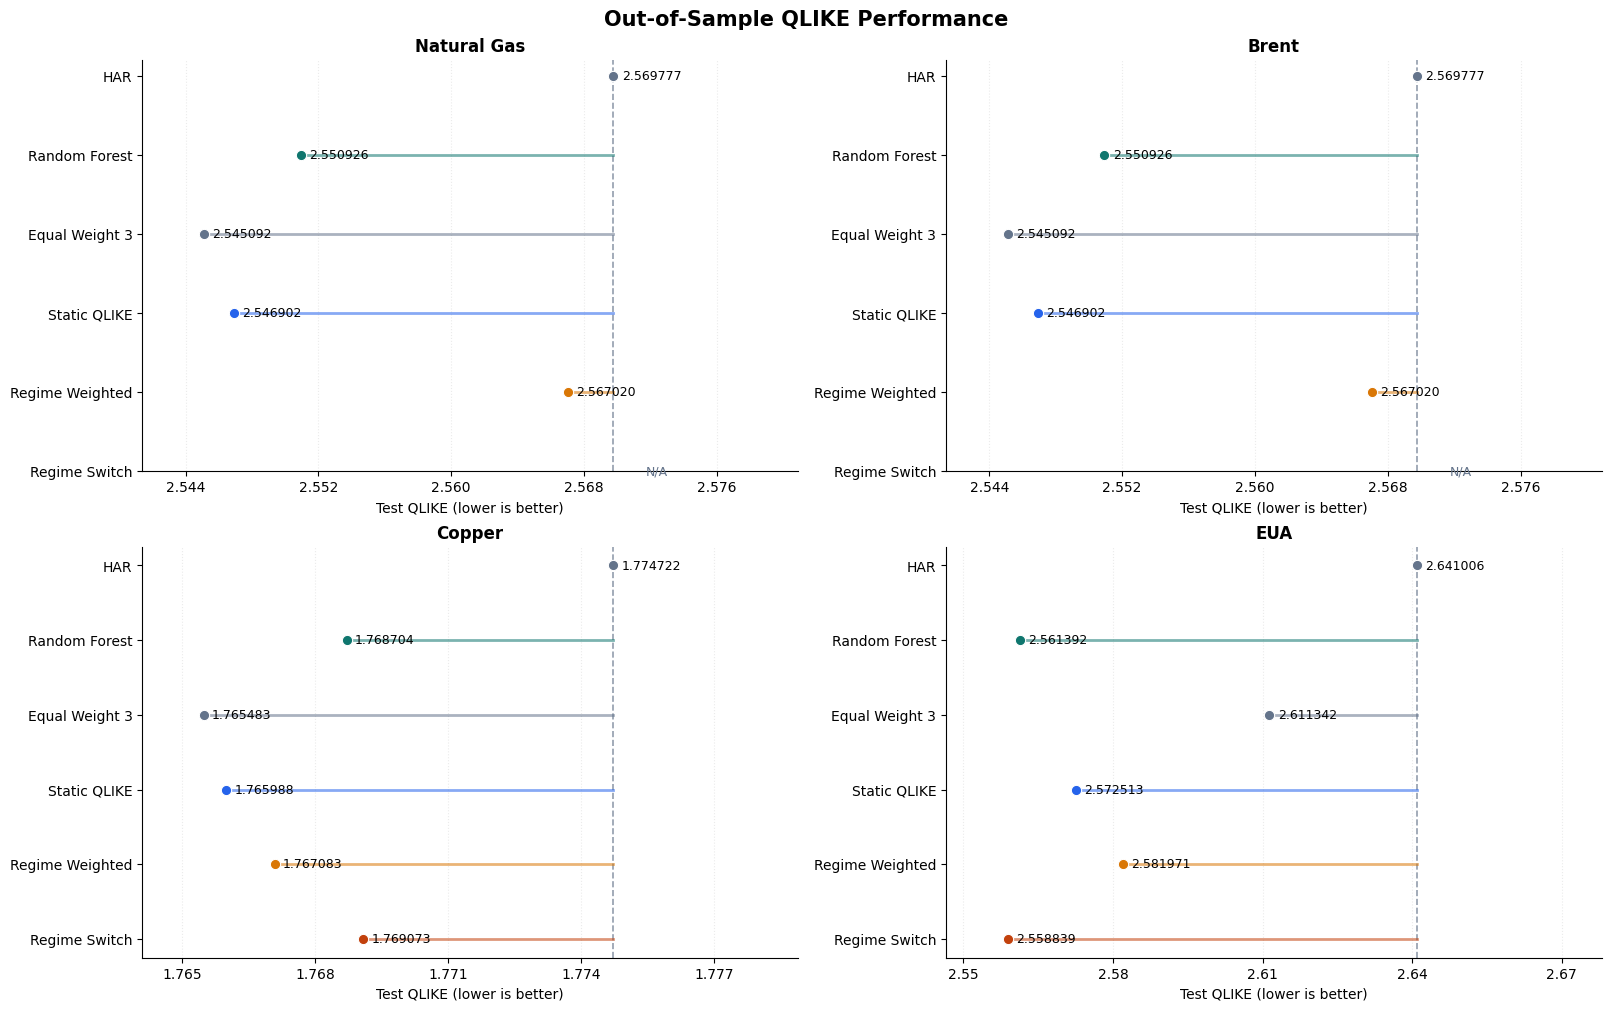


FIGURE 1 SAVED:
C:\Users\UE\REVISION_RESULTS\PUBLICATION_FIGURES\Figure_1_QLIKE.png
C:\Users\UE\REVISION_RESULTS\PUBLICATION_FIGURES\Figure_1_QLIKE.svg


In [21]:

# ============================================================
# FIGURE 1 - OUT-OF-SAMPLE QLIKE BY MARKET
# Source: STEP 12.6 CSV, ORIGINAL primary strategies
# No model training or recalculation
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

BASE = Path(r"C:\Users\UE\REVISION_RESULTS")
FIG_DIR = BASE / "PUBLICATION_FIGURES"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MARKETS = {
    "Natural Gas": "Natural_Gas",
    "Brent": "Brent",
    "Copper": "Copper",
    "EUA": "EUA"
}

STRATEGIES = [
    ("HAR", "HAR"),
    ("Random Forest", "Random Forest"),
    ("Equal Weight 3", "Equal Weight 3"),
    ("Static QLIKE", "Static QLIKE"),
    ("Regime Weighted", "Regime Weighted"),
    ("Regime Switch", "Regime Switch")
]

COLORS = {
    "HAR": "#64748b",
    "Random Forest": "#0f766e",
    "Equal Weight 3": "#64748b",
    "Static QLIKE": "#2563eb",
    "Regime Weighted": "#d97706",
    "Regime Switch": "#c2410c"
}

# ------------------------------------------------------------
# 1. Load and validate all 4 markets
# ------------------------------------------------------------

results = {}

for market, folder in MARKETS.items():

    file = (
        BASE / folder /
        "12_6_inverse_MSE_performance.csv"
    )

    if not file.is_file():
        raise FileNotFoundError(file)

    data = pd.read_csv(file)

    if set(data["Market"].dropna()) != {market}:
        raise ValueError(
            f"Wrong market inside {file}"
        )

    if data["Strategy"].duplicated().any():
        raise ValueError(
            f"Duplicate strategies: {market}"
        )

    data["QLIKE"] = pd.to_numeric(
        data["QLIKE"], errors="coerce"
    )

    data = data.set_index("Strategy")

    missing = [
        name for name, _ in STRATEGIES
        if name not in data.index
    ]

    if missing:
        raise ValueError(
            f"{market}: missing {missing}"
        )

    if not np.isfinite(data.loc["HAR", "QLIKE"]):
        raise ValueError(
            f"{market}: invalid HAR QLIKE"
        )

    results[market] = data

# ------------------------------------------------------------
# 2. Prepare four market-specific panels
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.fonttype": "none"
})

fig, axes = plt.subplots(
    2, 2, figsize=(16, 10),
    constrained_layout=True
)

for ax, (market, data) in zip(
    axes.flat, results.items()
):

    benchmark = float(
        data.loc["HAR", "QLIKE"]
    )

    values = np.array([
        float(data.loc[name, "QLIKE"])
        for name, _ in STRATEGIES
    ])

    finite = values[np.isfinite(values)]

    lo = min(finite)
    hi = max(finite)

    spread = max(hi - lo, 0.002)

    ax.set_xlim(
        lo - spread * 0.15,
        hi + spread * 0.45
    )

    y_positions = np.arange(len(STRATEGIES))

    # HAR reference line
    ax.axvline(
        benchmark,
        color="#64748b",
        linestyle="--",
        linewidth=1.2,
        alpha=0.7
    )

    for i, (name, label) in enumerate(STRATEGIES):

        value = values[i]

        if not np.isfinite(value):
            ax.text(
                hi + spread * 0.08, i,
                "N/A",
                fontsize=9,
                color="#64748b",
                va="center"
            )
            continue

        # Difference from HAR baseline
        ax.plot(
            [benchmark, value],
            [i, i],
            color=COLORS[name],
            linewidth=2,
            alpha=0.55
        )

        ax.scatter(
            value, i,
            s=55,
            color=COLORS[name],
            edgecolor="white",
            linewidth=0.8,
            zorder=3
        )

        ax.annotate(
            f"{value:.6f}",
            xy=(value, i),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            fontsize=9
        )

    ax.set_yticks(
        y_positions,
        [label for _, label in STRATEGIES]
    )

    ax.invert_yaxis()
    ax.set_title(market, fontweight="bold")
    ax.set_xlabel("Test QLIKE (lower is better)")

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax.ticklabel_format(
        axis="x", style="plain",
        useOffset=False
    )

    ax.grid(
        axis="x",
        linestyle=":",
        alpha=0.25
    )

fig.suptitle(
    "Out-of-Sample QLIKE Performance",
    fontsize=15,
    fontweight="bold"
)

# ------------------------------------------------------------
# 3. Save publication figures
# ------------------------------------------------------------

png_path = FIG_DIR / "Figure_1_QLIKE.png"
svg_path = FIG_DIR / "Figure_1_QLIKE.svg"

fig.savefig(
    png_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFIGURE 1 SAVED:")
print(png_path.resolve())
print(svg_path.resolve())


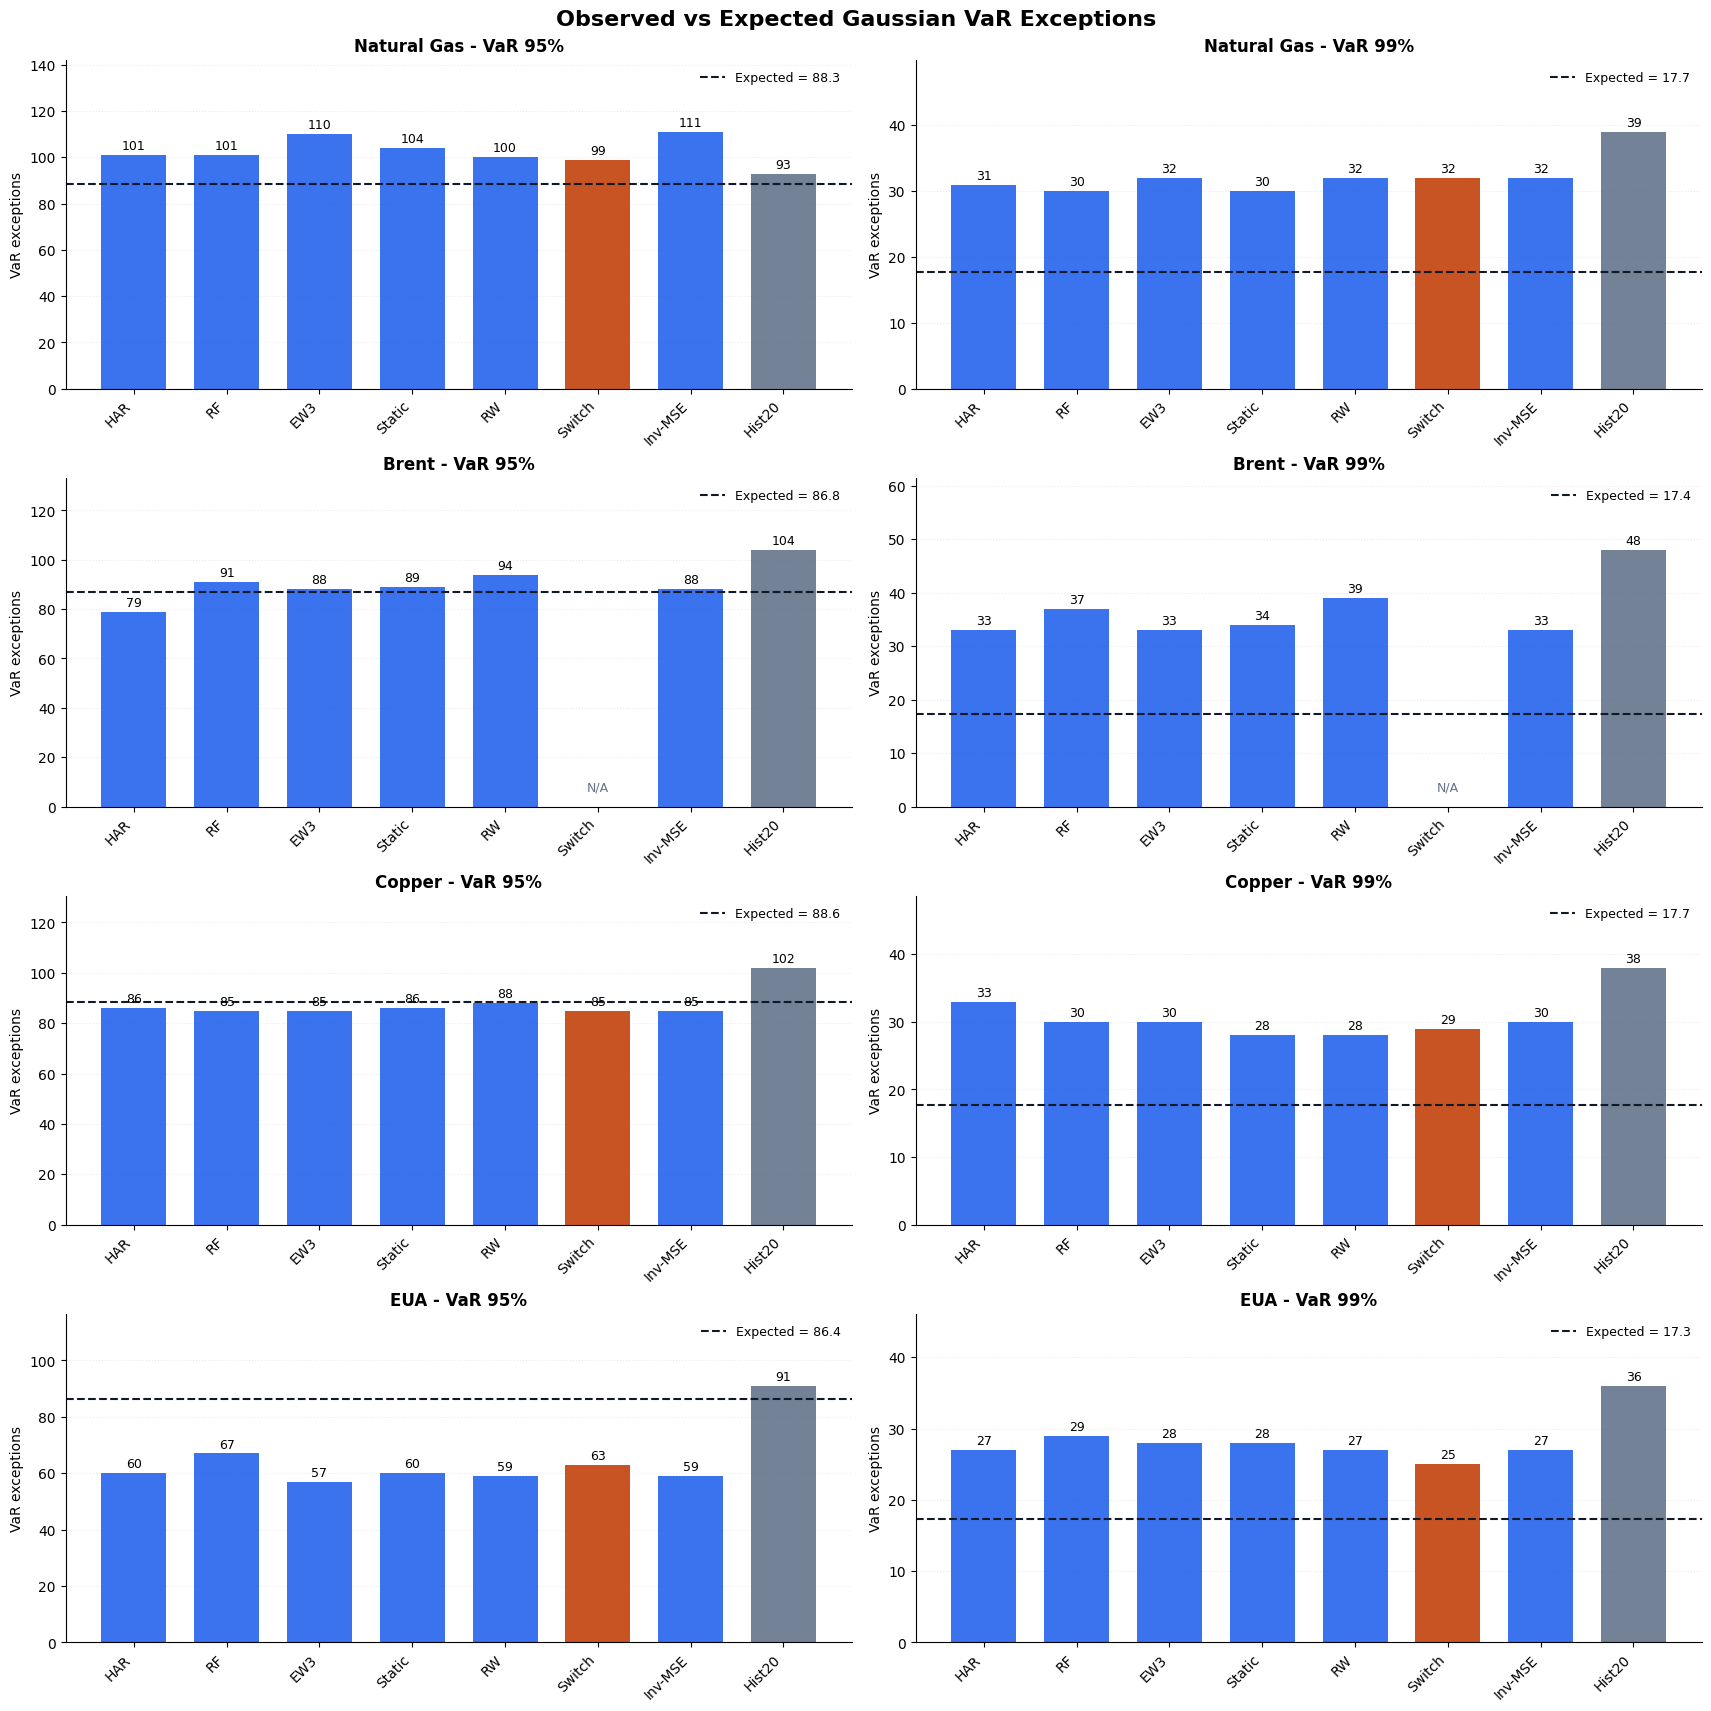


FIGURE 2 SAVED:
C:\Users\UE\REVISION_RESULTS\PUBLICATION_FIGURES\Figure_2_Gaussian_VaR.png
C:\Users\UE\REVISION_RESULTS\PUBLICATION_FIGURES\Figure_2_Gaussian_VaR.svg


In [22]:

# ============================================================
# FIGURE 2 - GAUSSIAN VaR EXCEPTION COUNTS
# 4 markets x VaR 95% and 99%
# Source: STEP 12.7 CSV
# No recalculation of VaR models
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\UE\REVISION_RESULTS")
FIG_DIR = BASE / "PUBLICATION_FIGURES"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MARKETS = {
    "Natural Gas": "Natural_Gas",
    "Brent": "Brent",
    "Copper": "Copper",
    "EUA": "EUA"
}

MODEL_NAMES = [
    "HAR",
    "Random Forest",
    "Equal Weight 3",
    "Static QLIKE",
    "Regime Weighted",
    "Regime Switch",
    "Inverse-MSE",
    "Historical Vol 20"
]

MODEL_LABELS = [
    "HAR", "RF", "EW3", "Static",
    "RW", "Switch", "Inv-MSE", "Hist20"
]

LEVELS = [0.95, 0.99]

# ------------------------------------------------------------
# 1. Load all market data
# ------------------------------------------------------------

market_data = {}

for market, folder in MARKETS.items():

    path = (
        BASE / folder /
        "12_7_VaR_backtests.csv"
    )

    if not path.is_file():
        raise FileNotFoundError(path)

    data = pd.read_csv(path)

    required = {
        "Market",
        "Distribution",
        "VaR_Level",
        "Model",
        "N",
        "Exceptions"
    }

    missing = required - set(data.columns)

    if missing:
        raise ValueError(
            f"{market}: missing columns {missing}"
        )

    if set(data["Market"].dropna()) != {market}:
        raise ValueError(
            f"Wrong market inside: {path}"
        )

    data["VaR_Level"] = pd.to_numeric(
        data["VaR_Level"],
        errors="raise"
    )

    data["Exceptions"] = pd.to_numeric(
        data["Exceptions"],
        errors="raise"
    )

    market_data[market] = data

# ------------------------------------------------------------
# 2. Create 4 x 2 panels
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.fonttype": "none"
})

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(17, 17),
    constrained_layout=True
)

for row, (market, data) in enumerate(
    market_data.items()
):

    for col, level in enumerate(LEVELS):

        ax = axes[row, col]

        subset = data.loc[
            data["Distribution"].eq("Gaussian")
            &
            np.isclose(
                data["VaR_Level"].to_numpy(float),
                level
            )
        ].copy()

        if subset.empty:
            raise ValueError(
                f"No Gaussian VaR {level} for {market}"
            )

        if subset["Model"].duplicated().any():
            raise ValueError(
                f"Duplicate VaR model: {market}, {level}"
            )

        if subset["N"].nunique() != 1:
            raise ValueError(
                f"Inconsistent Test sizes: {market}"
            )

        n_test = int(subset["N"].iloc[0])

        expected = n_test * (1 - level)

        subset = subset.set_index("Model")

        counts = np.array([
            (
                float(subset.loc[name, "Exceptions"])
                if name in subset.index
                else np.nan
            )
            for name in MODEL_NAMES
        ])

        positions = np.arange(len(MODEL_NAMES))
        valid = np.isfinite(counts)

        colors = [
            (
                "#c2410c"
                if name == "Regime Switch"
                else "#64748b"
                if name == "Historical Vol 20"
                else "#2563eb"
            )
            for name in MODEL_NAMES
        ]

        ymax = 1.28 * max(
            float(np.nanmax(counts)),
            expected
        )

        ymax = max(ymax, 1.0)

        ax.set_ylim(0, ymax)

        ax.bar(
            positions[valid],
            counts[valid],
            color=[
                colors[i]
                for i in positions[valid]
            ],
            width=0.7,
            alpha=0.9
        )

        # Expected exceptions reference
        ax.axhline(
            expected,
            color="#111827",
            linestyle="--",
            linewidth=1.5,
            label=(
                f"Expected = {expected:.1f}"
            )
        )

        # Observed count above bars
        for i, count in enumerate(counts):

            if np.isfinite(count):
                ax.annotate(
                    str(int(count)),
                    xy=(i, count),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center",
                    fontsize=9
                )

            else:
                ax.text(
                    i,
                    ymax * 0.04,
                    "N/A",
                    ha="center",
                    va="bottom",
                    fontsize=9,
                    color="#64748b"
                )

        ax.set_xticks(
            positions,
            MODEL_LABELS,
            rotation=45,
            ha="right"
        )

        ax.set_ylabel("VaR exceptions")

        ax.set_title(
            f"{market} - VaR {int(level * 100)}%",
            fontweight="bold"
        )

        ax.legend(
            loc="upper right",
            frameon=False,
            fontsize=9
        )

        ax.grid(
            axis="y",
            linestyle=":",
            alpha=0.25
        )

        ax.set_axisbelow(True)

fig.suptitle(
    "Observed vs Expected Gaussian VaR Exceptions",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------
# 3. Export publication-ready versions
# ------------------------------------------------------------

png_path = FIG_DIR / "Figure_2_Gaussian_VaR.png"
svg_path = FIG_DIR / "Figure_2_Gaussian_VaR.svg"

fig.savefig(
    png_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFIGURE 2 SAVED:")
print(png_path.resolve())
print(svg_path.resolve())


In [24]:
"""STEP 13.1 - Full-pool strict-QLIKE Model Confidence Set robustness.

Pre-specified supplementary analysis. Does not refit models or tune them.
Reuses the original STEP 12.5A Test forecasts, not Tweedie Brent substitutions.
The arch.bootstrap.MCS method='R' matches prior 3-model MCS notebooks.
"""
from pathlib import Path
import numpy as np
import pandas as pd

# --- EDIT THESE TWO SETTINGS ---
MARKET = "Brent"          # "Natural Gas", "Brent", "Copper", "EUA"
BASE = Path(r"C:\Users\UE\REVISION_RESULTS")
REPS = 3000                # preliminary check: 300; publication output: 3000
INCLUDE_INVERSE_MSE = False   # False: main original full pool; True: supplementary pool
SEED = 20261020

FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}
EXPECTED_N = {"Natural Gas": 1766, "Brent": 1736,
              "Copper": 1772, "EUA": 1728}

# Originals (not *_CORR nor Tweedie)
MODEL_COLUMNS = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost - original": "Forecast_XGB",
    "SVR": "Forecast_SVR",
    "Equal Weight 3": "Forecast_Combo_EW3",
    "Static QLIKE": "Forecast_Combo_Static",
    "Regime Weighted": "Forecast_Combo_RegimeWeighted",
    "Regime Switch": "Forecast_Combo_RegimeSwitch",
}


def make_strict_qlike_matrix(df, model_columns):
    y = pd.to_numeric(df["Target_Parkinson_t1"], errors="raise").to_numpy(float)
    if not (np.isfinite(y).all() and (y >= 0).all()):
        raise ValueError("Invalid target: nonfinite or negative Parkinson variance")
    losses = pd.DataFrame(index=pd.DatetimeIndex(df["Date"], name="Date"))
    audit = []
    for label, col in model_columns.items():
        if col not in df.columns:
            raise KeyError(f"Missing source column {col!r} for {label!r}")
        f = pd.to_numeric(df[col], errors="coerce").to_numpy(float)
        finite = bool(np.isfinite(f).all())
        positive = bool((f > 0).all())
        admissible = finite and positive
        audit.append({"Model": label, "Column": col, "N": len(f),
                      "N_Nonfinite": int((~np.isfinite(f)).sum()),
                      "N_Nonpositive": int((f <= 0).sum()),
                      "Strict_QLIKE_Admissible": admissible})
        if admissible:
            values = np.log(f) + y / f
            if not np.isfinite(values).all():
                raise ValueError(f"Nonfinite QLIKE from {label}")
            losses[label] = values
    audit = pd.DataFrame(audit)
    if losses.shape[1] < 2:
        raise RuntimeError("Less than 2 strictly admissible models")
    return losses, audit


def run_mcs():
    if MARKET not in FOLDERS:
        raise ValueError(f"MARKET must be one of {list(FOLDERS)}")
    folder = BASE / FOLDERS[MARKET]
    path = folder / "12_5A_daily_forecasts.csv"
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing original primary Test forecast archive:\n{path}\n"
            "Export the original full-Test forecast table as this CSV first. "
            "Do NOT replace original Brent XGBoost/Switch with Tweedie forecasts."
        )
    df = pd.read_csv(path, parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
    if len(df) != EXPECTED_N[MARKET] or df["Date"].duplicated().any():
        raise ValueError(f"Unexpected Test length / duplicate dates: {MARKET}, {len(df)}")
    if not (df["Date"] >= pd.Timestamp("2020-01-01")).all():
        raise ValueError("Test contains pre-2020 forecast origins")

    model_cols = dict(MODEL_COLUMNS)
    if INCLUDE_INVERSE_MSE:
        ext = folder / "12_6_inverse_MSE_daily_forecasts.csv"
        if not ext.is_file():
            raise FileNotFoundError(ext)
        x = pd.read_csv(ext, parse_dates=["Date"])
        if x["Date"].duplicated().any() or len(x) != len(df):
            raise ValueError("Inverse-MSE dates/count incompatible with primary Test")
        x = x[["Date", "Target_Parkinson_t1", "Forecast_Combo_InvMSE"]]
        df = df.merge(x, on="Date", how="left", validate="one_to_one", suffixes=("", "_INV"))
        if not np.allclose(df["Target_Parkinson_t1"], df["Target_Parkinson_t1_INV"], rtol=1e-9, atol=1e-9):
            raise ValueError("Target mismatch between STEP 12.5A and 12.6")
        model_cols["Inverse-MSE"] = "Forecast_Combo_InvMSE"

    losses, audit = make_strict_qlike_matrix(df, model_cols)
    # Avoid numerical problems caused by exact duplicate loss columns; document equivalents.
    equivalent = []
    keep = []
    for col in losses:
        same_as = next((k for k in keep if np.array_equal(losses[col].to_numpy(),
                                                           losses[k].to_numpy())), None)
        if same_as is None:
            keep.append(col)
        else:
            equivalent.append({"Model": col, "Identical_To": same_as})
    reduced = losses[keep]
    if reduced.shape[1] < 2:
        raise ValueError("Fewer than 2 distinct loss series")

    from arch.bootstrap import MCS
    block_size = int(np.sqrt(len(reduced)))
    mcs = MCS(losses=reduced, size=0.05, reps=REPS,
              block_size=block_size, method="R", bootstrap="stationary", seed=SEED)
    mcs.compute()
    res = mcs.pvalues.copy().rename_axis("Model").reset_index()
    pcol = next((c for c in res if c.lower() in {"pvalue", "p_value"}), None)
    if pcol is None:
        raise ValueError(f"Unknown MCS result schema: {list(res)}")
    res = res.rename(columns={pcol: "MCS_pvalue"})
    res["Mean_QLIKE"] = res["Model"].map(reduced.mean().to_dict())
    res["Included_MCS_95pct"] = res["Model"].isin(mcs.included)
    res["MCS_Block_Size"] = block_size
    res["MCS_Reps"] = REPS
    res["MCS_Method"] = "R; stationary bootstrap"
    res = res.sort_values("Mean_QLIKE").reset_index(drop=True)
    for eq in equivalent:
        r = res.loc[res["Model"].eq(eq["Identical_To"])].iloc[0].copy()
        r["Model"] = eq["Model"]
        res = pd.concat([res, r.to_frame().T], ignore_index=True)
    res["Market"] = MARKET
    audit["Market"] = MARKET
    audit["Identical_To"] = audit["Model"].map({d["Model"]: d["Identical_To"] for d in equivalent})

    out = folder / "STEP13_NEW"
    out.mkdir(parents=True, exist_ok=True)
    suffix = "extended_INV" if INCLUDE_INVERSE_MSE else "original_full_pool"
    res.to_csv(out / f"13_1_MCS_{suffix}_results.csv", index=False)
    audit.to_csv(out / f"13_1_MCS_{suffix}_audit.csv", index=False)
    reduced.to_csv(out / f"13_1_MCS_{suffix}_daily_losses.csv")
    print("Market:", MARKET, "N:", len(df), "MCS models:", reduced.shape[1])
    print("Excluded by strict positivity:", audit.loc[~audit.Strict_QLIKE_Admissible, "Model"].tolist())
    print("Exactly identical loss series:", equivalent)
    print("Stationary bootstrap / R, reps:", REPS, "block:", block_size)
    print(res.to_string(index=False))
    print("Saved to:", out)
    return res, audit


if __name__ == "__main__":
    run_mcs()


Market: Brent N: 1736 MCS models: 10
Excluded by strict positivity: ['XGBoost - original', 'Regime Switch']
Exactly identical loss series: []
Stationary bootstrap / R, reps: 3000 block: 41
          Model  MCS_pvalue  Mean_QLIKE  Included_MCS_95pct  MCS_Block_Size  MCS_Reps              MCS_Method Market
 Equal Weight 3    1.000000    2.545092                True              41      3000 R; stationary bootstrap  Brent
   Static QLIKE    0.339000    2.546902                True              41      3000 R; stationary bootstrap  Brent
  Random Forest    0.339000    2.550926                True              41      3000 R; stationary bootstrap  Brent
Regime Weighted    0.008333    2.567020               False              41      3000 R; stationary bootstrap  Brent
            HAR    0.007000    2.569777               False              41      3000 R; stationary bootstrap  Brent
          GARCH    0.037333    2.594725               False              41      3000 R; stationary bootstrap

In [27]:
"""STEP 13.2 - Predeclared supplementary positive log-HAR benchmark.

Run from each ORIGINAL market notebook AFTER the original data-preparation cells
(through model_df_complete creation), with:

    from step13_2_loghar import run_loghar
    run_loghar(model_df_complete, market="Brent")

Does not retune/re-estimate any original RF/XGB/SVR/GARCH/combination model.
Re-fits only this new, explicitly supplementary log-HAR at each origin.

Zero-value rule fixed on Train: epsilon = 0.01 * median positive Train Parkinson variance.
The forecast is exp(predicted log(PV + epsilon)), a strictly positive shifted-
log proxy. This estimates a conditional geometric location on shifted scale,
NOT an unbiased conditional mean of PV. It is not subtractively back-adjusted,
clipped or retuned using Validation/Test outcomes.
"""
from pathlib import Path
import numpy as np
import pandas as pd

FEATURES = ["Parkinson_Var", "Parkinson_Mean_5", "Parkinson_Mean_20"]
TARGET = "Target_Parkinson_t1"
EXPECTED = {"Natural Gas": (790, 1766), "Brent": (774, 1736),
            "Copper": (770, 1772), "EUA": (770, 1728)}
FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}


def run_loghar(model_df_complete, *, market,
               base=Path(r"C:\Users\UE\REVISION_RESULTS"),
               strict_n=True):
    if market not in FOLDERS:
        raise ValueError(f"Unknown market {market!r}")
    df = model_df_complete[["Date", "Sample", *FEATURES, TARGET]].copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    if df.Date.duplicated().any():
        raise ValueError("Duplicate modeling dates")
    if df[[*FEATURES, TARGET]].isna().any().any():
        raise ValueError("Incomplete modeling rows")
    if not np.isfinite(df[[*FEATURES, TARGET]].to_numpy(float)).all():
        raise ValueError("Nonfinite PV/predictors")
    if (df[[*FEATURES, TARGET]].to_numpy(float) < 0).any():
        raise ValueError("Negative Parkinson quantities")
    if strict_n:
        nval = int((df.Sample == "Validation").sum())
        ntest = int((df.Sample == "Test").sum())
        if (nval, ntest) != EXPECTED[market]:
            raise ValueError(f"Original modeling sample mismatch: {nval}, {ntest} != {EXPECTED[market]}")

    train_mask = df["Sample"].eq("Train").to_numpy()
    if int(train_mask.sum()) < 250:
        raise ValueError("Not enough Train observations")
    positive_train = df.loc[train_mask & df["Parkinson_Var"].gt(0), "Parkinson_Var"]
    if positive_train.empty:
        raise ValueError("No positive Parkinson variance in Train")
    eps = 0.01 * float(positive_train.median())
    if not eps > 0:
        raise ValueError("Invalid Train-frozen epsilon")

    X = np.column_stack([np.ones(len(df)),
                         np.log(df[FEATURES].to_numpy(float) + eps)])
    y = np.log(df[TARGET].to_numpy(float) + eps)

    dates = df.Date.to_numpy()
    samples = df.Sample.to_numpy()
    preds = np.full(len(df), np.nan)
    # Strict Date < forecast-origin chronology: same convention as the original HAR.
    for i in range(len(df)):
        if samples[i] not in ("Validation", "Test"):
            continue
        train_positions = np.flatnonzero(dates < dates[i])
        if len(train_positions) < 250:
            raise ValueError(f"Insufficient expanding sample at {df.Date.iloc[i]}")
        b = np.linalg.lstsq(X[train_positions], y[train_positions], rcond=None)[0]
        preds[i] = float(np.exp(X[i] @ b))

    out = df.loc[df.Sample.isin(["Validation", "Test"]),
                 ["Date", "Sample", TARGET]].copy()
    out["Forecast_LogHAR_Shifted"] = preds[df.Sample.isin(["Validation", "Test"]).to_numpy()]
    if not np.isfinite(out["Forecast_LogHAR_Shifted"]).all() or not (out["Forecast_LogHAR_Shifted"] > 0).all():
        raise ValueError("Invalid log-HAR back-transformed forecasts")
    out["Epsilon_Train_Frozen"] = eps
    out["LogHAR_Specification"] = "log(PV+eps), exp(log forecast), no offset subtraction"

    def evaluate(sample):
        sub = out.loc[out.Sample.eq(sample)]
        a = sub[TARGET].to_numpy(float)
        f = sub["Forecast_LogHAR_Shifted"].to_numpy(float)
        return {"Market":market,"Sample":sample,"N":len(sub),
                "Mean_QLIKE":float(np.mean(np.log(f)+a/f)),
                "MAE":float(np.mean(np.abs(f-a))),
                "RMSE":float(np.sqrt(np.mean((f-a)**2))),
                "Epsilon_Train":eps}
    perf = pd.DataFrame([evaluate("Validation"), evaluate("Test")])
    out_dir = Path(base) / FOLDERS[market] / "STEP13_NEW"
    out_dir.mkdir(parents=True, exist_ok=True)
    out.to_csv(out_dir / "13_2_LogHAR_Validation_Test_forecasts.csv", index=False)
    perf.to_csv(out_dir / "13_2_LogHAR_performance.csv", index=False)

    # Optional strict paired comparison against the ORIGINAL HAR, not newly refitted HAR.
    source = Path(base) / FOLDERS[market] / "12_6_inverse_MSE_daily_forecasts.csv"
    if source.is_file():
        main = pd.read_csv(source, parse_dates=["Date"])
        test = out.loc[out.Sample.eq("Test")].merge(
            main[["Date", TARGET, "Forecast_HAR"]], on="Date",
            how="left", validate="one_to_one", suffixes=("", "_ORIG"))
        if len(test) != EXPECTED[market][1] or test["Forecast_HAR"].isna().any():
            raise ValueError("Log-HAR / original HAR Test Date alignment failed")
        if not np.allclose(test[TARGET], test[TARGET+"_ORIG"], atol=1e-9, rtol=1e-9):
            raise ValueError("Target mismatch; comparison with original HAR is invalid")
        act = test[TARGET].to_numpy(float)
        f_new = test["Forecast_LogHAR_Shifted"].to_numpy(float)
        f_har = test["Forecast_HAR"].to_numpy(float)
        if np.all(np.isfinite(f_har)) and np.all(f_har > 0):
            loss_diff = (np.log(f_new)+act/f_new)-(np.log(f_har)+act/f_har)
            # Supplementary HAC mean-loss test, NOT labeled DM-HLN.
            import statsmodels.api as sm
            fit = sm.OLS(loss_diff, np.ones((len(loss_diff),1))).fit(
                cov_type="HAC", cov_kwds={"maxlags":7})
            comparison = pd.DataFrame([{"Market":market,"N":len(test),
                "Mean_QLIKE_LogHAR_minus_HAR":float(loss_diff.mean()),
                "HAC_lags":7,"HAC_p_two_sided":float(fit.pvalues[0]),
                "Method":"OLS mean-loss differential, Newey-West HAC(7)"}])
            comparison.to_csv(out_dir / "13_2_LogHAR_vs_original_HAR_HAC.csv", index=False)
            print("Pairwise Test comparison to frozen original HAR:")
            print(comparison.to_string(index=False))

    print("Train-frozen epsilon:", eps)
    print("Strictly positive forecasts:", (out.Forecast_LogHAR_Shifted > 0).all())
    print(perf.to_string(index=False))
    print("Saved to:", out_dir)
    return out, perf


In [28]:
"""STEP 13.3 - Post-review structural stability diagnostics.

Run in each ORIGINAL market notebook after creating `df` with columns
Date and Parkinson_Var:

    from step13_3_structural_breaks import run_break_diagnostics
    run_break_diagnostics(df, market="Brent")

Known-event-date HAC joint Wald tests of shifts in AR(1) intercept and slope.
Optional unknown-date asymptotic OLS-CUSUM on AR(1) residuals. These are
observational diagnostics, not proof that the event caused the change.
No model tuning/selection based on Test. Report descriptive effect and caveats.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.diagnostic import breaks_cusumolsresid
from statsmodels.stats.multitest import multipletests

EVENTS = {
    "COVID-19 (WHO pandemic declaration)": "2020-03-11",
    "European energy crisis (predefined onset proxy)": "2021-09-01",
    "EU ETS Phase IV (EUA market only)": "2021-01-01",
}
FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}


def run_break_diagnostics(df, *, market,
                          base=Path(r"C:\Users\UE\REVISION_RESULTS"),
                          hac_lags=7, min_segment=252):
    if market not in FOLDERS:
        raise ValueError(f"Unknown market {market!r}")
    d = df[["Date", "Parkinson_Var"]].copy()
    d["Date"] = pd.to_datetime(d["Date"])
    d["Parkinson_Var"] = pd.to_numeric(d["Parkinson_Var"], errors="coerce")
    d = d.dropna(subset=["Date", "Parkinson_Var"]).sort_values("Date")
    if d.Date.duplicated().any() or not np.isfinite(d.Parkinson_Var).all():
        raise ValueError("Bad dates or nonfinite Parkinson data")
    if (d.Parkinson_Var < 0).any():
        raise ValueError("Negative Parkinson variance")
    pre2017 = d.loc[d.Date.lt("2017-01-01") & d.Parkinson_Var.gt(0), "Parkinson_Var"]
    if len(pre2017) < min_segment:
        raise ValueError("Not enough original Train data to freeze transformation scale")
    scale = float(pre2017.median())  # frozen only on 2010-2016
    if not scale > 0:
        raise ValueError("Invalid Train scale")

    d = d.loc[d.Date.ge("2017-01-01")].copy().reset_index(drop=True)
    d["y"] = np.log1p(d.Parkinson_Var / scale)
    d["lag_y"] = d["y"].shift(1)
    d = d.dropna(subset=["lag_y"]).reset_index(drop=True)

    y = d.y.to_numpy(float)
    lag = d.lag_y.to_numpy(float)
    X_null = np.column_stack((np.ones(len(d)), lag))
    fit_null = sm.OLS(y, X_null).fit()
    cusum_stat, cusum_p, _ = breaks_cusumolsresid(fit_null.resid, ddof=2)

    rows = []
    events = {k: v for k, v in EVENTS.items()
              if (market == "EUA" or "ETS Phase IV" not in k)}
    for label, cutoff in events.items():
        post = (d.Date >= pd.Timestamp(cutoff)).to_numpy(float)
        n_pre = int((post == 0).sum())
        n_post = int((post == 1).sum())
        if n_pre < min_segment or n_post < min_segment:
            raise ValueError(f"Too few obs around {label}: {n_pre} / {n_post}")
        # Joint shift: y_t = b0 + b1*y_{t-1} + gamma0*post + gamma1*post*y_{t-1} + e_t
        X = np.column_stack([np.ones(len(d)), lag, post, lag * post])
        fit = sm.OLS(y, X).fit(cov_type="HAC",
                                cov_kwds={"maxlags":hac_lags})
        R = np.array([[0, 0, 1, 0], [0, 0, 0, 1]], dtype=float)
        test = fit.wald_test(R, scalar=True, use_f=False)
        rows.append({"Market":market, "Event":label, "Cutoff":cutoff,
                     "N_Pre":n_pre, "N_Post":n_post,
                     "Mean_LogPV_Pre":float(y[post == 0].mean()),
                     "Mean_LogPV_Post":float(y[post == 1].mean()),
                     "Post_Intercept_Shift":float(fit.params[2]),
                     "Post_AR1_Slope_Shift":float(fit.params[3]),
                     "Joint_Wald_Chi2":float(test.statistic),
                     "df":2,"p_raw_HAC":float(test.pvalue),
                     "HAC_lags":hac_lags,
                     "Interpretation":"Predefined-date AR(1) parameter-stability test; not causal"})
    result = pd.DataFrame(rows)
    result["p_Holm_within_market"] = multipletests(
        result["p_raw_HAC"].to_numpy(), method="holm")[1]
    result["Reject_5pct_Holm"] = result["p_Holm_within_market"].lt(0.05)

    cusum = pd.DataFrame([{"Market":market,"N":len(d),
                            "Sample_Start":str(d.Date.min().date()),
                            "Sample_End":str(d.Date.max().date()),
                            "Train_Frozen_Scale":scale,
                            "CUSUM_OLS_Statistic":float(cusum_stat),
                            "CUSUM_Asymptotic_p":float(cusum_p),
                            "Caveat":"CUSUM asymptotic p-values may be sensitive to heteroskedasticity/dependence"}])
    out_dir = Path(base) / FOLDERS[market] / "STEP13_NEW"
    out_dir.mkdir(parents=True, exist_ok=True)
    result.to_csv(out_dir / "13_3_predefined_event_break_tests.csv", index=False)
    cusum.to_csv(out_dir / "13_3_global_CUSUM_diagnostic.csv", index=False)
    print("Market:", market, "N 2017-2026:", len(d), "Train-only scale:", scale)
    print("\nPredefined-date joint HAC Wald tests (Holm within market):")
    print(result.to_string(index=False))
    print("\nGlobal exploratory CUSUM:")
    print(cusum.to_string(index=False))
    print("Saved to:", out_dir)
    return result, cusum


In [51]:

# ============================================================
# BRENT - RUN STEP 13.2 + 13.3
# ============================================================

import sys
from pathlib import Path

BASE = Path(r"C:\Users\UE\REVISION_RESULTS")
CODE = BASE / "STEP13_CODE"
OUT = BASE / "Brent" / "STEP13_NEW"

if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

# Verify required dataframes
assert "model_df_complete" in globals(), (
    "Missing model_df_complete. "
    "Run original notebook through STEP 6.4."
)

assert "df" in globals(), (
    "Missing df with Parkinson_Var."
)

print("Model sample:", len(model_df_complete))
print("Raw dataset:", len(df))

# ------------------------------------------------------------
# STEP 13.2 - LOG-HAR
# ------------------------------------------------------------

from step13_2_loghar import run_loghar

loghar_daily, loghar_performance = run_loghar(
    model_df_complete,
    market="Brent",
    base=BASE
)

print("\n=== STEP 13.2 COMPLETED ===")
display(loghar_performance)

# ------------------------------------------------------------
# STEP 13.3 - STRUCTURAL BREAKS
# ------------------------------------------------------------

from step13_3_structural_breaks import run_break_diagnostics

break_results, cusum_results = run_break_diagnostics(
    df,
    market="Brent",
    base=BASE
)

print("\n=== STEP 13.3 COMPLETED ===")
display(break_results)
display(cusum_results)

# ------------------------------------------------------------
# CHECK SAVED FILES
# ------------------------------------------------------------

print("\n=== SAVED STEP 13 FILES ===")

for file in sorted(OUT.glob("13_*")):
    print(file.name)


Model sample: 4282
Raw dataset: 4304
Pairwise Test comparison to frozen original HAR:
Market    N  Mean_QLIKE_LogHAR_minus_HAR  HAC_lags  HAC_p_two_sided                                        Method
 Brent 1736                     0.062327         7         0.000739 OLS mean-loss differential, Newey-West HAC(7)
Train-frozen epsilon: 0.01846963237384103
Strictly positive forecasts: True
Market     Sample    N  Mean_QLIKE      MAE      RMSE  Epsilon_Train
 Brent Validation  774    2.020269 1.605615  3.307802        0.01847
 Brent       Test 1736    2.632104 4.754469 24.238922        0.01847
Saved to: C:\Users\UE\REVISION_RESULTS\Brent\STEP13_NEW

=== STEP 13.2 COMPLETED ===


,Market,Sample,N,Mean_QLIKE,MAE,RMSE,Epsilon_Train
0,Brent,Validation,774,2.020269,1.605615,3.307802,0.01847
1,Brent,Test,1736,2.632104,4.754469,24.238922,0.01847


Market: Brent N 2017-2026: 2510 Train-only scale: 1.862991965487731

Predefined-date joint HAC Wald tests (Holm within market):
Market                                           Event     Cutoff  N_Pre  N_Post  Mean_LogPV_Pre  Mean_LogPV_Post  Post_Intercept_Shift  Post_AR1_Slope_Shift  Joint_Wald_Chi2  df  p_raw_HAC  HAC_lags                                             Interpretation  p_Holm_within_market  Reject_5pct_Holm
 Brent             COVID-19 (WHO pandemic declaration) 2020-03-11    822    1688        0.804472         1.123268             -0.080819              0.245323        27.060499   2   0.000001         7 Predefined-date AR(1) parameter-stability test; not causal              0.000003              True
 Brent European energy crisis (predefined onset proxy) 2021-09-01   1203    1307        0.961646         1.071532              0.125137             -0.079283        10.023127   2   0.006660         7 Predefined-date AR(1) parameter-stability test; not causal              0.

,Market,Event,Cutoff,N_Pre,N_Post,Mean_LogPV_Pre,Mean_LogPV_Post,Post_Intercept_Shift,Post_AR1_Slope_Shift,Joint_Wald_Chi2,df,p_raw_HAC,HAC_lags,Interpretation,p_Holm_within_market,Reject_5pct_Holm
0,Brent,COVID-19 (WHO pandemic declaration),2020-03-11,822,1688,0.804472,1.123268,-0.080819,0.245323,27.060499,2,0.000001,7,Predefined-date AR(1) parameter-stability test...,0.000003,True
1,Brent,European energy crisis (predefined onset proxy),2021-09-01,1203,1307,0.961646,1.071532,0.125137,-0.079283,10.023127,2,0.006660,7,Predefined-date AR(1) parameter-stability test...,0.006660,True


,Market,N,Sample_Start,Sample_End,Train_Frozen_Scale,CUSUM_OLS_Statistic,CUSUM_Asymptotic_p,Caveat
0,Brent,2510,2017-01-03,2026-09-22,1.862992,2.724887,7.108032e-07,CUSUM asymptotic p-values may be sensitive to ...



=== SAVED STEP 13 FILES ===
13_1_MCS_original_full_pool_audit.csv
13_1_MCS_original_full_pool_daily_losses.csv
13_1_MCS_original_full_pool_results.csv
13_2_LogHAR_performance.csv
13_2_LogHAR_Validation_Test_forecasts.csv
13_2_LogHAR_vs_original_HAR_HAC.csv
13_3_global_CUSUM_diagnostic.csv
13_3_predefined_event_break_tests.csv
